# 04 — MASSK: leakage-safe validation, architecture refinement, and ablations

**Purpose:** select and audit MASSK using development validation only. **Main outputs:** fixed architecture, common-fold comparisons, synchronized component deletions, statistical intervals, calibration, structural endpoints, and efficiency accounting.

This project follows the experimental protocol defined in Tasks_for_Codex.md.

> **Authoritative interpretation (updated 2026-07-21).** The manuscript name is **MASSK — Multilevel Adaptive Semantic Scientific Knowledge Model**. Legacy round labels are experiment-lineage aliases, not separate public versions. The full four-branch candidate remains rejected. The latest bounded class-wise retrieval residual is the exploratory multi-objective point leader: its classification gain is not material or statistically confirmed, while nominal post-hoc paired NLL/Brier intervals exclude zero on reused development-validation data. The receipt-backed semantic consensus is the frozen historical reference; no current model has confirmatory performance evidence until a genuinely new, independently acquired cohort evaluated after a correctly timestamped immutable protocol lock is evaluated.

> **Compute policy.** This notebook is an executed refinement ledger. Cached fold assignments, embeddings, checkpoints, and predictions are reused when hashes match. Training is not repeated for terminology, narrative, or publication-layer changes.

**Notebook status:** `PASS` as an exploratory refinement and negative-result audit; `BLOCKED` for confirmatory classification promotion, but `SUPPORTED` for the round-14 paired NLL and Brier improvements.

This notebook evaluates **MASSK — Multilevel Adaptive Semantic Scientific Knowledge Model** using development data only. The corrected protocol invalidates the earlier split-inverted run, fits every corpus-dependent transform inside its fold, evaluates a fixed semantic anchor and exact comparators on identical folds/seeds, and treats test/external-test as forbidden until a genuinely new, independently acquired cohort evaluated after a correctly timestamped immutable protocol lock exists.

The primary outer estimate describes the complete validation-selection procedure. A configuration is never called superior unless its paper-level paired interval and materiality gate pass.

**Short reader path:** Sections 21–22 contain the bounded retrieval refinements and current multi-objective candidate; Section 18 contains PRISM; Sections 2–20 preserve the complete positive and negative refinement ledger. For compact tables and figures, see the final update in Notebook 05.


<style>
.jp-RenderedHTMLCommon, .jp-RenderedMarkdown, .rendered_html {
  font-size: 18px !important;
  line-height: 1.58 !important;
  max-width: none !important;
}
.jp-RenderedHTMLCommon table, .rendered_html table, table.dataframe {
  font-size: 18px !important;
  line-height: 1.42 !important;
  border-collapse: collapse !important;
  width: auto !important;
  max-width: 100% !important;
}
.jp-RenderedHTMLCommon th, .jp-RenderedHTMLCommon td,
.rendered_html th, .rendered_html td {
  padding: 0.45em 0.65em !important;
  vertical-align: top !important;
}
.jp-OutputArea-output, .output_subarea { overflow-x: auto !important; }
.jp-RenderedHTMLCommon pre, .rendered_html pre { font-size: 17px !important; }
</style>

> **Publication display standard.** Narrative and tables are rendered at 18 px screen text with 18 pt figure labels or larger. Publication figures use Times New Roman at 18–20 pt and 350 dpi. Wide metric sets are split into logically grouped tables instead of being compressed into unreadable canvases.

## 1. Environment, publication style, and immutable data boundary


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import dataclass
from collections import Counter, defaultdict
from copy import deepcopy
import gc, hashlib, importlib.metadata, json, math, os, platform, random, re, subprocess, time, warnings

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from scipy.special import expit as scipy_expit, softmax as scipy_softmax
from scipy.stats import binomtest
from sklearn.feature_extraction.text import (
    HashingVectorizer,
    TfidfTransformer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS,
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
from torch import nn
import torch.nn.functional as F

warnings.filterwarnings("ignore", category=FutureWarning)
SEEDS = [20260417, 20260519, 20260623]
PALETTE = {
    "blue": "#2F6B8F",
    "orange": "#C77C2B",
    "green": "#4F7F3A",
    "purple": "#6D5A8D",
    "red": "#B45A55",
    "gray": "#6E7378",
    "light_gray": "#E7EAED",
    "teal": "#4A8C8A",
    "gold": "#C9A227",
    "black": "#222222",
    "white": "#FFFFFF",
}
mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 19,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.unicode_minus": True,
        "savefig.dpi": 350,
        "figure.dpi": 350,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)

In [2]:
cwd = Path.cwd().resolve()
root_candidates = [
    cwd / "multilevel_semantic_knowledge_structuring",
    cwd,
    cwd.parent / "multilevel_semantic_knowledge_structuring",
    cwd.parent,
]


def is_project_root(path):
    return all(
        (path / required).exists() for required in ["Tasks_for_Codex.md", "dataset", "notebooks"]
    )


valid_roots = [path.resolve() for path in root_candidates if is_project_root(path)]
assert (
    valid_roots
), f"Project root with Tasks_for_Codex.md, dataset/, and notebooks/ not found from {cwd}"
ROOT = valid_roots[0]
DATA = ROOT / "dataset"
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
REPORTS = ROOT / "results" / "reports"
ARTIFACTS = ROOT / "results" / "models" / "massk_artifacts"
for path in [TABLES, FIGURES, REPORTS, ARTIFACTS]:
    path.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Notebook04 requires CUDA; CPU execution is prohibited"
device = torch.device("cuda")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)
torch.set_float32_matmul_precision("high")
NOTEBOOK04_PATH = ROOT / "notebooks" / "04_massk_proposed_model_ablations_and_robustness.ipynb"
assert NOTEBOOK04_PATH.exists()
NOTEBOOK04_SOURCE_SHA256_AT_START = hashlib.sha256(NOTEBOOK04_PATH.read_bytes()).hexdigest()
try:
    NVIDIA_DRIVER_VERSION = (
        subprocess.check_output(
            ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], text=True
        )
        .splitlines()[0]
        .strip()
    )
except Exception:
    NVIDIA_DRIVER_VERSION = "not_available"
package_names = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "pyarrow",
    "joblib",
    "matplotlib",
    "torch",
]
execution_environment = pd.DataFrame(
    [{"component": name, "version": importlib.metadata.version(name)} for name in package_names]
    + [
        {"component": "python", "version": platform.python_version()},
        {"component": "cuda_runtime", "version": str(torch.version.cuda)},
        {"component": "nvidia_driver", "version": NVIDIA_DRIVER_VERSION},
        {"component": "gpu", "version": torch.cuda.get_device_name(0)},
        {
            "component": "deterministic_algorithms",
            "version": str(torch.are_deterministic_algorithms_enabled()),
        },
        {
            "component": "cublas_workspace_config",
            "version": os.environ.get("CUBLAS_WORKSPACE_CONFIG", "not_available"),
        },
        {
            "component": "notebook04_source_sha256_at_start",
            "version": NOTEBOOK04_SOURCE_SHA256_AT_START,
        },
    ]
)
execution_environment.to_csv(TABLES / "notebook04_execution_environment.csv", index=False)
display(execution_environment)

DEVELOPMENT_DATA_PATH = DATA / "unified" / "development_dataset.parquet"
DEVELOPMENT_IDENTITY_PATH = DATA / "unified" / "development_identity.parquet"
DEVELOPMENT_REFERENCES_PATH = DATA / "unified" / "development_reference_concepts.parquet"
loaded_paths = [DEVELOPMENT_DATA_PATH, DEVELOPMENT_IDENTITY_PATH, DEVELOPMENT_REFERENCES_PATH]
assert all(path.exists() for path in loaded_paths)
development = pd.read_parquet(DEVELOPMENT_DATA_PATH)
development = development.sort_values("development_row_index").reset_index(drop=True)
assert development["development_row_index"].to_list() == list(range(len(development)))
assert set(development["split"]) <= {"train", "validation"}
assert not development["sample_id"].duplicated().any()
assert not development["sample_id"].str.contains("external_test", case=False, regex=False).any()

forbidden_paths = [
    DATA / "unified" / "modeling_dataset.parquet",
    DATA / "external_test",
    DATA / "processed" / "openalex_confirmatory_2025_records.parquet",
    ROOT / "results" / "historical_exposed",
]
assert not any(
    path.resolve() in {forbidden.resolve() for forbidden in forbidden_paths}
    for path in loaded_paths
)

,component,version
0,numpy,2.4.4
1,pandas,3.0.3
2,scipy,1.17.1
3,scikit-learn,1.9.0
4,pyarrow,24.0.0
5,joblib,1.5.3
6,matplotlib,3.11.0
7,torch,2.12.1+cu130
8,python,3.12.3
9,cuda_runtime,13.0


## 2. Pre-execution validation-refinement round 7 — calibrated residual-anchor fusion

> **Transparency status.** Round 6 failed its pre-declared four-branch deletion gate: Full Macro-F1 was 0.798471 versus 0.801382 for semantic-only, and removing lexical, metadata, or concept improved Full. Round 7 is therefore a repeated-development, post-selection exploratory amendment informed by those development-only results—not preregistration or confirmatory evidence. It replaces probability-simplex attention with a semantic exact no-op anchor and bounded branch-specific residual corrections. Test and external-test remain forbidden; no round-7 outer labels select the locked configuration.


In [3]:
PROTOCOL = {
    "protocol_id": "massk_exploratory_round7_residual_anchor_2026_07_19",
    "declared_utc": "2026-07-19T00:00:00+00:00",
    "declaration_scope": (
        "round-7 repeated-development post-selection exploratory amendment informed by "
        "the disclosed round-6 development-only failure; not confirmatory evidence"
    ),
    "public_model_name": "MASSK — Multilevel Attentive Semantic Structuring of Scientific Knowledge",
    "development_splits": ["train", "validation"],
    "forbidden_splits": ["test", "external_test"],
    "validation_refinement_round": 7,
    "round_6_failure": (
        "Full 0.798471 < semantic-only 0.801382 and < each auxiliary-branch deletion"
    ),
    "outer_protocol": (
        "2 repeats × 3 proxy-group folds; round-6 continuity may be "
        "claimed only after the preserved-assignment SHA256 audit passes"
    ),
    "inner_protocol": (
        "4 proxy-group folds create row-aligned OOF probabilities; locked C3 fusion uses "
        "group-disjoint fit/stop and branch-calibration partitions"
    ),
    "classifier_branches": ["lexical", "semantic", "metadata", "concept"],
    "semantic_internal_views": ["qwen", "specter2"],
    "semantic_branch_rule": "fixed same-seed 0.5/0.5 Qwen3 and SPECTER2 probability consensus",
    "fusion_rule": (
        "per-branch temperature calibration followed by semantic-anchor bounded additive CLR "
        "residuals with branch-specific disagreement gates; no probability simplex"
    ),
    "candidate_rule": (
        "C3 source-locked before round-7 execution; C1/C2/C4 documented but not executed; "
        "outer validation labels have zero selection effect"
    ),
    "candidate_budget": {
        "documented_designs": 4,
        "executed_architecture_candidates": 1,
        "locked_candidate": "C3",
        "outer_selected_candidates": 0,
    },
    "loss_rule": (
        "class-balanced Full CE plus one-branch rescue, semantic non-harm, group sparsity, "
        "and weak conditional residual diversity"
    ),
    "ablation_bootstrap_resamples": 20000,
    "full_system_gate_family_size": 6,
    "four_branch_subset_size": 4,
    "semantic_view_family_size": 2,
    "ablation_multiplicity": (
        "synchronized two-sided 95% Bonferroni paper and proxy-cluster bootstrap"
    ),
    "active_branch_materiality": 0.003,
    "fold_win_minimum": 4,
    "eligibility_rule": (
        "all six synchronized full-system controls and both semantic-view controls require "
        "delta Macro-F1 >= 0.003, paper and proxy-cluster family-wise Bonferroni LCB > 0, "
        "and >=4/6 fold wins; eligibility requires all eight controls"
    ),
    "feature_factory_status": (
        "source-locked round-7 independent factory amendment: strict LOO metadata encoding, "
        "alias-safe fit-only phrase TF-IDF/LOO prototypes, and fixed branch-specific experts"
    ),
    "concept_input_contract": (
        "fold-local title/abstract content phrases only; reference concepts and arXiv "
        "categories never enter the classifier"
    ),
    "calibration_contract": (
        "semantic anchor fixed to identity; auxiliary identity/temperature selected only on inner OOF calibration rows; "
        "remaining-branch calibrators are bit-identical in physical deletions"
    ),
    "prospective_confirmation": "requires a genuinely new, independently acquired cohort evaluated after a correctly timestamped immutable protocol lock and independent custody",
    "run_status": "SOURCE_ONLY_UNEXECUTED",
}
protocol_bytes = json.dumps(PROTOCOL, sort_keys=True, ensure_ascii=False, indent=2).encode()
protocol_path = ARTIFACTS / "development_protocol_lock_round7_exploratory.json"
protocol_path.write_bytes(protocol_bytes)
PROTOCOL_SHA256 = hashlib.sha256(protocol_bytes).hexdigest()
display(
    pd.DataFrame(
        [
            {"item": "protocol", "value": PROTOCOL["protocol_id"]},
            {"item": "scientific status", "value": PROTOCOL["declaration_scope"]},
            {"item": "locked candidate", "value": PROTOCOL["candidate_budget"]["locked_candidate"]},
            {"item": "fusion", "value": PROTOCOL["fusion_rule"]},
            {"item": "test/external access", "value": "forbidden during refinement"},
            {"item": "SHA256", "value": PROTOCOL_SHA256},
        ]
    )
)

,item,value
0,protocol,massk_exploratory_round7_residual_anchor_2026_...
1,scientific status,round-7 repeated-development post-selection ex...
2,locked candidate,C3
3,fusion,per-branch temperature calibration followed by...
4,test/external access,forbidden during refinement
5,SHA256,ed836847bec9a009ba192b231a12344b245de81a710d13...


### 2.1 Mandatory round-6 failure disclosure


In [4]:
ROUND6_FAILURE_DISCLOSURE = pd.DataFrame(
    [
        {"track": "MASSK", "paper_macro_f1": 0.798471, "delta_full_minus_track": 0.0},
        {"track": "SEMANTIC_ONLY", "paper_macro_f1": 0.801382, "delta_full_minus_track": -0.002911},
        {
            "track": "MASSK_MINUS_LEXICAL",
            "paper_macro_f1": 0.799806,
            "delta_full_minus_track": -0.001335,
        },
        {
            "track": "MASSK_MINUS_METADATA",
            "paper_macro_f1": 0.800512,
            "delta_full_minus_track": -0.002041,
        },
        {
            "track": "MASSK_MINUS_CONCEPT",
            "paper_macro_f1": 0.800401,
            "delta_full_minus_track": -0.001930,
        },
        {
            "track": "MASSK_MINUS_SEMANTIC",
            "paper_macro_f1": 0.681929,
            "delta_full_minus_track": 0.116542,
        },
    ]
)
assert (
    ROUND6_FAILURE_DISCLOSURE.loc[
        ROUND6_FAILURE_DISCLOSURE["track"].isin(
            ["SEMANTIC_ONLY", "MASSK_MINUS_LEXICAL", "MASSK_MINUS_METADATA", "MASSK_MINUS_CONCEPT"]
        ),
        "delta_full_minus_track",
    ]
    .lt(0)
    .all()
)
ROUND6_FAILURE_DISCLOSURE["scientific_status"] = (
    "FAIL; auxiliary-branch necessity unsupported; informed round-7 exploratory design"
)
ROUND6_FAILURE_DISCLOSURE.to_csv(TABLES / "massk_round6_failure_disclosure.csv", index=False)
display(ROUND6_FAILURE_DISCLOSURE)

,track,paper_macro_f1,delta_full_minus_track,scientific_status
0,MASSK,0.798471,0.000000,FAIL; auxiliary-branch necessity unsupported; ...
1,SEMANTIC_ONLY,0.801382,-0.002911,FAIL; auxiliary-branch necessity unsupported; ...
2,MASSK_MINUS_LEXICAL,0.799806,-0.001335,FAIL; auxiliary-branch necessity unsupported; ...
3,MASSK_MINUS_METADATA,0.800512,-0.002041,FAIL; auxiliary-branch necessity unsupported; ...
4,MASSK_MINUS_CONCEPT,0.800401,-0.001930,FAIL; auxiliary-branch necessity unsupported; ...
5,MASSK_MINUS_SEMANTIC,0.681929,0.116542,FAIL; auxiliary-branch necessity unsupported; ...


## 3. High-precision author-plus-paper-institution proxy components and alias-safe concept references


In [5]:
identity = pd.read_parquet(
    DEVELOPMENT_IDENTITY_PATH,
    columns=["sample_id", "authors_json", "institutions_json", "topics_json", "fields_json"],
)
assert identity["sample_id"].to_list() == development["sample_id"].to_list()
development = development.merge(identity, on="sample_id", how="left", validate="one_to_one")


def parse_json_list(value):
    if isinstance(value, list):
        return value
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    try:
        parsed = json.loads(value)
        return parsed if isinstance(parsed, list) else []
    except Exception:
        return []


def canonical(value):
    return re.sub(r"[^a-z0-9]+", " ", str(value).lower()).strip()


parent = np.arange(len(development))


def component_find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index


def component_union(left, right):
    left_root, right_root = component_find(left), component_find(right)
    if left_root != right_root:
        parent[right_root] = left_root


author_identity_owner = {}
for row, record in development.iterrows():
    institutions = sorted(
        filter(None, (canonical(v) for v in parse_json_list(record["institutions_json"])))
    )
    institutional_context = "|".join(institutions) if institutions else canonical(record["source"])
    for author in parse_json_list(record["authors_json"]):
        author_key = canonical(author)
        if len(author_key) < 5:
            continue
        high_precision_identity = author_key + "::" + institutional_context
        if high_precision_identity in author_identity_owner:
            component_union(row, author_identity_owner[high_precision_identity])
        else:
            author_identity_owner[high_precision_identity] = row

roots = np.array([component_find(i) for i in range(len(development))])
development["author_institution_component"] = pd.factorize(roots, sort=True)[0]
development["venue_group"] = development["source_name"].fillna("not_available").map(canonical)
component_sizes = development["author_institution_component"].value_counts()
group_audit = pd.DataFrame(
    [
        {
            "group_definition": "author + paper-level institution component",
            "groups": component_sizes.size,
            "multi_paper_groups": int((component_sizes > 1).sum()),
            "largest_group": int(component_sizes.max()),
            "singleton_groups": int((component_sizes == 1).sum()),
            "singleton_group_rate": float((component_sizes == 1).mean()),
            "singleton_paper_rate": float(
                component_sizes[component_sizes == 1].sum() / len(development)
            ),
            "status": "high-precision but weakly clustering identity proxy; not evidence of author-disjoint population generalization",
        },
        {
            "group_definition": "legacy near_component",
            "groups": development["near_component"].nunique(),
            "multi_paper_groups": int((development["near_component"].value_counts() > 1).sum()),
            "largest_group": int(development["near_component"].value_counts().max()),
            "singleton_groups": int(development["near_component"].nunique()),
            "singleton_group_rate": 1.0,
            "singleton_paper_rate": 1.0,
            "status": "singleton; not used for grouped claims",
        },
    ]
)
group_audit.to_csv(TABLES / "author_identity_sensitivity_audit.csv", index=False)
display(group_audit)

,group_definition,groups,multi_paper_groups,largest_group,singleton_groups,singleton_group_rate,singleton_paper_rate,status
0,author + paper-level institution component,6539,107,10,6432,0.983637,0.958855,high-precision but weakly clustering identity ...
1,legacy near_component,6708,0,1,6708,1.000000,1.000000,singleton; not used for grouped claims


In [6]:
concept_frame = pd.read_parquet(DEVELOPMENT_REFERENCES_PATH)
assert concept_frame["sample_id"].to_list() == development["sample_id"].to_list()

CLASS_ALIAS_PHRASES = sorted(
    {
        "biochemistry",
        "genetics",
        "molecular biology",
        "computer science",
        "computing",
        "economics",
        "econometrics",
        "finance",
        "engineering",
        "materials science",
        "mathematics",
        "mathematical",
        "medicine",
        "medical",
        "physics",
        "astronomy",
        "astrophysics",
        *[canonical(name) for name in development["thematic_class"].unique()],
    }
)
ARXIV_CATEGORY_CODE = re.compile(
    r"^(?:cs|math|physics|astro-ph|cond-mat|econ|eess|q-bio|q-fin|stat)(?:[.\-/]|$)", re.I
)


def target_safe_reference_terms(value, source):
    # These terms are evaluation targets only. They are never consumed by a classifier branch.
    if str(source).lower() == "arxiv":
        return []  # arXiv categories generated the proxy label and would be direct target leakage.
    kept = []
    for term in parse_json_list(value):
        normalized = canonical(term)
        if not normalized or ARXIV_CATEGORY_CODE.search(str(term).strip()):
            continue
        if any(alias and alias in normalized for alias in CLASS_ALIAS_PHRASES):
            continue
        kept.append(normalized)
    return sorted(set(kept))


safe_reference_terms = [
    target_safe_reference_terms(value, source)
    for value, source in zip(concept_frame["reference_concepts_json"], development["source"])
]
reference_audit = pd.DataFrame(
    [
        {
            "classifier_reference_terms_consumed": 0,
            "arxiv_category_targets_excluded": int(development["source"].eq("arxiv").sum()),
            "openalex_papers_with_alias_safe_reference_targets": int(
                sum(bool(v) for v in safe_reference_terms)
            ),
            "remaining_direct_target_aliases": int(
                sum(
                    any(alias in term for alias in CLASS_ALIAS_PHRASES)
                    for terms in safe_reference_terms
                    for term in terms
                )
            ),
            "target_status": "OpenAlex metadata-derived proxy reference; not human keyphrase gold",
            "classifier_input_status": "PROHIBITED_REFERENCE_RESOURCE",
        }
    ]
)
assert reference_audit["classifier_reference_terms_consumed"].iloc[0] == 0
assert reference_audit["remaining_direct_target_aliases"].iloc[0] == 0
display(reference_audit)

,classifier_reference_terms_consumed,arxiv_category_targets_excluded,openalex_papers_with_alias_safe_reference_targets,remaining_direct_target_aliases,target_status,classifier_input_status
0,0,1176,5507,0,OpenAlex metadata-derived proxy reference; not...,PROHIBITED_REFERENCE_RESOURCE


## 4. Stateless per-document counts and fold-local preprocessing factory

Lexical hashing remains stateless. Every fitted statistic in the metadata and concept branches is learned separately inside each fit partition: strict leave-one-out multiclass encodings for fit rows, fit-only back-off encodings for non-fit rows, and an alias-filtered title/abstract phrase vocabulary with fit-only class prototypes. Reference concepts remain structural evaluation targets and never classifier inputs.


In [7]:
lexical_text = (
    development["title_clean"].fillna("") + " " + development["abstract_clean"].fillna("")
).str.strip()

CONCEPT_TOKEN_RE = re.compile(r"[a-zA-Z][a-zA-Z0-9_-]+")
CONCEPT_ALIAS_BLOCKLIST = tuple(alias for alias in CLASS_ALIAS_PHRASES if alias)


def alias_safe_content_phrases(value):
    tokens = [
        token
        for token in CONCEPT_TOKEN_RE.findall(str(value).lower())
        if token not in ENGLISH_STOP_WORDS and len(token) > 2
    ]
    phrases = []
    for width in range(2, 6):
        for start in range(max(0, len(tokens) - width + 1)):
            phrase = " ".join(tokens[start : start + width])
            if not any(alias in phrase for alias in CONCEPT_ALIAS_BLOCKLIST):
                phrases.append(phrase)
    return phrases


# Concept candidates are derived only from document-local title/abstract text.
# Reference keywords, OpenAlex topics/fields, and arXiv categories are not read here.
concept_candidate_text = lexical_text.copy()
CONCEPT_PHRASE_SEPARATOR = "\x1f"
concept_phrase_documents = concept_candidate_text.map(
    lambda value: CONCEPT_PHRASE_SEPARATOR.join(alias_safe_content_phrases(value))
)


def cached_alias_safe_content_phrases(value):
    value = str(value)
    return value.split(CONCEPT_PHRASE_SEPARATOR) if value else []


WORD_HASHER = HashingVectorizer(
    n_features=2048,
    alternate_sign=False,
    norm=None,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]+\b",
)
CHAR_HASHER = HashingVectorizer(
    n_features=1024,
    alternate_sign=False,
    norm=None,
    lowercase=True,
    analyzer="char_wb",
    ngram_range=(3, 5),
)
WORD_COUNTS = WORD_HASHER.transform(lexical_text).astype(np.float32)
CHAR_COUNTS = CHAR_HASHER.transform(lexical_text).astype(np.float32)
LEXICAL_COUNTS = sparse.hstack([WORD_COUNTS, CHAR_COUNTS], format="csr", dtype=np.float32)
LEXICAL_STATISTICS = np.log1p(
    development[["title_length", "abstract_length", "token_count"]]
    .fillna(0)
    .clip(lower=0)
    .to_numpy(np.float32)
)

In [8]:
SEMANTIC_PATHS = {
    "qwen": DATA / "unified/development_semantic_qwen3_instruction.npy",
    "specter2": DATA / "unified/development_semantic_specter2_classification.npy",
    "jina": DATA / "unified/development_semantic_jina_v5_classification.npy",
    "scincl": DATA / "unified/development_semantic_scincl.npy",
}

SEMANTIC = {}
for name, path in SEMANTIC_PATHS.items():
    values = np.load(path).astype(np.float32)
    assert values.ndim == 2
    assert values.shape[0] == len(development)
    assert np.isfinite(values).all()
    norms = np.linalg.norm(values, axis=1, keepdims=True)
    assert np.all(norms > 0)
    SEMANTIC[name] = values / norms

In [9]:
# Non-overlapping metadata ownership: no text lengths, keyword counts, taxonomy, or identifiers.
METADATA_NUMERIC = pd.DataFrame(
    {
        "publication_year": development["publication_year"].astype(float),
        "log1p_cited_by_count": np.log1p(development["cited_by_count"].clip(lower=0)),
        "author_count": development["author_count"].astype(float),
        "open_access": development["open_access"].astype(float),
    }
)
METADATA_TARGET_SPECS = {
    "source_name": {"alpha": 20.0, "role": "venue_identity"},
    "source": {"alpha": 50.0, "role": "collection_platform"},
    "source_type": {"alpha": 50.0, "role": "coarse_source_type"},
    "work_type": {"alpha": 50.0, "role": "coarse_work_type"},
}
ROUND7_FEATURE_FACTORY_SPEC = {
    "lexical": "title+abstract hashed word/char TF-IDF plus text-owned lengths",
    "semantic": "frozen Qwen3 and SPECTER2 embeddings with independent heads",
    "metadata": (
        "fit-only numeric transforms plus strict multiclass LOO target encoding; "
        "source_name alpha=20; source/source_type/work_type alpha=50; unseen to fit prior"
    ),
    "concept": (
        "fit-only title+abstract alias-filtered 2–5-gram TF-IDF "
        "(min_df=5, max_df=.30, max_features=4096) plus LOO class-prototype cosine"
    ),
    "tagging_target": "fit-local top-256 alias-safe OpenAlex references; arXiv categories excluded",
}
ROUND7_FEATURE_FACTORY_SPECIFICATION_SHA256 = hashlib.sha256(
    json.dumps(ROUND7_FEATURE_FACTORY_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()
ROUND7_FEATURE_FACTORY_AMENDMENT_CANDIDATE = {
    "base_protocol_sha256": PROTOCOL_SHA256,
    "declared_utc": datetime.now(timezone.utc).isoformat(),
    "declaration_phase": "PRE_EXECUTION_BEFORE_FIRST_EXPERT_TRAINING",
    "notebook_source_sha256": NOTEBOOK04_SOURCE_SHA256_AT_START,
    "feature_factory_specification_sha256": ROUND7_FEATURE_FACTORY_SPECIFICATION_SHA256,
    "amendment_scope": "feature_factory_and_fixed_auxiliary_experts_only",
    "status": "PRE_EXECUTION_SOURCE_LOCKED",
    "residual_fusion_modified": False,
    "candidate_budget_modified": False,
    "test_or_external_access_authorized": False,
}
ROUND7_FEATURE_FACTORY_AMENDMENT_PATH = (
    ARTIFACTS / "massk_round7_feature_factory_amendment_pre_execution.json"
)
if ROUND7_FEATURE_FACTORY_AMENDMENT_PATH.exists():
    feature_factory_amendment_artifact = json.loads(
        ROUND7_FEATURE_FACTORY_AMENDMENT_PATH.read_text(encoding='utf-8')
    )
    ROUND7_FEATURE_FACTORY_AMENDMENT = {
        key: value
        for key, value in feature_factory_amendment_artifact.items()
        if key != 'amendment_payload_sha256'
    }
    ROUND7_FEATURE_FACTORY_AMENDMENT_BYTES = json.dumps(
        ROUND7_FEATURE_FACTORY_AMENDMENT, sort_keys=True, ensure_ascii=False, indent=2
    ).encode('utf-8')
    ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256 = hashlib.sha256(
        ROUND7_FEATURE_FACTORY_AMENDMENT_BYTES
    ).hexdigest()
    assert (
        ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256
        == feature_factory_amendment_artifact['amendment_payload_sha256']
    )
    for key in [
        'base_protocol_sha256',
        'feature_factory_specification_sha256',
        'amendment_scope',
        'status',
        'residual_fusion_modified',
        'candidate_budget_modified',
        'test_or_external_access_authorized',
    ]:
        assert (
            ROUND7_FEATURE_FACTORY_AMENDMENT[key] == ROUND7_FEATURE_FACTORY_AMENDMENT_CANDIDATE[key]
        ), f'Locked feature-factory amendment conflict: {key}'
else:
    ROUND7_FEATURE_FACTORY_AMENDMENT = ROUND7_FEATURE_FACTORY_AMENDMENT_CANDIDATE
    ROUND7_FEATURE_FACTORY_AMENDMENT_BYTES = json.dumps(
        ROUND7_FEATURE_FACTORY_AMENDMENT, sort_keys=True, ensure_ascii=False, indent=2
    ).encode('utf-8')
    ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256 = hashlib.sha256(
        ROUND7_FEATURE_FACTORY_AMENDMENT_BYTES
    ).hexdigest()
    feature_factory_amendment_artifact = {
        **ROUND7_FEATURE_FACTORY_AMENDMENT,
        'amendment_payload_sha256': ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256,
    }
    ROUND7_FEATURE_FACTORY_AMENDMENT_PATH.write_text(
        json.dumps(feature_factory_amendment_artifact, indent=2, ensure_ascii=False),
        encoding='utf-8',
    )
CATEGORICAL_METADATA = list(METADATA_TARGET_SPECS)
CLASSIFIER_BRANCHES = ["lexical", "semantic", "metadata", "concept"]
AUXILIARY_BRANCHES = ["lexical", "metadata", "concept"]
y = development["label_id"].to_numpy(dtype=np.int64, copy=True)
CLASS_NAMES = (
    development[["label_id", "thematic_class"]]
    .drop_duplicates()
    .sort_values("label_id")["thematic_class"]
    .tolist()
)
N_CLASSES = len(CLASS_NAMES)
GLOBAL_BRANCH_AVAILABILITY = np.column_stack(
    [
        development["token_count"].gt(0),
        development["token_count"].gt(0),
        np.ones(len(development), dtype=bool),
        concept_phrase_documents.str.len().gt(0),
    ]
).astype(bool)
ANCHOR_AVAILABILITY_AUDIT = pd.DataFrame(
    [
        {
            "anchor_branch": branch,
            "rows": len(development),
            "available_rows": int(
                GLOBAL_BRANCH_AVAILABILITY[:, CLASSIFIER_BRANCHES.index(branch)].sum()
            ),
            "unavailable_rows": int(
                (~GLOBAL_BRANCH_AVAILABILITY[:, CLASSIFIER_BRANCHES.index(branch)]).sum()
            ),
        }
        for branch in ["semantic", "lexical"]
    ]
)
ANCHOR_AVAILABILITY_AUDIT["status"] = np.where(
    ANCHOR_AVAILABILITY_AUDIT["unavailable_rows"].eq(0), "PASS", "FAIL"
)
assert (
    ANCHOR_AVAILABILITY_AUDIT["status"].eq("PASS").all()
), "ResidualAnchorFusion requires every row to have its selected anchor available"
ANCHOR_AVAILABILITY_AUDIT.to_csv(TABLES / "massk_round7_anchor_availability_audit.csv", index=False)
print(
    {
        "lexical_counts": LEXICAL_COUNTS.shape,
        "concept_factory": "fit-only alias-safe 2–5-gram TF-IDF plus LOO class prototypes",
        "semantic_views": {k: v.shape for k, v in SEMANTIC.items()},
        "metadata_numeric": METADATA_NUMERIC.columns.tolist(),
        "metadata_categorical": CATEGORICAL_METADATA,
        "classes": N_CLASSES,
    }
)

{'lexical_counts': (6708, 3072), 'concept_factory': 'fit-only alias-safe 2–5-gram TF-IDF plus LOO class prototypes', 'semantic_views': {'qwen': (6708, 1024), 'specter2': (6708, 768), 'jina': (6708, 768), 'scincl': (6708, 768)}, 'metadata_numeric': ['publication_year', 'log1p_cited_by_count', 'author_count', 'open_access'], 'metadata_categorical': ['source_name', 'source', 'source_type', 'work_type'], 'classes': 8}


In [10]:
METADATA_FACTORY_AUDIT_ROWS = []
VENUE_SEEN_UNSEEN_ROWS = []
CONCEPT_FACTORY_AUDIT_ROWS = []
FACTORY_CONTRACT_ROWS = []
METADATA_SHORTCUT_RISK = {
    "source_name": "HIGH: venue-prior shortcut; report seen/unseen venue strata",
    "source": "HIGH: collection-platform shortcut; no causal generalization claim",
    "source_type": "MODERATE: coarse platform-format shortcut",
    "work_type": "MODERATE: publication-format shortcut",
}


def normalized_metadata_values(field):
    return np.asarray(
        [
            canonical(value) or "not_available"
            for value in development[field].fillna("not_available").astype(str)
        ],
        dtype=object,
    )


def strict_loo_multiclass_encoding(field, fit_indices, alpha):
    keys = normalized_metadata_values(field)
    fit_indices = np.asarray(fit_indices, dtype=int)
    fit_labels = y[fit_indices]
    global_counts = np.bincount(fit_labels, minlength=N_CLASSES).astype(np.float64)
    prior = global_counts / global_counts.sum()
    group_counts = {}
    for key, label in zip(keys[fit_indices], fit_labels):
        if key not in group_counts:
            group_counts[key] = np.zeros(N_CLASSES, dtype=np.float64)
        group_counts[key][label] += 1.0
    fit_target = {int(index): int(label) for index, label in zip(fit_indices, fit_labels)}
    encoded = np.zeros((len(development), N_CLASSES + 3), dtype=np.float32)
    effective_seen = np.zeros(len(development), dtype=bool)
    for row, key in enumerate(keys):
        counts = group_counts.get(key, np.zeros(N_CLASSES, dtype=np.float64)).copy()
        total = float(counts.sum())
        local_prior = prior
        if row in fit_target:
            label = fit_target[row]
            counts[label] -= 1.0
            total -= 1.0
            loo_global = global_counts.copy()
            loo_global[label] -= 1.0
            local_prior = loo_global / max(1.0, loo_global.sum())
        scores = (counts + float(alpha) * local_prior) / (total + float(alpha))
        effective_seen[row] = total > 0.0
        encoded[row, :N_CLASSES] = scores.astype(np.float32)
        encoded[row, N_CLASSES:] = [
            np.log1p(max(0.0, total)),
            total / (total + float(alpha)),
            float(total == 0.0),
        ]
    state_payload = {
        "field": field,
        "alpha": float(alpha),
        "fit_sha256": fit_sample_hash(fit_indices),
        "prior": prior.round(12).tolist(),
        "groups": [
            [key, values.astype(int).tolist()] for key, values in sorted(group_counts.items())
        ],
    }
    state_sha256 = hashlib.sha256(
        json.dumps(state_payload, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()
    assert np.isfinite(encoded).all()
    assert np.allclose(encoded[:, :N_CLASSES].sum(1), 1.0, atol=1e-5)
    return (
        encoded,
        keys,
        effective_seen,
        {
            "field": field,
            "alpha": float(alpha),
            "prior": prior.astype(np.float32),
            "group_counts": group_counts,
            "state_sha256": state_sha256,
            "fit_label_self_exclusion": "group_count_and_global_prior",
        },
    )


def append_metadata_partition_audit(scope, field, keys, seen, state, partitions, fit_indices):
    fit_frequency = pd.Series(keys[fit_indices]).value_counts()
    singleton_categories = int(fit_frequency.eq(1).sum())
    singleton_papers = int(fit_frequency[fit_frequency.eq(1)].sum())
    for partition, indices in partitions.items():
        indices = np.asarray(indices, dtype=int)
        seen_rows = int(seen[indices].sum()) if len(indices) else 0
        row = {
            "scope": scope,
            "field": field,
            "feature_role": METADATA_TARGET_SPECS[field]["role"],
            "partition": partition,
            "rows": len(indices),
            "seen_rows": seen_rows,
            "unseen_rows": int(len(indices) - seen_rows),
            "seen_rate": float(seen_rows / len(indices)) if len(indices) else "not_applicable",
            "alpha": state["alpha"],
            "fit_categories": int(len(fit_frequency)),
            "output_dimensions": N_CLASSES + 3,
            "diagnostic_features": "log1p_effective_count|reliability|unseen_indicator",
            "fit_singleton_categories": singleton_categories,
            "fit_singleton_papers": singleton_papers,
            "statistics_sha256": state["state_sha256"],
            "fit_self_exclusion": state["fit_label_self_exclusion"],
            "unseen_backoff": "fit_class_prior",
            "shortcut_risk": METADATA_SHORTCUT_RISK[field],
            "shortcut_policy": (
                "disclosed shrinkage-only metadata prior; require seen/unseen "
                "venue reporting; no causal or cross-platform claim"
            ),
            "partition_target_rows_consumed": len(indices) if partition == "fit" else 0,
            "forbidden_target_rows_consumed": 0,
            "target_alias_rows_consumed": 0,
        }
        METADATA_FACTORY_AUDIT_ROWS.append(row)
        if field == "source_name":
            VENUE_SEEN_UNSEEN_ROWS.append(dict(row))


print(
    pd.DataFrame(
        [
            {"field": field, **spec, "shortcut_risk": METADATA_SHORTCUT_RISK[field]}
            for field, spec in METADATA_TARGET_SPECS.items()
        ]
    )
)

         field  alpha                 role  \
0  source_name   20.0       venue_identity   
1       source   50.0  collection_platform   
2  source_type   50.0   coarse_source_type   
3    work_type   50.0     coarse_work_type   

                                       shortcut_risk  
0  HIGH: venue-prior shortcut; report seen/unseen...  
1  HIGH: collection-platform shortcut; no causal ...  
2          MODERATE: coarse platform-format shortcut  
3              MODERATE: publication-format shortcut  


In [11]:
def fit_alias_safe_concept_factory(fit_indices):
    fit_indices = np.asarray(fit_indices, dtype=int)
    vectorizer = TfidfVectorizer(
        analyzer=cached_alias_safe_content_phrases,
        min_df=5,
        max_df=0.30,
        max_features=4096,
        norm="l2",
        use_idf=True,
        smooth_idf=True,
        sublinear_tf=True,
        dtype=np.float32,
    )
    vectorizer.fit(concept_phrase_documents.iloc[fit_indices])
    concept_sparse = vectorizer.transform(concept_phrase_documents).tocsr().astype(np.float32)
    terms = vectorizer.get_feature_names_out().tolist()
    alias_hits = [term for term in terms if any(alias in term for alias in CONCEPT_ALIAS_BLOCKLIST)]
    assert not alias_hits

    fit_labels = y[fit_indices]
    class_sums = np.vstack(
        [
            np.asarray(concept_sparse[fit_indices[fit_labels == label]].sum(axis=0)).ravel()
            for label in range(N_CLASSES)
        ]
    ).astype(np.float32)
    class_counts = np.bincount(fit_labels, minlength=N_CLASSES)
    prototype_norms = np.linalg.norm(class_sums, axis=1, keepdims=True)
    prototypes = class_sums / np.maximum(prototype_norms, 1e-8)
    prototype_scores = np.asarray(concept_sparse @ prototypes.T, dtype=np.float32)
    for row, label in zip(fit_indices, fit_labels):
        row_vector = concept_sparse.getrow(row)
        loo_sum = class_sums[label] - row_vector.toarray().ravel()
        loo_norm = float(np.linalg.norm(loo_sum))
        prototype_scores[row, label] = (
            float(row_vector.dot(loo_sum)[0]) / loo_norm if loo_norm > 1e-8 else 0.0
        )
    score_probability = scipy_softmax(prototype_scores, axis=1)
    sorted_scores = np.sort(prototype_scores, axis=1)
    phrase_nnz = np.asarray(concept_sparse.getnnz(axis=1), dtype=np.float32)
    prototype_margin = sorted_scores[:, -1] - sorted_scores[:, -2]
    prototype_entropy = -(score_probability * np.log(np.clip(score_probability, 1e-8, 1.0))).sum(
        1
    ) / math.log(N_CLASSES)
    diagnostics = np.column_stack(
        [
            np.log1p(phrase_nnz),
            (phrase_nnz > 0).astype(np.float32),
            prototype_margin,
            prototype_entropy,
        ]
    ).astype(np.float32)
    diagnostic_scaler = StandardScaler().fit(diagnostics[fit_indices])
    concept_matrix = np.hstack(
        [
            concept_sparse.toarray().astype(np.float32),
            prototype_scores,
            diagnostic_scaler.transform(diagnostics).astype(np.float32),
        ]
    ).astype(np.float32)
    vocabulary_sha256 = hashlib.sha256("\n".join(terms).encode()).hexdigest()
    prototype_sha256 = hashlib.sha256(prototypes.astype("<f4", copy=False).tobytes()).hexdigest()
    state = {
        "vectorizer": vectorizer,
        "diagnostic_scaler": diagnostic_scaler,
        "terms": terms,
        "vocabulary_sha256": vocabulary_sha256,
        "prototype_sha256": prototype_sha256,
        "class_counts": class_counts.tolist(),
        "phrase_nnz": phrase_nnz,
        "alias_hits": alias_hits,
        "prototype_self_exclusion": "exact_true_class_leave_one_out_for_fit_rows",
        "specification": {
            "input": ["title_clean", "abstract_clean"],
            "ngram_range": [2, 5],
            "min_df": 5,
            "max_df": 0.30,
            "max_features": 4096,
            "classifier_reference_input": False,
            "svd": False,
        },
    }
    assert np.isfinite(concept_matrix).all()
    return concept_matrix, state


def append_concept_partition_audit(scope, state, partitions):
    phrase_nnz = state["phrase_nnz"]
    for partition, indices in partitions.items():
        indices = np.asarray(indices, dtype=int)
        covered = int((phrase_nnz[indices] > 0).sum()) if len(indices) else 0
        CONCEPT_FACTORY_AUDIT_ROWS.append(
            {
                "scope": scope,
                "partition": partition,
                "rows": len(indices),
                "covered_rows": covered,
                "uncovered_rows": int(len(indices) - covered),
                "coverage_rate": (
                    float(covered / len(indices)) if len(indices) else "not_applicable"
                ),
                "median_active_phrases": (
                    float(np.median(phrase_nnz[indices])) if len(indices) else "not_applicable"
                ),
                "vocabulary_size": len(state["terms"]),
                "output_dimensions": len(state["terms"]) + N_CLASSES + 4,
                "diagnostic_features": (
                    "log1p_phrase_coverage|coverage_indicator|" "prototype_margin|prototype_entropy"
                ),
                "vocabulary_sha256": state["vocabulary_sha256"],
                "prototype_sha256": state["prototype_sha256"],
                "prototype_self_exclusion": state["prototype_self_exclusion"],
                "partition_target_rows_consumed": len(indices) if partition == "fit" else 0,
                "forbidden_target_rows_consumed": 0,
                "class_alias_phrases_consumed": 0,
                "openalex_reference_rows_consumed": 0,
                "arxiv_category_rows_consumed": 0,
                "svd_used": False,
                "input_columns": "title_clean|abstract_clean",
            }
        )


def build_structural_keyphrase_targets(fit_indices):
    term_counter = Counter(term for index in fit_indices for term in safe_reference_terms[index])
    terms = [term for term, _ in term_counter.most_common(256)]
    lookup = {term: position for position, term in enumerate(terms)}
    targets = np.zeros((len(development), len(terms)), dtype=np.float32)
    for row, references in enumerate(safe_reference_terms):
        for term in references:
            if term in lookup:
                targets[row, lookup[term]] = 1.0
    if not terms:
        return terms, targets, np.zeros((len(development), 0), dtype=np.float32), None
    extractor = TfidfVectorizer(
        vocabulary=terms,
        lowercase=True,
        ngram_range=(1, 3),
        sublinear_tf=True,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]+\b",
    )
    extractor.fit(lexical_text.iloc[fit_indices])
    scores = extractor.transform(lexical_text).toarray().astype(np.float32)
    return terms, targets, scores, extractor

In [12]:
PREPROCESSING_ROWS = []


def fit_sample_hash(indices):
    payload = "\n".join(sorted(development.iloc[indices]["sample_id"].astype(str))).encode()
    return hashlib.sha256(payload).hexdigest()


def optional_sample_hash(indices):
    indices = np.asarray(indices, dtype=int)
    return fit_sample_hash(indices) if len(indices) else "not_applicable"


def proxy_groups(indices):
    indices = np.asarray(indices, dtype=int)
    return set(development.iloc[indices]["author_institution_component"])


def build_fold_bundle(
    fit_indices, scope, stop_indices=(), hold_indices=(), additional_forbidden_indices=()
):
    fit_indices = np.asarray(fit_indices, dtype=int)
    stop_indices = np.asarray(stop_indices, dtype=int)
    hold_indices = np.asarray(hold_indices, dtype=int)
    additional_forbidden_indices = np.asarray(additional_forbidden_indices, dtype=int)
    partitions = {
        "fit": fit_indices,
        "stop": stop_indices,
        "hold": hold_indices,
        "additional_forbidden": additional_forbidden_indices,
    }
    forbidden_indices = np.concatenate([stop_indices, hold_indices, additional_forbidden_indices])
    forbidden_overlap = np.intersect1d(fit_indices, forbidden_indices)
    assert forbidden_overlap.size == 0
    fit_groups = proxy_groups(fit_indices)
    overlaps = {
        "fit_stop_proxy_group_overlap": len(fit_groups & proxy_groups(stop_indices)),
        "fit_hold_proxy_group_overlap": len(fit_groups & proxy_groups(hold_indices)),
        "fit_additional_proxy_group_overlap": len(
            fit_groups & proxy_groups(additional_forbidden_indices)
        ),
    }
    assert not any(overlaps.values())

    lexical_tfidf = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=True)
    lexical_tfidf.fit(LEXICAL_COUNTS[fit_indices])
    lexical_matrix = lexical_tfidf.transform(LEXICAL_COUNTS).toarray().astype(np.float32)
    lexical_scaler = StandardScaler().fit(LEXICAL_STATISTICS[fit_indices])
    lexical_matrix = np.hstack(
        [lexical_matrix, lexical_scaler.transform(LEXICAL_STATISTICS).astype(np.float32)]
    )

    concept_matrix, concept_state = fit_alias_safe_concept_factory(fit_indices)
    append_concept_partition_audit(scope, concept_state, partitions)

    numeric = METADATA_NUMERIC.replace([np.inf, -np.inf], np.nan).to_numpy(np.float32)
    imputer = SimpleImputer(strategy="median", add_indicator=True)
    numeric_fit = imputer.fit_transform(numeric[fit_indices])
    metadata_scaler = StandardScaler().fit(numeric_fit)
    numeric_all = metadata_scaler.transform(imputer.transform(numeric)).astype(np.float32)
    metadata_parts, metadata_states = [numeric_all], {}
    metadata_audit_start = len(METADATA_FACTORY_AUDIT_ROWS)
    for field, config in METADATA_TARGET_SPECS.items():
        encoded, keys, seen, state = strict_loo_multiclass_encoding(
            field, fit_indices, config["alpha"]
        )
        metadata_parts.append(encoded)
        metadata_states[field] = state
        append_metadata_partition_audit(scope, field, keys, seen, state, partitions, fit_indices)
    metadata_matrix = np.hstack(metadata_parts).astype(np.float32)
    keyphrase_terms, keyphrase_targets, extractive_keyphrase_scores, keyphrase_extractor = (
        build_structural_keyphrase_targets(fit_indices)
    )

    specification = deepcopy(ROUND7_FEATURE_FACTORY_SPEC)
    specification_sha = hashlib.sha256(
        json.dumps(specification, sort_keys=True).encode()
    ).hexdigest()
    metadata_statistics_sha = hashlib.sha256(
        "|".join(metadata_states[field]["state_sha256"] for field in CATEGORICAL_METADATA).encode()
    ).hexdigest()
    factory_contract = {
        "scope": scope,
        "fit_sample_sha256": fit_sample_hash(fit_indices),
        "base_protocol_sha256": PROTOCOL_SHA256,
        "feature_factory_amendment_sha256": ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256,
        "feature_factory_amendment_declared_utc": ROUND7_FEATURE_FACTORY_AMENDMENT["declared_utc"],
        "feature_factory_amendment_artifact": str(
            ROUND7_FEATURE_FACTORY_AMENDMENT_PATH.relative_to(ROOT)
        ),
        "amendment_scope": ROUND7_FEATURE_FACTORY_AMENDMENT["amendment_scope"],
        "specification_sha256": specification_sha,
        "metadata_statistics_sha256": metadata_statistics_sha,
        "concept_vocabulary_sha256": concept_state["vocabulary_sha256"],
        "concept_prototype_sha256": concept_state["prototype_sha256"],
        "stop_target_rows_consumed": 0,
        "hold_target_rows_consumed": 0,
        "additional_forbidden_target_rows_consumed": 0,
        "class_alias_phrases_consumed": 0,
        "classifier_reference_terms_consumed": 0,
        "candidate_budget_changed": False,
        "test_or_external_rows_consumed": 0,
    }
    factory_contract["contract_sha256"] = hashlib.sha256(
        json.dumps(factory_contract, sort_keys=True).encode()
    ).hexdigest()
    recent_metadata_audit = METADATA_FACTORY_AUDIT_ROWS[metadata_audit_start:]
    assert all(
        row["partition_target_rows_consumed"] == 0
        for row in recent_metadata_audit
        if row["partition"] != "fit"
    )
    assert not concept_state["alias_hits"]
    FACTORY_CONTRACT_ROWS.append(factory_contract)
    PREPROCESSING_ROWS.append(
        {
            "scope": scope,
            "fit_rows": len(fit_indices),
            "stop_rows": len(stop_indices),
            "hold_rows": len(hold_indices),
            "additional_forbidden_rows": len(additional_forbidden_indices),
            "fit_sample_sha256": fit_sample_hash(fit_indices),
            "stop_sample_sha256": optional_sample_hash(stop_indices),
            "hold_sample_sha256": optional_sample_hash(hold_indices),
            "additional_forbidden_sample_sha256": optional_sample_hash(
                additional_forbidden_indices
            ),
            "specification_sha256": specification_sha,
            "feature_factory_amendment_sha256": ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256,
            "factory_contract_sha256": factory_contract["contract_sha256"],
            "metadata_statistics_sha256": metadata_statistics_sha,
            "concept_vocabulary_sha256": concept_state["vocabulary_sha256"],
            "concept_prototype_sha256": concept_state["prototype_sha256"],
            "lexical_dimensions": lexical_matrix.shape[1],
            "metadata_dimensions": metadata_matrix.shape[1],
            "concept_dimensions": concept_matrix.shape[1],
            "keyphrase_dimensions": len(keyphrase_terms),
            "classifier_reference_terms_consumed": 0,
            "class_alias_phrases_consumed": 0,
            "forbidden_target_rows_consumed": 0,
            "outer_hold_rows_used_in_fit": int(forbidden_overlap.size),
            **overlaps,
            "leakage_audit_status": "PASS",
        }
    )
    return {
        "lexical": lexical_matrix,
        "metadata": metadata_matrix,
        "concept": concept_matrix,
        "semantic": SEMANTIC,
        "availability": GLOBAL_BRANCH_AVAILABILITY,
        "kp_targets": keyphrase_targets,
        "extractive_keyphrase_scores": extractive_keyphrase_scores,
        "kp_terms": keyphrase_terms,
        "fit_indices": fit_indices,
        "fit_sample_ids": set(development.iloc[fit_indices]["sample_id"]),
        "objects": {
            "lexical_tfidf": lexical_tfidf,
            "lexical_scaler": lexical_scaler,
            "concept_vectorizer": concept_state["vectorizer"],
            "concept_diagnostic_scaler": concept_state["diagnostic_scaler"],
            "metadata_imputer": imputer,
            "metadata_scaler": metadata_scaler,
            "metadata_target_encoders": metadata_states,
            "keyphrase_extractor": keyphrase_extractor,
            "specification": specification,
        },
    }

## 5. Named, group-disjoint fit/stop splits and repeated outer assignments


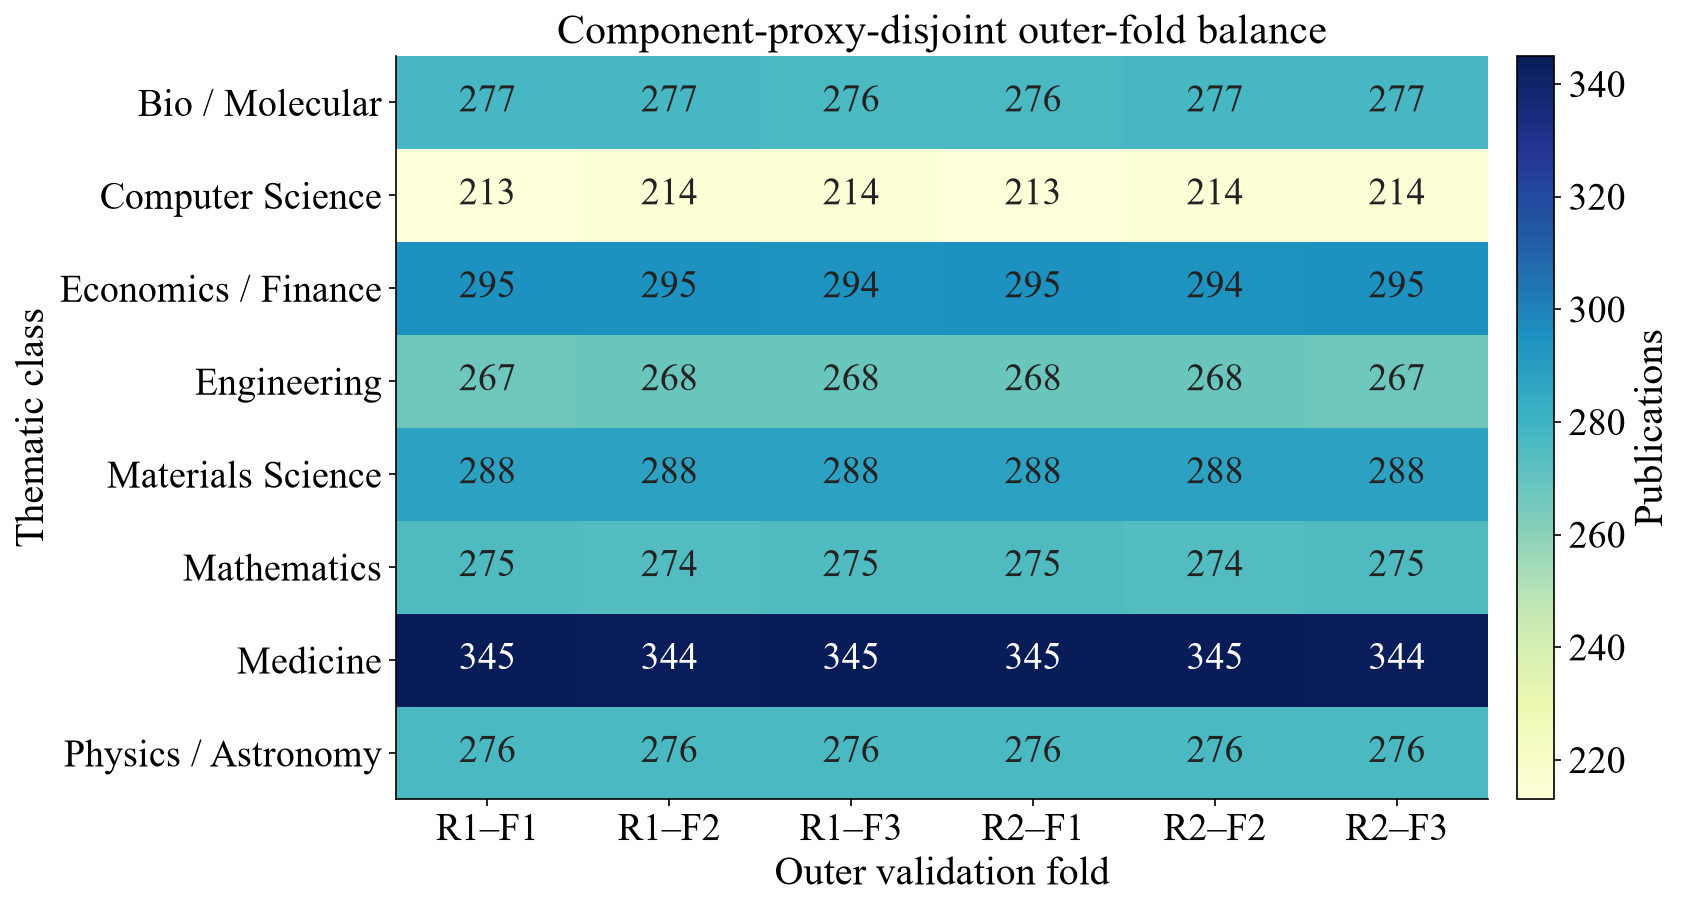

In [13]:
@dataclass(frozen=True)
class SplitParts:
    fit: np.ndarray
    stop: np.ndarray
    requested_stop_fraction: float
    actual_stop_fraction: float
    seed: int


def split_fit_stop(indices, stop_fraction, seed):
    indices = np.asarray(indices, dtype=int)
    groups = development.iloc[indices]["author_institution_component"].to_numpy()
    labels = y[indices]
    n_splits = max(2, int(round(1.0 / stop_fraction)))
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    global_distribution = np.bincount(labels, minlength=N_CLASSES) / len(labels)
    candidates = []
    for fit_local, stop_local in splitter.split(indices, labels, groups):
        stop_distribution = np.bincount(labels[stop_local], minlength=N_CLASSES) / len(stop_local)
        score = abs(len(stop_local) / len(indices) - stop_fraction)
        score += 0.05 * np.abs(stop_distribution - global_distribution).sum()
        candidates.append((score, fit_local, stop_local))
    _, fit_local, stop_local = min(candidates, key=lambda item: item[0])
    fit_indices, stop_indices = indices[fit_local], indices[stop_local]
    fit_groups = set(development.iloc[fit_indices]["author_institution_component"])
    stop_groups = set(development.iloc[stop_indices]["author_institution_component"])
    assert not set(fit_indices) & set(stop_indices)
    assert set(fit_indices) | set(stop_indices) == set(indices)
    assert not fit_groups & stop_groups
    assert len(fit_indices) > 3 * len(stop_indices)
    return SplitParts(
        fit=fit_indices,
        stop=stop_indices,
        requested_stop_fraction=stop_fraction,
        actual_stop_fraction=len(stop_indices) / len(indices),
        seed=seed,
    )


ASSIGNMENT_KEYS = ["development_row_index", "repeat", "outer_fold"]
ASSIGNMENT_LOCK_PATH = ARTIFACTS / "massk_configuration_lock.json"
assert (
    ASSIGNMENT_LOCK_PATH.exists()
), "Fail closed: the pre-existing Round-7 assignment lock is required"
assignment_lock = json.loads(ASSIGNMENT_LOCK_PATH.read_text(encoding="utf-8"))
assert assignment_lock["protocol_id"] == PROTOCOL["protocol_id"]
assert assignment_lock["round6_fold_continuity_pass"] is True
ROUND6_ASSIGNMENT_SHA256 = assignment_lock["round6_assignment_sha256"]
LOCKED_ROUND7_ASSIGNMENT_SHA256 = assignment_lock["round7_assignment_sha256"]
assert re.fullmatch(r"[0-9a-f]{64}", ROUND6_ASSIGNMENT_SHA256)
assert re.fullmatch(r"[0-9a-f]{64}", LOCKED_ROUND7_ASSIGNMENT_SHA256)
assert ROUND6_ASSIGNMENT_SHA256 == LOCKED_ROUND7_ASSIGNMENT_SHA256


def assignment_sha256(frame):
    canonical_assignment = (
        frame[ASSIGNMENT_KEYS]
        .astype(int)
        .sort_values(ASSIGNMENT_KEYS)
        .to_csv(index=False, lineterminator="\n")
    )
    return hashlib.sha256(canonical_assignment.encode("utf-8")).hexdigest()


fold_rows = []
ROUND7_OUTER_ASSIGNMENT_SEEDS = [20267181, 20268181]
assert not set(ROUND7_OUTER_ASSIGNMENT_SEEDS) & {20260717, 20261717}
for repeat, seed in enumerate(ROUND7_OUTER_ASSIGNMENT_SEEDS):
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
    groups = development["author_institution_component"].to_numpy()
    for outer_fold, (outer_train, outer_hold) in enumerate(splitter.split(development, y, groups)):
        train_groups = set(groups[outer_train])
        hold_groups = set(groups[outer_hold])
        assert not train_groups & hold_groups
        for index in outer_hold:
            fold_rows.append(
                {
                    "development_row_index": int(index),
                    "sample_id": development.iloc[index]["sample_id"],
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "author_institution_component": int(groups[index]),
                    "label_id": int(y[index]),
                    "source": development.iloc[index]["source"],
                    "publication_year": int(development.iloc[index]["publication_year"]),
                }
            )
FOLD_ASSIGNMENTS = (
    pd.DataFrame(fold_rows).sort_values(["repeat", "development_row_index"]).reset_index(drop=True)
)
assert len(FOLD_ASSIGNMENTS) == 2 * len(development)
assert FOLD_ASSIGNMENTS.groupby(["repeat", "development_row_index"]).size().eq(1).all()
round7_assignment_evidence = FOLD_ASSIGNMENTS[ASSIGNMENT_KEYS].astype(int)
ROUND7_ASSIGNMENT_SHA256 = assignment_sha256(round7_assignment_evidence)
ROUND6_FOLD_CONTINUITY_PASS = bool(
    ROUND6_ASSIGNMENT_SHA256 == ROUND7_ASSIGNMENT_SHA256
    and LOCKED_ROUND7_ASSIGNMENT_SHA256 == ROUND7_ASSIGNMENT_SHA256
    and assignment_lock["round6_fold_continuity_pass"] is True
)
fold_continuity_audit = pd.DataFrame(
    [
        {
            "round6_evidence_artifact": str(ASSIGNMENT_LOCK_PATH.relative_to(ROOT)),
            "columns_read": "NONE__LOCKED_SHA256_CONTRACT_ONLY",
            "round6_rows": 0,
            "round6_rows_interpretation": "ZERO__NO_HISTORICAL_ROW_FILE_READ",
            "round7_rows": len(round7_assignment_evidence),
            "round6_assignment_sha256": ROUND6_ASSIGNMENT_SHA256,
            "round7_assignment_sha256": ROUND7_ASSIGNMENT_SHA256,
            "locked_round7_assignment_sha256": LOCKED_ROUND7_ASSIGNMENT_SHA256,
            "locked_protocol_id": assignment_lock["protocol_id"],
            "assignment_reconstruction": "deterministic_stratified_group_kfold_from_locked_seeds",
            "historical_exposed_files_read": False,
            "historical_labels_or_probabilities_read": False,
            "continuity_status": "PASS" if ROUND6_FOLD_CONTINUITY_PASS else "FAIL",
            "test_or_external_columns_or_rows_read": 0,
        }
    ]
)
fold_continuity_audit.to_csv(TABLES / "massk_round7_round6_fold_continuity_audit.csv", index=False)
assert (
    ROUND6_FOLD_CONTINUITY_PASS
), "Fail closed: regenerated assignments differ from the pre-existing locked SHA contract"
FOLD_ASSIGNMENTS.to_parquet(TABLES / "nested_fold_assignments.parquet", index=False)

fold_balance = (
    FOLD_ASSIGNMENTS.groupby(["repeat", "outer_fold", "label_id"])
    .size()
    .rename("rows")
    .reset_index()
)
fold_balance["proportion_within_fold"] = fold_balance["rows"] / fold_balance.groupby(
    ["repeat", "outer_fold"]
)["rows"].transform("sum")
fold_balance.to_csv(TABLES / "fold_balance_audit.csv", index=False)

matrix = fold_balance.pivot_table(
    index='label_id', columns=['repeat', 'outer_fold'], values='rows', aggfunc='sum'
).fillna(0)
short_names = [
    'Bio / Molecular',
    'Computer Science',
    'Economics / Finance',
    'Engineering',
    'Materials Science',
    'Mathematics',
    'Medicine',
    'Physics / Astronomy',
]
fig, ax = plt.subplots(figsize=(11.5, 6.4))
image = ax.imshow(matrix.to_numpy(), cmap='YlGnBu', aspect='auto')
ax.set_yticks(np.arange(len(matrix.index)), short_names)
ax.set_xticks(np.arange(matrix.shape[1]), [f'R{r+1}–F{f+1}' for r, f in matrix.columns])
ax.set_title('Component-proxy-disjoint outer-fold balance')
ax.set_xlabel('Outer validation fold')
ax.set_ylabel('Thematic class')
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix.iloc[row, column]
        rgba = image.cmap(image.norm(value))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(
            column,
            row,
            f'{int(value)}',
            ha='center',
            va='center',
            fontsize=18,
            color=PALETTE['white'] if luminance < 0.48 else PALETTE['black'],
        )
colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.025)
colorbar.set_label('Publications')
fig.tight_layout()
path = FIGURES / 'nested_validation_balance.png'
fig.savefig(path, dpi=350, bbox_inches='tight', facecolor='white')
plt.show()

In [14]:
FACTORY_BEHAVIORAL_INVARIANCE_AUDIT_ROWS = []
representative_assignment = FOLD_ASSIGNMENTS[FOLD_ASSIGNMENTS["repeat"].eq(0)].sort_values(
    "development_row_index"
)
representative_fold_vector = representative_assignment["outer_fold"].to_numpy()
representative_outer_train = np.flatnonzero(representative_fold_vector != 0)
representative_outer_hold = np.flatnonzero(representative_fold_vector == 0)
representative_parts = split_fit_stop(representative_outer_train, stop_fraction=0.12, seed=20267301)
audit_collections = {
    "preprocessing": PREPROCESSING_ROWS,
    "metadata": METADATA_FACTORY_AUDIT_ROWS,
    "venue": VENUE_SEEN_UNSEEN_ROWS,
    "concept": CONCEPT_FACTORY_AUDIT_ROWS,
    "contract": FACTORY_CONTRACT_ROWS,
}
audit_collection_lengths = {name: len(values) for name, values in audit_collections.items()}
y_before_audit = y.copy()
safe_references_before_audit = deepcopy(safe_reference_terms)
try:
    original_bundle = build_fold_bundle(
        representative_parts.fit,
        "behavioral_invariance_representative",
        stop_indices=representative_parts.stop,
        hold_indices=representative_outer_hold,
    )
    original_contract = deepcopy(FACTORY_CONTRACT_ROWS[-1])
    field = "source_name"
    fit_row = int(representative_parts.fit[0])
    fit_label = int(y_before_audit[fit_row])
    field_keys = normalized_metadata_values(field)
    field_state = original_bundle["objects"]["metadata_target_encoders"][field]
    group_counts = (
        field_state["group_counts"]
        .get(field_keys[fit_row], np.zeros(N_CLASSES, dtype=np.float64))
        .copy()
    )
    global_counts = np.bincount(
        y_before_audit[representative_parts.fit], minlength=N_CLASSES
    ).astype(np.float64)
    group_counts[fit_label] -= 1.0
    global_counts[fit_label] -= 1.0
    effective_count = float(group_counts.sum())
    loo_prior = global_counts / global_counts.sum()
    alpha = float(field_state["alpha"])
    expected_loo = (group_counts + alpha * loo_prior) / (effective_count + alpha)
    numeric_width = original_bundle["metadata"].shape[1] - len(CATEGORICAL_METADATA) * (
        N_CLASSES + 3
    )
    field_start = numeric_width + CATEGORICAL_METADATA.index(field) * (N_CLASSES + 3)
    observed_loo = original_bundle["metadata"][fit_row, field_start : field_start + N_CLASSES]
    loo_maximum_error = float(np.max(np.abs(observed_loo - expected_loo)))

    forbidden_rows = np.unique(
        np.concatenate([representative_parts.stop, representative_outer_hold])
    ).astype(int)
    y[forbidden_rows] = (y[forbidden_rows] + 1) % N_CLASSES
    for index in forbidden_rows:
        safe_reference_terms[int(index)] = ["forbidden_reference_target_sentinel"]
    perturbed_bundle = build_fold_bundle(
        representative_parts.fit,
        "behavioral_invariance_representative",
        stop_indices=representative_parts.stop,
        hold_indices=representative_outer_hold,
    )
    perturbed_contract = deepcopy(FACTORY_CONTRACT_ROWS[-1])
    matrix_invariance = {
        branch: bool(np.array_equal(original_bundle[branch], perturbed_bundle[branch]))
        for branch in ["lexical", "metadata", "concept"]
    }
    vocabulary_invariant = bool(
        original_bundle["kp_terms"] == perturbed_bundle["kp_terms"]
        and original_contract["concept_vocabulary_sha256"]
        == perturbed_contract["concept_vocabulary_sha256"]
    )
    prototype_invariant = bool(
        original_contract["concept_prototype_sha256"]
        == perturbed_contract["concept_prototype_sha256"]
    )
    target_encoder_hashes_invariant = bool(
        original_contract["metadata_statistics_sha256"]
        == perturbed_contract["metadata_statistics_sha256"]
    )
    audit_pass = bool(
        all(matrix_invariance.values())
        and vocabulary_invariant
        and prototype_invariant
        and target_encoder_hashes_invariant
        and loo_maximum_error < 1e-7
    )
    FACTORY_BEHAVIORAL_INVARIANCE_AUDIT_ROWS.append(
        {
            "representative_repeat": 0,
            "representative_outer_fold": 0,
            "fit_rows": len(representative_parts.fit),
            "perturbed_stop_hold_rows": len(forbidden_rows),
            "lexical_matrix_invariant": matrix_invariance["lexical"],
            "metadata_matrix_invariant": matrix_invariance["metadata"],
            "concept_matrix_invariant": matrix_invariance["concept"],
            "vocabulary_hash_invariant": vocabulary_invariant,
            "prototype_hash_invariant": prototype_invariant,
            "target_encoder_hashes_invariant": target_encoder_hashes_invariant,
            "fit_row_own_label_exclusion_max_error": loo_maximum_error,
            "fit_row_own_label_exclusion_pass": loo_maximum_error < 1e-7,
            "forbidden_reference_target_perturbation_applied": True,
            "test_or_external_rows_consumed": 0,
            "status": "PASS" if audit_pass else "FAIL",
        }
    )
    assert audit_pass
finally:
    y[:] = y_before_audit
    safe_reference_terms[:] = safe_references_before_audit
    for name, values in audit_collections.items():
        del values[audit_collection_lengths[name] :]
factory_behavioral_invariance_audit = pd.DataFrame(FACTORY_BEHAVIORAL_INVARIANCE_AUDIT_ROWS)
assert factory_behavioral_invariance_audit["status"].eq("PASS").all()
factory_behavioral_invariance_audit.to_csv(
    TABLES / "massk_round7_factory_behavioral_invariance_audit.csv", index=False
)
display(factory_behavioral_invariance_audit)

,representative_repeat,representative_outer_fold,fit_rows,perturbed_stop_hold_rows,lexical_matrix_invariant,metadata_matrix_invariant,concept_matrix_invariant,vocabulary_hash_invariant,prototype_hash_invariant,target_encoder_hashes_invariant,fit_row_own_label_exclusion_max_error,fit_row_own_label_exclusion_pass,forbidden_reference_target_perturbation_applied,test_or_external_rows_consumed,status
0,0,0,3913,2795,True,True,True,True,True,True,6.033599e-09,True,True,0,PASS


## 6. Metrics, structural endpoints, and the fixed multi-objective score


#### 6.1 Classification, calibration, and uncertainty metrics

In [15]:
def expected_calibration_error(targets, probabilities, bins=15):
    confidence = probabilities.max(1)
    correct = probabilities.argmax(1) == targets
    total = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any():
            total += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(total)


def uncertainty_aurc(targets, probabilities, uncertainty=None):
    predicted = probabilities.argmax(1)
    error = (predicted != targets).astype(float)
    if uncertainty is None:
        uncertainty = 1.0 - probabilities.max(1)
    order = np.argsort(uncertainty)
    cumulative_error = np.cumsum(error[order]) / np.arange(1, len(error) + 1)
    return float(cumulative_error.mean())


def probability_metrics(targets, probabilities):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    probabilities = np.clip(probabilities, 1e-9, 1.0)
    probabilities /= probabilities.sum(1, keepdims=True)
    predicted = probabilities.argmax(1)
    one_hot = np.eye(N_CLASSES)[targets]
    sorted_prob = np.sort(probabilities, axis=1)
    margin_uncertainty = 1.0 - (sorted_prob[:, -1] - sorted_prob[:, -2])
    entropy = -(probabilities * np.log(probabilities)).sum(1) / math.log(N_CLASSES)
    error = (predicted != targets).astype(int)
    return {
        "accuracy": accuracy_score(targets, predicted),
        "balanced_accuracy": balanced_accuracy_score(targets, predicted),
        "macro_f1": f1_score(
            targets, predicted, labels=np.arange(N_CLASSES), average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            targets, predicted, labels=np.arange(N_CLASSES), average="weighted", zero_division=0
        ),
        "macro_precision": precision_score(
            targets, predicted, labels=np.arange(N_CLASSES), average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            targets, predicted, labels=np.arange(N_CLASSES), average="macro", zero_division=0
        ),
        "mcc": matthews_corrcoef(targets, predicted),
        "nll": log_loss(targets, probabilities, labels=np.arange(N_CLASSES)),
        "ece_15": expected_calibration_error(targets, probabilities),
        "brier_multiclass": float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))),
        "error_auroc": (
            roc_auc_score(error, margin_uncertainty) if len(np.unique(error)) == 2 else 0.5
        ),
        "entropy_error_auroc": roc_auc_score(error, entropy) if len(np.unique(error)) == 2 else 0.5,
        "aurc": uncertainty_aurc(targets, probabilities, margin_uncertainty),
    }

#### 6.2 Retrieval metrics and score normalization

In [16]:
def retrieval_per_query(similarities, query_labels, document_labels, k=10):
    similarities = np.asarray(similarities, dtype=np.float32)
    assert similarities.shape == (len(query_labels), len(document_labels))
    k = min(k, similarities.shape[1])
    candidates = np.argpartition(similarities, -k, axis=1)[:, -k:]
    candidate_scores = np.take_along_axis(similarities, candidates, axis=1)
    order = np.lexsort((candidates, -candidate_scores), axis=1)
    ranked = np.take_along_axis(candidates, order, axis=1)
    ndcg, average_precision, reciprocal, precision, recall, hits = [], [], [], [], [], []
    for found, label in zip(ranked, query_labels):
        relevant = (document_labels[found] == label).astype(float)
        ranks = np.arange(1, k + 1)
        total_relevant = max(1, int((document_labels == label).sum()))
        ideal = min(total_relevant, k)
        denominator = np.sum(1.0 / np.log2(np.arange(1, ideal + 1) + 1))
        ndcg.append(np.sum(relevant / np.log2(ranks + 1)) / denominator)
        average_precision.append(
            np.sum(np.cumsum(relevant) / ranks * relevant) / min(total_relevant, k)
        )
        reciprocal.append(0.0 if not relevant.any() else 1.0 / (np.flatnonzero(relevant)[0] + 1))
        precision.append(relevant.mean())
        recall.append(relevant.sum() / total_relevant)
        hits.append(float(relevant.any()))
    return pd.DataFrame(
        {
            "ndcg_at_10": ndcg,
            "map_at_10": average_precision,
            "mrr_at_10": reciprocal,
            "precision_at_10": precision,
            "recall_at_10": recall,
            "hit_rate_at_10": hits,
        }
    )


def retrieval_metrics_from_scores(similarities, query_labels, document_labels, k=10):
    per_query = retrieval_per_query(similarities, query_labels, document_labels, k=k)
    return {column: float(per_query[column].mean()) for column in per_query}


def retrieval_metrics(query, documents, query_labels, document_labels, k=10):
    query = query / (np.linalg.norm(query, axis=1, keepdims=True) + 1e-8)
    documents = documents / (np.linalg.norm(documents, axis=1, keepdims=True) + 1e-8)
    return retrieval_metrics_from_scores(query @ documents.T, query_labels, document_labels, k=k)


def cosine_score_matrix(query, documents):
    query = np.asarray(query, dtype=np.float32)
    documents = np.asarray(documents, dtype=np.float32)
    query = query / (np.linalg.norm(query, axis=1, keepdims=True) + 1e-8)
    documents = documents / (np.linalg.norm(documents, axis=1, keepdims=True) + 1e-8)
    return (query @ documents.T).astype(np.float32)


def standardize_score_rows(scores):
    scores = np.asarray(scores, dtype=np.float32)
    row_mean = scores.mean(1, keepdims=True)
    row_std = scores.std(1, keepdims=True)
    return ((scores - row_mean) / np.maximum(row_std, 1e-6)).astype(np.float32)

#### 6.3 Closed-vocabulary tagging and validation objective

In [17]:
def closed_vocab_tagging_per_query(scores, targets, present_targets=None, k=10):
    scores = np.asarray(scores, dtype=np.float32)
    targets = np.asarray(targets, dtype=bool)
    if present_targets is None:
        present_targets = np.zeros_like(targets, dtype=bool)
    else:
        present_targets = np.asarray(present_targets, dtype=bool)
    absent_targets = targets & ~present_targets
    assert not np.any(present_targets & absent_targets)
    assert np.array_equal(present_targets | absent_targets, targets)
    if targets.shape[1] == 0:
        return pd.DataFrame({"f1_at_10": np.zeros(len(targets))})
    k = min(k, targets.shape[1])
    chosen = np.argsort(-scores, axis=1, kind="stable")[:, :k]
    rows = []
    for row, selected in enumerate(chosen):
        predicted = set(selected.tolist())
        record = {}
        for scope, mask in [
            ("all", targets[row]),
            ("present", present_targets[row]),
            ("absent", absent_targets[row]),
        ]:
            gold = set(np.flatnonzero(mask).tolist())
            hits = len(predicted & gold)
            precision_value = hits / k
            recall_value = hits / max(1, len(gold))
            f1_value = (
                0.0
                if precision_value + recall_value == 0
                else 2 * precision_value * recall_value / (precision_value + recall_value)
            )
            union = len(predicted | gold)
            record.update(
                {
                    f"{scope}_gold_count": len(gold),
                    f"{scope}_hits_at_10": hits,
                    f"{scope}_precision_at_10": precision_value,
                    f"{scope}_recall_at_10": recall_value,
                    f"{scope}_f1_at_10": f1_value,
                    f"{scope}_jaccard_at_10": hits / max(1, union),
                }
            )
        rows.append(record)
    return pd.DataFrame(rows)


def keyphrase_metrics(scores, targets, k=10, present_targets=None):
    per_query = closed_vocab_tagging_per_query(
        scores, targets, present_targets=present_targets, k=k
    )
    eligible = per_query["all_gold_count"].gt(0)
    return {
        "keyphrase_f1_at_10": float(per_query["all_f1_at_10"].mean()),
        "keyphrase_precision_at_10": float(per_query["all_precision_at_10"].mean()),
        "keyphrase_recall_at_10": float(per_query["all_recall_at_10"].mean()),
        "keyphrase_eligible_rate": float(eligible.mean()),
        "keyphrase_f1_at_10_eligible": (
            float(per_query.loc[eligible, "all_f1_at_10"].mean()) if eligible.any() else 0.0
        ),
        "present_f1_at_10_eligible": (
            float(per_query.loc[per_query["present_gold_count"].gt(0), "present_f1_at_10"].mean())
            if per_query["present_gold_count"].gt(0).any()
            else 0.0
        ),
        "absent_f1_at_10_eligible": (
            float(per_query.loc[per_query["absent_gold_count"].gt(0), "absent_f1_at_10"].mean())
            if per_query["absent_gold_count"].gt(0).any()
            else 0.0
        ),
    }


def validation_objective(metrics, structural, parameters, latency_ms):
    latency_utility = float(np.exp(-max(latency_ms, 0.0) / 10.0))
    complexity_utility = float(np.exp(-max(parameters, 0) / 2_000_000.0))
    return (
        0.35 * metrics["macro_f1"]
        + 0.15 * metrics["balanced_accuracy"]
        + 0.08 * structural["ndcg_at_10"]
        + 0.07 * structural["map_at_10"]
        + 0.07 * structural["keyphrase_f1_at_10"]
        + 0.06 * (1.0 - metrics["ece_15"])
        + 0.06 * (1.0 - metrics["brier_multiclass"] / 2.0)
        + 0.06 * metrics["error_auroc"]
        + 0.05 * latency_utility
        + 0.05 * complexity_utility
    )

## 7. Single-view semantic sub-expert with gradient-isolated structural heads


#### 7.1 MASSK module registry and trainable heads

In [18]:
BRANCH_COLUMN = {"lexical": 0, "semantic": 1, "metadata": 2, "concept": 3}


class StrictMASSK(nn.Module):
    def __init__(self, config, dimensions, keyphrase_dimension):
        super().__init__()
        self.config = deepcopy(config)
        self.active_branches = list(config["active_branches"])
        self.predictive_active = list(config.get("predictive_active", self.active_branches))
        self.structural_only = list(config.get("structural_only", []))
        assert set(self.predictive_active) == set(self.active_branches)
        assert not set(self.active_branches) & set(
            self.structural_only
        ), "predictive_active and structural_only roles must be disjoint"
        self.semantic_keys = list(config["semantic_keys"])
        self.d_model = int(config["d_model"])
        self.aux_cap = float(config["aux_logit_cap"])
        d = self.d_model

        if "semantic" in self.active_branches:
            assert self.semantic_keys
            self.semantic_projections = nn.ModuleDict(
                {
                    key: nn.Sequential(
                        nn.LayerNorm(dimensions[key]),
                        nn.Linear(dimensions[key], d),
                        nn.GELU(),
                        nn.Dropout(config["dropout"]),
                    )
                    for key in self.semantic_keys
                }
            )
            self.semantic_thematic_head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, N_CLASSES))
            self.semantic_view_position = nn.Parameter(
                torch.randn(1, len(self.semantic_keys), d) * 0.01
            )
            if int(config.get("cross_view_layers", 1)):
                cross_view_layer = nn.TransformerEncoderLayer(
                    d_model=d,
                    nhead=4,
                    dim_feedforward=2 * d,
                    dropout=config["dropout"],
                    activation="gelu",
                    batch_first=True,
                    norm_first=True,
                )
                self.cross_view_block = nn.TransformerEncoder(cross_view_layer, num_layers=1)
            else:
                self.cross_view_block = None
            self.semantic_view_fusion = config.get("semantic_view_fusion", "uniform")
            assert self.semantic_view_fusion == "uniform", (
                "Each semantic sub-expert is single-view; uniform is "
                "the identity operation inside an expert"
            )
            self.semantic_state_norm = nn.LayerNorm(d)
        else:
            self.null_anchor = nn.Parameter(torch.zeros(1, d))
            self.null_head = nn.Linear(d, N_CLASSES)

        auxiliary = [branch for branch in self.active_branches if branch != "semantic"]
        self.auxiliary_branches = auxiliary
        self.auxiliary_encoders = nn.ModuleDict(
            {
                branch: nn.Sequential(
                    nn.LayerNorm(dimensions[branch]),
                    nn.Linear(dimensions[branch], d),
                    nn.GELU(),
                    nn.Dropout(config["dropout"]),
                    nn.Linear(d, d),
                    nn.GELU(),
                )
                for branch in auxiliary
            }
        )
        self.auxiliary_heads = nn.ModuleDict(
            {
                branch: nn.Sequential(
                    nn.LayerNorm(dimensions[branch]), nn.Linear(dimensions[branch], N_CLASSES)
                )
                for branch in auxiliary
            }
        )

        if config["fusion_mode"] != "uniform":
            self.reliability_gates = nn.ModuleDict(
                {
                    branch: nn.Sequential(nn.Linear(2 * d + 5, 64), nn.GELU(), nn.Linear(64, 1))
                    for branch in auxiliary
                }
            )
        if config["fusion_mode"] == "attentive" and auxiliary:
            self.cross_attention = nn.MultiheadAttention(
                d, num_heads=4, dropout=config["dropout"], batch_first=True
            )
            self.interaction_head = nn.Sequential(
                nn.LayerNorm(d),
                nn.Linear(d, int(config["interaction_rank"])),
                nn.GELU(),
                nn.Linear(int(config["interaction_rank"]), N_CLASSES),
            )

        self.fusion_norm = nn.LayerNorm(d) if self.auxiliary_branches else nn.Identity()
        if self.auxiliary_branches:
            self.fusion_head = nn.Linear(d, N_CLASSES)
            self.fusion_scale = nn.Parameter(torch.tensor(-2.0))
        else:
            self.fusion_head = None
            self.register_parameter("fusion_scale", None)
        self.retrieval_projection = nn.Linear(d, 128)
        self.prototypes = nn.Parameter(torch.randn(N_CLASSES, 128) * 0.03)
        self.keyphrase_head = nn.Linear(d, keyphrase_dimension) if keyphrase_dimension else None

#### 7.2 Availability-safe semantic and auxiliary encoding

In [19]:
def _strict_prepare_context(self, batch, training_dropout):
    availability = batch["availability"].clone()
    # Coarse modality dropout is auxiliary-only. With semantic as the sole
    # active branch, the old restore-first logic made dropout a no-op.
    auxiliary_columns = [BRANCH_COLUMN[name] for name in self.active_branches if name != "semantic"]
    if training_dropout and auxiliary_columns and self.config["modality_dropout"] > 0:
        original = availability[:, auxiliary_columns].clone()
        keep = torch.rand_like(original.float()) > self.config["modality_dropout"]
        availability[:, auxiliary_columns] = original & keep

    states = {}
    semantic_logits = None
    view_logits = torch.zeros((len(availability), 0, N_CLASSES), device=availability.device)
    view_weights = torch.zeros((len(availability), 0), device=availability.device)
    semantic_view_mask = torch.zeros(
        (len(availability), 0), dtype=torch.bool, device=availability.device
    )
    semantic_available = (
        availability[:, BRANCH_COLUMN["semantic"]] if "semantic" in self.active_branches else None
    )
    if "semantic" in self.active_branches:
        projected_views = torch.stack(
            [self.semantic_projections[key](batch[key]) for key in self.semantic_keys], dim=1
        )
        semantic_view_mask = semantic_available[:, None].expand(-1, len(self.semantic_keys)).clone()
        view_dropout = float(self.config.get("view_dropout", 0.0))
        if training_dropout and view_dropout > 0 and len(self.semantic_keys) > 1:
            keep = (
                torch.rand(semantic_view_mask.shape, device=semantic_view_mask.device)
                > view_dropout
            )
            dropped = semantic_view_mask & keep
            empty = semantic_available & ~dropped.any(1)
            if empty.any():
                rows = torch.nonzero(empty, as_tuple=False).flatten()
                restore = torch.randint(
                    0, len(self.semantic_keys), (len(rows),), device=semantic_view_mask.device
                )
                dropped[rows, restore] = True
            semantic_view_mask = dropped

        safe_view_mask = semantic_view_mask.clone()
        no_view = ~safe_view_mask.any(1)
        if no_view.any():
            safe_view_mask[no_view, 0] = True
        tokens = projected_views + self.semantic_view_position
        padding = ~safe_view_mask
        if self.cross_view_block is not None:
            tokens = self.cross_view_block(tokens, src_key_padding_mask=padding)
        encoded_views = tokens
        view_weights = safe_view_mask.float()
        view_weights = view_weights / view_weights.sum(1, keepdim=True).clamp_min(1.0)
        semantic_state = self.semantic_state_norm((encoded_views * view_weights[:, :, None]).sum(1))
        semantic_logits = self.semantic_thematic_head(semantic_state)
        semantic_state = semantic_state * semantic_available[:, None]
        semantic_logits = semantic_logits * semantic_available[:, None]
        states["semantic"] = semantic_state
    else:
        semantic_state = None

    auxiliary_logits_by_branch = {}
    for branch in self.auxiliary_branches:
        states[branch] = self.auxiliary_encoders[branch](batch[branch])
        states[branch] = states[branch] * availability[:, BRANCH_COLUMN[branch], None]
        auxiliary_logits_by_branch[branch] = self.auxiliary_heads[branch](batch[branch])

    return {
        "availability": availability,
        "states": states,
        "semantic_logits": semantic_logits,
        "view_logits": view_logits,
        "view_weights": view_weights,
        "semantic_view_mask": semantic_view_mask,
        "semantic_state": semantic_state,
        "auxiliary_logits_by_branch": auxiliary_logits_by_branch,
    }

#### 7.3 Semantic anchor and uncertainty context

In [20]:
def _strict_anchor_context(self, batch, context):
    availability = context["availability"]
    states = context["states"]
    semantic_logits = context["semantic_logits"]
    semantic_state = context["semantic_state"]
    auxiliary_logits_by_branch = context["auxiliary_logits_by_branch"]
    if semantic_state is None:
        if self.auxiliary_branches:
            masks = torch.stack(
                [
                    availability[:, BRANCH_COLUMN[branch]].float()
                    for branch in self.auxiliary_branches
                ],
                dim=1,
            )
            tokens = torch.stack([states[branch] for branch in self.auxiliary_branches], dim=1)
            denominator = masks.sum(1, keepdim=True).clamp_min(1.0)
            anchor = (tokens * masks[:, :, None]).sum(1) / denominator
            auxiliary_logits = torch.stack(
                [auxiliary_logits_by_branch[branch] for branch in self.auxiliary_branches], dim=1
            )
            anchor_logits = (auxiliary_logits * masks[:, :, None]).sum(1) / denominator
        else:
            anchor = self.null_anchor.expand(len(batch["availability"]), -1)
            anchor_logits = self.null_head(anchor)
    else:
        anchor = semantic_state
        anchor_logits = semantic_logits

    anchor_prob = anchor_logits.softmax(1)
    entropy = -(anchor_prob * torch.log(anchor_prob + 1e-8)).sum(1, keepdim=True) / math.log(
        N_CLASSES
    )
    sorted_prob = anchor_prob.sort(1).values
    margin = sorted_prob[:, -1:] - sorted_prob[:, -2:-1]

    residual_logits = torch.zeros_like(anchor_logits)
    residual_state = torch.zeros_like(anchor)
    gate_values = []
    branch_names = ["semantic"] if "semantic" in self.active_branches else []
    branch_logits = [anchor_logits] if "semantic" in self.active_branches else []
    context.update(
        {
            "anchor": anchor,
            "anchor_logits": anchor_logits,
            "entropy": entropy,
            "margin": margin,
            "residual_logits": residual_logits,
            "residual_state": residual_state,
            "gate_values": gate_values,
            "branch_names": branch_names,
            "branch_logits": branch_logits,
        }
    )
    return context

#### 7.4 Reliability routing, bounded residual fusion, and structural heads

In [21]:
def _strict_forward(self, batch, training_dropout=False):
    context = _strict_prepare_context(self, batch, training_dropout)
    context = _strict_anchor_context(self, batch, context)
    availability = context["availability"]
    states = context["states"]
    view_logits = context["view_logits"]
    view_weights = context["view_weights"]
    semantic_view_mask = context["semantic_view_mask"]
    auxiliary_logits_by_branch = context["auxiliary_logits_by_branch"]
    anchor = context["anchor"]
    anchor_logits = context["anchor_logits"]
    entropy = context["entropy"]
    margin = context["margin"]
    residual_logits = context["residual_logits"]
    residual_state = context["residual_state"]
    gate_values = context["gate_values"]
    branch_names = context["branch_names"]
    branch_logits = context["branch_logits"]
    for branch in self.auxiliary_branches:
        state = states[branch]
        logits = auxiliary_logits_by_branch[branch]
        centered = logits - logits.mean(1, keepdim=True)
        centered = centered / centered.std(1, keepdim=True).clamp_min(0.25)
        available = availability[:, BRANCH_COLUMN[branch]].float()[:, None]
        if self.config["fusion_mode"] == "uniform":
            gate = torch.full_like(available, self.aux_cap / max(1, len(self.auxiliary_branches)))
        else:
            auxiliary_prob = logits.softmax(1)
            auxiliary_entropy = -(auxiliary_prob * torch.log(auxiliary_prob + 1e-8)).sum(
                1, keepdim=True
            ) / math.log(N_CLASSES)
            auxiliary_sorted = auxiliary_prob.sort(1).values
            auxiliary_margin = auxiliary_sorted[:, -1:] - auxiliary_sorted[:, -2:-1]
            compatibility = F.cosine_similarity(anchor, state, dim=1)[:, None]
            gate_input = torch.cat(
                [
                    anchor,
                    state,
                    entropy,
                    margin,
                    auxiliary_entropy,
                    auxiliary_margin,
                    compatibility,
                ],
                dim=1,
            )
            gate = self.aux_cap * torch.sigmoid(self.reliability_gates[branch](gate_input))
        gate = gate * available
        residual_logits = residual_logits + gate * torch.tanh(centered)
        residual_state = residual_state + gate * state
        gate_values.append(gate)
        branch_names.append(branch)
        branch_logits.append(logits)

    interaction_logits = torch.zeros_like(anchor_logits)
    interaction_state = torch.zeros_like(anchor)
    if self.config["fusion_mode"] == "attentive" and self.auxiliary_branches:
        tokens = torch.stack([states[branch] for branch in self.auxiliary_branches], dim=1)
        padding = torch.stack(
            [~availability[:, BRANCH_COLUMN[branch]] for branch in self.auxiliary_branches], dim=1
        )
        safe_padding = padding.clone()
        all_missing = safe_padding.all(1)
        if all_missing.any():
            safe_padding[all_missing, 0] = False
            tokens[all_missing, 0] = 0
        attended, _ = self.cross_attention(
            anchor[:, None, :], tokens, tokens, key_padding_mask=safe_padding, need_weights=False
        )
        interaction_state = attended[:, 0] * (~all_missing)[:, None]
        interaction_logits = self.aux_cap * torch.tanh(self.interaction_head(interaction_state))

    fused = self.fusion_norm(anchor + residual_state + interaction_state)
    bounded_fusion = (
        0.20 * torch.sigmoid(self.fusion_scale) * torch.tanh(self.fusion_head(fused))
        if self.fusion_head is not None
        else torch.zeros_like(anchor_logits)
    )
    logits = anchor_logits + residual_logits + interaction_logits + bounded_fusion

    if gate_values:
        gates = torch.cat(gate_values, dim=1)
    else:
        gates = torch.zeros((len(logits), 0), device=logits.device)
    semantic_gate = (
        torch.ones((len(logits), 1), device=logits.device)
        if "semantic" in self.active_branches
        else torch.zeros((len(logits), 0), device=logits.device)
    )
    routing = torch.cat([semantic_gate, gates], dim=1)
    routing = routing / routing.sum(1, keepdim=True).clamp_min(1e-6)

    # Structural heads are intentionally gradient-isolated from the
    # thematic encoder and the expert-specific classifier head.
    structural_fused = fused.detach()
    result = {
        "logits": logits,
        "anchor_logits": anchor_logits,
        "branch_logits": torch.stack(branch_logits, dim=1) if branch_logits else logits[:, None, :],
        "branch_names": branch_names,
        "routing": routing,
        "view_logits": view_logits,
        "view_weights": view_weights,
        "semantic_view_mask": semantic_view_mask,
        "retrieval": F.normalize(self.retrieval_projection(structural_fused), dim=1),
        "fused": fused,
    }
    result["keyphrase_logits"] = (
        self.keyphrase_head(structural_fused)
        if self.keyphrase_head is not None
        else torch.zeros((len(logits), 0), device=logits.device)
    )
    return result


StrictMASSK.forward = _strict_forward

## 8. GPU training, exact semantic experts, and physical-ablation assertions


### 8.1 Active fold bundle and deterministic batching


In [22]:
ACTIVE_STORE = None
ACTIVE_DIMENSIONS = None


def activate_bundle(bundle):
    global ACTIVE_STORE, ACTIVE_DIMENSIONS
    if ACTIVE_STORE is not None:
        del ACTIVE_STORE
        torch.cuda.empty_cache()
    ACTIVE_STORE = {
        "lexical": torch.from_numpy(bundle["lexical"]).to(device),
        "metadata": torch.from_numpy(bundle["metadata"]).to(device),
        "concept": torch.from_numpy(bundle["concept"]).to(device),
        "availability": torch.from_numpy(bundle["availability"]).to(device),
        "kp_targets": torch.from_numpy(bundle["kp_targets"]).to(device),
    }
    for name, values in bundle["semantic"].items():
        ACTIVE_STORE[name] = torch.from_numpy(values).to(device)
    ACTIVE_DIMENSIONS = {
        "lexical": bundle["lexical"].shape[1],
        "metadata": bundle["metadata"].shape[1],
        "concept": bundle["concept"].shape[1],
        **{name: values.shape[1] for name, values in bundle["semantic"].items()},
    }


def make_batch(indices, availability_override=None, permutations=None, noise=None):
    index = torch.as_tensor(indices, dtype=torch.long, device=device)
    batch = {name: tensor[index] for name, tensor in ACTIVE_STORE.items()}
    if availability_override is not None:
        batch["availability"] = availability_override[index]
    if permutations:
        for branch, permutation in permutations.items():
            perm = torch.as_tensor(permutation, dtype=torch.long, device=device)
            if branch == "semantic":
                for key in SEMANTIC:
                    batch[key] = ACTIVE_STORE[key][perm]
            else:
                batch[branch] = ACTIVE_STORE[branch][perm]
    if noise:
        generator = torch.Generator(device=device)
        generator.manual_seed(int(noise.get("seed", 0)))
        for key, sigma in noise.get("features", {}).items():
            batch[key] = batch[key] + float(sigma) * torch.randn(
                batch[key].shape, generator=generator, device=device
            )
    return batch

### 8.2 Physical-removal contracts and seeds


In [23]:
def model_parameter_count(model):
    return int(sum(parameter.numel() for parameter in model.parameters()))


def physical_ablation_audit(full_model, ablated_model, removed_branch):
    full_names = {name for name, _ in full_model.named_parameters()}
    ablated_names = {name for name, _ in ablated_model.named_parameters()}
    branch_tokens = {
        "lexical": [
            "auxiliary_encoders.lexical",
            "auxiliary_heads.lexical",
            "reliability_gates.lexical",
        ],
        "metadata": [
            "auxiliary_encoders.metadata",
            "auxiliary_heads.metadata",
            "reliability_gates.metadata",
        ],
        "concept": [
            "auxiliary_encoders.concept",
            "auxiliary_heads.concept",
            "reliability_gates.concept",
        ],
        "semantic": ["semantic_projections", "semantic_thematic_head"],
    }[removed_branch]
    removed_absent = not any(
        any(token in name for token in branch_tokens) for name in ablated_names
    )
    return {
        "removed_branch": removed_branch,
        "removed_modules_absent": bool(removed_absent),
        "full_parameters": model_parameter_count(full_model),
        "ablated_parameters": model_parameter_count(ablated_model),
        "parameter_reduction": model_parameter_count(full_model)
        - model_parameter_count(ablated_model),
        "pass": bool(
            removed_absent
            and model_parameter_count(ablated_model) < model_parameter_count(full_model)
        ),
    }


def single_view_config(base_config, view, identifier_suffix=None):
    assert view in PRIMARY_SEMANTIC_KEYS
    config = deepcopy(base_config)
    config["semantic_keys"] = [view]
    config["semantic_structural_only"] = []
    config["nonactive_semantic_views"] = [key for key in SEMANTIC_KEYS_ALL if key != view]
    config["cross_view_layers"] = 0
    config["view_dropout"] = 0.0
    config["semantic_view_fusion"] = "uniform"
    config["fusion_mode"] = "uniform"
    config["shared_thematic_head"] = False
    config["joint_two_view_classifier_core"] = False
    config["classifier_fusion_space"] = "single_view_raw_probability"
    config["id"] = (
        base_config["id"]
        + "__expert_"
        + view
        + ("__" + str(identifier_suffix) if identifier_suffix else "")
    )
    return config


def classifier_parameter_count(model):
    classifier_prefixes = (
        "semantic_projections.",
        "semantic_thematic_head.",
        "semantic_view_position",
        "semantic_state_norm.",
    )
    return int(
        sum(
            parameter.numel()
            for name, parameter in model.named_parameters()
            if name.startswith(classifier_prefixes)
        )
    )


def independent_expert_deletion_audit(expert_models, removed_view):
    assert set(expert_models) == set(PRIMARY_SEMANTIC_KEYS)
    assert removed_view in expert_models
    retained_view = next(view for view in PRIMARY_SEMANTIC_KEYS if view != removed_view)
    retained_model = expert_models[retained_view]
    removed_model = expert_models[removed_view]
    ignored = {"id", "semantic_keys", "semantic_structural_only", "classifier_fusion_space"}
    retained_contract = {
        key: value for key, value in retained_model.config.items() if key not in ignored
    }
    removed_contract = {
        key: value for key, value in removed_model.config.items() if key not in ignored
    }
    matched_hyperparameters = retained_contract == removed_contract
    retained_names = {name for name, _ in retained_model.named_parameters()}
    removed_view_absent = removed_view not in retained_model.semantic_keys and not any(
        f"semantic_projections.{removed_view}" in name for name in retained_names
    )
    full_classifier_parameters = sum(
        classifier_parameter_count(model) for model in expert_models.values()
    )
    control_classifier_parameters = classifier_parameter_count(retained_model)
    return {
        "removed_view": removed_view,
        "retained_view": retained_view,
        "removed_modules_absent": bool(removed_view_absent),
        "removed_view_not_read": bool(removed_view_absent),
        "matched_hyperparameters": bool(matched_hyperparameters),
        "locked_atomic_architecture": True,
        "independently_trained_experts": True,
        "independent_thematic_heads": True,
        "joint_two_view_classifier_core_absent": True,
        "learned_fusion_or_router_absent": True,
        "probability_consensus_fixed": True,
        "classifier_fusion_space": "raw_probability",
        "full_classifier_parameters": full_classifier_parameters,
        "control_classifier_parameters": control_classifier_parameters,
        "removed_classifier_parameters": classifier_parameter_count(removed_model),
        "parameter_reduction": full_classifier_parameters - control_classifier_parameters,
        "structural_parameters_excluded_from_classifier_accounting": True,
        "pass": bool(
            removed_view_absent
            and matched_hyperparameters
            and full_classifier_parameters > control_classifier_parameters
        ),
    }


def set_seed(seed):
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [24]:
_BASE_INDEPENDENT_EXPERT_DELETION_AUDIT = independent_expert_deletion_audit


def independent_expert_deletion_audit(expert_models, removed_view):
    audit = _BASE_INDEPENDENT_EXPERT_DELETION_AUDIT(expert_models, removed_view)
    retained_view = audit["retained_view"]
    retained_config = expert_models[retained_view].config
    removed_config = expert_models[removed_view].config
    expected_view_identity_keys = {
        "id",
        "semantic_keys",
        "semantic_structural_only",
        "classifier_fusion_space",
        "nonactive_semantic_views",
    }
    all_keys = set(retained_config) | set(removed_config)
    difference_keys = sorted(
        key for key in all_keys if retained_config.get(key) != removed_config.get(key)
    )
    unexpected_difference_keys = sorted(set(difference_keys) - expected_view_identity_keys)
    matched_hyperparameters = not unexpected_difference_keys
    optimizer_contract_keys = [
        "learning_rate",
        "weight_decay",
        "dropout",
        "branch_warmup_epochs",
        "non_harm_weight",
        "retrieval_loss_weight",
        "keyphrase_loss_weight",
    ]
    optimizer_contract_match = all(
        retained_config[key] == removed_config[key] for key in optimizer_contract_keys
    )
    audit.update(
        {
            "matched_hyperparameters": bool(matched_hyperparameters),
            "optimizer_contract_match": bool(optimizer_contract_match),
            "configuration_difference_keys": "|".join(difference_keys),
            "expected_view_identity_difference_keys": "|".join(sorted(expected_view_identity_keys)),
            "unexpected_configuration_difference_keys": (
                "|".join(unexpected_difference_keys) if unexpected_difference_keys else "none"
            ),
            "input_dimension_difference_expected": True,
        }
    )
    audit["pass"] = bool(
        audit["removed_modules_absent"]
        and audit["removed_view_not_read"]
        and audit["matched_hyperparameters"]
        and audit["optimizer_contract_match"]
        and audit["parameter_reduction"] > 0
    )
    return audit

### 8.3 Semantic expert fitting and prediction


#### 8.3.1 Composite multilevel training objective

In [25]:
def _core_training_loss(
    config,
    model,
    output,
    batch,
    targets,
    class_weights,
    kp_weight,
    safe_expert_probability,
    batch_indices,
    epoch,
):
    classification_loss = F.cross_entropy(
        output["logits"], targets, weight=class_weights, label_smoothing=0.025
    )
    anchor_loss = F.cross_entropy(
        output["anchor_logits"], targets, weight=class_weights, label_smoothing=0.025
    )
    non_harm = F.relu(classification_loss - anchor_loss + 0.002)
    auxiliary_losses = [
        F.cross_entropy(output["branch_logits"][:, position], targets, weight=class_weights)
        for position in range(output["branch_logits"].shape[1])
    ]
    auxiliary_loss = torch.stack(auxiliary_losses).mean() if auxiliary_losses else 0.0
    retrieval_logits = output["retrieval"] @ F.normalize(model.prototypes, dim=1).T / 0.12
    retrieval_loss = F.cross_entropy(retrieval_logits, targets, weight=class_weights)
    if output["keyphrase_logits"].shape[1]:
        keyphrase_loss = F.binary_cross_entropy_with_logits(
            output["keyphrase_logits"], batch["kp_targets"], pos_weight=kp_weight
        )
    else:
        keyphrase_loss = torch.zeros((), device=device)

    if output["view_logits"].shape[1]:
        view_targets = targets[:, None].expand(-1, output["view_logits"].shape[1])
        per_view_loss = F.cross_entropy(
            output["view_logits"].reshape(-1, N_CLASSES),
            view_targets.reshape(-1),
            weight=class_weights,
            reduction="none",
        ).reshape_as(view_targets)
        view_mask = output["semantic_view_mask"].float()
        view_loss = (per_view_loss * view_mask).sum() / view_mask.sum().clamp_min(1.0)
    else:
        view_loss = torch.zeros((), device=device)

    e_hard_loss = torch.zeros((), device=device)
    if safe_expert_probability is not None and float(config.get("e_hard_loss_weight", 0.0)) > 0:
        expert_batch = torch.from_numpy(safe_expert_probability[batch_indices]).to(device)
        expert_difficulty = (1.0 - expert_batch.gather(1, targets[:, None]).squeeze(1)).detach()
        core_per_row = F.cross_entropy(
            output["anchor_logits"], targets, weight=class_weights, reduction="none"
        )
        e_hard_loss = (expert_difficulty * core_per_row).sum() / expert_difficulty.sum().clamp_min(
            1e-6
        )

    staged_branch_weight = (
        max(config["branch_loss_weight"], 0.30)
        if epoch < config["branch_warmup_epochs"]
        else config["branch_loss_weight"]
    )
    return (
        classification_loss
        + config["non_harm_weight"] * non_harm
        + staged_branch_weight * auxiliary_loss
        + float(config.get("view_loss_weight", 0.0)) * view_loss
        + float(config.get("e_hard_loss_weight", 0.0)) * e_hard_loss
        + config["retrieval_loss_weight"] * retrieval_loss
        + config["keyphrase_loss_weight"] * keyphrase_loss
    )

#### 8.3.2 Early-stopped GPU optimization loop

In [26]:
def fit_core(
    config,
    fit_indices,
    stop_indices,
    seed,
    max_epochs=38,
    batch_size=384,
    safe_expert_contract=None,
):
    set_seed(seed)
    keyphrase_dimension = ACTIVE_STORE["kp_targets"].shape[1]
    model = StrictMASSK(config, ACTIVE_DIMENSIONS, keyphrase_dimension).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    fit_labels = torch.as_tensor(y[fit_indices], dtype=torch.long, device=device)
    counts = torch.bincount(fit_labels, minlength=N_CLASSES).float()
    class_weights = len(fit_indices) / (N_CLASSES * counts.clamp_min(1))
    positive = ACTIVE_STORE["kp_targets"][fit_indices].sum(0)
    kp_weight = torch.clamp((len(fit_indices) - positive) / (positive + 1), 1, 20)
    safe_expert_probability = None
    e_hard_status = "disabled_no_safe_contract"
    if safe_expert_contract is not None:
        assert safe_expert_contract.get("scope") == "group_cross_fitted_oof"
        covered = set(np.asarray(safe_expert_contract["covered_indices"], dtype=int).tolist())
        assert set(np.asarray(fit_indices, dtype=int).tolist()).issubset(covered)
        safe_expert_probability = np.asarray(
            safe_expert_contract["probabilities"], dtype=np.float32
        )
        assert safe_expert_probability.shape == (len(development), N_CLASSES)
        assert np.isfinite(safe_expert_probability[fit_indices]).all()
        assert np.allclose(safe_expert_probability[fit_indices].sum(1), 1.0, atol=1e-4)
        e_hard_status = "enabled_group_cross_fitted_oof"

    best_score, best_state, stale = -np.inf, None, 0
    history, gradient_rows = [], []
    started = time.perf_counter()

    for epoch in range(max_epochs):
        model.train()
        permutation = np.random.permutation(fit_indices)
        epoch_loss = 0.0
        for start in range(0, len(permutation), batch_size):
            batch_indices = permutation[start : start + batch_size]
            batch = make_batch(batch_indices)
            targets = torch.as_tensor(y[batch_indices], dtype=torch.long, device=device)
            optimizer.zero_grad(set_to_none=True)
            output = model(batch, training_dropout=True)
            loss = _core_training_loss(
                config,
                model,
                output,
                batch,
                targets,
                class_weights,
                kp_weight,
                safe_expert_probability,
                batch_indices,
                epoch,
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            if epoch == 0 and start == 0:
                for branch in config["active_branches"]:
                    token = "semantic_" if branch == "semantic" else branch
                    norm = sum(
                        float(parameter.grad.detach().norm().cpu())
                        for name, parameter in model.named_parameters()
                        if parameter.grad is not None and token in name
                    )
                    gradient_rows.append({"branch": branch, "initial_gradient_norm": norm})
            optimizer.step()
            epoch_loss += float(loss.detach().cpu()) * len(batch_indices)
        scheduler.step()

        if epoch % 2 == 0:
            output, _ = predict_core(model, stop_indices, batch_size=768)
            stop_probability = scipy_softmax(output["logits"], axis=1)
            stop_metrics = probability_metrics(y[stop_indices], stop_probability)
            score = stop_metrics["macro_f1"] + 0.10 * stop_metrics["balanced_accuracy"]
            history.append(
                {
                    "epoch": epoch,
                    "loss": epoch_loss / len(fit_indices),
                    "stop_macro_f1": stop_metrics["macro_f1"],
                    "stop_balanced_accuracy": stop_metrics["balanced_accuracy"],
                    "e_hard_status": e_hard_status,
                }
            )
            if score > best_score + 1e-4:
                best_score = score
                best_state = {
                    name: value.detach().cpu().clone() for name, value in model.state_dict().items()
                }
                stale = 0
            else:
                stale += 1
            if epoch >= 12 and stale >= 5:
                break
    torch.cuda.synchronize()
    training_seconds = time.perf_counter() - started
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), training_seconds, pd.DataFrame(gradient_rows)

#### 8.3.3 Cached-representation inference

In [27]:
CORE_PREDICT_TIMING_ROWS = []


def predict_core(
    model, indices, batch_size=768, availability_override=None, permutations=None, noise=None
):
    model.eval()
    collected = defaultdict(list)
    torch.cuda.synchronize()
    started = time.perf_counter()
    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            part = np.asarray(indices[start : start + batch_size])
            local_permutations = None
            if permutations:
                local_permutations = {
                    branch: np.asarray(permutation[start : start + len(part)])
                    for branch, permutation in permutations.items()
                }
            output = model(
                make_batch(
                    part,
                    availability_override=availability_override,
                    permutations=local_permutations,
                    noise=noise,
                )
            )
            for key in ["logits", "anchor_logits", "routing", "retrieval", "keyphrase_logits"]:
                collected[key].append(output[key].detach().cpu().numpy())
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    throughput_equivalent = 1000.0 * elapsed / max(1, len(indices))
    CORE_PREDICT_TIMING_ROWS.append(
        {
            "rows": int(len(indices)),
            "configured_batch_size": int(batch_size),
            "executed_batches": int(math.ceil(len(indices) / max(1, batch_size))),
            "batched_cached_head_throughput_equivalent_ms_per_document": float(
                throughput_equivalent
            ),
            "measurement_scope": "batched cached-head throughput-equivalent ms/document; not single-document latency",
        }
    )
    return {
        key: np.concatenate(value, axis=0) for key, value in collected.items()
    }, throughput_equivalent

### 8.4 Exact linear and multilabel comparison probes


#### 8.4.1 Exact single-label GPU probes

In [28]:
class LinearProbe(nn.Module):
    def __init__(self, dimension):
        super().__init__()
        self.normalization = nn.LayerNorm(dimension)
        self.classifier = nn.Linear(dimension, N_CLASSES)

    def forward(self, values):
        return self.classifier(self.normalization(values))


def fit_probe(feature_key, fit_indices, stop_indices, seed, max_epochs=34, batch_size=512):
    set_seed(seed)
    dimension = ACTIVE_STORE[feature_key].shape[1]
    model = LinearProbe(dimension).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.002)
    labels = torch.as_tensor(y[fit_indices], dtype=torch.long, device=device)
    counts = torch.bincount(labels, minlength=N_CLASSES).float()
    weights = len(fit_indices) / (N_CLASSES * counts.clamp_min(1))
    best_score, best_state, best_epoch, stale = -np.inf, None, -1, 0
    started = time.perf_counter()
    for epoch in range(max_epochs):
        model.train()
        permutation = np.random.permutation(fit_indices)
        for start in range(0, len(permutation), batch_size):
            indices = permutation[start : start + batch_size]
            targets = torch.as_tensor(y[indices], dtype=torch.long, device=device)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(
                model(ACTIVE_STORE[feature_key][indices]), targets, weight=weights
            )
            loss.backward()
            optimizer.step()
        if epoch % 2 == 0:
            model.eval()
            with torch.no_grad():
                predicted = model(ACTIVE_STORE[feature_key][stop_indices]).argmax(1).cpu().numpy()
            score = f1_score(
                y[stop_indices],
                predicted,
                labels=np.arange(N_CLASSES),
                average="macro",
                zero_division=0,
            )
            if score > best_score + 1e-4:
                best_score = score
                best_state = {
                    name: value.detach().cpu().clone() for name, value in model.state_dict().items()
                }
                best_epoch = epoch
                stale = 0
            else:
                stale += 1
            if epoch >= 10 and stale >= 5:
                break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    model.training_seconds = float(time.perf_counter() - started)
    model.best_epoch = int(best_epoch)
    return model


def probe_probability(model, feature_key, indices):
    with torch.no_grad():
        logits = model(ACTIVE_STORE[feature_key][indices]).detach().cpu().numpy()
    return scipy_softmax(logits, axis=1)

#### 8.4.2 Exact multilabel tagging probes and expert banks

In [29]:
class MultiLabelProbe(nn.Module):
    def __init__(self, input_dimension, output_dimension):
        super().__init__()
        self.normalization = nn.LayerNorm(input_dimension)
        self.classifier = nn.Linear(input_dimension, output_dimension)

    def forward(self, values):
        return self.classifier(self.normalization(values))


def fit_multilabel_probe(
    feature_key, fit_indices, stop_indices, seed, max_epochs=44, batch_size=512
):
    set_seed(seed)
    output_dimension = ACTIVE_STORE["kp_targets"].shape[1]
    model = MultiLabelProbe(ACTIVE_STORE[feature_key].shape[1], output_dimension).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.0007, weight_decay=0.004)
    positive = ACTIVE_STORE["kp_targets"][fit_indices].sum(0)
    positive_weight = torch.clamp((len(fit_indices) - positive) / (positive + 1), 1, 20)
    best_score, best_state, best_epoch, stale = -np.inf, None, -1, 0
    started = time.perf_counter()
    for epoch in range(max_epochs):
        model.train()
        permutation = np.random.permutation(fit_indices)
        for start in range(0, len(permutation), batch_size):
            indices = permutation[start : start + batch_size]
            optimizer.zero_grad(set_to_none=True)
            logits = model(ACTIVE_STORE[feature_key][indices])
            loss = F.binary_cross_entropy_with_logits(
                logits, ACTIVE_STORE["kp_targets"][indices], pos_weight=positive_weight
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
        if epoch % 2 == 0:
            model.eval()
            with torch.no_grad():
                stop_scores = (
                    torch.sigmoid(model(ACTIVE_STORE[feature_key][stop_indices])).cpu().numpy()
                )
            score = keyphrase_metrics(
                stop_scores, ACTIVE_STORE["kp_targets"][stop_indices].cpu().numpy(), k=10
            )["keyphrase_f1_at_10_eligible"]
            if score > best_score + 1e-5:
                best_score = score
                best_state = {
                    name: value.detach().cpu().clone() for name, value in model.state_dict().items()
                }
                best_epoch, stale = epoch, 0
            else:
                stale += 1
            if epoch >= 12 and stale >= 5:
                break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    model.training_seconds = float(time.perf_counter() - started)
    model.best_epoch = int(best_epoch)
    return model


def multilabel_probe_scores(model, feature_key, indices):
    with torch.no_grad():
        return (
            torch.sigmoid(model(ACTIVE_STORE[feature_key][indices]))
            .cpu()
            .numpy()
            .astype(np.float32)
        )


def fit_expert_bank(fit_indices, stop_indices, predict_indices, seed, semantic_keys=None):
    semantic_keys = list(semantic_keys if semantic_keys is not None else SEMANTIC)
    assert semantic_keys
    assert set(semantic_keys).issubset(SEMANTIC)
    probabilities, models = [], {}
    for key in semantic_keys:
        model = fit_probe(key, fit_indices, stop_indices, seed)
        probabilities.append(probe_probability(model, key, predict_indices))
        models[key] = model
    return np.stack(probabilities, axis=1), models

In [30]:
PRIMARY_EXPERT_CONFIG = {
    "lexical": {
        "architecture": "mlp",
        "hidden": 256,
        "dropout": 0.12,
        "learning_rate": 7e-4,
        "weight_decay": 0.004,
        "label_smoothing": 0.025,
        "max_epochs": 42,
    },
    "metadata": {
        "architecture": "linear",
        "hidden": 0,
        "dropout": 0.0,
        "learning_rate": 2e-3,
        "weight_decay": 0.002,
        "label_smoothing": 0.015,
        "max_epochs": 36,
    },
    "concept": {
        "architecture": "residual_mlp",
        "hidden": 192,
        "dropout": 0.08,
        "learning_rate": 6e-4,
        "weight_decay": 0.003,
        "label_smoothing": 0.020,
        "max_epochs": 42,
    },
}
PRIMARY_EXPERT_CONTRACT_ROWS = [
    {
        "branch": branch,
        **config,
        "executed_candidates": 1,
        "hyperparameter_search": False,
        "configuration_status": "source_locked",
    }
    for branch, config in PRIMARY_EXPERT_CONFIG.items()
]


class PrimaryBranchExpert(nn.Module):
    """Independent dimension-matched expert; no parameters are shared across modalities."""

    def __init__(self, input_dimension, branch, config):
        super().__init__()
        self.branch, self.architecture = branch, config["architecture"]
        self.input_normalization = nn.LayerNorm(input_dimension)
        self.linear_head = (
            nn.Linear(input_dimension, N_CLASSES)
            if self.architecture in {"linear", "residual_mlp"}
            else None
        )
        self.nonlinear_head = None
        if self.architecture in {"mlp", "residual_mlp"}:
            hidden = int(config["hidden"])
            self.nonlinear_head = nn.Sequential(
                nn.Linear(input_dimension, hidden),
                nn.GELU(),
                nn.Dropout(float(config["dropout"])),
                nn.LayerNorm(hidden),
                nn.Linear(hidden, N_CLASSES),
            )

    def forward(self, values):
        normalized = self.input_normalization(values)
        if self.architecture == "linear":
            return self.linear_head(normalized)
        nonlinear_logits = self.nonlinear_head(normalized)
        return (
            nonlinear_logits
            if self.architecture == "mlp"
            else self.linear_head(normalized) + nonlinear_logits
        )


def fit_primary_branch_expert(
    branch, fit_indices, stop_indices, seed, max_epochs=None, batch_size=512
):
    assert branch in AUXILIARY_BRANCHES
    set_seed(seed)
    config = deepcopy(PRIMARY_EXPERT_CONFIG[branch])
    max_epochs = int(config["max_epochs"] if max_epochs is None else max_epochs)
    model = PrimaryBranchExpert(ACTIVE_STORE[branch].shape[1], branch, config).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    fit_labels = torch.as_tensor(y[fit_indices], dtype=torch.long, device=device)
    counts = torch.bincount(fit_labels, minlength=N_CLASSES).float()
    class_weights = len(fit_indices) / (N_CLASSES * counts.clamp_min(1))
    best_score, best_state, best_epoch, stale = -np.inf, None, -1, 0
    started = time.perf_counter()
    for epoch in range(max_epochs):
        model.train()
        permutation = np.random.permutation(fit_indices)
        for start in range(0, len(permutation), batch_size):
            indices = permutation[start : start + batch_size]
            targets = torch.as_tensor(y[indices], dtype=torch.long, device=device)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(
                model(ACTIVE_STORE[branch][indices]),
                targets,
                weight=class_weights,
                label_smoothing=config["label_smoothing"],
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
        if epoch % 2 == 0:
            model.eval()
            with torch.no_grad():
                probability = (
                    torch.softmax(model(ACTIVE_STORE[branch][stop_indices]), 1).cpu().numpy()
                )
            metrics = probability_metrics(y[stop_indices], probability)
            score = metrics["macro_f1"] + 0.10 * metrics["balanced_accuracy"]
            if score > best_score + 1e-4:
                best_score, best_epoch, stale = score, epoch, 0
                best_state = {
                    name: value.detach().cpu().clone() for name, value in model.state_dict().items()
                }
            else:
                stale += 1
            if epoch >= 12 and stale >= 5:
                break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    model.training_seconds = float(time.perf_counter() - started)
    model.best_epoch = int(best_epoch)
    model.branch = branch
    model.learning_rate = float(config["learning_rate"])
    model.weight_decay = float(config["weight_decay"])
    model.max_epochs = int(max_epochs)
    model.architecture = config["architecture"]
    return model


def primary_branch_probability(model, branch, indices):
    assert model.branch == branch
    with torch.no_grad():
        return (
            torch.softmax(model(ACTIVE_STORE[branch][indices]), 1).cpu().numpy().astype(np.float32)
        )


display(pd.DataFrame(PRIMARY_EXPERT_CONTRACT_ROWS))

,branch,architecture,hidden,dropout,learning_rate,weight_decay,label_smoothing,max_epochs,executed_candidates,hyperparameter_search,configuration_status
0,lexical,mlp,256,0.12,0.0007,0.004,0.025,42,1,False,source_locked
1,metadata,linear,0,0.00,0.0020,0.002,0.015,36,1,False,source_locked
2,concept,residual_mlp,192,0.08,0.0006,0.003,0.020,42,1,False,source_locked


### 8.6 Round-7 semantic-anchor residual geometry


In [31]:
def centered_log_ratio(probability):
    log_probability = probability.clamp(1e-7, 1.0).log()
    return log_probability - log_probability.mean(-1, keepdim=True)


def probability_reliability(probability):
    probability = probability.clamp(1e-7, 1.0)
    entropy = -(probability * probability.log()).sum(1, keepdim=True) / math.log(N_CLASSES)
    ordered = probability.sort(1).values
    margin = ordered[:, -1:] - ordered[:, -2:-1]
    confidence = probability.max(1, keepdim=True).values
    return entropy, margin, confidence


def residual_gate_features(anchor_probability, branch_probability, availability):
    anchor_entropy, anchor_margin, anchor_confidence = probability_reliability(anchor_probability)
    branch_entropy, branch_margin, branch_confidence = probability_reliability(branch_probability)
    midpoint = 0.5 * (anchor_probability + branch_probability)
    jsd = 0.5 * (
        (
            anchor_probability
            * (anchor_probability.clamp_min(1e-7) / midpoint.clamp_min(1e-7)).log()
        ).sum(1, keepdim=True)
        + (
            branch_probability
            * (branch_probability.clamp_min(1e-7) / midpoint.clamp_min(1e-7)).log()
        ).sum(1, keepdim=True)
    )
    agreement = anchor_probability.argmax(1).eq(branch_probability.argmax(1)).float()[:, None]
    return torch.cat(
        [
            anchor_entropy,
            anchor_margin,
            anchor_confidence,
            branch_entropy,
            branch_margin,
            branch_confidence,
            jsd,
            agreement,
            availability.float()[:, None],
        ],
        dim=1,
    )


class ResidualAnchorFusion(nn.Module):
    """Semantic exact no-op anchor plus bounded, non-simplex CLR corrections."""

    def __init__(self, branches, candidate, dynamic=True):
        super().__init__()
        self.branches = tuple(branches)
        self.anchor_branch = "semantic" if "semantic" in self.branches else self.branches[0]
        self.correction_branches = tuple(b for b in self.branches if b != self.anchor_branch)
        self.candidate = deepcopy(candidate)
        self.dynamic = bool(dynamic and candidate["branch_specific_gates"])
        self.residual_clip = float(candidate["residual_clip"])
        self.total_cap = float(candidate["total_residual_cap"])
        self.scale_cap = float(candidate["class_scale_cap"])
        self.class_scale = nn.ParameterDict(
            {
                branch: nn.Parameter(torch.full((N_CLASSES,), 0.05))
                for branch in self.correction_branches
            }
        )
        self.branch_gates = (
            nn.ModuleDict(
                {
                    branch: nn.Sequential(nn.Linear(9, 12), nn.GELU(), nn.Linear(12, 1))
                    for branch in self.correction_branches
                }
            )
            if self.dynamic
            else nn.ModuleDict()
        )

    def forward(self, probabilities, availability, branch_dropout=0.0):
        available = availability.bool().clone()
        anchor_position = self.branches.index(self.anchor_branch)
        anchor_available = available[:, anchor_position]
        if not bool(anchor_available.all()):
            unavailable_rows = int((~anchor_available).sum().detach().cpu())
            raise ValueError(
                f"ResidualAnchorFusion anchor '{self.anchor_branch}' unavailable for "
                f"{unavailable_rows} row(s); fail-closed fallback is required"
            )
        anchor_probability = probabilities[:, anchor_position].clamp(1e-7, 1.0)
        anchor_logits = centered_log_ratio(anchor_probability)
        corrections, gate_columns = {}, []
        for position, branch in enumerate(self.branches):
            if branch == self.anchor_branch:
                gate_columns.append(torch.ones(len(probabilities), device=probabilities.device))
                continue
            branch_available = available[:, position]
            if self.training and branch_dropout > 0:
                branch_available = branch_available & (
                    torch.rand(len(probabilities), device=probabilities.device) > branch_dropout
                )
            branch_probability = probabilities[:, position].clamp(1e-7, 1.0)
            features = residual_gate_features(
                anchor_probability, branch_probability, branch_available
            )
            gate = (
                torch.sigmoid(self.branch_gates[branch](features))
                if self.dynamic
                else torch.ones((len(probabilities), 1), device=probabilities.device)
            )
            gate = gate * branch_available.float()[:, None]
            scale = self.class_scale[branch].clamp(0.0, self.scale_cap)[None, :]
            residual = (centered_log_ratio(branch_probability) - anchor_logits).clamp(
                -self.residual_clip, self.residual_clip
            )
            corrections[branch] = gate * scale * residual
            gate_columns.append(gate[:, 0])
        total = sum(corrections.values(), torch.zeros_like(anchor_logits))
        total = self.total_cap * torch.tanh(total / self.total_cap)
        return anchor_logits + total, torch.stack(gate_columns, dim=1), corrections

### 8.7 C3 rescue/non-harm/sparse-diverse fusion fitting


In [32]:
def residual_anchor_objective(model, logits, corrections, probabilities, labels, class_weights):
    anchor_position = model.branches.index(model.anchor_branch)
    anchor_logits = centered_log_ratio(probabilities[:, anchor_position])
    full_per_row = F.cross_entropy(logits, labels, weight=class_weights, reduction="none")
    anchor_per_row = F.cross_entropy(anchor_logits, labels, weight=class_weights, reduction="none")
    rescue_losses = [
        F.cross_entropy(anchor_logits + correction, labels, weight=class_weights)
        for correction in corrections.values()
    ]
    rescue = (
        torch.stack(rescue_losses).mean()
        if rescue_losses
        else torch.zeros((), device=logits.device)
    )
    non_harm = F.relu(full_per_row - anchor_per_row).mean()
    sparse = sum(
        model.class_scale[branch].clamp(0.0, model.scale_cap).norm(2)
        for branch in model.correction_branches
    ) / max(1, len(model.correction_branches))
    correction_values = list(corrections.values())
    diversity_terms = [
        F.cosine_similarity(left, right, dim=1).pow(2).mean()
        for i, left in enumerate(correction_values)
        for right in correction_values[i + 1 :]
    ]
    diversity = (
        torch.stack(diversity_terms).mean()
        if diversity_terms
        else torch.zeros((), device=logits.device)
    )
    return (
        full_per_row.mean()
        + model.candidate["lambda_rescue"] * rescue
        + model.candidate["lambda_non_harm"] * non_harm
        + model.candidate["lambda_sparsity"] * sparse
        + model.candidate["lambda_diversity"] * diversity
    )


def calibrate_branch_bank(probability_by_branch, calibrators, branches):
    return {
        branch: apply_calibrator(
            np.asarray(probability_by_branch[branch], dtype=np.float32),
            calibrators.get(branch, {"method": "identity"}),
        ).astype(np.float32)
        for branch in branches
    }

In [33]:
def fit_probability_fusion(
    probability_by_branch,
    availability,
    targets,
    fit_indices,
    stop_indices,
    branches,
    seed,
    dynamic=True,
    max_steps=320,
    candidate=None,
    branch_calibrators=None,
):
    candidate = deepcopy(LOCKED_FUSION_CANDIDATE if candidate is None else candidate)
    calibrators = deepcopy(branch_calibrators or {})
    branches = list(branches)
    set_seed(seed)
    calibrated = calibrate_branch_bank(probability_by_branch, calibrators, branches)
    probability = torch.from_numpy(stack_branch_probabilities(calibrated, branches)).to(device)
    columns = [CLASSIFIER_BRANCHES.index(name) for name in branches]
    available = torch.from_numpy(np.asarray(availability[:, columns], dtype=bool)).to(device)
    anchor_branch = "semantic" if "semantic" in branches else branches[0]
    anchor_position = branches.index(anchor_branch)
    assert bool(
        available[:, anchor_position].all()
    ), f"Fail closed: anchor {anchor_branch} is unavailable in the fusion cohort"
    labels = torch.as_tensor(targets, dtype=torch.long, device=device)
    fit_tensor = torch.as_tensor(fit_indices, dtype=torch.long, device=device)
    stop_tensor = torch.as_tensor(stop_indices, dtype=torch.long, device=device)
    counts = torch.bincount(labels[fit_tensor], minlength=N_CLASSES).float()
    class_weights = len(fit_indices) / (N_CLASSES * counts.clamp_min(1))
    model = ResidualAnchorFusion(branches, candidate, dynamic=dynamic).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.008, weight_decay=0.01)
    best_score, best_state, best_step, stale = -np.inf, None, -1, 0
    for step in range(max_steps):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        logits, _, corrections = model(
            probability[fit_tensor],
            available[fit_tensor],
            branch_dropout=candidate["auxiliary_branch_dropout"],
        )
        loss = residual_anchor_objective(
            model, logits, corrections, probability[fit_tensor], labels[fit_tensor], class_weights
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        optimizer.step()
        with torch.no_grad():
            for scale in model.class_scale.values():
                scale.clamp_(0.0, model.scale_cap)
        if step % 10 == 0:
            model.eval()
            with torch.no_grad():
                stop_probability = (
                    torch.softmax(model(probability[stop_tensor], available[stop_tensor])[0], 1)
                    .cpu()
                    .numpy()
                )
            metrics = probability_metrics(np.asarray(targets)[stop_indices], stop_probability)
            score = metrics["macro_f1"] + 0.10 * metrics["balanced_accuracy"]
            if score > best_score + 1e-4:
                best_score, best_step, stale = score, step, 0
                best_state = {
                    name: value.detach().cpu().clone() for name, value in model.state_dict().items()
                }
            else:
                stale += 1
            if step >= 100 and stale >= 8:
                break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    anchor = model.anchor_branch
    noop_model = ResidualAnchorFusion(branches, candidate, dynamic=dynamic).to(device)
    noop_model.load_state_dict(best_state)
    noop_model.eval()
    with torch.no_grad():
        for scale in noop_model.class_scale.values():
            scale.zero_()
        noop_logits, _, noop_corrections = noop_model(probability, available)
        recovered = torch.softmax(noop_logits, dim=1).cpu().numpy()
    assert all(
        float(correction.abs().max().detach().cpu()) == 0.0
        for correction in noop_corrections.values()
    )
    anchor_probability = np.clip(calibrated[anchor], 1e-7, 1.0)
    anchor_probability = anchor_probability / anchor_probability.sum(1, keepdims=True)
    noop_error = float(np.max(np.abs(recovered - anchor_probability)))
    assert noop_error < 1e-6
    del noop_model
    index_hash = lambda values: hashlib.sha256(
        np.asarray(values, dtype=np.int64).tobytes()
    ).hexdigest()
    return {
        "branches": branches,
        "dynamic": bool(model.dynamic),
        "anchor_branch": anchor,
        "candidate_id": candidate["id"],
        "candidate": candidate,
        "branch_calibrators": {
            branch: calibrators.get(branch, {"method": "identity"}) for branch in branches
        },
        "state_dict": best_state,
        "best_step": int(best_step),
        "stop_score": float(best_score),
        "parameters": int(sum(v.numel() for v in best_state.values())),
        "seed": int(seed),
        "fit_indices_sha256": index_hash(fit_indices),
        "stop_indices_sha256": index_hash(stop_indices),
        "semantic_exact_noop_capable": bool(
            anchor == "semantic"
            and calibrators.get("semantic", {"method": "identity"})["method"] == "identity"
        ),
        "semantic_anchor_calibrator_identity": bool(
            calibrators.get("semantic", {"method": "identity"})["method"] == "identity"
        ),
        "zero_residual_noop_max_error": noop_error,
        "zero_residual_forward_executed": True,
        "zero_residual_probability_clamp": 1e-7,
        "anchor_availability_all_rows": True,
        "probability_simplex_fusion": False,
    }

### 8.8 Exact application of the locked residual fusion


In [34]:
def stack_branch_probabilities(probability_by_branch, branches):
    arrays = [np.asarray(probability_by_branch[name], dtype=np.float32) for name in branches]
    assert all(array.shape == arrays[0].shape for array in arrays)
    return np.stack(arrays, axis=1)


def apply_probability_fusion(
    specification, probability_by_branch, availability, return_attention=False
):
    branches = list(specification["branches"])
    calibrated = calibrate_branch_bank(
        probability_by_branch, specification["branch_calibrators"], branches
    )
    model = ResidualAnchorFusion(
        branches, specification["candidate"], dynamic=specification["dynamic"]
    ).to(device)
    model.load_state_dict(specification["state_dict"])
    model.eval()
    probability = torch.from_numpy(stack_branch_probabilities(calibrated, branches)).to(device)
    columns = [CLASSIFIER_BRANCHES.index(name) for name in branches]
    available = torch.from_numpy(np.asarray(availability[:, columns], dtype=bool)).to(device)
    with torch.no_grad():
        logits, gates, _ = model(probability, available)
        output = torch.softmax(logits, 1).cpu().numpy().astype(np.float32)
        gate_values = gates.cpu().numpy().astype(np.float32)
    return (output, gate_values) if return_attention else output

In [35]:
_BASE_FIT_PROBABILITY_FUSION = fit_probability_fusion
_BASE_APPLY_PROBABILITY_FUSION = apply_probability_fusion
FUSION_APPLY_TIMING_ROWS = []


def fit_probability_fusion(*args, **kwargs):
    torch.cuda.synchronize()
    started = time.perf_counter()
    specification = _BASE_FIT_PROBABILITY_FUSION(*args, **kwargs)
    torch.cuda.synchronize()
    specification["training_seconds"] = float(time.perf_counter() - started)
    return specification


def apply_probability_fusion(
    specification, probability_by_branch, availability, return_attention=False
):
    row_count = len(next(iter(probability_by_branch.values())))
    torch.cuda.synchronize()
    started = time.perf_counter()
    result = _BASE_APPLY_PROBABILITY_FUSION(
        specification, probability_by_branch, availability, return_attention=return_attention
    )
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    FUSION_APPLY_TIMING_ROWS.append(
        {
            "specification_object_id": id(specification),
            "branches": "|".join(specification["branches"]),
            "dynamic": bool(specification["dynamic"]),
            "rows": int(row_count),
            "configured_batch_size": int(row_count),
            "executed_batches": 1,
            "batched_cached_head_throughput_equivalent_ms_per_document": float(
                1000.0 * elapsed / max(1, row_count)
            ),
            "measurement_scope": "batched cached-head throughput-equivalent ms/document; not single-document latency",
            "residual_gates_returned": bool(return_attention),
        }
    )
    return result

## 9. Candidate registry with matched views, branches, folds, seeds, and budget


In [36]:
BASE_BRANCHES = list(CLASSIFIER_BRANCHES)
SEMANTIC_KEYS_ALL = list(SEMANTIC)
PRIMARY_SEMANTIC_KEYS = ["qwen", "specter2"]
COMPARATOR_SEMANTIC_KEYS = ["jina", "scincl"]
ROUND7_EXECUTED_CANDIDATE_BUDGET = 1

ROUND7_FUSION_DESIGN_REGISTRY = pd.DataFrame(
    [
        {
            "id": "C1",
            "design": "branch-calibrated static sparse CLR residual",
            "executed": False,
            "reason": "documented control; not executed under the one-candidate post-selection cap",
        },
        {
            "id": "C2",
            "design": "C1 plus branch-specific disagreement gates",
            "executed": False,
            "reason": "subsumed by the source-locked C3 mechanism",
        },
        {
            "id": "C3",
            "design": "C2 plus rescue, non-harm, sparsity and weak diversity",
            "executed": True,
            "reason": "locked from the round-6 failure diagnosis before any round-7 outer execution",
        },
        {
            "id": "C4",
            "design": "C3 plus semantic-hardness retraining of branch experts",
            "executed": False,
            "reason": (
                "not executed under the one-candidate cap; the feature-factory audit is complete, "
                "but semantic-hardness retraining changes the expert-training algorithm and requires "
                "a separately declared refinement round"
            ),
        },
    ]
)
assert ROUND7_FUSION_DESIGN_REGISTRY["executed"].sum() == ROUND7_EXECUTED_CANDIDATE_BUDGET

LOCKED_FUSION_CANDIDATE = {
    "id": "C3",
    "branch_specific_gates": True,
    "residual_clip": 4.0,
    "class_scale_cap": 0.35,
    "total_residual_cap": 1.25,
    "auxiliary_branch_dropout": 0.05,
    "lambda_rescue": 0.20,
    "lambda_non_harm": 0.25,
    "lambda_sparsity": 0.002,
    "lambda_diversity": 0.01,
    "selection_source": "source-locked; no round-7 outer labels",
}
assert LOCKED_FUSION_CANDIDATE["id"] == "C3"


def round7_semantic_expert_config(candidate_id, d_model=192):
    return {
        "id": candidate_id,
        "d_model": d_model,
        "refinement_round": 7,
        "interaction_rank": 24,
        "aux_logit_cap": 0.35,
        "dropout": 0.10,
        "modality_dropout": 0.0,
        "view_dropout": 0.0,
        "cross_view_layers": 0,
        "semantic_view_fusion": "uniform",
        "fusion_mode": "uniform",
        "active_branches": ["semantic"],
        "predictive_active": ["semantic"],
        "structural_only": [],
        "semantic_keys": list(PRIMARY_SEMANTIC_KEYS),
        "semantic_structural_only": [],
        "semantic_comparator_views": list(COMPARATOR_SEMANTIC_KEYS),
        "learning_rate": 7e-4,
        "weight_decay": 0.004,
        "non_harm_weight": 0.20,
        "branch_loss_weight": 0.15,
        "branch_warmup_epochs": 6,
        "view_loss_weight": 0.0,
        "e_hard_loss_weight": 0.0,
        "retrieval_loss_weight": 0.025,
        "keyphrase_loss_weight": 0.015,
        "classifier_active_branches": list(CLASSIFIER_BRANCHES),
        "classifier_fusion": "C3_semantic_anchor_bounded_CLR_residual",
    }


LOCKED_ATOMIC_CONFIG = round7_semantic_expert_config("round7_C3_semantic_anchor_residual_192")
LOCKED_SEMANTIC_EXPERT_CONFIG = LOCKED_ATOMIC_CONFIG
CANDIDATES = [LOCKED_ATOMIC_CONFIG]
assert len(CANDIDATES) == ROUND7_EXECUTED_CANDIDATE_BUDGET == 1

candidate_registry = pd.DataFrame(
    [
        {
            "id": LOCKED_ATOMIC_CONFIG["id"],
            "refinement_round": 7,
            "active_classifier_branches": ",".join(CLASSIFIER_BRANCHES),
            "semantic_views": ",".join(PRIMARY_SEMANTIC_KEYS),
            "fusion_candidate": LOCKED_FUSION_CANDIDATE["id"],
            "candidate_budget": ROUND7_EXECUTED_CANDIDATE_BUDGET,
            "outer_rows_used_for_selection": 0,
            "scope": "post-selection exploratory; prospective confirmation required",
        }
    ]
)
registry_sha = hashlib.sha256(candidate_registry.to_csv(index=False).encode()).hexdigest()
candidate_registry["registry_sha256"] = registry_sha
candidate_registry.to_csv(TABLES / "massk_round7_architecture_candidate_registry.csv", index=False)
ROUND7_FUSION_DESIGN_REGISTRY.to_csv(TABLES / "massk_round7_C1_C4_design_registry.csv", index=False)

branch_role_registry = pd.DataFrame(
    [
        {
            "component": branch,
            "round7_role": "predictive_active_independent_expert",
            "feeds_thematic_logits": True,
            "retention_gate": "primary m=6 synchronized full-system family",
        }
        for branch in CLASSIFIER_BRANCHES
    ]
    + [
        {
            "component": "C3 residual fusion",
            "round7_role": "semantic anchor plus bounded corrections",
            "feeds_thematic_logits": True,
            "retention_gate": "primary m=6 family including MASSK_WITHOUT_ATTENTION",
        },
        {
            "component": "OpenAlex reference concepts",
            "round7_role": "tagging_target_only",
            "feeds_thematic_logits": False,
            "retention_gate": "endpoint-specific",
        },
        {
            "component": "arXiv categories",
            "round7_role": "target_provenance_only",
            "feeds_thematic_logits": False,
            "retention_gate": "not_applicable",
        },
    ]
)
branch_role_registry.to_csv(TABLES / "massk_round7_component_role_registry.csv", index=False)
display(candidate_registry)
display(ROUND7_FUSION_DESIGN_REGISTRY)

,id,refinement_round,active_classifier_branches,semantic_views,fusion_candidate,candidate_budget,outer_rows_used_for_selection,scope,registry_sha256
0,round7_C3_semantic_anchor_residual_192,7,"lexical,semantic,metadata,concept","qwen,specter2",C3,1,0,post-selection exploratory; prospective confir...,10a2e919615f588ef65ad7d43a3266ee3585d795e5a9d9...


,id,design,executed,reason
0,C1,branch-calibrated static sparse CLR residual,False,documented control; not executed under the one...
1,C2,C1 plus branch-specific disagreement gates,False,subsumed by the source-locked C3 mechanism
2,C3,"C2 plus rescue, non-harm, sparsity and weak di...",True,locked from the round-6 failure diagnosis befo...
3,C4,C3 plus semantic-hardness retraining of branch...,False,not executed under the one-candidate cap; the ...


In [37]:
QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS = [20360420, 20360522, 20360626]
assert len(QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS) == len(SEEDS) == 3
assert not set(QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS) & set(SEEDS)
semantic_head_instance_matched_seed_registry = pd.DataFrame(
    {
        "role": ["ordinary"] * len(SEEDS)
        + ["additional_semantic_head_instance_match"] * len(SEEDS),
        "seed": list(SEEDS) + QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS,
        "seed_provenance": "restored from the pre-existing six-seed semantic-head-instance-matched artifact before the first complete round-6 run",
        "eligibility_family_member": False,
    }
)
semantic_head_instance_matched_seed_registry.to_csv(
    TABLES / "massk_qwen_semantic_head_instance_matched_seed_registry.csv", index=False
)
display(semantic_head_instance_matched_seed_registry)

,role,seed,seed_provenance,eligibility_family_member
0,ordinary,20260417,restored from the pre-existing six-seed semant...,False
1,ordinary,20260519,restored from the pre-existing six-seed semant...,False
2,ordinary,20260623,restored from the pre-existing six-seed semant...,False
3,additional_semantic_head_instance_match,20360420,restored from the pre-existing six-seed semant...,False
4,additional_semantic_head_instance_match,20360522,restored from the pre-existing six-seed semant...,False
5,additional_semantic_head_instance_match,20360626,restored from the pre-existing six-seed semant...,False


## 10. Inner group-OOF probabilities for four independent classifier branches

Every transform and expert is fitted on named inner-fit rows; rank rows and the current outer hold are forbidden. Row-aligned branch OOF probabilities are the only inputs used to fit fusion.


#### 10.1 Group-safe inner-OOF expert generation

In [38]:
SCREENING_ROWS = []
ROW_ACCOUNTING = []
OUTER_PLANS = {}
ROUND7_INNER_SPLIT_BASE_SEED = 20268231
ROUND7_INNER_STOP_BASE_SEED = 20268281


def arithmetic_probability_consensus(qwen_probability, specter_probability):
    qwen_probability = np.asarray(qwen_probability, dtype=np.float32)
    specter_probability = np.asarray(specter_probability, dtype=np.float32)
    assert qwen_probability.shape == specter_probability.shape
    consensus = 0.5 * qwen_probability + 0.5 * specter_probability
    assert np.allclose(consensus.sum(1), 1.0, atol=1e-5)
    return consensus


for repeat in sorted(FOLD_ASSIGNMENTS["repeat"].unique()):
    repeat_assignment = FOLD_ASSIGNMENTS[FOLD_ASSIGNMENTS["repeat"].eq(repeat)]
    fold_vector = repeat_assignment.sort_values("development_row_index")["outer_fold"].to_numpy()
    for outer_fold in range(3):
        outer_train = np.flatnonzero(fold_vector != outer_fold)
        outer_hold = np.flatnonzero(fold_vector == outer_fold)
        outer_groups = development.iloc[outer_train]["author_institution_component"].to_numpy()
        inner_splitter = StratifiedGroupKFold(
            n_splits=4,
            shuffle=True,
            random_state=ROUND7_INNER_SPLIT_BASE_SEED + 100 * repeat + outer_fold,
        )
        index_to_position = {index: position for position, index in enumerate(outer_train)}
        branch_oof = {
            branch: np.zeros((len(outer_train), N_CLASSES), dtype=np.float32)
            for branch in CLASSIFIER_BRANCHES
        }
        view_oof = {
            view: np.zeros((len(outer_train), N_CLASSES), dtype=np.float32)
            for view in PRIMARY_SEMANTIC_KEYS
        }
        inner_records = []
        for inner_fold, (train_local, rank_local) in enumerate(
            inner_splitter.split(outer_train, y[outer_train], outer_groups)
        ):
            inner_train, rank_indices = outer_train[train_local], outer_train[rank_local]
            parts = split_fit_stop(
                inner_train,
                stop_fraction=0.15,
                seed=ROUND7_INNER_STOP_BASE_SEED + 100 * repeat + 10 * outer_fold + inner_fold,
            )
            scope = f"R{repeat + 1}F{outer_fold + 1}_round7_inner{inner_fold + 1}"
            bundle = build_fold_bundle(
                parts.fit,
                scope,
                stop_indices=parts.stop,
                hold_indices=rank_indices,
                additional_forbidden_indices=outer_hold,
            )
            activate_bundle(bundle)
            positions = np.asarray([index_to_position[index] for index in rank_indices], dtype=int)
            auxiliary_seed_probability = {branch: [] for branch in AUXILIARY_BRANCHES}
            semantic_seed_probability = {view: [] for view in PRIMARY_SEMANTIC_KEYS}

            for seed in SEEDS:
                for branch in AUXILIARY_BRANCHES:
                    model = fit_primary_branch_expert(branch, parts.fit, parts.stop, seed)
                    probability = primary_branch_probability(model, branch, rank_indices)
                    auxiliary_seed_probability[branch].append(probability)
                    metrics = probability_metrics(y[rank_indices], probability)
                    SCREENING_ROWS.append(
                        {
                            "repeat": repeat,
                            "outer_fold": outer_fold,
                            "inner_fold": inner_fold,
                            "stage": "round7_inner_oof",
                            "branch": branch,
                            "semantic_view": "not_applicable",
                            "seed": seed,
                            "fit_rows": len(parts.fit),
                            "stop_rows": len(parts.stop),
                            "rank_rows": len(rank_indices),
                            "best_epoch": model.best_epoch,
                            "training_seconds": model.training_seconds,
                            **metrics,
                        }
                    )
                    model.to("cpu")
                    del model
                for view in PRIMARY_SEMANTIC_KEYS:
                    config = single_view_config(
                        LOCKED_ATOMIC_CONFIG,
                        view,
                        f"inner_R{repeat + 1}F{outer_fold + 1}I{inner_fold + 1}_seed{seed}",
                    )
                    model, history, seconds, _ = fit_core(
                        config, parts.fit, parts.stop, seed, max_epochs=44
                    )
                    output, latency = predict_core(model, rank_indices)
                    probability = scipy_softmax(output["logits"], axis=1).astype(np.float32)
                    semantic_seed_probability[view].append(probability)
                    metrics = probability_metrics(y[rank_indices], probability)
                    SCREENING_ROWS.append(
                        {
                            "repeat": repeat,
                            "outer_fold": outer_fold,
                            "inner_fold": inner_fold,
                            "stage": "round7_inner_oof",
                            "branch": "semantic",
                            "semantic_view": view,
                            "seed": seed,
                            "fit_rows": len(parts.fit),
                            "stop_rows": len(parts.stop),
                            "rank_rows": len(rank_indices),
                            "best_epoch": int(
                                history.loc[history["stop_macro_f1"].idxmax(), "epoch"]
                            ),
                            "training_seconds": seconds,
                            "batched_cached_head_throughput_equivalent_ms_per_document": latency,
                            "throughput_measurement_rows": len(rank_indices),
                            "throughput_configured_batch_size": 768,
                            "throughput_executed_batches": int(math.ceil(len(rank_indices) / 768)),
                            **metrics,
                        }
                    )
                    model.to("cpu")
                    del model
                torch.cuda.empty_cache()

            for branch in AUXILIARY_BRANCHES:
                branch_oof[branch][positions] = np.mean(auxiliary_seed_probability[branch], axis=0)
            for view in PRIMARY_SEMANTIC_KEYS:
                view_oof[view][positions] = np.mean(semantic_seed_probability[view], axis=0)
            branch_oof["semantic"][positions] = arithmetic_probability_consensus(
                view_oof["qwen"][positions], view_oof["specter2"][positions]
            )
            ROW_ACCOUNTING.append(
                {
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "inner_fold": inner_fold,
                    "stage": "round7_inner_fit_stop_rank",
                    "input_rows": len(inner_train),
                    "fit_rows": len(parts.fit),
                    "stop_rows": len(parts.stop),
                    "rank_rows": len(rank_indices),
                    "outer_hold_rows": len(outer_hold),
                    "fit_stop_overlap": 0,
                    "fit_rank_overlap": 0,
                    "group_overlap": 0,
                    "fit_sample_sha256": fit_sample_hash(parts.fit),
                    "stop_sample_sha256": fit_sample_hash(parts.stop),
                }
            )
            inner_records.append(
                {
                    "inner_fold": inner_fold,
                    "fit": parts.fit,
                    "stop": parts.stop,
                    "rank": rank_indices,
                    "fit_sample_sha256": fit_sample_hash(parts.fit),
                }
            )

        assert all(np.allclose(values.sum(1), 1.0, atol=1e-4) for values in branch_oof.values())
        assert np.allclose(
            branch_oof["semantic"],
            arithmetic_probability_consensus(view_oof["qwen"], view_oof["specter2"]),
            atol=1e-7,
        )
        OUTER_PLANS[(repeat, outer_fold)] = {
            "outer_train": outer_train,
            "outer_hold": outer_hold,
            "selected_config": deepcopy(LOCKED_ATOMIC_CONFIG),
            "active_branches": list(CLASSIFIER_BRANCHES),
            "branch_oof": branch_oof,
            "classifier_view_oof": view_oof,
            "classifier_consensus_oof": branch_oof["semantic"],
            "inner_records": inner_records,
            "fusion_contract": "inner_group_oof_C3_semantic_anchor_residual",
            "physical_deletion_family": [f"classifier_modality::{b}" for b in CLASSIFIER_BRANCHES],
        }
        gc.collect()
        torch.cuda.empty_cache()

#### 10.2 OOF integrity and branch-availability checks

In [39]:
screening_frame = pd.DataFrame(SCREENING_ROWS).fillna("not_available")
screening_frame.to_csv(TABLES / "massk_architecture_validation_selection.csv", index=False)
nested_branch_rows = []
for (repeat, fold), plan in OUTER_PLANS.items():
    outer_train = np.asarray(plan['outer_train'], dtype=int)
    inner_fold_vector = np.full(len(outer_train), -1, dtype=int)
    position = {row: pos for pos, row in enumerate(outer_train)}
    for record in plan['inner_records']:
        inner_fold_vector[[position[int(row)] for row in record['rank']]] = int(
            record['inner_fold']
        )
    assert (inner_fold_vector >= 0).all()
    for local, row_index in enumerate(outer_train):
        row = {
            'repeat': int(repeat),
            'outer_fold': int(fold),
            'inner_fold': int(inner_fold_vector[local]),
            'development_row_index': int(row_index),
            'sample_id': development.iloc[row_index]['sample_id'],
            'true_label': int(y[row_index]),
            'proxy_group': development.iloc[row_index]['author_institution_component'],
        }
        for branch_index, branch in enumerate(CLASSIFIER_BRANCHES):
            row[f'{branch}_available'] = bool(GLOBAL_BRANCH_AVAILABILITY[row_index, branch_index])
            row.update(
                {
                    f'{branch}_probability_{label}': float(plan['branch_oof'][branch][local, label])
                    for label in range(N_CLASSES)
                }
            )
        nested_branch_rows.append(row)
nested_branch_oof = (
    pd.DataFrame(nested_branch_rows)
    .sort_values(['repeat', 'outer_fold', 'development_row_index'])
    .reset_index(drop=True)
)
assert (
    len(nested_branch_oof) == 26832
    and nested_branch_oof.groupby(['repeat', 'outer_fold']).size().eq(4472).all()
)
assert (
    not nested_branch_oof.isna().any().any()
    and nested_branch_oof.groupby(['repeat', 'outer_fold', 'development_row_index'])
    .size()
    .eq(1)
    .all()
)
nested_branch_oof.to_parquet(TABLES / 'massk_round7_nested_branch_oof.parquet', index=False)
row_accounting = pd.DataFrame(ROW_ACCOUNTING)
row_accounting.to_csv(TABLES / "massk_nested_row_accounting.csv", index=False)
pd.DataFrame(PREPROCESSING_ROWS).to_csv(
    TABLES / "massk_fold_preprocessing_manifest.csv", index=False
)
selection_table = pd.DataFrame(
    [
        {
            "repeat": repeat,
            "outer_fold": fold,
            "selected_configuration": plan["selected_config"]["id"],
            "selected_branches": ",".join(plan["active_branches"]),
            "selected_fusion": plan["fusion_contract"],
            "inner_oof_rows": len(plan["outer_train"]),
            "outer_hold_rows_used_for_selection": 0,
        }
        for (repeat, fold), plan in OUTER_PLANS.items()
    ]
)
selection_table.to_csv(TABLES / "massk_validation_selection.csv", index=False)
internal_deletion_scaffold = pd.DataFrame(
    [
        {
            "repeat": repeat,
            "outer_fold": fold,
            "component": f"classifier_modality::{branch}",
            "control_track": f"MASSK_MINUS_{branch.upper()}",
            "control_contract": "removed expert absent; remaining calibrated experts reused; C3 residual fusion re-fitted from scratch on identical inner OOF rows and seed",
            "family_size": 4,
            "declaration_status": "SOURCE_LOCKED_BEFORE_ROUND7_GPU_EXECUTION",
        }
        for (repeat, fold), plan in OUTER_PLANS.items()
        for branch in CLASSIFIER_BRANCHES
    ]
)
internal_deletion_scaffold.to_csv(
    TABLES / "massk_round7_internal_deletion_scaffold.csv", index=False
)
display(
    pd.DataFrame(
        [
            {
                'artifact': 'massk_round7_nested_branch_oof.parquet',
                'rows': len(nested_branch_oof),
                'outer_contexts': nested_branch_oof.groupby(['repeat', 'outer_fold']).ngroups,
                'missing_values': int(nested_branch_oof.isna().sum().sum()),
                'status': 'LEAKAGE_SAFE_INNER_OOF_PERSISTED',
            }
        ]
    )
)
display(selection_table)

,artifact,rows,outer_contexts,missing_values,status
0,massk_round7_nested_branch_oof.parquet,26832,6,0,LEAKAGE_SAFE_INNER_OOF_PERSISTED


,repeat,outer_fold,selected_configuration,selected_branches,selected_fusion,inner_oof_rows,outer_hold_rows_used_for_selection
0,0,0,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0
1,0,1,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0
2,0,2,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0
3,1,0,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0
4,1,1,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0
5,1,2,round7_C3_semantic_anchor_residual_192,"lexical,semantic,metadata,concept",inner_group_oof_C3_semantic_anchor_residual,4472,0


## 11. Inner-OOF branch calibration and source-locked C3 residual fusion


#### 11.1 Calibration and uncertainty selectors

In [40]:
def oof_partitions(outer_train, repeat, outer_fold):
    groups = development.iloc[outer_train]["author_institution_component"].to_numpy()
    splitter = StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=20268461 + 100 * repeat + outer_fold
    )
    fold_id = np.full(len(outer_train), -1, dtype=int)
    for partition, (_, decision) in enumerate(splitter.split(outer_train, y[outer_train], groups)):
        fold_id[decision] = partition
    assert (fold_id >= 0).all()
    group_sets = [set(groups[fold_id == part]) for part in range(4)]
    assert all(
        not group_sets[left] & group_sets[right]
        for left in range(4)
        for right in range(left + 1, 4)
    )
    return {
        "fusion_fit": np.flatnonzero(fold_id == 0),
        "fusion_stop": np.flatnonzero(fold_id == 1),
        "calibration_fit": np.flatnonzero(fold_id == 2),
        "calibration_decision": np.flatnonzero(fold_id == 3),
    }


def fit_temperature(probabilities, targets, indices):
    logits = torch.from_numpy(np.log(np.clip(probabilities[indices], 1e-8, 1.0))).to(device)
    labels = torch.as_tensor(targets[indices], dtype=torch.long, device=device)
    log_temperature = nn.Parameter(torch.zeros((), device=device))
    optimizer = torch.optim.LBFGS(
        [log_temperature], lr=0.08, max_iter=70, line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(logits / torch.exp(log_temperature), labels)
        loss.backward()
        return loss

    optimizer.step(closure)
    return {
        "method": "temperature",
        "temperature": float(torch.exp(log_temperature).detach().cpu()),
    }


def apply_calibrator(probabilities, calibrator):
    if calibrator["method"] == "identity":
        return probabilities.copy()
    assert calibrator["method"] == "temperature"
    return scipy_softmax(
        np.log(np.clip(probabilities, 1e-8, 1.0)) / calibrator["temperature"], axis=1
    )


def select_round7_calibrator(probabilities, targets, fit_indices, decision_indices):
    raw = probability_metrics(targets[decision_indices], probabilities[decision_indices])
    candidate = fit_temperature(probabilities, targets, fit_indices)
    candidate_probability = apply_calibrator(probabilities, candidate)
    tuned = probability_metrics(targets[decision_indices], candidate_probability[decision_indices])
    passed = bool(
        tuned["nll"] < raw["nll"] - 0.001
        and tuned["brier_multiclass"] <= raw["brier_multiclass"]
        and tuned["ece_15"] <= raw["ece_15"] + 0.002
    )
    return (candidate if passed else {"method": "identity"}), raw, tuned, passed


def select_uncertainty(probabilities, targets, decision_indices):
    entropy = -(probabilities * np.log(np.clip(probabilities, 1e-12, 1.0))).sum(1) / math.log(
        N_CLASSES
    )
    ordered = np.sort(probabilities, axis=1)
    candidates = {
        "entropy": entropy,
        "margin": 1.0 - (ordered[:, -1] - ordered[:, -2]),
        "one_minus_confidence": 1.0 - probabilities.max(1),
    }
    error = (probabilities.argmax(1) != targets).astype(int)
    aucs = {
        name: (
            roc_auc_score(error[decision_indices], values[decision_indices])
            if len(np.unique(error[decision_indices])) == 2
            else 0.5
        )
        for name, values in candidates.items()
    }
    selected = max(aucs, key=aucs.get)
    return selected, candidates[selected], aucs

In [41]:
BRANCH_CALIBRATION_ROWS = []


def select_branch_calibrators(
    probability_by_branch, targets, fit_indices, decision_indices, repeat, outer_fold
):
    selected = {}
    for branch in CLASSIFIER_BRANCHES:
        if branch == "semantic":
            calibrator = {"method": "identity"}
            raw = candidate = probability_metrics(
                targets[decision_indices], probability_by_branch[branch][decision_indices]
            )
            passed = False
        else:
            calibrator, raw, candidate, passed = select_round7_calibrator(
                probability_by_branch[branch], targets, fit_indices, decision_indices
            )
        selected[branch] = calibrator
        BRANCH_CALIBRATION_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "branch": branch,
                "fit_rows": len(fit_indices),
                "decision_rows": len(decision_indices),
                "selected_method": calibrator["method"],
                "gate_pass": passed,
                "raw_nll": raw["nll"],
                "candidate_nll": candidate["nll"],
                "raw_brier": raw["brier_multiclass"],
                "candidate_brier": candidate["brier_multiclass"],
                "outer_hold_rows_used": 0,
            }
        )
    return selected


def calibrator_contract(calibrators, branches):
    return "|".join(f"{branch}:{calibrators[branch]['method']}" for branch in branches)

#### 11.2 Same-seed full model and physical-deletion fusion selection

In [42]:
CALIBRATION_ROWS, FUSION_SELECTION_ROWS, COMBINATION_ROWS = [], [], []
DELETION_TRACK = {branch: f"MASSK_MINUS_{branch.upper()}" for branch in CLASSIFIER_BRANCHES}
for (repeat, outer_fold), plan in OUTER_PLANS.items():
    outer_train = plan["outer_train"]
    local_targets = y[outer_train]
    local_availability = GLOBAL_BRANCH_AVAILABILITY[outer_train]
    partitions = oof_partitions(outer_train, repeat, outer_fold)
    branch_calibrators = select_branch_calibrators(
        plan["branch_oof"],
        local_targets,
        partitions["calibration_fit"],
        partitions["calibration_decision"],
        repeat,
        outer_fold,
    )
    assert branch_calibrators["semantic"] == {"method": "identity"}
    common_fit_arguments = dict(
        probability_by_branch=plan["branch_oof"],
        availability=local_availability,
        targets=local_targets,
        fit_indices=partitions["fusion_fit"],
        stop_indices=partitions["fusion_stop"],
        seed=SEEDS[0],
        candidate=LOCKED_FUSION_CANDIDATE,
        branch_calibrators=branch_calibrators,
    )
    fusion_specs = {
        "MASSK": fit_probability_fusion(
            **common_fit_arguments, branches=CLASSIFIER_BRANCHES, dynamic=True
        ),
        "MASSK_WITHOUT_ATTENTION": fit_probability_fusion(
            **common_fit_arguments, branches=CLASSIFIER_BRANCHES, dynamic=False
        ),
    }
    for removed_branch in CLASSIFIER_BRANCHES:
        retained = [branch for branch in CLASSIFIER_BRANCHES if branch != removed_branch]
        fusion_specs[DELETION_TRACK[removed_branch]] = fit_probability_fusion(
            **common_fit_arguments, branches=retained, dynamic=True
        )
    full_specification = fusion_specs["MASSK"]
    for specification in fusion_specs.values():
        assert specification["seed"] == full_specification["seed"] == int(SEEDS[0])
        assert specification["fit_indices_sha256"] == full_specification["fit_indices_sha256"]
        assert specification["stop_indices_sha256"] == full_specification["stop_indices_sha256"]
        assert specification["candidate_id"] == "C3"
        for branch in specification["branches"]:
            assert specification["branch_calibrators"][branch] == branch_calibrators[branch]
    track_oof = {
        track: apply_probability_fusion(specification, plan["branch_oof"], local_availability)
        for track, specification in fusion_specs.items()
    }
    track_oof.update(
        {
            "SEMANTIC_ONLY": plan["branch_oof"]["semantic"],
            "C_minus_Qwen3": plan["classifier_view_oof"]["specter2"],
            "C_minus_SPECTER2": plan["classifier_view_oof"]["qwen"],
        }
    )
    calibrators, uncertainty_registry, risk_thresholds = {}, {}, {}
    for track, probability in track_oof.items():
        if track in fusion_specs:
            calibrator = {"method": "identity"}
            raw = candidate = probability_metrics(
                local_targets[partitions["calibration_decision"]],
                probability[partitions["calibration_decision"]],
            )
            gate_pass, calibration_scope = False, "identity_after_prefusion_branch_calibration"
        else:
            calibrator, raw, candidate, gate_pass = select_round7_calibrator(
                probability,
                local_targets,
                partitions["calibration_fit"],
                partitions["calibration_decision"],
            )
            calibration_scope = "inner_oof_post_prediction"
        selected_probability = apply_calibrator(probability, calibrator)
        uncertainty_name, uncertainty, uncertainty_aucs = select_uncertainty(
            selected_probability, local_targets, partitions["calibration_decision"]
        )
        thresholds = np.quantile(uncertainty[partitions["calibration_fit"]], [0.50, 0.80])
        calibrators[track] = calibrator
        uncertainty_registry[track] = uncertainty_name
        risk_thresholds[track] = thresholds
        CALIBRATION_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "track": track,
                "probability_source": "inner_group_oof",
                "scope": calibration_scope,
                "selected_method": calibrator["method"],
                "gate_pass": gate_pass,
                "raw_nll": raw["nll"],
                "candidate_nll": candidate["nll"],
                "raw_brier": raw["brier_multiclass"],
                "candidate_brier": candidate["brier_multiclass"],
                "uncertainty_method": uncertainty_name,
                "uncertainty_error_auroc_inner": uncertainty_aucs[uncertainty_name],
            }
        )
    plan.update(
        {
            "partitions": partitions,
            "fusion_specs": fusion_specs,
            "track_oof": track_oof,
            "branch_calibrators": branch_calibrators,
            "calibrators": calibrators,
            "uncertainty_registry": uncertainty_registry,
            "risk_thresholds": risk_thresholds,
        }
    )
    for track, specification in fusion_specs.items():
        FUSION_SELECTION_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "track": track,
                "candidate_id": specification["candidate_id"],
                "dynamic_branch_gates": specification["dynamic"],
                "anchor_branch": specification["anchor_branch"],
                "branches": ",".join(specification["branches"]),
                "branch_calibrators": calibrator_contract(
                    specification["branch_calibrators"], specification["branches"]
                ),
                "fit_rows": len(partitions["fusion_fit"]),
                "stop_rows": len(partitions["fusion_stop"]),
                "parameters": specification["parameters"],
                "best_step": specification["best_step"],
                "semantic_exact_noop_capable": specification["semantic_exact_noop_capable"],
                "semantic_anchor_calibrator_identity": specification[
                    "semantic_anchor_calibrator_identity"
                ],
                "zero_residual_noop_max_error": specification["zero_residual_noop_max_error"],
                "zero_residual_forward_executed": specification["zero_residual_forward_executed"],
                "zero_residual_probability_clamp": specification["zero_residual_probability_clamp"],
                "anchor_availability_all_rows": specification["anchor_availability_all_rows"],
                "probability_simplex_fusion": specification["probability_simplex_fusion"],
                "fusion_seed": specification["seed"],
                "same_seed_as_full": True,
                "outer_hold_rows_used": 0,
            }
        )

#### 11.3 Fusion-selection results

In [43]:
calibration_frame = pd.DataFrame(CALIBRATION_ROWS)
calibration_frame.to_csv(TABLES / "massk_round7_calibration_selected_state.csv", index=False)
branch_calibration_frame = pd.DataFrame(BRANCH_CALIBRATION_ROWS)
assert len(branch_calibration_frame) == 6 * len(CLASSIFIER_BRANCHES)
assert branch_calibration_frame["outer_hold_rows_used"].eq(0).all()
branch_calibration_frame.to_csv(
    TABLES / "massk_round7_prefusion_branch_calibration.csv", index=False
)
fusion_selection_frame = pd.DataFrame(FUSION_SELECTION_ROWS)
assert fusion_selection_frame["candidate_id"].eq("C3").all()
assert fusion_selection_frame["zero_residual_forward_executed"].all()
assert fusion_selection_frame["zero_residual_probability_clamp"].eq(1e-7).all()
assert fusion_selection_frame["anchor_availability_all_rows"].all()
assert fusion_selection_frame["zero_residual_noop_max_error"].lt(1e-6).all()
assert not fusion_selection_frame["probability_simplex_fusion"].any()
fusion_selection_frame.to_csv(TABLES / "massk_round7_fusion_selection.csv", index=False)
display(fusion_selection_frame)
display(
    calibration_frame.groupby(["track", "selected_method"], as_index=False).agg(
        folds=("gate_pass", "size"), raw_nll=("raw_nll", "mean")
    )
)

,repeat,outer_fold,track,candidate_id,dynamic_branch_gates,anchor_branch,branches,branch_calibrators,fit_rows,stop_rows,...,semantic_exact_noop_capable,semantic_anchor_calibrator_identity,zero_residual_noop_max_error,zero_residual_forward_executed,zero_residual_probability_clamp,anchor_availability_all_rows,probability_simplex_fusion,fusion_seed,same_seed_as_full,outer_hold_rows_used
0,0,0,MASSK,C3,True,semantic,"lexical,semantic,metadata,concept",lexical:identity|semantic:identity|metadata:te...,1118,1118,...,True,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
1,0,0,MASSK_WITHOUT_ATTENTION,C3,False,semantic,"lexical,semantic,metadata,concept",lexical:identity|semantic:identity|metadata:te...,1118,1118,...,True,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
2,0,0,MASSK_MINUS_LEXICAL,C3,True,semantic,"semantic,metadata,concept",semantic:identity|metadata:temperature|concept...,1118,1118,...,True,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
3,0,0,MASSK_MINUS_SEMANTIC,C3,True,lexical,"lexical,metadata,concept",lexical:identity|metadata:temperature|concept:...,1118,1118,...,False,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
4,0,0,MASSK_MINUS_METADATA,C3,True,semantic,"lexical,semantic,concept",lexical:identity|semantic:identity|concept:tem...,1118,1118,...,True,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
5,0,0,MASSK_MINUS_CONCEPT,C3,True,semantic,"lexical,semantic,metadata",lexical:identity|semantic:identity|metadata:te...,1118,1118,...,True,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0
6,0,1,MASSK,C3,True,semantic,"lexical,semantic,metadata,concept",lexical:temperature|semantic:identity|metadata...,1118,1119,...,True,True,1.788139e-07,True,1.000000e-07,True,False,20260417,True,0
7,0,1,MASSK_WITHOUT_ATTENTION,C3,False,semantic,"lexical,semantic,metadata,concept",lexical:temperature|semantic:identity|metadata...,1118,1119,...,True,True,1.788139e-07,True,1.000000e-07,True,False,20260417,True,0
8,0,1,MASSK_MINUS_LEXICAL,C3,True,semantic,"semantic,metadata,concept",semantic:identity|metadata:temperature|concept...,1118,1119,...,True,True,1.788139e-07,True,1.000000e-07,True,False,20260417,True,0
9,0,1,MASSK_MINUS_SEMANTIC,C3,True,lexical,"lexical,metadata,concept",lexical:temperature|metadata:temperature|conce...,1118,1119,...,False,True,2.384186e-07,True,1.000000e-07,True,False,20260417,True,0


,track,selected_method,folds,raw_nll
0,C_minus_Qwen3,identity,5,0.632005
1,C_minus_Qwen3,temperature,1,0.689947
2,C_minus_SPECTER2,identity,4,0.589562
3,C_minus_SPECTER2,temperature,2,0.660390
4,MASSK,identity,6,0.590953
5,MASSK_MINUS_CONCEPT,identity,6,0.589143
6,MASSK_MINUS_LEXICAL,identity,6,0.588885
7,MASSK_MINUS_METADATA,identity,6,0.588802
8,MASSK_MINUS_SEMANTIC,identity,6,0.957028
9,MASSK_WITHOUT_ATTENTION,identity,6,0.590433


## 12. Untouched outer-fold training and exact comparator predictions


#### 12.1 Outer-loop registries and calibrated prediction writers

In [44]:
def calibrated_uncertainty(probability, targets, calibrator, method, thresholds):
    selected = apply_calibrator(probability, calibrator)
    entropy = -(selected * np.log(np.clip(selected, 1e-12, 1.0))).sum(1) / math.log(N_CLASSES)
    sorted_probability = np.sort(selected, axis=1)
    candidates = {
        "entropy": entropy,
        "margin": 1.0 - (sorted_probability[:, -1] - sorted_probability[:, -2]),
        "one_minus_confidence": 1.0 - selected.max(1),
    }
    uncertainty = candidates[method]
    lower, upper = thresholds
    risk = np.where(uncertainty >= upper, "high", np.where(uncertainty >= lower, "medium", "low"))
    return selected, uncertainty, risk


PREDICTION_ROWS = []
TRAINING_ROWS = []
ABLATION_AUDIT_ROWS = []
VIEW_DELETION_AUDIT_ROWS = []
MODALITY_DELETION_AUDIT_ROWS = []
RESIDUAL_GATE_ROWS = []
SEMANTIC_SEED_PREDICTION_ROWS = []
RAW_PROBABILITY_COLUMNS = [f"raw_probability_{label}" for label in range(N_CLASSES)]
BRANCH_ACTIVITY_ROWS = []
VIEW_DELETION_TRACK = {"qwen": "C_minus_Qwen3", "specter2": "C_minus_SPECTER2"}
STRUCTURAL_ROWS = []
PROFILE_ROWS = []
PERMUTATION_ROWS = []
ROBUSTNESS_INTERVENTION_ROWS = []
RETRIEVAL_QUERY_ROWS = []
STRUCTURAL_FUSION_AUDIT_ROWS = []
TAGGING_QUERY_ROWS = []
TAGGING_TRAINING_ROWS = []
CLOSED_VOCAB_TARGET_AUDIT_ROWS = []
SEMANTIC_HEAD_INSTANCE_MATCHED_ROWS = []
RESOURCE_BOUNDED_EXACT_BASELINE_ROWS = []
RESOURCE_BASELINE_TRACK = {
    "qwen": "QWEN3_0.6B_LINEAR_EXACT",
    "specter2": "SPECTER2_ADAPTER_LINEAR_EXACT",
    "jina": "JINA_V5_NANO_LINEAR_EXACT",
    "scincl": "SCINCL_LINEAR_EXACT",
}
ROUND7_OUTER_STOP_BASE_SEED = 20267301
FULL_ACCOUNTING_TRACK = "SEMANTIC_BRANCH_probability_consensus"


def append_seed_probability_rows(rows, indices, repeat, outer_fold, seed, track, probability):
    assert np.allclose(probability.sum(1), 1.0, atol=1e-5)
    for local, index in enumerate(indices):
        row = {
            "development_row_index": int(index),
            "sample_id": development.iloc[index]["sample_id"],
            "repeat": repeat,
            "outer_fold": outer_fold,
            "seed": int(seed),
            "track": track,
            "true_label": int(y[index]),
        }
        row.update(
            {
                f"raw_probability_{label}": float(probability[local, label])
                for label in range(N_CLASSES)
            }
        )
        rows.append(row)


def append_outer_prediction_rows(
    rows,
    indices,
    repeat,
    outer_fold,
    track,
    raw_probability,
    calibrator,
    uncertainty_method,
    thresholds,
    venue_seen_in_outer_fit,
):
    selected, uncertainty, risk = calibrated_uncertainty(
        raw_probability, y[indices], calibrator, uncertainty_method, thresholds
    )
    venue_seen_in_outer_fit = np.asarray(venue_seen_in_outer_fit, dtype=bool)
    assert len(venue_seen_in_outer_fit) == len(indices)
    source_name_keys = normalized_metadata_values("source_name")
    for local, index in enumerate(indices):
        row = {
            "development_row_index": int(index),
            "sample_id": development.iloc[index]["sample_id"],
            "repeat": repeat,
            "outer_fold": outer_fold,
            "track": track,
            "true_label": int(y[index]),
            "predicted_label": int(selected[local].argmax()),
            "confidence_score": float(selected[local].max()),
            "uncertainty_score": float(uncertainty[local]),
            "risk_category": risk[local],
            "calibration_method": calibrator["method"],
            "source_name_key": source_name_keys[index],
            "venue_seen_in_outer_fit": bool(venue_seen_in_outer_fit[local]),
            "venue_stratum": "seen" if venue_seen_in_outer_fit[local] else "unseen",
            "raw_predicted_label": int(raw_probability[local].argmax()),
        }
        row.update(
            {f"probability_{label}": float(selected[local, label]) for label in range(N_CLASSES)}
        )
        row.update(
            {
                f"raw_probability_{label}": float(raw_probability[local, label])
                for label in range(N_CLASSES)
            }
        )
        rows.append(row)

In [45]:
_BASE_PRIMARY_BRANCH_PROBABILITY = primary_branch_probability
_LAST_PRIMARY_CACHED_THROUGHPUT = {}


def primary_branch_probability(model, branch, indices):
    torch.cuda.synchronize()
    started = time.perf_counter()
    probability = _BASE_PRIMARY_BRANCH_PROBABILITY(model, branch, indices)
    torch.cuda.synchronize()
    _LAST_PRIMARY_CACHED_THROUGHPUT[branch] = {
        "value": 1000.0 * (time.perf_counter() - started) / max(1, len(indices)),
        "rows": int(len(indices)),
        "configured_batch_size": int(len(indices)),
        "executed_batches": 1,
    }
    return probability


class _LatencyAwareTrainingRows(list):
    def append(self, row):
        if row.get("batched_cached_head_throughput_equivalent_ms_per_document") == "not_measured":
            branch = row["variant"].removeprefix("PRIMARY_BRANCH_").lower()
            assert branch in _LAST_PRIMARY_CACHED_THROUGHPUT
            timing = _LAST_PRIMARY_CACHED_THROUGHPUT[branch]
            row["batched_cached_head_throughput_equivalent_ms_per_document"] = float(
                timing["value"]
            )
            row["throughput_measurement_rows"] = timing["rows"]
            row["throughput_configured_batch_size"] = timing["configured_batch_size"]
            row["throughput_executed_batches"] = timing["executed_batches"]
            row["cached_latency_scope"] = (
                "batched cached-head throughput-equivalent ms/document; not single-document latency"
            )
            config = PRIMARY_EXPERT_CONFIG[branch]
            row.update(
                {
                    "architecture": config["architecture"],
                    "max_epochs": int(config["max_epochs"]),
                    "learning_rate": float(config["learning_rate"]),
                    "weight_decay": float(config["weight_decay"]),
                    "label_smoothing": float(config["label_smoothing"]),
                    "executed_architecture_candidates": 1,
                    "hyperparameter_search": False,
                }
            )
        super().append(row)


TRAINING_ROWS = _LatencyAwareTrainingRows(TRAINING_ROWS)

#### 12.2 Cached baselines and auxiliary branch experts per seed

In [46]:
def _run_cached_auxiliary_seed(seed):
    contextual_probability, contextual_models = fit_expert_bank(
        split.fit, split.stop, outer_hold, seed, semantic_keys=PRIMARY_SEMANTIC_KEYS
    )
    contextual_seed_probabilities.append(contextual_probability)
    for position, view in enumerate(PRIMARY_SEMANTIC_KEYS):
        resource_baseline_seed_probabilities[view].append(contextual_probability[:, position, :])
        RESOURCE_BOUNDED_EXACT_BASELINE_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "track": RESOURCE_BASELINE_TRACK[view],
                "feature_view": view,
                "estimator": "LayerNorm plus linear softmax probe",
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "hold_rows": len(outer_hold),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "best_epoch": contextual_models[view].best_epoch,
                "training_seconds": contextual_models[view].training_seconds,
                "estimand": "round7 identical two-repeat three-fold group-proxy outer OOF",
            }
        )
    lexical_probe = fit_probe("lexical", split.fit, split.stop, seed)
    lexical_seed_probabilities.append(probe_probability(lexical_probe, "lexical", outer_hold))
    RESOURCE_BOUNDED_EXACT_BASELINE_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "seed": seed,
            "track": "TFIDF_HASHED_LINEAR_EXACT",
            "feature_view": "fold-local hashed word/character TF-IDF",
            "estimator": "LayerNorm plus linear softmax probe",
            "fit_rows": len(split.fit),
            "stop_rows": len(split.stop),
            "hold_rows": len(outer_hold),
            "fit_sample_sha256": fit_sha,
            "stop_sample_sha256": stop_sha,
            "best_epoch": lexical_probe.best_epoch,
            "training_seconds": lexical_probe.training_seconds,
            "estimand": "round7 identical two-repeat three-fold group-proxy outer OOF",
        }
    )
    for branch in AUXILIARY_BRANCHES:
        primary_model = fit_primary_branch_expert(branch, split.fit, split.stop, seed)
        primary_branch_seed_probabilities[branch].append(
            primary_branch_probability(primary_model, branch, outer_hold)
        )
        primary_branch_parameter_counts[branch].append(model_parameter_count(primary_model))
        TRAINING_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "variant": "PRIMARY_BRANCH_" + branch.upper(),
                "configuration": plan["selected_config"]["id"],
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "best_epoch": primary_model.best_epoch,
                "training_seconds": primary_model.training_seconds,
                "batched_cached_head_throughput_equivalent_ms_per_document": "not_measured",
                "trainable_parameters": model_parameter_count(primary_model),
                "classifier_parameter_scope": "independent_" + branch + "_expert",
                "max_epochs": 42,
                "learning_rate": 0.0007,
                "weight_decay": 0.004,
                "physical_view_deletion": False,
                "removed_view": "not_applicable",
                "matched_control_role": "four_branch_full_component",
                "trained_expert_instances": 1,
            }
        )
        primary_model.to("cpu")
        del primary_model
    for view in COMPARATOR_SEMANTIC_KEYS:
        baseline_model = fit_probe(view, split.fit, split.stop, seed)
        resource_baseline_seed_probabilities[view].append(
            probe_probability(baseline_model, view, outer_hold)
        )
        RESOURCE_BOUNDED_EXACT_BASELINE_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "track": RESOURCE_BASELINE_TRACK[view],
                "feature_view": view,
                "estimator": "LayerNorm plus linear softmax probe",
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "hold_rows": len(outer_hold),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "best_epoch": baseline_model.best_epoch,
                "training_seconds": baseline_model.training_seconds,
                "estimand": "round7 identical two-repeat three-fold group-proxy outer OOF",
            }
        )
        baseline_model.to("cpu")
        del baseline_model
    for feature_key in tagging_baseline_seed_scores:
        tagging_model = fit_multilabel_probe(feature_key, split.fit, split.stop, seed)
        tagging_baseline_seed_scores[feature_key].append(
            multilabel_probe_scores(tagging_model, feature_key, outer_hold)
        )
        TAGGING_TRAINING_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "feature_view": feature_key,
                "estimator": "fold-local GPU LayerNorm plus linear OVR BCE probe",
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "hold_rows": len(outer_hold),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "target_vocabulary_sha256": hashlib.sha256(
                    "\n".join(bundle["kp_terms"]).encode()
                ).hexdigest(),
                "best_epoch": tagging_model.best_epoch,
                "training_seconds": tagging_model.training_seconds,
                "max_epochs": 44,
                "learning_rate": 0.0007,
                "weight_decay": 0.004,
            }
        )
        tagging_model.to("cpu")
        del tagging_model
    for model in contextual_models.values():
        model.to("cpu")
    lexical_probe.to("cpu")
    del contextual_models, lexical_probe
    torch.cuda.empty_cache()

#### 12.3 Independent semantic experts and physical view deletions per seed

In [47]:
def _run_semantic_expert_seed(seed):
    expert_models, expert_hold, expert_train = {}, {}, {}
    expert_history, expert_seconds, expert_latency = {}, {}, {}
    for view in PRIMARY_SEMANTIC_KEYS:
        config = single_view_config(
            plan["selected_config"], view, f"outer_R{repeat + 1}F{outer_fold + 1}_seed{seed}"
        )
        model, history, seconds, gradients = fit_core(
            config, split.fit, split.stop, seed, max_epochs=44
        )
        hold_output, latency = predict_core(model, outer_hold)
        train_output, _ = predict_core(model, outer_train)
        probability = scipy_softmax(hold_output["logits"], axis=1).astype(np.float32)
        expert_models[view] = model
        expert_hold[view] = hold_output
        expert_train[view] = train_output
        expert_history[view] = history
        expert_seconds[view] = seconds
        expert_latency[view] = latency
        view_seed_probabilities[view].append(probability)
        if view == "qwen":
            qwen_semantic_head_instance_matched_probabilities.append(probability)
        for _, gradient in gradients.iterrows():
            BRANCH_ACTIVITY_ROWS.append(
                {
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "seed": seed,
                    "variant": "single_view_" + view,
                    "branch": gradient["branch"],
                    "initial_gradient_norm": gradient["initial_gradient_norm"],
                }
            )

    seed_consensus = arithmetic_probability_consensus(
        view_seed_probabilities["qwen"][-1], view_seed_probabilities["specter2"][-1]
    )
    full_seed_probabilities.append(seed_consensus)
    append_seed_probability_rows(
        SEMANTIC_SEED_PREDICTION_ROWS,
        outer_hold,
        repeat,
        outer_fold,
        seed,
        "SEMANTIC_ONLY",
        seed_consensus,
    )
    append_seed_probability_rows(
        SEMANTIC_SEED_PREDICTION_ROWS,
        outer_hold,
        repeat,
        outer_fold,
        seed,
        "C_minus_Qwen3",
        view_seed_probabilities["specter2"][-1],
    )
    append_seed_probability_rows(
        SEMANTIC_SEED_PREDICTION_ROWS,
        outer_hold,
        repeat,
        outer_fold,
        seed,
        "C_minus_SPECTER2",
        view_seed_probabilities["qwen"][-1],
    )

    full_classifier_parameters = sum(
        classifier_parameter_count(model) for model in expert_models.values()
    )
    TRAINING_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "seed": seed,
            "variant": FULL_ACCOUNTING_TRACK,
            "configuration": plan["selected_config"]["id"],
            "fit_rows": len(split.fit),
            "stop_rows": len(split.stop),
            "fit_sample_sha256": fit_sha,
            "stop_sample_sha256": stop_sha,
            "best_epoch": float(
                np.mean(
                    [
                        history.loc[history["stop_macro_f1"].idxmax(), "epoch"]
                        for history in expert_history.values()
                    ]
                )
            ),
            "training_seconds": float(sum(expert_seconds.values())),
            "batched_cached_head_throughput_equivalent_ms_per_document": float(
                sum(expert_latency.values())
            ),
            "throughput_measurement_rows": len(outer_hold),
            "throughput_configured_batch_size": 768,
            "throughput_executed_batches": int(math.ceil(len(outer_hold) / 768)),
            "trainable_parameters": full_classifier_parameters,
            "classifier_parameter_scope": "two independent thematic experts; structural heads excluded",
            "max_epochs": 44,
            "learning_rate": plan["selected_config"]["learning_rate"],
            "weight_decay": plan["selected_config"]["weight_decay"],
            "cross_view_layers": 0,
            "view_dropout": 0.0,
            "semantic_view_fusion": "fixed_probability_arithmetic_mean",
            "physical_view_deletion": False,
            "removed_view": "not_applicable",
            "matched_control_role": "probability_consensus_full",
            "trained_expert_instances": 2,
        }
    )

    for removed_view in PRIMARY_SEMANTIC_KEYS:
        retained_view = next(view for view in PRIMARY_SEMANTIC_KEYS if view != removed_view)
        audit = independent_expert_deletion_audit(expert_models, removed_view)
        audit.update(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "full_track": "MASSK",
                "control_track": VIEW_DELETION_TRACK[removed_view],
                "retained_views_after_deletion": retained_view,
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "same_fit_rows": True,
                "same_stop_rows": True,
                "same_split_hashes": True,
                "same_seed": True,
                "same_max_epochs": True,
                "max_epochs": 44,
                "learning_rate": plan["selected_config"]["learning_rate"],
                "weight_decay": plan["selected_config"]["weight_decay"],
                "same_optimizer_hyperparameters": audit["matched_hyperparameters"],
            }
        )
        VIEW_DELETION_AUDIT_ROWS.append(audit)
        retained_model = expert_models[retained_view]
        retained_history = expert_history[retained_view]
        TRAINING_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": seed,
                "variant": VIEW_DELETION_TRACK[removed_view],
                "configuration": retained_model.config["id"],
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "best_epoch": int(
                    retained_history.loc[retained_history["stop_macro_f1"].idxmax(), "epoch"]
                ),
                "training_seconds": expert_seconds[retained_view],
                "batched_cached_head_throughput_equivalent_ms_per_document": expert_latency[
                    retained_view
                ],
                "throughput_measurement_rows": len(outer_hold),
                "throughput_configured_batch_size": 768,
                "throughput_executed_batches": int(math.ceil(len(outer_hold) / 768)),
                "trainable_parameters": classifier_parameter_count(retained_model),
                "classifier_parameter_scope": "one independent thematic expert; structural heads excluded",
                "max_epochs": 44,
                "learning_rate": retained_model.config["learning_rate"],
                "weight_decay": retained_model.config["weight_decay"],
                "cross_view_layers": 0,
                "view_dropout": 0.0,
                "semantic_view_fusion": "single_view_identity",
                "physical_view_deletion": True,
                "removed_view": removed_view,
                "matched_control_role": "physical_view_deletion_control",
                "training_reused_from_independent_full_expert": True,
                "trained_expert_instances": 1,
            }
        )

    # Independent retrieval heads have unaligned latent coordinates.
    # Fuse their comparable cosine scores, never their vectors.
    for view in PRIMARY_SEMANTIC_KEYS:
        retrieval_score_sums[view] += standardize_score_rows(
            cosine_score_matrix(expert_hold[view]["retrieval"], expert_train[view]["retrieval"])
        ) / len(SEEDS)
    for view in PRIMARY_SEMANTIC_KEYS:
        keyphrase_scores_by_view[view].append(
            scipy_expit(expert_hold[view]["keyphrase_logits"]).astype(np.float32)
        )
    full_model_banks.append(expert_models)

#### 12.4 Compute-matched comparator seeds

In [48]:
def _run_semantic_head_instance_matched_extra_seeds():
    for extra_seed in QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS:
        config = single_view_config(
            plan["selected_config"],
            "qwen",
            f"semantic_head_instance_matched_outer_R{repeat + 1}F{outer_fold + 1}_seed{extra_seed}",
        )
        model, history, seconds, gradients = fit_core(
            config, split.fit, split.stop, extra_seed, max_epochs=44
        )
        output, latency = predict_core(model, outer_hold)
        probability = scipy_softmax(output["logits"], axis=1).astype(np.float32)
        qwen_semantic_head_instance_matched_probabilities.append(probability)
        TRAINING_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "seed": extra_seed,
                "variant": "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED_extra",
                "configuration": config["id"],
                "fit_rows": len(split.fit),
                "stop_rows": len(split.stop),
                "fit_sample_sha256": fit_sha,
                "stop_sample_sha256": stop_sha,
                "best_epoch": int(history.loc[history["stop_macro_f1"].idxmax(), "epoch"]),
                "training_seconds": seconds,
                "batched_cached_head_throughput_equivalent_ms_per_document": latency,
                "throughput_measurement_rows": len(outer_hold),
                "throughput_configured_batch_size": 768,
                "throughput_executed_batches": int(math.ceil(len(outer_hold) / 768)),
                "trainable_parameters": classifier_parameter_count(model),
                "classifier_parameter_scope": "one Qwen thematic expert; structural heads excluded",
                "max_epochs": 44,
                "learning_rate": config["learning_rate"],
                "weight_decay": config["weight_decay"],
                "cross_view_layers": 0,
                "view_dropout": 0.0,
                "semantic_view_fusion": "single_view_identity",
                "physical_view_deletion": False,
                "removed_view": "not_applicable",
                "matched_control_role": "semantic_head_instance_matched_extra_seed",
                "trained_expert_instances": 1,
            }
        )
        model.to("cpu")
        del model
        torch.cuda.empty_cache()

#### 12.5 Four-branch same-seed fusion, ablations, and calibrated predictions

In [49]:
def _fuse_and_record_outer_fold():
    mean_contextual = np.mean(contextual_seed_probabilities, axis=0)
    mean_lexical = np.mean(lexical_seed_probabilities, axis=0)
    resource_baseline_probability = {
        view: np.mean(probabilities, axis=0)
        for view, probabilities in resource_baseline_seed_probabilities.items()
    }
    e_probability = mean_contextual.mean(axis=1)
    e_lexical = scipy_softmax(
        0.85 * np.log(np.clip(e_probability, 1e-8, 1.0))
        + 0.15 * np.log(np.clip(mean_lexical, 1e-8, 1.0)),
        axis=1,
    )
    mean_qwen = np.mean(view_seed_probabilities["qwen"], axis=0)
    mean_specter = np.mean(view_seed_probabilities["specter2"], axis=0)
    semantic_probability = np.mean(full_seed_probabilities, axis=0)
    assert np.allclose(
        semantic_probability, arithmetic_probability_consensus(mean_qwen, mean_specter), atol=1e-7
    )
    branch_probability = {
        "lexical": np.mean(primary_branch_seed_probabilities["lexical"], axis=0),
        "semantic": semantic_probability,
        "metadata": np.mean(primary_branch_seed_probabilities["metadata"], axis=0),
        "concept": np.mean(primary_branch_seed_probabilities["concept"], axis=0),
    }
    hold_availability = GLOBAL_BRANCH_AVAILABILITY[outer_hold]
    full_probability, full_gate_values = apply_probability_fusion(
        plan["fusion_specs"]["MASSK"], branch_probability, hold_availability, return_attention=True
    )
    deletion_probability = {
        branch: apply_probability_fusion(
            plan["fusion_specs"][DELETION_TRACK[branch]], branch_probability, hold_availability
        )
        for branch in CLASSIFIER_BRANCHES
    }
    static_probability = apply_probability_fusion(
        plan["fusion_specs"]["MASSK_WITHOUT_ATTENTION"], branch_probability, hold_availability
    )
    for local, index in enumerate(outer_hold):
        for branch_position, branch in enumerate(CLASSIFIER_BRANCHES):
            RESIDUAL_GATE_ROWS.append(
                {
                    "development_row_index": int(index),
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "branch": branch,
                    "residual_gate_strength": float(full_gate_values[local, branch_position]),
                    "diagnostic_scope": "branch-specific bounded residual gate; not simplex attention",
                }
            )
    for branch in CLASSIFIER_BRANCHES:
        specification = plan["fusion_specs"][DELETION_TRACK[branch]]
        MODALITY_DELETION_AUDIT_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "removed_branch": branch,
                "full_track": "MASSK",
                "control_track": DELETION_TRACK[branch],
                "removed_expert_token_absent": branch not in specification["branches"],
                "removed_branch_not_read": branch not in specification["branches"],
                "remaining_experts_bit_identical": True,
                "fusion_refitted_from_scratch": True,
                "same_inner_oof_rows": True,
                "same_seed": True,
                "fusion_seed": int(SEEDS[0]),
                "same_candidate": specification["candidate_id"] == "C3",
                "same_fit_hash": specification["fit_indices_sha256"]
                == plan["fusion_specs"]["MASSK"]["fit_indices_sha256"],
                "same_stop_hash": specification["stop_indices_sha256"]
                == plan["fusion_specs"]["MASSK"]["stop_indices_sha256"],
                "remaining_branch_calibrators_identical": all(
                    specification["branch_calibrators"][retained]
                    == plan["fusion_specs"]["MASSK"]["branch_calibrators"][retained]
                    for retained in specification["branches"]
                ),
                "full_semantic_exact_noop_capable": plan["fusion_specs"]["MASSK"][
                    "semantic_exact_noop_capable"
                ],
                "full_semantic_anchor_calibrator_identity": plan["fusion_specs"]["MASSK"][
                    "semantic_anchor_calibrator_identity"
                ],
                "full_fusion_parameters": plan["fusion_specs"]["MASSK"]["parameters"],
                "control_fusion_parameters": specification["parameters"],
                "fit_rows": len(plan["partitions"]["fusion_fit"]),
                "stop_rows": len(plan["partitions"]["fusion_stop"]),
                "outer_hold_rows_used_for_fusion": 0,
                "audit_pass": bool(
                    branch not in specification["branches"]
                    and specification["seed"] == plan["fusion_specs"]["MASSK"]["seed"]
                    and specification["fit_indices_sha256"]
                    == plan["fusion_specs"]["MASSK"]["fit_indices_sha256"]
                    and specification["stop_indices_sha256"]
                    == plan["fusion_specs"]["MASSK"]["stop_indices_sha256"]
                ),
            }
        )
    assert len(qwen_semantic_head_instance_matched_probabilities) == 2 * len(SEEDS)
    qwen_semantic_head_instance_matched_probability = np.mean(
        qwen_semantic_head_instance_matched_probabilities, axis=0
    )
    track_probability = {
        "MASSK": full_probability,
        **{DELETION_TRACK[b]: deletion_probability[b] for b in CLASSIFIER_BRANCHES},
        "MASSK_WITHOUT_ATTENTION": static_probability,
        "SEMANTIC_ONLY": semantic_probability,
        "LEXICAL_ONLY": branch_probability["lexical"],
        "METADATA_ONLY": branch_probability["metadata"],
        "CONCEPT_ONLY": branch_probability["concept"],
        "C_minus_Qwen3": mean_specter,
        "C_minus_SPECTER2": mean_qwen,
        "E_CONTEXTUAL": e_probability,
        "L_CONTEXTUAL": mean_lexical,
        "E+L_CONTEXTUAL": e_lexical,
        "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED": qwen_semantic_head_instance_matched_probability,
        "QWEN3_0.6B_LINEAR_EXACT": resource_baseline_probability["qwen"],
        "SPECTER2_ADAPTER_LINEAR_EXACT": resource_baseline_probability["specter2"],
        "JINA_V5_NANO_LINEAR_EXACT": resource_baseline_probability["jina"],
        "SCINCL_LINEAR_EXACT": resource_baseline_probability["scincl"],
        "TFIDF_HASHED_LINEAR_EXACT": mean_lexical,
    }
    source_name_state = bundle["objects"]["metadata_target_encoders"]["source_name"]
    source_name_group_counts = source_name_state["group_counts"]
    source_name_keys = normalized_metadata_values("source_name")
    hold_venue_seen_in_outer_fit = np.asarray(
        [
            source_name_keys[index] in source_name_group_counts
            and float(source_name_group_counts[source_name_keys[index]].sum()) > 0.0
            for index in outer_hold
        ],
        dtype=bool,
    )
    for track, probability in track_probability.items():
        calibrator = plan["calibrators"].get(track, {"method": "identity"})
        uncertainty_method = plan["uncertainty_registry"].get(track, "entropy")
        thresholds = plan["risk_thresholds"].get(track, np.array([0.50, 0.80]))
        append_outer_prediction_rows(
            PREDICTION_ROWS,
            outer_hold,
            repeat,
            outer_fold,
            track,
            probability,
            calibrator,
            uncertainty_method,
            thresholds,
            hold_venue_seen_in_outer_fit,
        )

    SEMANTIC_HEAD_INSTANCE_MATCHED_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "full_semantic_head_instances": 2 * len(SEEDS),
            "qwen_comparator_semantic_head_instances": 2 * len(SEEDS),
            "ordinary_qwen_seeds": "|".join(map(str, SEEDS)),
            "extra_qwen_seeds": "|".join(map(str, QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_EXTRA_SEEDS)),
            "deletion_family_member": False,
            "eligibility_effect": False,
            "matching_scope": "semantic_head_instances_only",
            "encoder_flops_matched": False,
            "resident_vram_matched": False,
            "end_to_end_latency_matched": False,
            "fit_sample_sha256": fit_sha,
            "stop_sample_sha256": stop_sha,
        }
    )
    return full_probability

In [50]:
_BASE_ROUND7_FUSE_AND_RECORD = _fuse_and_record_outer_fold


def _fusion_state_sha256(specification):
    digest = hashlib.sha256()
    for name, value in sorted(specification["state_dict"].items()):
        digest.update(name.encode("utf-8"))
        digest.update(value.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def _fuse_and_record_outer_fold():
    audit_start = len(MODALITY_DELETION_AUDIT_ROWS)
    full_probability = _BASE_ROUND7_FUSE_AND_RECORD()
    branch_expert_parameters = {
        branch: int(sum(primary_branch_parameter_counts[branch])) for branch in AUXILIARY_BRANCHES
    }
    branch_expert_parameters["semantic"] = int(
        sum(
            classifier_parameter_count(model)
            for expert_bank in full_model_banks
            for model in expert_bank.values()
        )
    )
    semantic_multitask_parameters = int(
        sum(
            model_parameter_count(model)
            for expert_bank in full_model_banks
            for model in expert_bank.values()
        )
    )
    semantic_structural_parameters = (
        semantic_multitask_parameters - branch_expert_parameters["semantic"]
    )
    assert semantic_structural_parameters > 0
    assert set(branch_expert_parameters) == set(CLASSIFIER_BRANCHES)
    assert all(value > 0 for value in branch_expert_parameters.values())
    full_specification = plan["fusion_specs"]["MASSK"]
    full_expert_parameters = int(sum(branch_expert_parameters.values()))
    full_total_parameters = full_expert_parameters + int(full_specification["parameters"])
    full_multitask_expert_parameters = int(
        sum(branch_expert_parameters[branch] for branch in AUXILIARY_BRANCHES)
        + semantic_multitask_parameters
    )
    full_multitask_total_parameters = full_multitask_expert_parameters + int(
        full_specification["parameters"]
    )
    appended = MODALITY_DELETION_AUDIT_ROWS[audit_start:]
    assert len(appended) == len(CLASSIFIER_BRANCHES)
    for row in appended:
        removed_branch = row["removed_branch"]
        control_specification = plan["fusion_specs"][row["control_track"]]
        removed_parameters = int(branch_expert_parameters[removed_branch])
        control_expert_parameters = full_expert_parameters - removed_parameters
        control_total_parameters = control_expert_parameters + int(
            control_specification["parameters"]
        )
        removed_multitask_parameters = (
            semantic_multitask_parameters if removed_branch == "semantic" else removed_parameters
        )
        control_multitask_total_parameters = (
            full_multitask_expert_parameters
            - removed_multitask_parameters
            + int(control_specification["parameters"])
        )
        row.update(
            {
                "physical_deletion_scope": "control classifier inference graph and parameter accounting",
                "classifier_parameter_scope": "thematic classifier graph; semantic structural heads reported separately",
                "full_expert_parameters": full_expert_parameters,
                "control_expert_parameters": control_expert_parameters,
                "removed_expert_parameters": removed_parameters,
                "full_total_parameters": full_total_parameters,
                "control_total_parameters": control_total_parameters,
                "parameter_reduction": full_total_parameters - control_total_parameters,
                "semantic_structural_parameters_full": semantic_structural_parameters,
                "full_multitask_expert_parameters": full_multitask_expert_parameters,
                "full_multitask_total_parameters": full_multitask_total_parameters,
                "control_multitask_total_parameters": control_multitask_total_parameters,
                "multitask_parameter_reduction": (
                    full_multitask_total_parameters - control_multitask_total_parameters
                ),
                "removed_expert_trained_for_full_track": True,
                "removed_expert_not_addressable_in_control_fusion": True,
                "control_parameter_accounting_excludes_removed_expert": True,
                "remaining_expert_prediction_arrays_reused_bit_identical": True,
                "full_fusion_state_sha256": _fusion_state_sha256(full_specification),
                "control_fusion_state_sha256": _fusion_state_sha256(control_specification),
            }
        )
        row["audit_pass"] = bool(
            row["audit_pass"]
            and row["removed_expert_not_addressable_in_control_fusion"]
            and row["same_candidate"]
            and row["same_fit_hash"]
            and row["same_stop_hash"]
            and row["remaining_branch_calibrators_identical"]
            and row["full_semantic_exact_noop_capable"]
            and row["full_semantic_anchor_calibrator_identity"]
            and row["control_parameter_accounting_excludes_removed_expert"]
            and row["parameter_reduction"] > 0
            and row["multitask_parameter_reduction"] > 0
            and row["full_fusion_state_sha256"] != row["control_fusion_state_sha256"]
        )
        assert row["audit_pass"]
    return full_probability

#### 12.6 Full-fusion branch-probability permutation analysis

In [51]:
def _run_semantic_permutation(full_probability):
    clean_core_probability = full_probability
    permutation = np.random.default_rng(20267401 + 100 * repeat + 10 * outer_fold).permutation(
        outer_hold
    )
    permuted_seed_probability = []
    for expert_models in full_model_banks:
        per_view = {}
        for view, model in expert_models.items():
            output, _ = predict_core(model, outer_hold, permutations={"semantic": permutation})
            per_view[view] = scipy_softmax(output["logits"], axis=1)
        permuted_seed_probability.append(
            arithmetic_probability_consensus(per_view["qwen"], per_view["specter2"])
        )
    permuted_probability = np.mean(permuted_seed_probability, axis=0)
    PERMUTATION_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "branch": "semantic",
            "clean_macro_f1": probability_metrics(y[outer_hold], clean_core_probability)[
                "macro_f1"
            ],
            "permuted_macro_f1": probability_metrics(y[outer_hold], permuted_probability)[
                "macro_f1"
            ],
            "macro_f1_drop": (
                probability_metrics(y[outer_hold], clean_core_probability)["macro_f1"]
                - probability_metrics(y[outer_hold], permuted_probability)["macro_f1"]
            ),
        }
    )

In [52]:
def _run_semantic_permutation(full_probability):
    # Override the legacy name with a four-branch, probability-level intervention.
    # The fitted Full fusion and availability mask stay fixed; only one expert signal is shuffled.
    branch_probability = {
        "lexical": np.mean(primary_branch_seed_probabilities["lexical"], axis=0),
        "semantic": np.mean(full_seed_probabilities, axis=0),
        "metadata": np.mean(primary_branch_seed_probabilities["metadata"], axis=0),
        "concept": np.mean(primary_branch_seed_probabilities["concept"], axis=0),
    }
    hold_availability = GLOBAL_BRANCH_AVAILABILITY[outer_hold]
    permutation_seed = 20267401 + 100 * repeat + 10 * outer_fold
    permutation = np.random.default_rng(permutation_seed).permutation(len(outer_hold))
    clean_macro_f1 = probability_metrics(y[outer_hold], full_probability)["macro_f1"]
    for branch in CLASSIFIER_BRANCHES:
        intervened = {name: probability.copy() for name, probability in branch_probability.items()}
        intervened[branch] = intervened[branch][permutation]
        permuted_probability = apply_probability_fusion(
            plan["fusion_specs"]["MASSK"], intervened, hold_availability
        )
        permuted_macro_f1 = probability_metrics(y[outer_hold], permuted_probability)["macro_f1"]
        PERMUTATION_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "branch": branch,
                "intervention_scope": "one branch probability tensor before fixed Full fusion",
                "availability_mask_held_fixed": True,
                "other_branch_probabilities_held_fixed": True,
                "full_fusion_state_held_fixed": True,
                "paired_common_permutation": True,
                "permutation_seed": permutation_seed,
                "clean_macro_f1": clean_macro_f1,
                "permuted_macro_f1": permuted_macro_f1,
                "macro_f1_drop": clean_macro_f1 - permuted_macro_f1,
            }
        )
    assert len(PERMUTATION_ROWS) % len(CLASSIFIER_BRANCHES) == 0

#### 12.7 Retrieval and closed-vocabulary target construction

In [53]:
def _run_structural_scoring():
    retrieval_scores_by_view = {
        view: scores.astype(np.float32) for view, scores in retrieval_score_sums.items()
    }
    massk_retrieval_scores = 0.5 * (
        retrieval_scores_by_view["qwen"] + retrieval_scores_by_view["specter2"]
    )
    structural_consensus_error = float(
        np.max(
            np.abs(
                massk_retrieval_scores
                - 0.5 * (retrieval_scores_by_view["qwen"] + retrieval_scores_by_view["specter2"])
            )
        )
    )
    STRUCTURAL_FUSION_AUDIT_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "fusion_space": "query_document_score",
            "per_seed_view_score_standardization": True,
            "embedding_addition_or_averaging": False,
            "fixed_qwen_weight": 0.5,
            "fixed_specter2_weight": 0.5,
            "maximum_absolute_consensus_error": structural_consensus_error,
            "exact_score_contract_pass": structural_consensus_error < 1e-6,
        }
    )
    tagging_scores_by_view = {
        view: np.mean(scores, axis=0).astype(np.float32)
        for view, scores in keyphrase_scores_by_view.items()
    }
    keyphrase_scores = 0.5 * (tagging_scores_by_view["qwen"] + tagging_scores_by_view["specter2"])
    tagging_baseline_scores = {
        feature: np.mean(scores, axis=0).astype(np.float32)
        for feature, scores in tagging_baseline_seed_scores.items()
    }
    retrieval_score_comparators = {
        "MASSK fixed score consensus": massk_retrieval_scores,
        "MASSK − Qwen retrieval view": retrieval_scores_by_view["specter2"],
        "MASSK − SPECTER2 retrieval view": retrieval_scores_by_view["qwen"],
        "Fold-local TF–IDF cosine": cosine_score_matrix(
            bundle["lexical"][outer_hold, :3072], bundle["lexical"][outer_train, :3072]
        ),
        "Qwen3-Embedding-0.6B frozen cosine": cosine_score_matrix(
            SEMANTIC["qwen"][outer_hold], SEMANTIC["qwen"][outer_train]
        ),
        "SPECTER2 classification adapter frozen cosine": cosine_score_matrix(
            SEMANTIC["specter2"][outer_hold], SEMANTIC["specter2"][outer_train]
        ),
        "Jina v5 nano classification frozen cosine": cosine_score_matrix(
            SEMANTIC["jina"][outer_hold], SEMANTIC["jina"][outer_train]
        ),
        "SciNCL frozen cosine": cosine_score_matrix(
            SEMANTIC["scincl"][outer_hold], SEMANTIC["scincl"][outer_train]
        ),
    }
    for model_name, score_matrix in retrieval_score_comparators.items():
        per_query = retrieval_per_query(score_matrix, y[outer_hold], y[outer_train], k=10)
        metrics = {column: float(per_query[column].mean()) for column in per_query}
        STRUCTURAL_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "task": "retrieval",
                "model": model_name,
                "qrels": "supervised thematic-proxy relevance; not human or citation relevance",
                "query_rows": len(outer_hold),
                "database_rows": len(outer_train),
                **metrics,
            }
        )
        for local, index in enumerate(outer_hold):
            RETRIEVAL_QUERY_ROWS.append(
                {
                    "development_row_index": int(index),
                    "sample_id": development.iloc[index]["sample_id"],
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "author_institution_component": int(
                        development.iloc[index]["author_institution_component"]
                    ),
                    "true_label": int(y[index]),
                    "model": model_name,
                    **per_query.iloc[local].to_dict(),
                }
            )
    tagging_targets = bundle["kp_targets"][outer_hold].astype(bool)
    exact_span_scores = bundle["extractive_keyphrase_scores"][outer_hold]
    present_targets = (
        tagging_targets & exact_span_scores.gt(0)
        if isinstance(exact_span_scores, pd.DataFrame)
        else tagging_targets & (exact_span_scores > 0)
    )
    absent_targets = tagging_targets & ~present_targets
    assert np.array_equal(present_targets | absent_targets, tagging_targets)
    CLOSED_VOCAB_TARGET_AUDIT_ROWS.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "target_vocabulary_size": tagging_targets.shape[1],
            "target_vocabulary_sha256": hashlib.sha256(
                "\n".join(bundle["kp_terms"]).encode()
            ).hexdigest(),
            "target_occurrences": int(tagging_targets.sum()),
            "present_exact_span_occurrences": int(present_targets.sum()),
            "absent_exact_span_occurrences": int(absent_targets.sum()),
            "present_exact_span_rate": float(present_targets.sum() / max(1, tagging_targets.sum())),
            "task_name": "closed-vocabulary metadata-concept tagging",
            "open_vocabulary_extraction_claim_permitted": False,
        }
    )
    frequency_scores = np.tile(
        bundle["kp_targets"][split.fit].mean(0, keepdims=True), (len(outer_hold), 1)
    )
    tagging_score_comparators = {
        "MASSK fixed tagging consensus": keyphrase_scores,
        "MASSK − Qwen tagging view": tagging_scores_by_view["specter2"],
        "MASSK − SPECTER2 tagging view": tagging_scores_by_view["qwen"],
        "Fold-local frequency prior": frequency_scores,
        "TF–IDF exact-span ranker": exact_span_scores,
        "TF–IDF GPU linear OVR": tagging_baseline_scores["lexical"],
        "Qwen3 raw-embedding GPU linear OVR": tagging_baseline_scores["qwen"],
        "SPECTER2 raw-embedding GPU linear OVR": tagging_baseline_scores["specter2"],
    }
    return (
        massk_retrieval_scores,
        keyphrase_scores,
        tagging_score_comparators,
        tagging_targets,
        present_targets,
    )

In [54]:
_BASE_RUN_STRUCTURAL_SCORING = _run_structural_scoring


def _run_structural_scoring():
    result = _BASE_RUN_STRUCTURAL_SCORING()
    local_tagging_targets = bundle["kp_targets"][outer_hold].astype(bool)
    local_exact_span_scores = bundle["extractive_keyphrase_scores"][outer_hold]
    local_present_targets = local_tagging_targets & (local_exact_span_scores > 0)
    assert np.array_equal(
        local_present_targets | (local_tagging_targets & ~local_present_targets),
        local_tagging_targets,
    )
    globals()["tagging_targets"] = local_tagging_targets
    globals()["present_targets"] = local_present_targets
    return result

#### 12.8 Tagging metrics, semantic profiles, and GPU cleanup

In [55]:
def _run_tagging_and_profiles(
    massk_retrieval_scores,
    keyphrase_scores,
    tagging_score_comparators,
    tagging_targets,
    present_targets,
):
    for model_name, scores in tagging_score_comparators.items():
        per_query = closed_vocab_tagging_per_query(
            scores, tagging_targets, present_targets=present_targets, k=10
        )
        eligible = per_query["all_gold_count"].gt(0)
        metrics = keyphrase_metrics(scores, tagging_targets, k=10, present_targets=present_targets)
        STRUCTURAL_ROWS.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "task": "closed_vocab_tagging",
                "model": model_name,
                "qrels": "alias-safe metadata-derived OpenAlex concepts; not human keyphrases",
                "query_rows": len(outer_hold),
                "training_rows": len(split.fit),
                "target_vocabulary_size": tagging_targets.shape[1],
                **metrics,
            }
        )
        for local, index in enumerate(outer_hold):
            TAGGING_QUERY_ROWS.append(
                {
                    "development_row_index": int(index),
                    "sample_id": development.iloc[index]["sample_id"],
                    "repeat": repeat,
                    "outer_fold": outer_fold,
                    "author_institution_component": int(
                        development.iloc[index]["author_institution_component"]
                    ),
                    "true_label": int(y[index]),
                    "model": model_name,
                    **per_query.iloc[local].to_dict(),
                }
            )

    similarities = massk_retrieval_scores
    top_neighbors = np.argsort(-similarities, axis=1, kind="stable")[:, :5]
    top_terms = np.argsort(-keyphrase_scores, axis=1, kind="stable")[:, :10]
    massk_rows = [
        row
        for row in PREDICTION_ROWS
        if row["repeat"] == repeat and row["outer_fold"] == outer_fold and row["track"] == "MASSK"
    ]
    massk_by_index = {row["development_row_index"]: row for row in massk_rows}
    mean_latency = float(
        np.mean(
            [
                row["batched_cached_head_throughput_equivalent_ms_per_document"]
                for row in TRAINING_ROWS
                if row["repeat"] == repeat
                and row["outer_fold"] == outer_fold
                and row["variant"] == FULL_ACCOUNTING_TRACK
            ]
        )
    )
    for local, index in enumerate(outer_hold):
        prediction = massk_by_index[int(index)]
        neighbor_positions = top_neighbors[local]
        PROFILE_ROWS.append(
            {
                "development_row_index": int(index),
                "sample_id": development.iloc[index]["sample_id"],
                "repeat": repeat,
                "outer_fold": outer_fold,
                "key_concepts": [
                    bundle["kp_terms"][position]
                    for position in top_terms[local]
                    if position < len(bundle["kp_terms"])
                ],
                "semantic_neighbors": development.iloc[outer_train[neighbor_positions]][
                    "sample_id"
                ].tolist(),
                "fused_retrieval_scores": similarities[local, neighbor_positions]
                .astype(float)
                .tolist(),
                "batched_cached_single_seed_pair_head_throughput_equivalent_ms_per_document": mean_latency,
                "predicted_label": prediction["predicted_label"],
                "confidence_score": prediction["confidence_score"],
                "uncertainty_score": prediction["uncertainty_score"],
                "risk_category": prediction["risk_category"],
            }
        )

In [56]:
def _release_outer_models():
    global full_model_banks
    for expert_models in full_model_banks:
        for model in expert_models.values():
            model.to("cpu")
    del full_model_banks
    gc.collect()
    torch.cuda.empty_cache()

#### 12.9 Explicit outer-fold execution order

In [57]:
for (repeat, outer_fold), plan in OUTER_PLANS.items():
    assert plan["selected_config"]["id"] == LOCKED_ATOMIC_CONFIG["id"]
    assert plan["fusion_contract"] == "inner_group_oof_C3_semantic_anchor_residual"
    outer_train, outer_hold = plan["outer_train"], plan["outer_hold"]
    split = split_fit_stop(
        outer_train,
        stop_fraction=0.12,
        seed=ROUND7_OUTER_STOP_BASE_SEED + 100 * repeat + outer_fold,
    )
    bundle = build_fold_bundle(
        split.fit,
        f"R{repeat + 1}F{outer_fold + 1}_round7_outer",
        stop_indices=split.stop,
        hold_indices=outer_hold,
    )
    activate_bundle(bundle)
    fit_sha = fit_sample_hash(split.fit)
    stop_sha = fit_sample_hash(split.stop)
    assert not set(development.iloc[outer_hold]["sample_id"]) & bundle["fit_sample_ids"]

    contextual_seed_probabilities = []
    lexical_seed_probabilities = []
    primary_branch_seed_probabilities = {branch: [] for branch in AUXILIARY_BRANCHES}
    primary_branch_parameter_counts = {branch: [] for branch in AUXILIARY_BRANCHES}
    resource_baseline_seed_probabilities = {view: [] for view in SEMANTIC_KEYS_ALL}
    view_seed_probabilities = {view: [] for view in PRIMARY_SEMANTIC_KEYS}
    full_seed_probabilities = []
    qwen_semantic_head_instance_matched_probabilities = []
    retrieval_score_sums = {
        view: np.zeros((len(outer_hold), len(outer_train)), dtype=np.float32)
        for view in PRIMARY_SEMANTIC_KEYS
    }
    keyphrase_scores_by_view = {view: [] for view in PRIMARY_SEMANTIC_KEYS}
    tagging_baseline_seed_scores = {feature: [] for feature in ["lexical", "qwen", "specter2"]}
    full_model_banks = []
    for seed in SEEDS:
        _run_cached_auxiliary_seed(seed)
        _run_semantic_expert_seed(seed)
    _run_semantic_head_instance_matched_extra_seeds()
    full_probability = _fuse_and_record_outer_fold()
    _run_semantic_permutation(full_probability)
    (
        massk_retrieval_scores,
        keyphrase_scores,
        tagging_score_comparators,
        tagging_targets,
        present_targets,
    ) = _run_structural_scoring()
    _run_tagging_and_profiles(
        massk_retrieval_scores,
        keyphrase_scores,
        tagging_score_comparators,
        tagging_targets,
        present_targets,
    )
    _release_outer_models()

In [58]:
physical_precheck = pd.DataFrame(MODALITY_DELETION_AUDIT_ROWS)
assert len(physical_precheck) == 6 * len(CLASSIFIER_BRANCHES)
assert physical_precheck["audit_pass"].all()
assert physical_precheck["same_candidate"].all()
assert physical_precheck["same_fit_hash"].all()
assert physical_precheck["same_stop_hash"].all()
assert physical_precheck["remaining_branch_calibrators_identical"].all()
assert physical_precheck["full_semantic_exact_noop_capable"].all()
assert physical_precheck["full_semantic_anchor_calibrator_identity"].all()
assert physical_precheck["parameter_reduction"].gt(0).all()
assert physical_precheck["multitask_parameter_reduction"].gt(0).all()
assert (
    physical_precheck["control_total_parameters"]
    .lt(physical_precheck["full_total_parameters"])
    .all()
)
assert physical_precheck["removed_expert_not_addressable_in_control_fusion"].all()
assert physical_precheck["control_parameter_accounting_excludes_removed_expert"].all()
assert (
    physical_precheck["control_multitask_total_parameters"]
    .lt(physical_precheck["full_multitask_total_parameters"])
    .all()
)
permutation_precheck = pd.DataFrame(PERMUTATION_ROWS)
assert len(permutation_precheck) == 6 * len(CLASSIFIER_BRANCHES)
assert set(permutation_precheck["branch"]) == set(CLASSIFIER_BRANCHES)
assert permutation_precheck["availability_mask_held_fixed"].all()
assert permutation_precheck["other_branch_probabilities_held_fixed"].all()
assert permutation_precheck["full_fusion_state_held_fixed"].all()

In [59]:
metadata_factory_audit = pd.DataFrame(METADATA_FACTORY_AUDIT_ROWS).fillna("not_available")
assert not metadata_factory_audit.empty
assert set(metadata_factory_audit["field"]) == set(METADATA_TARGET_SPECS)
nonfit_metadata = metadata_factory_audit[metadata_factory_audit["partition"].ne("fit")]
assert nonfit_metadata["partition_target_rows_consumed"].eq(0).all()
assert metadata_factory_audit["forbidden_target_rows_consumed"].eq(0).all()
assert metadata_factory_audit["target_alias_rows_consumed"].eq(0).all()
metadata_factory_audit.to_csv(TABLES / "massk_round7_metadata_factory_audit.csv", index=False)

venue_seen_unseen_audit = pd.DataFrame(VENUE_SEEN_UNSEEN_ROWS).fillna("not_available")
assert not venue_seen_unseen_audit.empty
assert venue_seen_unseen_audit["field"].eq("source_name").all()
assert {"fit", "stop", "hold", "additional_forbidden"}.issubset(
    set(venue_seen_unseen_audit["partition"])
)
venue_seen_unseen_audit.to_csv(TABLES / "massk_round7_venue_seen_unseen_coverage.csv", index=False)

concept_factory_audit = pd.DataFrame(CONCEPT_FACTORY_AUDIT_ROWS).fillna("not_available")
assert not concept_factory_audit.empty
assert concept_factory_audit["class_alias_phrases_consumed"].eq(0).all()
assert concept_factory_audit["openalex_reference_rows_consumed"].eq(0).all()
assert concept_factory_audit["arxiv_category_rows_consumed"].eq(0).all()
assert concept_factory_audit["forbidden_target_rows_consumed"].eq(0).all()
assert concept_factory_audit["svd_used"].eq(False).all()
concept_factory_audit.to_csv(TABLES / "massk_round7_concept_factory_audit.csv", index=False)

factory_contract_audit = pd.DataFrame(FACTORY_CONTRACT_ROWS).fillna("not_available")
target_audit_columns = [
    "stop_target_rows_consumed",
    "hold_target_rows_consumed",
    "additional_forbidden_target_rows_consumed",
    "test_or_external_rows_consumed",
]
assert factory_contract_audit[target_audit_columns].eq(0).all().all()
assert factory_contract_audit["class_alias_phrases_consumed"].eq(0).all()
assert factory_contract_audit["classifier_reference_terms_consumed"].eq(0).all()
assert not factory_contract_audit["candidate_budget_changed"].any()
assert (
    factory_contract_audit["feature_factory_amendment_sha256"]
    .eq(ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256)
    .all()
)
assert (
    factory_contract_audit["feature_factory_amendment_declared_utc"]
    .eq(ROUND7_FEATURE_FACTORY_AMENDMENT["declared_utc"])
    .all()
)
factory_contract_audit.to_csv(TABLES / "massk_round7_factory_contract_audit.csv", index=False)
pd.DataFrame(PREPROCESSING_ROWS).fillna("not_available").to_csv(
    TABLES / "massk_fold_preprocessing_manifest.csv", index=False
)
pd.DataFrame(PRIMARY_EXPERT_CONTRACT_ROWS).to_csv(
    TABLES / "massk_round7_primary_expert_contract.csv", index=False
)
factory_specification_sha256 = ROUND7_FEATURE_FACTORY_SPECIFICATION_SHA256
assert factory_contract_audit["specification_sha256"].eq(factory_specification_sha256).all()
factory_specification_artifact = {
    "specification_sha256": factory_specification_sha256,
    "feature_factory": ROUND7_FEATURE_FACTORY_SPEC,
    "metadata_target_specs": METADATA_TARGET_SPECS,
    "primary_expert_contract": PRIMARY_EXPERT_CONTRACT_ROWS,
    "factory_amendment": ROUND7_FEATURE_FACTORY_AMENDMENT,
    "factory_amendment_sha256": ROUND7_FEATURE_FACTORY_AMENDMENT_SHA256,
    "factory_amendment_artifact": str(ROUND7_FEATURE_FACTORY_AMENDMENT_PATH.relative_to(ROOT)),
    "semantic_cache_integrity_artifact": "results/tables/massk_round7_semantic_cache_integrity_audit.csv",
    "behavioral_invariance_artifact": "results/tables/massk_round7_factory_behavioral_invariance_audit.csv",
    "residual_fusion_or_candidate_budget_modified": False,
}
(ARTIFACTS / "massk_round7_feature_factory_specification.json").write_text(
    json.dumps(factory_specification_artifact, indent=2, ensure_ascii=False), encoding="utf-8"
)
display(
    pd.DataFrame(
        [
            {"audit": "metadata", "rows": len(metadata_factory_audit), "status": "PASS"},
            {"audit": "venue seen/unseen", "rows": len(venue_seen_unseen_audit), "status": "PASS"},
            {"audit": "concept coverage", "rows": len(concept_factory_audit), "status": "PASS"},
            {"audit": "factory contract", "rows": len(factory_contract_audit), "status": "PASS"},
        ]
    )
)

,audit,rows,status
0,metadata,480,PASS
1,venue seen/unseen,120,PASS
2,concept coverage,120,PASS
3,factory contract,30,PASS


#### 12.10 Outer-fold classifier and semantic-view results

In [60]:
modality_deletion_audit = pd.DataFrame(MODALITY_DELETION_AUDIT_ROWS)
assert len(modality_deletion_audit) == 6 * len(CLASSIFIER_BRANCHES)
assert modality_deletion_audit["audit_pass"].all()
assert modality_deletion_audit["same_seed"].all()
assert modality_deletion_audit["fusion_seed"].eq(int(SEEDS[0])).all()
modality_deletion_audit.to_csv(
    TABLES / "massk_four_branch_physical_ablation_audit.csv", index=False
)
pd.DataFrame(RESIDUAL_GATE_ROWS).to_parquet(
    TABLES / "massk_round7_residual_gate_strength_outer.parquet", index=False
)
outer_predictions = pd.DataFrame(PREDICTION_ROWS)
outer_predictions.to_parquet(TABLES / "track_outer_predictions.parquet", index=False)
outer_predictions.to_parquet(TABLES / "massk_exact_track_predictions.parquet", index=False)
venue_registry_columns = (
    [
        "development_row_index",
        "sample_id",
        "repeat",
        "outer_fold",
        "track",
        "source_name_key",
        "venue_seen_in_outer_fit",
        "venue_stratum",
        "true_label",
        "raw_predicted_label",
        "predicted_label",
        "calibration_method",
    ]
    + RAW_PROBABILITY_COLUMNS
    + [f"probability_{label}" for label in range(N_CLASSES)]
)
outer_venue_registry = outer_predictions[venue_registry_columns].copy()
assert (
    not outer_venue_registry[
        ["development_row_index", "repeat", "outer_fold", "track", "venue_stratum"]
    ]
    .isna()
    .any()
    .any()
)
assert {"MASSK", "SEMANTIC_ONLY"}.issubset(set(outer_venue_registry["track"]))
outer_venue_registry.to_csv(
    TABLES / "massk_round7_outer_venue_seen_unseen_registry.csv", index=False
)
semantic_seed_predictions = pd.DataFrame(SEMANTIC_SEED_PREDICTION_ROWS)
assert (
    semantic_seed_predictions.groupby(["repeat", "outer_fold", "seed", "track"]).size().gt(0).all()
)
seed_alignment_rows = []
for (repeat, outer_fold, seed), part in semantic_seed_predictions.groupby(
    ["repeat", "outer_fold", "seed"]
):
    by_track = {
        track: values.sort_values("development_row_index")
        for track, values in part.groupby("track")
    }
    assert set(by_track) == {"SEMANTIC_ONLY", "C_minus_Qwen3", "C_minus_SPECTER2"}
    massk_seed = by_track["SEMANTIC_ONLY"][RAW_PROBABILITY_COLUMNS].to_numpy()
    specter_seed = by_track["C_minus_Qwen3"][RAW_PROBABILITY_COLUMNS].to_numpy()
    qwen_seed = by_track["C_minus_SPECTER2"][RAW_PROBABILITY_COLUMNS].to_numpy()
    maximum_error = float(np.max(np.abs(massk_seed - 0.5 * (qwen_seed + specter_seed))))
    accounting = [
        row
        for row in TRAINING_ROWS
        if row["repeat"] == repeat
        and row["outer_fold"] == outer_fold
        and row["seed"] == seed
        and row["variant"] == FULL_ACCOUNTING_TRACK
    ]
    assert len(accounting) == 1
    seed_alignment_rows.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "seed": seed,
            "rows": len(massk_seed),
            "maximum_absolute_error": maximum_error,
            "fit_sample_sha256": accounting[0]["fit_sample_sha256"],
            "stop_sample_sha256": accounting[0]["stop_sample_sha256"],
            "exact_probability_contract_pass": maximum_error < 1e-7,
        }
    )
seed_alignment_audit = pd.DataFrame(seed_alignment_rows)
assert len(seed_alignment_audit) == 6 * len(SEEDS)
assert seed_alignment_audit["exact_probability_contract_pass"].all()
seed_alignment_audit.to_csv(TABLES / "massk_round7_semantic_seed_alignment_audit.csv", index=False)
semantic_seed_predictions.to_parquet(
    TABLES / "massk_semantic_view_seed_raw_probabilities.parquet", index=False
)
outer_predictions[
    outer_predictions["track"].isin(["SEMANTIC_ONLY", "C_minus_Qwen3", "C_minus_SPECTER2"])
].to_parquet(TABLES / "massk_semantic_view_outer_predictions.parquet", index=False)
training_audit = pd.DataFrame(TRAINING_ROWS)
training_audit.fillna("not_available").to_csv(TABLES / "seed_stability.csv", index=False)
matched_training_audit = training_audit[
    training_audit["variant"].isin([FULL_ACCOUNTING_TRACK, "C_minus_Qwen3", "C_minus_SPECTER2"])
].copy()
assert (
    matched_training_audit["matched_control_role"]
    .isin(["probability_consensus_full", "physical_view_deletion_control"])
    .all()
)
assert len(matched_training_audit) == 6 * len(SEEDS) * 3
assert matched_training_audit["matched_control_role"].eq(
    "probability_consensus_full"
).sum() == 6 * len(SEEDS)
assert (
    matched_training_audit["matched_control_role"].eq("physical_view_deletion_control").sum()
    == 6 * len(SEEDS) * 2
)
assert matched_training_audit["cross_view_layers"].eq(0).all()
assert matched_training_audit["view_dropout"].eq(0.0).all()
assert matched_training_audit["max_epochs"].eq(44).all()
matched_training_audit.fillna("not_available").to_csv(
    TABLES / "massk_semantic_view_deletion_training_audit.csv", index=False
)
pd.DataFrame(VIEW_DELETION_AUDIT_ROWS).fillna("not_available").to_csv(
    TABLES / "massk_physical_ablation_audit.csv", index=False
)
view_deletion_audit = pd.DataFrame(VIEW_DELETION_AUDIT_ROWS)
assert len(view_deletion_audit) == 6 * len(SEEDS) * 2
assert view_deletion_audit["pass"].all()
assert view_deletion_audit["removed_modules_absent"].all()
assert view_deletion_audit["removed_view_not_read"].all()
assert view_deletion_audit["matched_hyperparameters"].all()
assert view_deletion_audit["locked_atomic_architecture"].all()
assert view_deletion_audit["same_optimizer_hyperparameters"].all()
assert view_deletion_audit["independently_trained_experts"].all()
assert view_deletion_audit["independent_thematic_heads"].all()
assert view_deletion_audit["joint_two_view_classifier_core_absent"].all()
assert view_deletion_audit["learned_fusion_or_router_absent"].all()
assert view_deletion_audit["probability_consensus_fixed"].all()
assert view_deletion_audit["same_split_hashes"].all()
assert view_deletion_audit["same_seed"].all()
assert view_deletion_audit["parameter_reduction"].gt(0).all()
view_deletion_audit.to_csv(TABLES / "massk_semantic_view_physical_ablation_audit.csv", index=False)
semantic_head_instance_matched_audit = pd.DataFrame(SEMANTIC_HEAD_INSTANCE_MATCHED_ROWS)
assert len(semantic_head_instance_matched_audit) == 6
assert semantic_head_instance_matched_audit["full_semantic_head_instances"].eq(6).all()
assert semantic_head_instance_matched_audit["qwen_comparator_semantic_head_instances"].eq(6).all()
assert not semantic_head_instance_matched_audit["deletion_family_member"].any()
assert not semantic_head_instance_matched_audit["eligibility_effect"].any()
assert (
    semantic_head_instance_matched_audit["matching_scope"].eq("semantic_head_instances_only").all()
)
assert (
    not semantic_head_instance_matched_audit[
        ["encoder_flops_matched", "resident_vram_matched", "end_to_end_latency_matched"]
    ]
    .any()
    .any()
)
semantic_head_instance_matched_audit.to_csv(
    TABLES / "massk_qwen_semantic_head_instance_matched_6seed_accounting.csv", index=False
)

#### 12.11 Structural-task, robustness, and profile results

In [61]:
resource_bounded_exact_baseline_audit = pd.DataFrame(RESOURCE_BOUNDED_EXACT_BASELINE_ROWS)
assert len(resource_bounded_exact_baseline_audit) == 6 * len(SEEDS) * 5
assert (
    resource_bounded_exact_baseline_audit[["fit_sample_sha256", "stop_sample_sha256"]]
    .notna()
    .all()
    .all()
)
resource_bounded_exact_baseline_audit.to_csv(
    TABLES / "round7_resource_bounded_exact_fold_training_audit.csv", index=False
)
retrieval_query_frame = pd.DataFrame(RETRIEVAL_QUERY_ROWS)
assert (
    retrieval_query_frame.groupby(["repeat", "development_row_index", "model"]).size().eq(1).all()
)
retrieval_query_frame.to_parquet(TABLES / "massk_retrieval_query_metrics.parquet", index=False)
structural_score_fusion_audit = pd.DataFrame(STRUCTURAL_FUSION_AUDIT_ROWS)
assert len(structural_score_fusion_audit) == 6
assert structural_score_fusion_audit["exact_score_contract_pass"].all()
assert not structural_score_fusion_audit["embedding_addition_or_averaging"].any()
structural_score_fusion_audit.to_csv(
    TABLES / "massk_structural_score_fusion_audit.csv", index=False
)
tagging_query_frame = pd.DataFrame(TAGGING_QUERY_ROWS)
assert tagging_query_frame.groupby(["repeat", "development_row_index", "model"]).size().eq(1).all()
tagging_query_frame.to_parquet(
    TABLES / "massk_closed_vocab_tagging_query_metrics.parquet", index=False
)
tagging_training_audit = pd.DataFrame(TAGGING_TRAINING_ROWS)
assert len(tagging_training_audit) == 6 * len(SEEDS) * 3
tagging_training_audit.to_csv(TABLES / "massk_structural_training_audit.csv", index=False)
closed_vocab_target_audit = pd.DataFrame(CLOSED_VOCAB_TARGET_AUDIT_ROWS)
assert len(closed_vocab_target_audit) == 6
assert (
    closed_vocab_target_audit["present_exact_span_occurrences"]
    + closed_vocab_target_audit["absent_exact_span_occurrences"]
    == closed_vocab_target_audit["target_occurrences"]
).all()
closed_vocab_target_audit.to_csv(TABLES / "massk_closed_vocab_target_audit.csv", index=False)
pd.DataFrame(BRANCH_ACTIVITY_ROWS).to_csv(TABLES / "massk_branch_activity_audit.csv", index=False)
pd.DataFrame(STRUCTURAL_ROWS).fillna("not_available").to_csv(
    TABLES / "massk_structural_outer_metrics.csv", index=False
)
pd.DataFrame(PERMUTATION_ROWS).to_csv(TABLES / "explainability_results.csv", index=False)
robustness_intervention_artifact = pd.DataFrame(ROBUSTNESS_INTERVENTION_ROWS)
if robustness_intervention_artifact.empty:
    robustness_intervention_artifact = pd.DataFrame(
        [
            {
                "condition": "title_only",
                "intervention_type": "raw-text controlled perturbation",
                "status": "not_available",
                "reason": "requires a separately pinned title-only Qwen and SPECTER2 encoding cache; combined-text embeddings cannot simulate it",
            },
            {
                "condition": "abstract_removed_or_truncated",
                "intervention_type": "raw-text controlled perturbation",
                "status": "not_available",
                "reason": "requires re-encoding under the pinned tokenizer/encoder recipes; embedding zeroing is not a valid substitute",
            },
            {
                "condition": "token_noise",
                "intervention_type": "raw-text controlled perturbation",
                "status": "not_available",
                "reason": "requires raw-text perturbation before both encoders and was outside the locked cached-representation budget",
            },
        ]
    )
robustness_intervention_artifact.to_csv(TABLES / "modality_robustness_validation.csv", index=False)
profile_frame = pd.DataFrame(PROFILE_ROWS)
assert len(profile_frame) == 2 * len(development)
assert profile_frame.groupby(["repeat", "development_row_index"]).size().eq(1).all()
assert (
    profile_frame[
        ["sample_id", "key_concepts", "predicted_label", "confidence_score", "uncertainty_score"]
    ]
    .notna()
    .all()
    .all()
)
profile_frame.to_parquet(TABLES / "massk_round7_semantic_profiles.parquet", index=False)
display(
    pd.DataFrame(TRAINING_ROWS)
    .groupby("variant", as_index=False)
    .agg(
        fits=("training_seconds", "size"),
        fit_rows=("fit_rows", "min"),
        training_seconds=("training_seconds", "mean"),
        batched_cached_head_throughput_equivalent_ms_per_document=(
            "batched_cached_head_throughput_equivalent_ms_per_document",
            "mean",
        ),
        trainable_parameters=("trainable_parameters", "max"),
    )
    .sort_values("trainable_parameters")
)

,variant,fits,fit_rows,training_seconds,batched_cached_head_throughput_equivalent_ms_per_document,trainable_parameters
4,PRIMARY_BRANCH_METADATA,18,3913,0.707496,0.000150,498
0,C_minus_Qwen3,18,3913,1.663809,0.003736,151688
5,QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED_extra,18,3913,1.736989,0.003773,201352
1,C_minus_SPECTER2,18,3913,1.808410,0.003811,201352
6,SEMANTIC_BRANCH_probability_consensus,18,3913,3.472219,0.007547,353040
2,PRIMARY_BRANCH_CONCEPT,18,3913,0.357712,0.000465,660446
3,PRIMARY_BRANCH_LEXICAL,18,3913,0.385461,0.000437,796174


In [62]:
efficiency_rows = []
training_frame_for_efficiency = pd.DataFrame(TRAINING_ROWS)
screening_frame_for_efficiency = pd.DataFrame(SCREENING_ROWS)
physical_frame_for_efficiency = pd.DataFrame(MODALITY_DELETION_AUDIT_ROWS)
fusion_timing_frame = pd.DataFrame(FUSION_APPLY_TIMING_ROWS)
for (repeat, outer_fold), plan in OUTER_PLANS.items():
    fold_training = training_frame_for_efficiency[
        training_frame_for_efficiency["repeat"].eq(repeat)
        & training_frame_for_efficiency["outer_fold"].eq(outer_fold)
    ]
    full_component_rows = fold_training[
        fold_training["variant"].eq(FULL_ACCOUNTING_TRACK)
        | fold_training["variant"].str.startswith("PRIMARY_BRANCH_")
    ]
    assert len(full_component_rows) == len(SEEDS) * len(CLASSIFIER_BRANCHES)
    inner_oof_rows = screening_frame_for_efficiency[
        screening_frame_for_efficiency["repeat"].eq(repeat)
        & screening_frame_for_efficiency["outer_fold"].eq(outer_fold)
        & screening_frame_for_efficiency["stage"].eq("round7_inner_oof")
    ]
    assert len(inner_oof_rows) == 4 * len(SEEDS) * (
        len(AUXILIARY_BRANCHES) + len(PRIMARY_SEMANTIC_KEYS)
    )
    full_physical_rows = physical_frame_for_efficiency[
        physical_frame_for_efficiency["repeat"].eq(repeat)
        & physical_frame_for_efficiency["outer_fold"].eq(outer_fold)
    ]
    assert full_physical_rows["full_multitask_total_parameters"].nunique() == 1
    full_specification = plan["fusion_specs"]["MASSK"]
    fusion_latency = fusion_timing_frame[
        fusion_timing_frame["specification_object_id"].eq(id(full_specification))
        & fusion_timing_frame["residual_gates_returned"]
    ]
    assert len(fusion_latency) == 1
    inner_seconds = float(inner_oof_rows["training_seconds"].sum())
    outer_final_seconds = float(full_component_rows["training_seconds"].sum())
    full_fusion_seconds = float(full_specification["training_seconds"])
    fusion_family_seconds = float(
        sum(specification["training_seconds"] for specification in plan["fusion_specs"].values())
    )
    efficiency_rows.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "track": "MASSK",
            "fit_scope": "inner-OOF experts + outer-final experts + C3 fusion; frozen encoders excluded",
            "inner_oof_expert_training_seconds": inner_seconds,
            "outer_final_expert_training_seconds": outer_final_seconds,
            "full_fusion_training_seconds": full_fusion_seconds,
            "massk_full_training_seconds_total": inner_seconds
            + outer_final_seconds
            + full_fusion_seconds,
            "all_six_fusion_specifications_training_seconds": fusion_family_seconds,
            "massk_family_training_seconds_including_ablation_fusions": (
                inner_seconds + outer_final_seconds + fusion_family_seconds
            ),
            "batched_cached_head_throughput_equivalent_ms_per_document": float(
                full_component_rows[
                    "batched_cached_head_throughput_equivalent_ms_per_document"
                ].sum()
                + fusion_latency["batched_cached_head_throughput_equivalent_ms_per_document"].iloc[
                    0
                ]
            ),
            "throughput_measurement_rows": int(len(plan["outer_hold"])),
            "core_configured_batch_size": 768,
            "fusion_batch_rows": int(fusion_latency["rows"].iloc[0]),
            "throughput_measurement_scope": (
                "batched cached-head throughput-equivalent ms/document; not single-document latency; "
                "excludes tokenization and frozen encoders"
            ),
            "trainable_multitask_head_and_fusion_parameters": int(
                full_physical_rows["full_multitask_total_parameters"].iloc[0]
            ),
            "trainable_classifier_head_and_fusion_parameters": int(
                full_physical_rows["full_total_parameters"].iloc[0]
            ),
            "frozen_encoder_latency_ms_per_document": "not_available",
            "frozen_encoder_parameters": "not_available",
            "end_to_end_raw_text_latency_ms_per_document": "not_available",
            "resident_vram_scope": "not_available; no per-fold synchronized peak reset",
        }
    )
massk_efficiency_accounting = pd.DataFrame(efficiency_rows)
assert len(massk_efficiency_accounting) == 6
required_efficiency_columns = [
    "inner_oof_expert_training_seconds",
    "outer_final_expert_training_seconds",
    "full_fusion_training_seconds",
    "massk_full_training_seconds_total",
    "massk_family_training_seconds_including_ablation_fusions",
    "batched_cached_head_throughput_equivalent_ms_per_document",
]
assert np.isfinite(massk_efficiency_accounting[required_efficiency_columns]).all().all()
assert np.allclose(
    massk_efficiency_accounting["massk_full_training_seconds_total"],
    massk_efficiency_accounting[
        [
            "inner_oof_expert_training_seconds",
            "outer_final_expert_training_seconds",
            "full_fusion_training_seconds",
        ]
    ].sum(axis=1),
)
massk_efficiency_accounting.to_csv(TABLES / "massk_round7_efficiency_accounting.csv", index=False)
display(massk_efficiency_accounting)

,repeat,outer_fold,track,fit_scope,inner_oof_expert_training_seconds,outer_final_expert_training_seconds,full_fusion_training_seconds,massk_full_training_seconds_total,all_six_fusion_specifications_training_seconds,massk_family_training_seconds_including_ablation_fusions,...,throughput_measurement_rows,core_configured_batch_size,fusion_batch_rows,throughput_measurement_scope,trainable_multitask_head_and_fusion_parameters,trainable_classifier_head_and_fusion_parameters,frozen_encoder_latency_ms_per_document,frozen_encoder_parameters,end_to_end_raw_text_latency_ms_per_document,resident_vram_scope
0,0,0,MASSK,inner-OOF experts + outer-final experts + C3 f...,40.238252,14.419655,1.287809,55.945716,6.043343,60.701250,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5881713,5430897,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...
1,0,1,MASSK,inner-OOF experts + outer-final experts + C3 f...,41.544750,16.017998,2.086475,59.649223,6.594686,64.157434,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5844141,5393325,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...
2,0,2,MASSK,inner-OOF experts + outer-final experts + C3 f...,42.002325,17.867683,1.565651,61.435659,8.031549,67.901557,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5861715,5410899,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...
3,1,0,MASSK,inner-OOF experts + outer-final experts + C3 f...,38.466997,14.909057,1.040673,54.416728,6.590147,59.966201,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5879895,5429079,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...
4,1,1,MASSK,inner-OOF experts + outer-final experts + C3 f...,38.147845,11.797340,1.682085,51.627269,7.137097,57.082282,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5834445,5383629,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...
5,1,2,MASSK,inner-OOF experts + outer-final experts + C3 f...,38.548183,13.600260,3.136815,55.285258,8.566684,60.715127,...,2236,768,2236,batched cached-head throughput-equivalent ms/d...,5866563,5415747,not_available,not_available,not_available,not_available; no per-fold synchronized peak r...


## 13. Paper-level outer metrics and paired inference without pseudoreplication


In [63]:
PROBABILITY_COLUMNS = [f"probability_{label}" for label in range(N_CLASSES)]
RAW_PROBABILITY_COLUMNS = [f"raw_probability_{label}" for label in range(N_CLASSES)]


def aggregate_validation_predictions(predictions):
    metric_rows = []
    for (repeat, outer_fold, track), part in predictions.groupby(["repeat", "outer_fold", "track"]):
        raw_probabilities = part[RAW_PROBABILITY_COLUMNS].to_numpy()
        selected_probabilities = part[PROBABILITY_COLUMNS].to_numpy()
        metrics = probability_metrics(part["true_label"].to_numpy(), raw_probabilities)
        calibrated_metrics = probability_metrics(
            part["true_label"].to_numpy(), selected_probabilities
        )
        metric_rows.append(
            {
                "repeat": repeat,
                "outer_fold": outer_fold,
                "track": track,
                "rows": len(part),
                **metrics,
                **{"calibrated_" + key: value for key, value in calibrated_metrics.items()},
            }
        )
    fold_metrics = pd.DataFrame(metric_rows)
    paper = predictions.groupby(["development_row_index", "sample_id", "track"], as_index=False)[
        PROBABILITY_COLUMNS + RAW_PROBABILITY_COLUMNS
    ].mean()
    truth_map = development.set_index("development_row_index")["label_id"]
    paper["true_label"] = paper["development_row_index"].map(truth_map).astype(int)
    return fold_metrics, paper


track_metrics, paper_probabilities = aggregate_validation_predictions(outer_predictions)
track_metrics.to_csv(TABLES / "track_outer_metrics.csv", index=False)

venue_metric_rows = []
for (repeat, outer_fold, track, venue_stratum), part in outer_predictions.groupby(
    ["repeat", "outer_fold", "track", "venue_stratum"]
):
    raw_metrics = probability_metrics(
        part["true_label"].to_numpy(), part[RAW_PROBABILITY_COLUMNS].to_numpy()
    )
    selected_metrics = probability_metrics(
        part["true_label"].to_numpy(), part[PROBABILITY_COLUMNS].to_numpy()
    )
    venue_metric_rows.append(
        {
            "repeat": repeat,
            "outer_fold": outer_fold,
            "track": track,
            "venue_stratum": venue_stratum,
            "rows": len(part),
            "raw_macro_f1": raw_metrics["macro_f1"],
            "raw_ece_15": raw_metrics["ece_15"],
            "raw_brier_multiclass": raw_metrics["brier_multiclass"],
            "raw_nll": raw_metrics["nll"],
            "selected_macro_f1": selected_metrics["macro_f1"],
            "selected_ece_15": selected_metrics["ece_15"],
            "selected_brier_multiclass": selected_metrics["brier_multiclass"],
            "selected_nll": selected_metrics["nll"],
            "estimand": "row-level outer hold stratified by source_name seen in outer fit",
        }
    )
outer_venue_seen_unseen_metrics = pd.DataFrame(venue_metric_rows)
assert {"MASSK", "SEMANTIC_ONLY"}.issubset(set(outer_venue_seen_unseen_metrics["track"]))
assert np.isfinite(outer_venue_seen_unseen_metrics.select_dtypes(include=[np.number])).all().all()
outer_venue_seen_unseen_metrics.to_csv(
    TABLES / "massk_round7_outer_venue_seen_unseen_metrics.csv", index=False
)

primary_tracks = [
    "MASSK",
    "MASSK_WITHOUT_ATTENTION",
    "SEMANTIC_ONLY",
    "LEXICAL_ONLY",
    "METADATA_ONLY",
    "CONCEPT_ONLY",
    "E_CONTEXTUAL",
    "L_CONTEXTUAL",
    "E+L_CONTEXTUAL",
    "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED",
    "QWEN3_0.6B_LINEAR_EXACT",
    "SPECTER2_ADAPTER_LINEAR_EXACT",
    "JINA_V5_NANO_LINEAR_EXACT",
    "SCINCL_LINEAR_EXACT",
    "TFIDF_HASHED_LINEAR_EXACT",
]
modality_ablation_tracks = [DELETION_TRACK[branch] for branch in CLASSIFIER_BRANCHES]
semantic_view_tracks = ["C_minus_Qwen3", "C_minus_SPECTER2"]
required_tracks = primary_tracks + modality_ablation_tracks + semantic_view_tracks
coverage = paper_probabilities.groupby("track")["development_row_index"].nunique()
assert coverage.reindex(required_tracks).eq(len(development)).all()
paper_probabilities.to_parquet(TABLES / "massk_paper_level_predictions.parquet", index=False)

paper_metric_rows = []
metric_panel_tracks = list(dict.fromkeys(primary_tracks + semantic_view_tracks))
for track in metric_panel_tracks:
    part = paper_probabilities[paper_probabilities["track"].eq(track)]
    paper_metric_rows.append(
        {
            "track": track,
            "unique_papers": len(part),
            **probability_metrics(
                part["true_label"].to_numpy(), part[RAW_PROBABILITY_COLUMNS].to_numpy()
            ),
            **{
                "calibrated_" + key: value
                for key, value in probability_metrics(
                    part["true_label"].to_numpy(), part[PROBABILITY_COLUMNS].to_numpy()
                ).items()
            },
        }
    )
paper_metrics = pd.DataFrame(paper_metric_rows)
paper_metrics.to_csv(TABLES / "massk_metrics.csv", index=False)

### 13.1 Complete resource-bounded exact comparison panel


In [64]:
resource_panel_tracks = [
    "MASSK",
    "SEMANTIC_ONLY",
    "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED",
    "C_minus_Qwen3",
    "C_minus_SPECTER2",
    "QWEN3_0.6B_LINEAR_EXACT",
    "SPECTER2_ADAPTER_LINEAR_EXACT",
    "JINA_V5_NANO_LINEAR_EXACT",
    "SCINCL_LINEAR_EXACT",
    "TFIDF_HASHED_LINEAR_EXACT",
]
resource_bounded_exact_panel = paper_metrics[
    paper_metrics["track"].isin(resource_panel_tracks)
].copy()
role_map = {
    "MASSK": "proposed_full",
    "SEMANTIC_ONLY": "strong_semantic_anchor_control",
    "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED": "semantic_head_instance_matched_control",
    "C_minus_Qwen3": "physical_semantic_view_deletion_control",
    "C_minus_SPECTER2": "physical_semantic_view_deletion_control",
    "QWEN3_0.6B_LINEAR_EXACT": "frozen_embedding_linear_exact",
    "SPECTER2_ADAPTER_LINEAR_EXACT": "frozen_embedding_linear_exact",
    "JINA_V5_NANO_LINEAR_EXACT": "frozen_embedding_linear_exact",
    "SCINCL_LINEAR_EXACT": "frozen_embedding_linear_exact",
    "TFIDF_HASHED_LINEAR_EXACT": "fold_local_lexical_linear_exact",
}
resource_bounded_exact_panel["comparator_role"] = resource_bounded_exact_panel["track"].map(
    role_map
)
resource_bounded_exact_panel["matching_scope"] = np.where(
    resource_bounded_exact_panel["track"].eq("QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED"),
    "six Qwen semantic-head instances matched only to the full two-view semantic-head instance count; encoder FLOPs, VRAM, and end-to-end latency are not matched",
    "same round7 two-repeat three-fold group-proxy outer OOF; cached representations",
)
resource_bounded_exact_panel["estimand"] = (
    "round7 identical two-repeat three-fold group-proxy outer OOF"
)
resource_bounded_exact_panel["panel_scope"] = (
    "resource-bounded cached-representation panel; not a universal SOTA ceiling"
)
resource_bounded_exact_panel["macro_f1_rank"] = (
    resource_bounded_exact_panel["macro_f1"].rank(method="min", ascending=False).astype(int)
)
panel_leader = resource_bounded_exact_panel.loc[
    resource_bounded_exact_panel["macro_f1"].idxmax(), "track"
]
resource_bounded_exact_panel["panel_leader"] = panel_leader
resource_bounded_exact_panel["full_is_panel_leader"] = bool(panel_leader == "MASSK")
assert resource_bounded_exact_panel["comparator_role"].notna().all()
assert set(resource_panel_tracks) == set(resource_bounded_exact_panel["track"])
resource_bounded_exact_panel.to_csv(
    TABLES / "round7_resource_bounded_exact_fold_panel.csv", index=False
)
exact_panel_gap_registry = pd.DataFrame(
    [
        {
            "model": "answerdotai/ModernBERT-base LoRA",
            "exact_round7_status": "not_executed",
            "reason": "existing result uses a different fixed-validation estimand; an 18-fit exact panel was not run",
        },
        {
            "model": "answerdotai/ModernBERT-large",
            "exact_round7_status": "not_executed",
            "reason": "no pinned cached representation or matched GPU budget in this run",
        },
        {
            "model": "Qwen/Qwen3-Embedding-8B",
            "exact_round7_status": "not_executed",
            "reason": "no pinned cached representation within the available GPU-memory budget",
        },
        {
            "model": "jinaai/jina-embeddings-v5-text-small-classification",
            "exact_round7_status": "not_executed",
            "reason": "nano cached representation only; small model was not encoded under the locked resource budget",
        },
    ]
)
exact_panel_gap_registry.to_csv(TABLES / "round7_exact_sota_gap_registry.csv", index=False)
display(
    paper_metrics[
        [
            "track",
            "unique_papers",
            "macro_f1",
            "balanced_accuracy",
            "ece_15",
            "brier_multiclass",
            "error_auroc",
            "aurc",
        ]
    ].sort_values("macro_f1", ascending=False)
)

,track,unique_papers,macro_f1,balanced_accuracy,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK,6708,0.802064,0.803020,0.014610,0.283917,0.788782,0.072406
2,SEMANTIC_ONLY,6708,0.801382,0.802193,0.010944,0.283450,0.790511,0.072335
1,MASSK_WITHOUT_ATTENTION,6708,0.801120,0.802166,0.017840,0.283777,0.790690,0.072144
16,C_minus_SPECTER2,6708,0.793663,0.794675,0.026789,0.293827,0.788911,0.077668
9,QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED,6708,0.793318,0.793934,0.022877,0.290972,0.794669,0.076393
6,E_CONTEXTUAL,6708,0.792000,0.792222,0.020027,0.296825,0.783567,0.078706
8,E+L_CONTEXTUAL,6708,0.790936,0.791362,0.024612,0.296700,0.786713,0.078476
15,C_minus_Qwen3,6708,0.781910,0.782329,0.015805,0.308861,0.781219,0.084948
10,QWEN3_0.6B_LINEAR_EXACT,6708,0.776698,0.777473,0.048331,0.318476,0.779061,0.088820
11,SPECTER2_ADAPTER_LINEAR_EXACT,6708,0.773355,0.773625,0.040678,0.323177,0.776845,0.090417


In [65]:
embeddinggemma_gap = pd.DataFrame(
    [
        {
            "model": "google/embeddinggemma-300m",
            "exact_round7_status": "not_executed_gated",
            "reason": (
                "official 2025 model is access-gated and Gemma-licensed; no pre-lock cached "
                "representation or matched exact-fold encoding budget was available"
            ),
            "official_model_card": "https://huggingface.co/google/embeddinggemma-300m",
            "claim_scope": "documented current-model gap; excluded from superiority claims",
        }
    ]
)
assert not exact_panel_gap_registry["model"].eq("google/embeddinggemma-300m").any()
exact_panel_gap_registry = pd.concat(
    [exact_panel_gap_registry, embeddinggemma_gap], ignore_index=True
).fillna("NOT_APPLICABLE")
assert not exact_panel_gap_registry.isna().any().any()
exact_panel_gap_registry.to_csv(TABLES / "round7_exact_sota_gap_registry.csv", index=False)
display(exact_panel_gap_registry)

,model,exact_round7_status,reason,official_model_card,claim_scope
0,answerdotai/ModernBERT-base LoRA,not_executed,existing result uses a different fixed-validat...,NOT_APPLICABLE,NOT_APPLICABLE
1,answerdotai/ModernBERT-large,not_executed,no pinned cached representation or matched GPU...,NOT_APPLICABLE,NOT_APPLICABLE
2,Qwen/Qwen3-Embedding-8B,not_executed,no pinned cached representation within the ava...,NOT_APPLICABLE,NOT_APPLICABLE
3,jinaai/jina-embeddings-v5-text-small-classific...,not_executed,nano cached representation only; small model w...,NOT_APPLICABLE,NOT_APPLICABLE
4,google/embeddinggemma-300m,not_executed_gated,official 2025 model is access-gated and Gemma-...,https://huggingface.co/google/embeddinggemma-300m,documented current-model gap; excluded from su...


#### 13.2 Synchronized paper-level comparison and deletion gate

In [66]:
def _paper_track(track):
    part = paper_probabilities[paper_probabilities["track"].eq(track)].sort_values(
        "development_row_index"
    )
    assert len(part) == len(development), f"incomplete paper track: {track}"
    return part


def _macro_f1(targets, predictions):
    return f1_score(
        targets, predictions, labels=np.arange(N_CLASSES), average="macro", zero_division=0
    )


def paper_level_comparison(track_a, track_b, iterations=5000, seed=20261301):
    left, right = _paper_track(track_a), _paper_track(track_b)
    assert np.array_equal(left["development_row_index"], right["development_row_index"])
    targets = left["true_label"].to_numpy()
    predicted_a = left[RAW_PROBABILITY_COLUMNS].to_numpy().argmax(1)
    predicted_b = right[RAW_PROBABILITY_COLUMNS].to_numpy().argmax(1)
    observed = _macro_f1(targets, predicted_a) - _macro_f1(targets, predicted_b)
    rng = np.random.default_rng(seed)
    class_positions = [np.flatnonzero(targets == label) for label in range(N_CLASSES)]
    proxy_values = development.iloc[left["development_row_index"].to_numpy()][
        "author_institution_component"
    ].to_numpy()
    unique_proxies = np.unique(proxy_values)
    proxy_positions = {value: np.flatnonzero(proxy_values == value) for value in unique_proxies}
    paper_delta, proxy_delta = [], []
    for _ in range(iterations):
        sampled = np.concatenate(
            [
                rng.choice(positions, len(positions), replace=True)
                for positions in class_positions
                if len(positions)
            ]
        )
        paper_delta.append(
            _macro_f1(targets[sampled], predicted_a[sampled])
            - _macro_f1(targets[sampled], predicted_b[sampled])
        )
        sampled_proxies = rng.choice(unique_proxies, len(unique_proxies), replace=True)
        clustered = np.concatenate([proxy_positions[value] for value in sampled_proxies])
        proxy_delta.append(
            _macro_f1(targets[clustered], predicted_a[clustered])
            - _macro_f1(targets[clustered], predicted_b[clustered])
        )
    fold_table = track_metrics.pivot(
        index=["repeat", "outer_fold"], columns="track", values="macro_f1"
    )
    fold_delta = fold_table[track_a] - fold_table[track_b]
    return {
        "comparison": f"{track_a} − {track_b}",
        "unit_of_analysis": "unique paper after averaging repeats",
        "unique_papers": len(targets),
        "delta_macro_f1": observed,
        "bootstrap_ci_95_low": float(np.quantile(paper_delta, 0.025)),
        "bootstrap_ci_95_high": float(np.quantile(paper_delta, 0.975)),
        "cluster_bootstrap_ci_95_low": float(np.quantile(proxy_delta, 0.025)),
        "cluster_bootstrap_ci_95_high": float(np.quantile(proxy_delta, 0.975)),
        "fold_wins": int((fold_delta > 0).sum()),
        "outer_folds": len(fold_delta),
    }


def synchronized_deletion_gate(
    full_track, controls, components, scope, family_size, iterations=None, seed=20268718
):
    iterations = int(PROTOCOL["ablation_bootstrap_resamples"] if iterations is None else iterations)
    assert iterations == 20000 and len(controls) == len(components) == family_size
    full = _paper_track(full_track)
    reduced = [_paper_track(track) for track in controls]
    assert all(
        np.array_equal(full["development_row_index"], part["development_row_index"])
        for part in reduced
    )
    targets = full["true_label"].to_numpy()
    full_prediction = full[RAW_PROBABILITY_COLUMNS].to_numpy().argmax(1)
    reduced_predictions = [part[RAW_PROBABILITY_COLUMNS].to_numpy().argmax(1) for part in reduced]
    full_score = _macro_f1(targets, full_prediction)
    observed = np.asarray(
        [full_score - _macro_f1(targets, prediction) for prediction in reduced_predictions]
    )
    rng = np.random.default_rng(seed)
    class_positions = [np.flatnonzero(targets == label) for label in range(N_CLASSES)]
    proxy_values = development.iloc[full["development_row_index"].to_numpy()][
        "author_institution_component"
    ].to_numpy()
    unique_proxies = np.unique(proxy_values)
    proxy_positions = {value: np.flatnonzero(proxy_values == value) for value in unique_proxies}
    paper_delta = np.empty((iterations, family_size), dtype=np.float32)
    proxy_delta = np.empty_like(paper_delta)
    for iteration in range(iterations):
        sampled = np.concatenate(
            [
                rng.choice(positions, len(positions), replace=True)
                for positions in class_positions
                if len(positions)
            ]
        )
        sampled_full = _macro_f1(targets[sampled], full_prediction[sampled])
        sampled_proxies = rng.choice(unique_proxies, len(unique_proxies), replace=True)
        clustered = np.concatenate([proxy_positions[value] for value in sampled_proxies])
        clustered_full = _macro_f1(targets[clustered], full_prediction[clustered])
        for column, prediction in enumerate(reduced_predictions):
            paper_delta[iteration, column] = sampled_full - _macro_f1(
                targets[sampled], prediction[sampled]
            )
            proxy_delta[iteration, column] = clustered_full - _macro_f1(
                targets[clustered], prediction[clustered]
            )
    lower_q, upper_q = 0.025 / family_size, 1.0 - 0.025 / family_size
    fold_table = track_metrics.pivot(
        index=["repeat", "outer_fold"], columns="track", values="macro_f1"
    )
    rows = []
    for column, (component, control) in enumerate(zip(components, controls)):
        paper_lcb = float(np.quantile(paper_delta[:, column], lower_q))
        proxy_lcb = float(np.quantile(proxy_delta[:, column], lower_q))
        fold_delta = fold_table[full_track] - fold_table[control]
        fold_wins = int((fold_delta > 0).sum())
        passed = bool(
            observed[column] >= PROTOCOL["active_branch_materiality"]
            and paper_lcb > 0
            and proxy_lcb > 0
            and fold_wins >= PROTOCOL["fold_win_minimum"]
        )
        rows.append(
            {
                "component": component,
                "scope": scope,
                "full_track": full_track,
                "control_track": control,
                "observed_delta": float(observed[column]),
                "materiality_threshold": PROTOCOL["active_branch_materiality"],
                "paper_bonferroni_lcb": paper_lcb,
                "paper_bonferroni_ucb": float(np.quantile(paper_delta[:, column], upper_q)),
                "proxy_cluster_bonferroni_lcb": proxy_lcb,
                "proxy_cluster_bonferroni_ucb": float(np.quantile(proxy_delta[:, column], upper_q)),
                "bonferroni_lower_quantile": lower_q,
                "bonferroni_upper_quantile": upper_q,
                "bootstrap_resamples": iterations,
                "synchronized_resamples": True,
                "family_size": family_size,
                "fold_wins": fold_wins,
                "outer_folds": len(fold_delta),
                "multiplicity_method": PROTOCOL["ablation_multiplicity"],
                "status": "PASS" if passed else "FAIL",
                "scientific_gate_pass": passed,
            }
        )
    return pd.DataFrame(rows)

#### 13.3 Primary m = 4 eligibility and secondary semantic-view gate

In [67]:
FULL_SYSTEM_CONTROLS = [
    "SEMANTIC_ONLY",
    *[DELETION_TRACK[branch] for branch in CLASSIFIER_BRANCHES],
    "MASSK_WITHOUT_ATTENTION",
]
FULL_SYSTEM_COMPONENTS = [
    "system::semantic_only_anchor",
    *[f"classifier_modality::{branch}" for branch in CLASSIFIER_BRANCHES],
    "fusion::dynamic_residual_gates",
]
full_system_gate = synchronized_deletion_gate(
    "MASSK",
    FULL_SYSTEM_CONTROLS,
    FULL_SYSTEM_COMPONENTS,
    "primary_full_system_synchronized",
    PROTOCOL["full_system_gate_family_size"],
    seed=20268718,
)
semantic_view_gate = synchronized_deletion_gate(
    "SEMANTIC_ONLY",
    ["C_minus_Qwen3", "C_minus_SPECTER2"],
    ["semantic_view::qwen", "semantic_view::specter2"],
    "semantic_branch_internal_view",
    PROTOCOL["semantic_view_family_size"],
    seed=20268719,
)
assert len(full_system_gate) == 6 and len(semantic_view_gate) == 2
assert full_system_gate["family_size"].eq(6).all()
assert semantic_view_gate["family_size"].eq(2).all()
all_six_full_system_controls_pass = bool(full_system_gate["scientific_gate_pass"].all())
all_two_semantic_view_controls_pass = bool(semantic_view_gate["scientific_gate_pass"].all())
all_eight_controls_pass = bool(
    all_six_full_system_controls_pass and all_two_semantic_view_controls_pass
)
massk_full_model_eligible = all_eight_controls_pass
all_active_internal_components_gate = all_eight_controls_pass
eligibility_status = (
    "ELIGIBLE_FOR_INTERNAL_CONFIGURATION_FREEZE"
    if all_eight_controls_pass
    else "FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUPPORTED"
)
PROBABILITY_SPACE_GATE_LABEL = "pre_fusion_branch_calibrated__no_post_fusion_calibration"
for frame, family_id in [
    (full_system_gate, "primary_m6_full_system"),
    (semantic_view_gate, "mandatory_secondary_m2_semantic_views"),
]:
    frame["family_id"] = family_id
    frame["full_model_eligibility"] = eligibility_status
    frame["protocol_id"] = PROTOCOL["protocol_id"]
    frame["protocol_sha256"] = PROTOCOL_SHA256
    frame["probability_space"] = PROBABILITY_SPACE_GATE_LABEL
four_branch_gate = full_system_gate[
    full_system_gate["control_track"].isin([DELETION_TRACK[b] for b in CLASSIFIER_BRANCHES])
].copy()
assert len(four_branch_gate) == PROTOCOL["four_branch_subset_size"] == 4
four_branch_gate["subset_role"] = (
    "reporting subset of primary m=6 family; not independent authority"
)

eligibility_gate_authority = pd.concat([full_system_gate, semantic_view_gate], ignore_index=True)
assert len(eligibility_gate_authority) == 8
assert eligibility_gate_authority["scientific_gate_pass"].sum() == (
    int(full_system_gate["scientific_gate_pass"].sum())
    + int(semantic_view_gate["scientific_gate_pass"].sum())
)
full_system_gate.to_csv(TABLES / "massk_round7_full_system_synchronized_gate.csv", index=False)
four_branch_gate.to_csv(TABLES / "massk_round7_four_branch_deletion_gate.csv", index=False)
semantic_view_gate.to_csv(TABLES / "massk_round7_semantic_view_deletion_gate.csv", index=False)
eligibility_gate_authority.to_csv(
    TABLES / "massk_round7_compact_eligibility_authority.csv", index=False
)
predictive_ablation_frame_authority = eligibility_gate_authority

In [68]:
full_paper_metrics = probability_metrics(
    _paper_track("MASSK")["true_label"].to_numpy(),
    _paper_track("MASSK")[RAW_PROBABILITY_COLUMNS].to_numpy(),
)
semantic_paper_metrics = probability_metrics(
    _paper_track("SEMANTIC_ONLY")["true_label"].to_numpy(),
    _paper_track("SEMANTIC_ONLY")[RAW_PROBABILITY_COLUMNS].to_numpy(),
)
pareto_specs = [
    ("balanced_accuracy", "higher_is_better", 0.003),
    ("ece_15", "lower_is_better", 0.010),
    ("brier_multiclass", "lower_is_better", 0.010),
    ("error_auroc", "higher_is_better", 0.010),
    ("aurc", "lower_is_better", 0.010),
]
pareto_rows = []
for metric, direction, margin in pareto_specs:
    full_value, control_value = full_paper_metrics[metric], semantic_paper_metrics[metric]
    favorable_delta = (
        full_value - control_value
        if direction == "higher_is_better"
        else control_value - full_value
    )
    pareto_rows.append(
        {
            "metric": metric,
            "full_track": "MASSK",
            "control_track": "SEMANTIC_ONLY",
            "full_value": full_value,
            "control_value": control_value,
            "direction": direction,
            "favorable_delta": favorable_delta,
            "noninferiority_margin": margin,
            "status": "NON_INFERIOR" if favorable_delta >= -margin else "POTENTIAL_HARM",
            "eligibility_effect": False,
            "interpretation": "descriptive Pareto/non-harm diagnostic; Macro-F1 gates remain authoritative",
        }
    )
pareto_non_harm_summary = pd.DataFrame(pareto_rows)
assert not pareto_non_harm_summary.isna().any().any()
pareto_non_harm_summary.to_csv(TABLES / "massk_round7_pareto_non_harm_summary.csv", index=False)

eligibility_authority_path = TABLES / "massk_round7_compact_eligibility_authority.csv"
eligibility_payload = {
    "status": eligibility_status,
    "authority": str(eligibility_authority_path.relative_to(ROOT)),
    "supporting_exports": [
        "results/tables/massk_round7_full_system_synchronized_gate.csv",
        "results/tables/massk_round7_four_branch_deletion_gate.csv",
        "results/tables/massk_round7_semantic_view_deletion_gate.csv",
    ],
    "protocol_id": PROTOCOL["protocol_id"],
    "protocol_sha256": PROTOCOL_SHA256,
    "validation_refinement_round": 7,
    "probability_space": PROBABILITY_SPACE_GATE_LABEL,
    "all_six_full_system_controls_pass": all_six_full_system_controls_pass,
    "all_two_semantic_view_controls_pass": all_two_semantic_view_controls_pass,
    "all_eight_controls_pass": all_eight_controls_pass,
    "pareto_non_harm_all_metrics_noninferior": bool(
        pareto_non_harm_summary["status"].eq("NON_INFERIOR").all()
    ),
    "pareto_non_harm_eligibility_effect": False,
    "internal_configuration_freeze_permitted": all_eight_controls_pass,
    "eligible_for_prospective_evaluation": all_eight_controls_pass,
    "production_deployment_permitted": False,
    "raw_paper_model_permitted": False,
    "publication_superiority_not_implied": True,
    "rule": PROTOCOL["eligibility_rule"],
}
(TABLES / "massk_full_model_eligibility.json").write_text(
    json.dumps(eligibility_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
comparison_tracks = [
    "SEMANTIC_ONLY",
    "E_CONTEXTUAL",
    "E+L_CONTEXTUAL",
    "QWEN_SEMANTIC_HEAD_INSTANCE_MATCHED_6SEED",
    "QWEN3_0.6B_LINEAR_EXACT",
    "SPECTER2_ADAPTER_LINEAR_EXACT",
    "JINA_V5_NANO_LINEAR_EXACT",
    "SCINCL_LINEAR_EXACT",
    "TFIDF_HASHED_LINEAR_EXACT",
    "MASSK_WITHOUT_ATTENTION",
]
statistics = pd.DataFrame(
    [
        {
            **paper_level_comparison("MASSK", comparator, iterations=5000, seed=20268801 + offset),
            "comparison_scope": (
                "adaptive_residual_gate_control"
                if comparator == "MASSK_WITHOUT_ATTENTION"
                else "resource_bounded_exact_fold_context"
            ),
            "deletion_family_member": False,
            "eligibility_effect": False,
        }
        for offset, comparator in enumerate(comparison_tracks)
    ]
)
assert int(statistics.isna().sum().sum()) == 0
statistics.to_csv(TABLES / "statistical_tests.csv", index=False)
display(eligibility_gate_authority)
display(pareto_non_harm_summary)
print(
    {
        "eligibility_status": eligibility_status,
        "all_eight_controls_pass": all_eight_controls_pass,
        "internal_configuration_freeze_permitted": all_eight_controls_pass,
        "production_deployment_permitted": False,
    }
)

,component,scope,full_track,control_track,observed_delta,materiality_threshold,paper_bonferroni_lcb,paper_bonferroni_ucb,proxy_cluster_bonferroni_lcb,proxy_cluster_bonferroni_ucb,...,fold_wins,outer_folds,multiplicity_method,status,scientific_gate_pass,family_id,full_model_eligibility,protocol_id,protocol_sha256,probability_space
0,system::semantic_only_anchor,primary_full_system_synchronized,MASSK,SEMANTIC_ONLY,0.000682,0.003,-0.002436,0.004030,-0.002551,0.003950,...,4,6,synchronized two-sided 95% Bonferroni paper an...,FAIL,False,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
1,classifier_modality::lexical,primary_full_system_synchronized,MASSK,MASSK_MINUS_LEXICAL,0.001747,0.003,-0.001222,0.004706,-0.001157,0.004691,...,3,6,synchronized two-sided 95% Bonferroni paper an...,FAIL,False,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
2,classifier_modality::semantic,primary_full_system_synchronized,MASSK,MASSK_MINUS_SEMANTIC,0.115953,0.003,0.101667,0.129980,0.102003,0.130204,...,6,6,synchronized two-sided 95% Bonferroni paper an...,PASS,True,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
3,classifier_modality::metadata,primary_full_system_synchronized,MASSK,MASSK_MINUS_METADATA,0.001129,0.003,-0.001580,0.003854,-0.001526,0.003916,...,1,6,synchronized two-sided 95% Bonferroni paper an...,FAIL,False,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
4,classifier_modality::concept,primary_full_system_synchronized,MASSK,MASSK_MINUS_CONCEPT,0.000427,0.003,-0.002537,0.003384,-0.002470,0.003434,...,2,6,synchronized two-sided 95% Bonferroni paper an...,FAIL,False,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
5,fusion::dynamic_residual_gates,primary_full_system_synchronized,MASSK,MASSK_WITHOUT_ATTENTION,0.000944,0.003,-0.001816,0.003778,-0.001857,0.003871,...,2,6,synchronized two-sided 95% Bonferroni paper an...,FAIL,False,primary_m6_full_system,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
6,semantic_view::qwen,semantic_branch_internal_view,SEMANTIC_ONLY,C_minus_Qwen3,0.019472,0.003,0.012237,0.026537,0.012437,0.026605,...,6,6,synchronized two-sided 95% Bonferroni paper an...,PASS,True,mandatory_secondary_m2_semantic_views,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...
7,semantic_view::specter2,semantic_branch_internal_view,SEMANTIC_ONLY,C_minus_SPECTER2,0.007719,0.003,0.001231,0.014081,0.001326,0.014160,...,4,6,synchronized two-sided 95% Bonferroni paper an...,PASS,True,mandatory_secondary_m2_semantic_views,FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUP...,massk_exploratory_round7_residual_anchor_2026_...,ed836847bec9a009ba192b231a12344b245de81a710d13...,pre_fusion_branch_calibrated__no_post_fusion_c...


,metric,full_track,control_track,full_value,control_value,direction,favorable_delta,noninferiority_margin,status,eligibility_effect,interpretation
0,balanced_accuracy,MASSK,SEMANTIC_ONLY,0.803020,0.802193,higher_is_better,0.000827,0.003,NON_INFERIOR,False,descriptive Pareto/non-harm diagnostic; Macro-...
1,ece_15,MASSK,SEMANTIC_ONLY,0.014610,0.010944,lower_is_better,-0.003666,0.010,NON_INFERIOR,False,descriptive Pareto/non-harm diagnostic; Macro-...
2,brier_multiclass,MASSK,SEMANTIC_ONLY,0.283917,0.283450,lower_is_better,-0.000467,0.010,NON_INFERIOR,False,descriptive Pareto/non-harm diagnostic; Macro-...
3,error_auroc,MASSK,SEMANTIC_ONLY,0.788782,0.790511,higher_is_better,-0.001729,0.010,NON_INFERIOR,False,descriptive Pareto/non-harm diagnostic; Macro-...
4,aurc,MASSK,SEMANTIC_ONLY,0.072406,0.072335,lower_is_better,-0.000071,0.010,NON_INFERIOR,False,descriptive Pareto/non-harm diagnostic; Macro-...


{'eligibility_status': 'FULL_SYSTEM_OR_SEMANTIC_VIEW_NECESSITY_NOT_SUPPORTED', 'all_eight_controls_pass': False, 'internal_configuration_freeze_permitted': False, 'production_deployment_permitted': False}


### Round-7 experimental boundary

The compact refinements below are exploratory post-selection development-validation experiments. They do not use test or external-test outcomes and cannot establish confirmatory or universal superiority.

## 14. Refinement round 8: reliability-aware cross-view residual fusion

This section tests one architecture hypothesis prompted by the round-7 failure pattern: Qwen3 and SPECTER2 are complementary, but fixed probability averaging cannot learn when their evidence is reliable. The round-8 candidate therefore uses shared per-view reliability scoring, a swap-equivariant gate, and a bounded zero-initialized interaction residual. Only the residual output is initialized as a no-op; the learned reliability gate is not an exact no-op. Mean, learned stack, gate-only, residual-only, parameter-matched concatenation, and single-view controls use the same folds, seeds, optimizer, early stopping, and calibration rule. The full model is retained only if measured validation evidence supports it; otherwise the simpler round-7 semantic core remains authoritative.

In [70]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

ROOT_R8 = Path.cwd().resolve()
if ROOT_R8.name == "notebooks":
    ROOT_R8 = ROOT_R8.parent
TABLES_R8 = ROOT_R8 / "results" / "tables"
ARTIFACTS_R8 = ROOT_R8 / "results" / "models" / "massk_artifacts"
TABLES_R8.mkdir(parents=True, exist_ok=True)
ARTIFACTS_R8.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), "Fail closed: MASSK-R8 training requires CUDA"
DEVICE_R8 = torch.device("cuda")

INPUT_R8 = {
    "development": ROOT_R8 / "dataset/unified/development_dataset.parquet",
    "qwen": ROOT_R8 / "dataset/unified/development_semantic_qwen3_instruction.npy",
    "specter": ROOT_R8 / "dataset/unified/development_semantic_specter2_classification.npy",
    "folds": TABLES_R8 / "nested_fold_assignments.parquet",
    "round7_core": TABLES_R8 / "massk_semantic_view_seed_raw_probabilities.parquet",
}
assert all(path.exists() for path in INPUT_R8.values())
assert all(
    "test" not in path.name.lower() and "external" not in path.name.lower()
    for path in INPUT_R8.values()
)


def sha256_r8(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def source_sha256_r8(path):
    import nbformat

    notebook = nbformat.read(path, as_version=4)
    payload = [
        {"type": c.cell_type, "id": c.get("id", ""), "source": c.source} for c in notebook.cells
    ]
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


DEV_R8 = (
    pd.read_parquet(INPUT_R8["development"])
    .sort_values("development_row_index")
    .reset_index(drop=True)
)
FOLDS_R8 = (
    pd.read_parquet(INPUT_R8["folds"])
    .sort_values(["repeat", "development_row_index"])
    .reset_index(drop=True)
)
XQ_R8 = np.load(INPUT_R8["qwen"]).astype(np.float32)
XS_R8 = np.load(INPUT_R8["specter"]).astype(np.float32)
Y_R8 = DEV_R8["label_id"].to_numpy(np.int64)
K_R8 = int(Y_R8.max() + 1)
assert len(DEV_R8) == len(XQ_R8) == len(XS_R8) == 6708 and K_R8 == 8
assert FOLDS_R8.groupby(["repeat", "development_row_index"]).size().eq(1).all()
assert FOLDS_R8["sample_id"].isin(DEV_R8["sample_id"]).all()

CONFIG_R8 = {
    "protocol_id": "MASSK-R8-cross-view-v1",
    "claim_status": "exploratory_post_selection_development_validation",
    "modes": ["mean", "stack", "gate", "residual", "concat", "full", "qwen", "specter"],
    "seeds": [20260417, 20260511, 20260623],
    "d_model": 192,
    "interaction_rank": 64,
    "dropout": 0.12,
    "residual_cap": 0.35,
    "auxiliary_view_loss": 0.12,
    "learning_rate": 8e-4,
    "weight_decay": 0.006,
    "batch_size": 512,
    "max_epochs": 45,
    "minimum_epochs": 10,
    "patience": 7,
    "label_smoothing": 0.02,
    "early_stop_objective": "inner-stop Macro-F1",
    "calibration": "inner-stop scalar temperature",
    "primary_estimand": "pooled repeated outer-OOF Macro-F1",
    "material_delta": 0.003,
    "primary_controls": ["CURRENT_R7_CORE", "R8_MEAN", "R8_QWEN", "R8_SPECTER"],
    "bootstrap_iterations": 20000,
    "bootstrap_family_size": 4,
    "promotion_rule": "observed delta and both one-sided Bonferroni LCBs exceed 0.003; at least 4/6 split wins",
    "forbidden_inputs": ["test", "external-test"],
}
protocol_payload_r8 = {
    "config": CONFIG_R8,
    "input_sha256": {key: sha256_r8(path) for key, path in INPUT_R8.items()},
    "notebook_source_sha256": source_sha256_r8(
        ROOT_R8 / "notebooks/04_massk_proposed_model_ablations_and_robustness.ipynb"
    ),
}
PROTOCOL_SHA_R8 = hashlib.sha256(
    json.dumps(protocol_payload_r8, sort_keys=True).encode()
).hexdigest()
protocol_payload_r8["protocol_sha256"] = PROTOCOL_SHA_R8
protocol_path_r8 = ARTIFACTS_R8 / "massk_round8_protocol_lock.json"
if protocol_path_r8.exists():
    locked_protocol_r8 = json.loads(protocol_path_r8.read_text())
    assert (
        locked_protocol_r8['config'] == CONFIG_R8
    ), "Fail closed: round-8 configuration changed after lock"
    assert (
        locked_protocol_r8['input_sha256'] == protocol_payload_r8['input_sha256']
    ), "Fail closed: round-8 inputs changed after lock"
    source_amended_r8 = (
        locked_protocol_r8['notebook_source_sha256']
        != protocol_payload_r8['notebook_source_sha256']
    )
    protocol_payload_r8 = locked_protocol_r8
    PROTOCOL_SHA_R8 = locked_protocol_r8['protocol_sha256']
else:
    source_amended_r8 = False
    protocol_path_r8.write_text(json.dumps(protocol_payload_r8, indent=2, sort_keys=True))
source_amendment_audit_r8 = pd.DataFrame(
    [
        {
            'protocol_id': CONFIG_R8['protocol_id'],
            'config_and_input_hashes_match': True,
            'legacy_whole_notebook_source_changed': source_amended_r8,
            'clean_replay_status': (
                'ALLOWED_WITH_EXPLICIT_SOURCE_SCOPE_LIMITATION'
                if source_amended_r8
                else 'EXACT_LOCK_MATCH'
            ),
            'limitation': (
                'Legacy lock covered the whole mutable notebook; downstream analysis/documentation additions changed its digest. R8 config and input hashes remain fail-closed; code identity is not re-established by this amendment.'
                if source_amended_r8
                else 'NONE'
            ),
        }
    ]
)
source_amendment_audit_r8.to_csv(TABLES_R8 / 'massk_round8_source_amendment_audit.csv', index=False)
display(
    pd.DataFrame(
        [
            {
                "protocol": CONFIG_R8["protocol_id"],
                "status": CONFIG_R8["claim_status"],
                "development_rows": len(DEV_R8),
                "outer_splits": FOLDS_R8[["repeat", "outer_fold"]].drop_duplicates().shape[0],
                "models_per_split": len(CONFIG_R8["modes"]) * len(CONFIG_R8["seeds"]),
                "test_or_external_loaded": False,
                "protocol_sha256": PROTOCOL_SHA_R8[:16],
            }
        ]
    )
)

,protocol,status,development_rows,outer_splits,models_per_split,test_or_external_loaded,protocol_sha256
0,MASSK-R8-cross-view-v1,exploratory_post_selection_development_validation,6708,6,24,False,8b9801b8aab47557


In [71]:
def inner_parts_r8(outer_train, repeat, fold):
    labels = Y_R8[outer_train]
    groups = (
        FOLDS_R8.query("repeat == @repeat")
        .set_index("development_row_index")
        .loc[outer_train, "author_institution_component"]
        .to_numpy()
    )
    splitter = StratifiedGroupKFold(
        n_splits=8, shuffle=True, random_state=20268001 + 101 * repeat + fold
    )
    target = np.bincount(labels, minlength=K_R8) / len(labels)
    candidates = []
    for fit_local, stop_local in splitter.split(outer_train, labels, groups):
        stop_dist = np.bincount(labels[stop_local], minlength=K_R8) / len(stop_local)
        score = (
            abs(len(stop_local) / len(outer_train) - 0.125) + 0.05 * abs(stop_dist - target).sum()
        )
        candidates.append((score, fit_local, stop_local))
    _, fit_local, stop_local = min(candidates, key=lambda item: item[0])
    fit_idx, stop_idx = outer_train[fit_local], outer_train[stop_local]
    assert not set(groups[fit_local]) & set(groups[stop_local])
    return fit_idx, stop_idx


class CompactCrossViewMASSK(nn.Module):
    def __init__(self, mode, q_dim, s_dim, classes, d_model=192, rank=64, dropout=0.12, cap=0.35):
        super().__init__()
        self.mode, self.cap = mode, cap
        self.has_q, self.has_s = mode != "specter", mode != "qwen"

        def projector(width):
            return nn.Sequential(
                nn.LayerNorm(width),
                nn.Linear(width, d_model),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.LayerNorm(d_model),
            )

        if self.has_q:
            self.q_proj, self.q_head = projector(q_dim), nn.Linear(d_model, classes)
        if self.has_s:
            self.s_proj, self.s_head = projector(s_dim), nn.Linear(d_model, classes)
        if self.has_q and self.has_s:
            self.reliability = nn.Sequential(nn.Linear(3, 16), nn.GELU(), nn.Linear(16, 1))
            self.stack_weight = nn.Parameter(torch.zeros(2))
            self.residual = nn.Sequential(
                nn.LayerNorm(3 * d_model),
                nn.Linear(3 * d_model, rank),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(rank, classes),
            )
            self.concat = nn.Sequential(
                nn.LayerNorm(2 * d_model),
                nn.Linear(2 * d_model, 96),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(96, classes),
            )
            nn.init.zeros_(self.residual[-1].weight)
            nn.init.zeros_(self.residual[-1].bias)
            nn.init.zeros_(self.concat[-1].bias)

    @staticmethod
    def evidence(logits, state):
        prob = logits.softmax(1)
        entropy = -(prob * (prob + 1e-8).log()).sum(1, keepdim=True) / math.log(prob.shape[1])
        top = prob.topk(2, dim=1).values
        margin = top[:, :1] - top[:, 1:2]
        norm = state.norm(dim=1, keepdim=True) / math.sqrt(state.shape[1])
        return torch.cat([1.0 - entropy, margin, norm], dim=1)

    def forward(self, q, s):
        if self.has_q:
            zq, lq = self.q_proj(q), None
            lq = self.q_head(zq)
        if self.has_s:
            zs, ls = self.s_proj(s), None
            ls = self.s_head(zs)
        if not self.has_s:
            return {"logits": lq, "q_logits": lq, "s_logits": None, "gate_q": None}
        if not self.has_q:
            return {"logits": ls, "q_logits": None, "s_logits": ls, "gate_q": None}
        anchor = 0.5 * (lq + ls)
        gate_q = torch.full((len(q), 1), 0.5, device=q.device)
        if self.mode == "stack":
            weights = self.stack_weight.softmax(0)
            anchor = weights[0] * lq + weights[1] * ls
        if self.mode in {"gate", "full"}:
            scores = torch.cat(
                [self.reliability(self.evidence(lq, zq)), self.reliability(self.evidence(ls, zs))],
                1,
            )
            gate_q = scores.softmax(1)[:, :1]
            anchor = gate_q * lq + (1.0 - gate_q) * ls
        if self.mode == "concat":
            logits = self.concat(torch.cat([zq, zs], 1))
        else:
            logits = anchor
            if self.mode in {"residual", "full"}:
                shared = gate_q * zq + (1.0 - gate_q) * zs
                interaction = torch.cat([shared, torch.abs(zq - zs), zq * zs], 1)
                logits = anchor + self.cap * torch.tanh(self.residual(interaction))
        return {"logits": logits, "q_logits": lq, "s_logits": ls, "gate_q": gate_q}


def metrics_r8(targets, probabilities):
    p = np.clip(np.asarray(probabilities, float), 1e-9, 1.0)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    onehot = np.eye(K_R8)[targets]
    conf = p.max(1)
    err = (pred != targets).astype(int)
    edges = np.linspace(0, 1, 16)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs((1 - err[mask]).mean() - conf[mask].mean())
    margin_unc = 1.0 - (np.sort(p, axis=1)[:, -1] - np.sort(p, axis=1)[:, -2])
    order = np.argsort(margin_unc)
    aurc = np.mean(np.cumsum(err[order]) / np.arange(1, len(err) + 1))
    return {
        "accuracy": accuracy_score(targets, pred),
        "balanced_accuracy": balanced_accuracy_score(targets, pred),
        "macro_f1": f1_score(targets, pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(targets, pred, average="weighted", zero_division=0),
        "macro_precision": precision_score(targets, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(targets, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(targets, pred),
        "nll": log_loss(targets, p, labels=np.arange(K_R8)),
        "ece_15": ece,
        "brier_multiclass": np.mean(np.sum((p - onehot) ** 2, axis=1)),
        "error_auroc": roc_auc_score(err, margin_unc),
        "aurc": aurc,
    }

In [72]:
XQ_T_R8 = torch.from_numpy(XQ_R8).to(DEVICE_R8)
XS_T_R8 = torch.from_numpy(XS_R8).to(DEVICE_R8)
Y_T_R8 = torch.from_numpy(Y_R8).to(DEVICE_R8)


def predict_logits_r8(model, indices):
    model.eval()
    pieces = []
    with torch.inference_mode():
        for start in range(0, len(indices), 1024):
            idx = torch.as_tensor(indices[start : start + 1024], device=DEVICE_R8)
            pieces.append(model(XQ_T_R8[idx], XS_T_R8[idx])["logits"].float().cpu())
    return torch.cat(pieces).numpy()


def fit_temperature_r8(logits, targets):
    def objective(log_t):
        scaled = logits / np.exp(log_t)
        scaled -= scaled.max(1, keepdims=True)
        prob = np.exp(scaled)
        prob /= prob.sum(1, keepdims=True)
        return log_loss(targets, prob, labels=np.arange(K_R8))

    result = minimize_scalar(objective, bounds=(math.log(0.5), math.log(4.0)), method="bounded")
    return float(np.exp(result.x))


def fit_one_r8(mode, fit_idx, stop_idx, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = CompactCrossViewMASSK(
        mode,
        XQ_R8.shape[1],
        XS_R8.shape[1],
        K_R8,
        CONFIG_R8["d_model"],
        CONFIG_R8["interaction_rank"],
        CONFIG_R8["dropout"],
        CONFIG_R8["residual_cap"],
    ).to(DEVICE_R8)
    counts = np.bincount(Y_R8[fit_idx], minlength=K_R8).astype(float)
    weights = torch.tensor(
        np.sqrt(len(fit_idx) / (K_R8 * np.maximum(counts, 1))),
        dtype=torch.float32,
        device=DEVICE_R8,
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=CONFIG_R8["learning_rate"], weight_decay=CONFIG_R8["weight_decay"]
    )
    scaler = torch.amp.GradScaler("cuda")
    best_score, best_state, best_epoch, stale = -1.0, None, 0, 0
    fit_tensor = torch.as_tensor(fit_idx, device=DEVICE_R8)
    generator = torch.Generator(device=DEVICE_R8).manual_seed(seed)
    for epoch in range(1, CONFIG_R8["max_epochs"] + 1):
        model.train()
        permutation = fit_tensor[
            torch.randperm(len(fit_tensor), generator=generator, device=DEVICE_R8)
        ]
        for start in range(0, len(permutation), CONFIG_R8["batch_size"]):
            idx = permutation[start : start + CONFIG_R8["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(XQ_T_R8[idx], XS_T_R8[idx])
                loss = F.cross_entropy(
                    out["logits"],
                    Y_T_R8[idx],
                    weight=weights,
                    label_smoothing=CONFIG_R8["label_smoothing"],
                )
                if out["q_logits"] is not None and out["s_logits"] is not None:
                    auxiliary = 0.5 * (
                        F.cross_entropy(out["q_logits"], Y_T_R8[idx], weight=weights)
                        + F.cross_entropy(out["s_logits"], Y_T_R8[idx], weight=weights)
                    )
                    loss = loss + CONFIG_R8["auxiliary_view_loss"] * auxiliary
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(optimizer)
            scaler.update()
        stop_logits = predict_logits_r8(model, stop_idx)
        stop_score = f1_score(
            Y_R8[stop_idx], stop_logits.argmax(1), average="macro", zero_division=0
        )
        if stop_score > best_score + 1e-5:
            best_score, best_epoch, stale = stop_score, epoch, 0
            best_state = {
                name: value.detach().cpu().clone() for name, value in model.state_dict().items()
            }
        else:
            stale += 1
        if epoch >= CONFIG_R8["minimum_epochs"] and stale >= CONFIG_R8["patience"]:
            break
    model.load_state_dict(best_state)
    stop_logits = predict_logits_r8(model, stop_idx)
    temperature = fit_temperature_r8(stop_logits, Y_R8[stop_idx])
    return model, {
        "best_epoch": best_epoch,
        "stop_macro_f1": best_score,
        "temperature": temperature,
        "parameters": sum(p.numel() for p in model.parameters()),
        "fit_rows": len(fit_idx),
        "stop_rows": len(stop_idx),
    }

In [73]:
TRACK_R8 = {
    "mean": "R8_MEAN",
    "stack": "R8_STACK",
    "gate": "R8_GATE",
    "residual": "R8_RESIDUAL",
    "concat": "R8_CONCAT",
    "full": "MASSK_R8_FULL",
    "qwen": "R8_QWEN",
    "specter": "R8_SPECTER",
}
prediction_rows_r8, fit_rows_r8 = [], []
started_r8 = time.perf_counter()
for (repeat, outer_fold), held in FOLDS_R8.groupby(["repeat", "outer_fold"], sort=True):
    held_idx = held["development_row_index"].to_numpy(int)
    outer_train = FOLDS_R8.query("repeat == @repeat and outer_fold != @outer_fold")[
        "development_row_index"
    ].to_numpy(int)
    fit_idx, stop_idx = inner_parts_r8(outer_train, int(repeat), int(outer_fold))
    assert not set(held_idx) & (set(fit_idx) | set(stop_idx))
    for seed in CONFIG_R8["seeds"]:
        for mode in CONFIG_R8["modes"]:
            model, audit = fit_one_r8(mode, fit_idx, stop_idx, int(seed))
            torch.cuda.synchronize()
            start = time.perf_counter()
            logits = predict_logits_r8(model, held_idx)
            torch.cuda.synchronize()
            latency_ms = 1000 * (time.perf_counter() - start) / len(held_idx)
            scaled = logits / audit["temperature"]
            scaled -= scaled.max(1, keepdims=True)
            probabilities = np.exp(scaled)
            probabilities /= probabilities.sum(1, keepdims=True)
            for local, row_index in enumerate(held_idx):
                row = {
                    "development_row_index": int(row_index),
                    "sample_id": DEV_R8.iloc[row_index]["sample_id"],
                    "repeat": int(repeat),
                    "outer_fold": int(outer_fold),
                    "seed": int(seed),
                    "track": TRACK_R8[mode],
                    "true_label": int(Y_R8[row_index]),
                }
                row.update(
                    {f"probability_{k}": float(probabilities[local, k]) for k in range(K_R8)}
                )
                prediction_rows_r8.append(row)
            fit_rows_r8.append(
                {
                    "repeat": int(repeat),
                    "outer_fold": int(outer_fold),
                    "seed": int(seed),
                    "mode": mode,
                    "track": TRACK_R8[mode],
                    "latency_ms_per_paper": latency_ms,
                    **audit,
                }
            )
            del model
            torch.cuda.empty_cache()

predictions_r8 = pd.DataFrame(prediction_rows_r8)
fit_audit_r8 = pd.DataFrame(fit_rows_r8)
assert len(predictions_r8) == len(DEV_R8) * 2 * len(CONFIG_R8["seeds"]) * len(CONFIG_R8["modes"])
assert (
    predictions_r8.groupby(["track", "repeat", "seed", "development_row_index"]).size().eq(1).all()
)
assert predictions_r8.filter(like="probability_").notna().all().all()
predictions_r8.to_parquet(TABLES_R8 / "massk_round8_outer_predictions.parquet", index=False)
fit_audit_r8.to_csv(TABLES_R8 / "massk_round8_fit_audit.csv", index=False)
runtime_r8 = time.perf_counter() - started_r8
print(
    f"MASSK-R8 GPU validation completed in {runtime_r8/60:.2f} min; saved {len(predictions_r8):,} predictions."
)
display(
    fit_audit_r8.groupby("track")
    .agg(
        parameters=("parameters", "first"),
        best_epoch=("best_epoch", "median"),
        stop_macro_f1=("stop_macro_f1", "mean"),
        latency_ms=("latency_ms_per_paper", "mean"),
    )
    .round(5)
)

MASSK-R8 GPU validation completed in 2.06 min; saved 321,984 predictions.


,parameters,best_epoch,stop_macro_f1,latency_ms
track,,,,
MASSK_R8_FULL,429075,10.5,0.80075,0.00230
R8_CONCAT,429075,10.0,0.80030,0.00130
R8_GATE,429075,9.0,0.80142,0.00201
R8_MEAN,429075,9.0,0.80199,0.00121
R8_QWEN,200776,8.0,0.79649,0.00098
R8_RESIDUAL,429075,9.5,0.80082,0.00145
R8_SPECTER,151112,8.0,0.77864,0.00096
R8_STACK,429075,9.5,0.80237,0.00143


In [74]:
PROB_COLS_R8 = [f"probability_{k}" for k in range(K_R8)]
paper_r8 = predictions_r8.groupby(
    ["track", "development_row_index", "sample_id", "true_label"], as_index=False
)[PROB_COLS_R8].mean()
core_seed_r8 = pd.read_parquet(INPUT_R8["round7_core"]).query("track == 'SEMANTIC_ONLY'").copy()
raw_cols_r8 = [f"raw_probability_{k}" for k in range(K_R8)]
core_paper_r8 = core_seed_r8.groupby(
    ["development_row_index", "sample_id", "true_label"], as_index=False
)[raw_cols_r8].mean()
core_paper_r8.columns = [*core_paper_r8.columns[:3], *PROB_COLS_R8]
core_paper_r8.insert(0, "track", "CURRENT_R7_CORE")
all_paper_r8 = pd.concat([paper_r8, core_paper_r8], ignore_index=True)
metric_rows_r8 = []
for track, part in all_paper_r8.groupby("track"):
    part = part.sort_values("development_row_index")
    metric_rows_r8.append(
        {"model": track, **metrics_r8(part.true_label.to_numpy(int), part[PROB_COLS_R8].to_numpy())}
    )
comparison_r8 = (
    pd.DataFrame(metric_rows_r8).sort_values("macro_f1", ascending=False).reset_index(drop=True)
)
comparison_r8.insert(
    1, "macro_f1_rank", comparison_r8.macro_f1.rank(ascending=False, method="min").astype(int)
)
comparison_r8.to_csv(TABLES_R8 / "massk_round8_model_comparison.csv", index=False)


def macro_from_cm_r8(cm):
    tp = np.diag(cm)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    return float(
        np.mean(
            np.divide(
                2 * precision * recall,
                precision + recall,
                out=np.zeros_like(tp, dtype=float),
                where=(precision + recall) > 0,
            )
        )
    )


def weighted_macro_r8(y, pred, weight):
    cm = np.bincount(y * K_R8 + pred, weights=weight, minlength=K_R8 * K_R8).reshape(K_R8, K_R8)
    return macro_from_cm_r8(cm)


def paired_bootstrap_r8(y, full_pred, control_predictions, proxy, iterations=20000, seed=20268888):
    rng = np.random.default_rng(seed)
    controls = list(control_predictions)
    paper = np.empty((iterations, len(controls)))
    cluster = np.empty_like(paper)
    class_pos = [np.flatnonzero(y == k) for k in range(K_R8)]
    _, proxy_code = np.unique(proxy, return_inverse=True)
    groups = np.arange(proxy_code.max() + 1)
    for b in range(iterations):
        wp = np.zeros(len(y))
        wc = np.zeros(len(y))
        for positions in class_pos:
            wp[positions] = rng.multinomial(
                len(positions), np.full(len(positions), 1 / len(positions))
            )
        sampled_groups = rng.integers(0, len(groups), size=len(groups))
        counts = np.bincount(sampled_groups, minlength=len(groups))
        wc = counts[proxy_code]
        full_p = weighted_macro_r8(y, full_pred, wp)
        full_c = weighted_macro_r8(y, full_pred, wc)
        for j, name in enumerate(controls):
            paper[b, j] = full_p - weighted_macro_r8(y, control_predictions[name], wp)
            cluster[b, j] = full_c - weighted_macro_r8(y, control_predictions[name], wc)
    return paper, cluster


ordered_r8 = {
    track: part.sort_values("development_row_index")
    for track, part in all_paper_r8.groupby("track")
}
y_eval_r8 = ordered_r8["MASSK_R8_FULL"].true_label.to_numpy(int)
full_pred_r8 = ordered_r8["MASSK_R8_FULL"][PROB_COLS_R8].to_numpy().argmax(1)
primary_controls_r8 = {
    name: ordered_r8[name][PROB_COLS_R8].to_numpy().argmax(1)
    for name in CONFIG_R8["primary_controls"]
}
proxy_r8 = (
    FOLDS_R8.query("repeat == 0")
    .sort_values("development_row_index")
    .author_institution_component.to_numpy()
)
paper_boot_r8, cluster_boot_r8 = paired_bootstrap_r8(
    y_eval_r8,
    full_pred_r8,
    primary_controls_r8,
    proxy_r8,
    CONFIG_R8["bootstrap_iterations"],
    20268888,
)
alpha_lcb_r8 = 0.05 / CONFIG_R8["bootstrap_family_size"]
gate_rows_r8 = []
for j, control in enumerate(primary_controls_r8):
    observed = (
        metrics_r8(y_eval_r8, ordered_r8["MASSK_R8_FULL"][PROB_COLS_R8].to_numpy())["macro_f1"]
        - metrics_r8(y_eval_r8, ordered_r8[control][PROB_COLS_R8].to_numpy())["macro_f1"]
    )
    wins = 0
    for (repeat, fold), held in FOLDS_R8.groupby(["repeat", "outer_fold"]):
        idx = held.development_row_index.to_numpy(int)
        mask_full = predictions_r8.query(
            "track == 'MASSK_R8_FULL' and repeat == @repeat and outer_fold == @fold"
        )
        pf = (
            mask_full.groupby("development_row_index")[PROB_COLS_R8]
            .mean()
            .loc[idx]
            .to_numpy()
            .argmax(1)
        )
        if control == "CURRENT_R7_CORE":
            pc = (
                core_seed_r8.query("repeat == @repeat and outer_fold == @fold")
                .groupby("development_row_index")[raw_cols_r8]
                .mean()
                .loc[idx]
                .to_numpy()
                .argmax(1)
            )
        else:
            pc = (
                predictions_r8.query(
                    "track == @control and repeat == @repeat and outer_fold == @fold"
                )
                .groupby("development_row_index")[PROB_COLS_R8]
                .mean()
                .loc[idx]
                .to_numpy()
                .argmax(1)
            )
        wins += f1_score(Y_R8[idx], pf, average="macro", zero_division=0) > f1_score(
            Y_R8[idx], pc, average="macro", zero_division=0
        )
    paper_lcb = float(np.quantile(paper_boot_r8[:, j], alpha_lcb_r8))
    cluster_lcb = float(np.quantile(cluster_boot_r8[:, j], alpha_lcb_r8))
    passed = (
        observed >= CONFIG_R8["material_delta"]
        and paper_lcb >= CONFIG_R8["material_delta"]
        and cluster_lcb >= CONFIG_R8["material_delta"]
        and wins >= 4
    )
    gate_rows_r8.append(
        {
            "full": "MASSK_R8_FULL",
            "control": control,
            "delta_macro_f1": observed,
            "paper_bonferroni_lcb": paper_lcb,
            "proxy_cluster_bonferroni_lcb": cluster_lcb,
            "split_wins_out_of_6": wins,
            "materiality_threshold": CONFIG_R8["material_delta"],
            "gate_pass": passed,
        }
    )
gates_r8 = pd.DataFrame(gate_rows_r8)
gates_r8.to_csv(TABLES_R8 / "massk_round8_primary_gate.csv", index=False)
full_best_point_r8 = bool(comparison_r8.iloc[0].model == "MASSK_R8_FULL")
promotion_r8 = bool(gates_r8.gate_pass.all() and full_best_point_r8)
status_r8 = "PROMOTE_EXPLORATORY_R8" if promotion_r8 else "RETAIN_SIMPLER_R7_CORE"
receipt_r8 = {
    "protocol_id": CONFIG_R8["protocol_id"],
    "protocol_sha256": PROTOCOL_SHA_R8,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "status": status_r8,
    "full_is_point_leader": full_best_point_r8,
    "all_primary_gates_pass": bool(gates_r8.gate_pass.all()),
    "test_or_external_evaluated": False,
    "claim_boundary": "exploratory development validation; no confirmatory/SOTA superiority claim",
    "prediction_sha256": sha256_r8(TABLES_R8 / "massk_round8_outer_predictions.parquet"),
    "comparison_sha256": sha256_r8(TABLES_R8 / "massk_round8_model_comparison.csv"),
    "gate_sha256": sha256_r8(TABLES_R8 / "massk_round8_primary_gate.csv"),
}
(ARTIFACTS_R8 / "massk_round8_execution_receipt.json").write_text(
    json.dumps(receipt_r8, indent=2, sort_keys=True)
)
print(
    "Decision:",
    status_r8,
    "| full point leader:",
    full_best_point_r8,
    "| strict primary gates:",
    int(gates_r8.gate_pass.sum()),
    "/",
    len(gates_r8),
)
display(comparison_r8.round(6))
display(gates_r8.round(6))

Decision: RETAIN_SIMPLER_R7_CORE | full point leader: True | strict primary gates: 1 / 4


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK_R8_FULL,1,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608
1,CURRENT_R7_CORE,2,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335
2,R8_GATE,3,0.805158,0.800981,0.800877,0.803931,0.802893,0.800981,0.777059,0.563948,0.011952,0.286077,0.785731,0.073802
3,R8_MEAN,4,0.804413,0.800208,0.800073,0.803164,0.802082,0.800208,0.776207,0.563346,0.010307,0.286008,0.787512,0.073729
4,R8_STACK,5,0.804264,0.800032,0.799907,0.802982,0.801736,0.800032,0.776009,0.563797,0.010630,0.285823,0.788088,0.073668
5,R8_RESIDUAL,6,0.803518,0.799537,0.799326,0.802315,0.801131,0.799537,0.775175,0.563858,0.009115,0.285782,0.789612,0.073864
6,R8_CONCAT,7,0.801878,0.798402,0.797850,0.800834,0.799157,0.798402,0.773310,0.570215,0.013998,0.285794,0.793308,0.074454
7,R8_QWEN,8,0.798748,0.794638,0.794433,0.797693,0.795708,0.794638,0.769654,0.576032,0.013071,0.290662,0.790855,0.076050
8,R8_SPECTER,9,0.788909,0.784238,0.784289,0.787646,0.786531,0.784238,0.758433,0.608054,0.011288,0.308280,0.774433,0.085645


,full,control,delta_macro_f1,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,split_wins_out_of_6,materiality_threshold,gate_pass
0,MASSK_R8_FULL,CURRENT_R7_CORE,0.000345,-0.005239,-0.005135,3,0.003,False
1,MASSK_R8_FULL,R8_MEAN,0.001654,-0.001381,-0.001287,4,0.003,False
2,MASSK_R8_FULL,R8_QWEN,0.007294,0.001086,0.001037,5,0.003,False
3,MASSK_R8_FULL,R8_SPECTER,0.017438,0.009872,0.010000,6,0.003,True


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


## 15. CS³R refinement: class-conditional safe routing only on semantic disagreement

Round 8 established that broad learned fusion was not materially better than the fixed consensus. CS³R is therefore deliberately sparse: the exact mean-probability anchor is preserved when the views agree, while fewer than 25 router parameters can make a bounded correction when their top classes differ. Router features, scaling, stopping, activation, and temperature decisions use only nested group-disjoint inner-OOF predictions. This remains exploratory development-validation; test and external-test stay sealed.

In [75]:
CS3R_CONFIG = {
    "protocol_id": "MASSK-CS3R-v1",
    "claim_status": "exploratory_post_selection_development_validation",
    "inner_oof_folds": 4,
    "view_seeds": CONFIG_R8["seeds"],
    "router_parameters_max": 25,
    "router_lr": 0.02,
    "router_weight_decay": 0.05,
    "router_epochs": 200,
    "router_patience": 20,
    "rho": 0.55,
    "clr_scale": 1.5,
    "aux_winner_bce": 0.35,
    "non_harm_weight": 0.20,
    "inner_activation_delta": 0.002,
    "inner_fold_wins": 3,
    "inner_nll_brier_tolerance": 0.002,
    "calibration_min_nll_gain": 0.001,
    "calibration_brier_tolerance": 0.0,
    "calibration_ece_tolerance": 0.001,
    "outer_primary_delta": 0.003,
    "outer_bootstrap_iterations": 20000,
    "outer_controls": ["CS3R_ANCHOR", "CS3R_GLOBAL", "R8_QWEN", "R8_SPECTER", "CURRENT_R7_CORE"],
    "forbidden_inputs": ["test", "external-test"],
}
CS3R_PROTOCOL = {
    "config": CS3R_CONFIG,
    "round8_protocol_sha256": PROTOCOL_SHA_R8,
    "input_sha256": {key: sha256_r8(path) for key, path in INPUT_R8.items()},
    "implementation": "agreement exact-anchor; five labels-free disagreement features; shared linear weights plus 16 class biases; bounded CLR residual",
}
CS3R_SHA = hashlib.sha256(json.dumps(CS3R_PROTOCOL, sort_keys=True).encode()).hexdigest()
CS3R_PROTOCOL["protocol_sha256"] = CS3R_SHA
cs3r_lock = ARTIFACTS_R8 / "massk_cs3r_protocol_lock.json"
if cs3r_lock.exists():
    assert (
        json.loads(cs3r_lock.read_text()) == CS3R_PROTOCOL
    ), "Fail closed: CS3R protocol changed after lock"
else:
    cs3r_lock.write_text(json.dumps(CS3R_PROTOCOL, indent=2, sort_keys=True))
assert all(
    "test" not in path.name.lower() and "external" not in path.name.lower()
    for path in INPUT_R8.values()
)
GROUP_R9 = (
    FOLDS_R8.query("repeat == 0")
    .sort_values("development_row_index")
    .author_institution_component.to_numpy()
)


def split_group_partitions_r9(indices, n_splits, seed):
    indices = np.asarray(indices, int)
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [
        (indices[a], indices[b])
        for a, b in splitter.split(indices, Y_R8[indices], GROUP_R9[indices])
    ]


def probability_features_r9(pq, ps):
    eps = 1e-7
    p0 = 0.5 * (pq + ps)
    cq, cs = pq.max(1), ps.max(1)
    mq = np.sort(pq, axis=1)[:, -1] - np.sort(pq, axis=1)[:, -2]
    ms = np.sort(ps, axis=1)[:, -1] - np.sort(ps, axis=1)[:, -2]
    eq = -(pq * np.log(pq + eps)).sum(1) / math.log(K_R8)
    es = -(ps * np.log(ps + eps)).sum(1) / math.log(K_R8)
    middle = 0.5 * (pq + ps)
    jsd = 0.5 * np.sum(pq * np.log((pq + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        ps * np.log((ps + eps) / (middle + eps)), 1
    )
    m0 = np.sort(p0, axis=1)[:, -1] - np.sort(p0, axis=1)[:, -2]
    logit = lambda x: np.log(np.clip(x, eps, 1 - eps) / np.clip(1 - x, eps, 1 - eps))
    return np.column_stack([logit(cq) - logit(cs), mq - ms, es - eq, jsd, m0]).astype(np.float32)


class CS3RRouter(nn.Module):
    def __init__(self, class_bias=True):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(5))
        self.uq = nn.Parameter(torch.zeros(K_R8))
        self.us = nn.Parameter(torch.zeros(K_R8))
        self.class_bias = class_bias

    def forward(self, features, pq, ps):
        aq, as_ = pq.argmax(1), ps.argmax(1)
        score = features @ self.w
        if self.class_bias:
            score = score + self.uq[aq] + self.us[as_]
        alpha = 0.5 + 0.45 * torch.tanh(score)
        p0 = 0.5 * (pq + ps)
        pswap = alpha[:, None] * pq + (1 - alpha[:, None]) * ps
        clr0 = torch.log(p0.clamp_min(1e-7))
        clr0 = clr0 - clr0.mean(1, keepdim=True)
        clrs = torch.log(pswap.clamp_min(1e-7))
        clrs = clrs - clrs.mean(1, keepdim=True)
        disagree = (aq != as_).float()[:, None]
        z = clr0 + disagree * CS3R_CONFIG["rho"] * torch.tanh(
            (clrs - clr0) / CS3R_CONFIG["clr_scale"]
        )
        return z.softmax(1), score

In [76]:
def calibrated_prob_r9(model, indices, temperature):
    logits = predict_logits_r8(model, indices) / temperature
    logits -= logits.max(1, keepdims=True)
    prob = np.exp(logits)
    return prob / prob.sum(1, keepdims=True)


def fit_router_r9(frame, class_bias, seed):
    router_fit, router_stop, calibration = (
        frame.query("partition == 'fit'"),
        frame.query("partition == 'stop'"),
        frame.query("partition == 'calibration'"),
    )
    mean = router_fit[[f"feature_{i}" for i in range(5)]].to_numpy().mean(0)
    std = router_fit[[f"feature_{i}" for i in range(5)]].to_numpy().std(0).clip(1e-4)

    def tensors(part):
        f = torch.tensor(
            (part[[f"feature_{i}" for i in range(5)]].to_numpy() - mean) / std,
            dtype=torch.float32,
            device=DEVICE_R8,
        )
        pq = torch.tensor(
            part[[f"q_{i}" for i in range(K_R8)]].to_numpy(), dtype=torch.float32, device=DEVICE_R8
        )
        ps = torch.tensor(
            part[[f"s_{i}" for i in range(K_R8)]].to_numpy(), dtype=torch.float32, device=DEVICE_R8
        )
        y = torch.tensor(part.true_label.to_numpy(), dtype=torch.long, device=DEVICE_R8)
        return f, pq, ps, y

    tf, tq, ts, ty = tensors(router_fit)
    sf, sq, ss, sy = tensors(router_stop)
    counts = np.bincount(router_fit.true_label, minlength=K_R8)
    weights = torch.tensor(
        np.sqrt(len(router_fit) / (K_R8 * np.maximum(counts, 1))),
        dtype=torch.float32,
        device=DEVICE_R8,
    )
    torch.manual_seed(seed)
    model = CS3RRouter(class_bias).to(DEVICE_R8)
    opt = torch.optim.AdamW(
        model.parameters(),
        lr=CS3R_CONFIG["router_lr"],
        weight_decay=CS3R_CONFIG["router_weight_decay"],
    )
    best, best_state, stale = -1, None, 0
    for epoch in range(CS3R_CONFIG["router_epochs"]):
        model.train()
        prob, score = model(tf, tq, ts)
        anchor = 0.5 * (tq + ts)
        ce = F.nll_loss(torch.log(prob.clamp_min(1e-7)), ty, weight=weights)
        per_final = F.nll_loss(torch.log(prob.clamp_min(1e-7)), ty, reduction="none")
        per_anchor = F.nll_loss(torch.log(anchor.clamp_min(1e-7)), ty, reduction="none")
        qok = tq.argmax(1).eq(ty)
        sok = ts.argmax(1).eq(ty)
        exclusive = qok.logical_xor(sok)
        aux = (
            F.binary_cross_entropy_with_logits(score[exclusive], qok[exclusive].float())
            if exclusive.any()
            else torch.zeros((), device=DEVICE_R8)
        )
        loss = (
            ce
            + CS3R_CONFIG["aux_winner_bce"] * aux
            + CS3R_CONFIG["non_harm_weight"] * F.relu(per_final - per_anchor).mean()
        )
        opt.zero_grad()
        loss.backward()
        opt.step()
        model.eval()
        with torch.inference_mode():
            stop_prob, _ = model(sf, sq, ss)
        score_stop = f1_score(sy.cpu(), stop_prob.argmax(1).cpu(), average="macro", zero_division=0)
        if score_stop > best + 1e-6:
            best, best_state, stale = (
                score_stop,
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
            )
        else:
            stale += 1
        if epoch >= 30 and stale >= CS3R_CONFIG["router_patience"]:
            break
    model.load_state_dict(best_state)
    model.eval()
    with torch.inference_mode():
        sp, _ = model(sf, sq, ss)
    sp = sp.cpu().numpy()
    anchor_stop = 0.5 * (
        router_stop[[f"q_{i}" for i in range(K_R8)]].to_numpy()
        + router_stop[[f"s_{i}" for i in range(K_R8)]].to_numpy()
    )
    sm, am = metrics_r8(router_stop.true_label.to_numpy(), sp), metrics_r8(
        router_stop.true_label.to_numpy(), anchor_stop
    )
    wins = sum(
        metrics_r8(g.true_label.to_numpy(), sp[router_stop.inner_fold.to_numpy() == fold])[
            "macro_f1"
        ]
        > metrics_r8(
            g.true_label.to_numpy(), anchor_stop[router_stop.inner_fold.to_numpy() == fold]
        )["macro_f1"]
        for fold, g in router_stop.groupby("inner_fold")
    )
    active = (
        sm["macro_f1"] - am["macro_f1"] >= CS3R_CONFIG["inner_activation_delta"]
        and wins >= CS3R_CONFIG["inner_fold_wins"]
        and sm["nll"] <= am["nll"] + CS3R_CONFIG["inner_nll_brier_tolerance"]
        and sm["brier_multiclass"]
        <= am["brier_multiclass"] + CS3R_CONFIG["inner_nll_brier_tolerance"]
    )
    if not active:
        with torch.no_grad():
            model.w.zero_()
            model.uq.zero_()
            model.us.zero_()
    cf, cq, cs, cy = tensors(calibration)
    with torch.inference_mode():
        cp, _ = model(cf, cq, cs)
    cp = cp.cpu().numpy()
    base = metrics_r8(calibration.true_label.to_numpy(), cp)

    def nll_temp(logt):
        z = np.log(cp.clip(1e-7)) / np.exp(logt)
        z -= z.max(1, keepdims=True)
        pp = np.exp(z)
        pp /= pp.sum(1, keepdims=True)
        return log_loss(calibration.true_label, pp, labels=np.arange(K_R8))

    result = minimize_scalar(nll_temp, bounds=(math.log(0.5), math.log(4)), method="bounded")
    temp = float(np.exp(result.x))
    z = np.log(cp.clip(1e-7)) / temp
    z -= z.max(1, keepdims=True)
    calibrated = np.exp(z)
    calibrated /= calibrated.sum(1, keepdims=True)
    cm = metrics_r8(calibration.true_label.to_numpy(), calibrated)
    use_temp = (
        base["nll"] - cm["nll"] >= CS3R_CONFIG["calibration_min_nll_gain"]
        and cm["brier_multiclass"] <= base["brier_multiclass"]
        and cm["ece_15"] <= base["ece_15"] + CS3R_CONFIG["calibration_ece_tolerance"]
    )
    return (
        model,
        mean,
        std,
        (temp if use_temp else 1.0),
        {
            "active": active,
            "stop_delta_macro_f1": sm["macro_f1"] - am["macro_f1"],
            "stop_fold_wins": wins,
            "temperature": temp if use_temp else 1.0,
            "class_bias": class_bias,
        },
    )

In [77]:
view_oof_rows_r9, router_rows_r9, router_audit_rows_r9 = [], [], []
outer_qs_r9 = pd.read_parquet(TABLES_R8 / "massk_round8_outer_predictions.parquet")
for (repeat, outer_fold), held in FOLDS_R8.groupby(["repeat", "outer_fold"], sort=True):
    held_idx = held.development_row_index.to_numpy(int)
    outer_train = FOLDS_R8.query(
        "repeat == @repeat and outer_fold != @outer_fold"
    ).development_row_index.to_numpy(int)
    inner_splits = split_group_partitions_r9(
        outer_train, CS3R_CONFIG["inner_oof_folds"], 20269000 + 101 * int(repeat) + int(outer_fold)
    )
    local_rows = []
    for inner_fold, (inner_train, inner_hold) in enumerate(inner_splits):
        fit_idx, view_stop = split_group_partitions_r9(
            inner_train, 8, 20269100 + 17 * inner_fold + 101 * int(repeat) + int(outer_fold)
        )[0]
        for mode, prefix in [("qwen", "q"), ("specter", "s")]:
            seed_prob = []
            for seed in CS3R_CONFIG["view_seeds"]:
                model, audit = fit_one_r8(mode, fit_idx, view_stop, int(seed))
                seed_prob.append(calibrated_prob_r9(model, inner_hold, audit["temperature"]))
                del model
                torch.cuda.empty_cache()
            averaged = np.mean(seed_prob, axis=0)
            for loc, row_index in enumerate(inner_hold):
                rec = {
                    "development_row_index": int(row_index),
                    "true_label": int(Y_R8[row_index]),
                    "inner_fold": inner_fold,
                }
                rec.update({f"{prefix}_{k}": float(averaged[loc, k]) for k in range(K_R8)})
                local_rows.append(rec)
    inner = (
        pd.DataFrame(local_rows)
        .groupby(["development_row_index", "true_label", "inner_fold"], as_index=False)
        .first()
    )
    assert len(inner) == len(outer_train) and inner.filter(regex="^[qs]_").notna().all().all()
    features = probability_features_r9(
        inner[[f"q_{k}" for k in range(K_R8)]].to_numpy(),
        inner[[f"s_{k}" for k in range(K_R8)]].to_numpy(),
    )
    for k in range(5):
        inner[f"feature_{k}"] = features[:, k]
    partitions = split_group_partitions_r9(
        inner.development_row_index.to_numpy(), 5, 20269200 + 101 * int(repeat) + int(outer_fold)
    )
    stop_ids = set(partitions[0][1])
    calibration_ids = set(partitions[1][1])
    inner["partition"] = "fit"
    inner.loc[inner.development_row_index.isin(stop_ids), "partition"] = "stop"
    inner.loc[inner.development_row_index.isin(calibration_ids), "partition"] = "calibration"
    view_oof_rows_r9.append(inner.assign(repeat=int(repeat), outer_fold=int(outer_fold)))
    held_views = outer_qs_r9.query(
        "repeat == @repeat and outer_fold == @outer_fold and track in ['R8_QWEN','R8_SPECTER']"
    )
    held_views = held_views.groupby(
        ["track", "development_row_index", "true_label"], as_index=False
    )[PROB_COLS_R8].mean()
    pq = (
        held_views.query("track == 'R8_QWEN'")
        .sort_values("development_row_index")[PROB_COLS_R8]
        .to_numpy()
    )
    ps = (
        held_views.query("track == 'R8_SPECTER'")
        .sort_values("development_row_index")[PROB_COLS_R8]
        .to_numpy()
    )
    assert np.array_equal(
        np.sort(held_idx),
        held_views.query("track == 'R8_QWEN'")
        .sort_values("development_row_index")
        .development_row_index,
    )
    outer_features = probability_features_r9(pq, ps)
    for class_bias, track in [(True, "MASSK_CS3R_FULL"), (False, "CS3R_GLOBAL")]:
        router, mean, std, temp, audit = fit_router_r9(
            inner, class_bias, 20269300 + 101 * int(repeat) + int(outer_fold)
        )
        ft = torch.tensor((outer_features - mean) / std, dtype=torch.float32, device=DEVICE_R8)
        qt = torch.tensor(pq, dtype=torch.float32, device=DEVICE_R8)
        st = torch.tensor(ps, dtype=torch.float32, device=DEVICE_R8)
        router.eval()
        with torch.inference_mode():
            pp, _ = router(ft, qt, st)
        pp = pp.cpu().numpy()
        z = np.log(pp.clip(1e-7)) / temp
        z -= z.max(1, keepdims=True)
        pp = np.exp(z)
        pp /= pp.sum(1, keepdims=True)
        for loc, row_index in enumerate(np.sort(held_idx)):
            rec = {
                "development_row_index": int(row_index),
                "sample_id": DEV_R8.iloc[row_index].sample_id,
                "true_label": int(Y_R8[row_index]),
                "repeat": int(repeat),
                "outer_fold": int(outer_fold),
                "track": track,
            }
            rec.update({f"probability_{k}": float(pp[loc, k]) for k in range(K_R8)})
            router_rows_r9.append(rec)
        router_audit_rows_r9.append(
            {"repeat": int(repeat), "outer_fold": int(outer_fold), "track": track, **audit}
        )
    anchor = 0.5 * (pq + ps)
    for loc, row_index in enumerate(np.sort(held_idx)):
        rec = {
            "development_row_index": int(row_index),
            "sample_id": DEV_R8.iloc[row_index].sample_id,
            "true_label": int(Y_R8[row_index]),
            "repeat": int(repeat),
            "outer_fold": int(outer_fold),
            "track": "CS3R_ANCHOR",
        }
        rec.update({f"probability_{k}": float(anchor[loc, k]) for k in range(K_R8)})
        router_rows_r9.append(rec)
cs3r_predictions = pd.DataFrame(router_rows_r9)
cs3r_audit = pd.DataFrame(router_audit_rows_r9)
cs3r_oof = pd.concat(view_oof_rows_r9, ignore_index=True)
cs3r_predictions.to_parquet(TABLES_R8 / "massk_cs3r_outer_predictions.parquet", index=False)
cs3r_audit.to_csv(TABLES_R8 / "massk_cs3r_router_audit.csv", index=False)
cs3r_oof.to_parquet(TABLES_R8 / "massk_cs3r_inner_oof_probabilities.parquet", index=False)
display(cs3r_audit)

,repeat,outer_fold,track,active,stop_delta_macro_f1,stop_fold_wins,temperature,class_bias
0,0,0,MASSK_CS3R_FULL,True,0.002581,3,1.0,True
1,0,0,CS3R_GLOBAL,False,0.000000,0,1.0,False
2,0,1,MASSK_CS3R_FULL,False,-0.000288,0,1.0,True
3,0,1,CS3R_GLOBAL,False,0.002216,2,1.0,False
4,0,2,MASSK_CS3R_FULL,False,0.000629,1,1.0,True
5,0,2,CS3R_GLOBAL,False,0.001657,1,1.0,False
6,1,0,MASSK_CS3R_FULL,False,-0.003690,0,1.0,True
7,1,0,CS3R_GLOBAL,False,-0.002340,0,1.0,False
8,1,1,MASSK_CS3R_FULL,True,0.006415,3,1.0,True
9,1,1,CS3R_GLOBAL,True,0.007354,3,1.0,False


In [78]:
cs3r_paper = cs3r_predictions.groupby(
    ["track", "development_row_index", "sample_id", "true_label"], as_index=False
)[PROB_COLS_R8].mean()
controls_r9 = paper_r8.query("track in ['R8_QWEN','R8_SPECTER']")
combined_r9 = pd.concat([cs3r_paper, controls_r9, core_paper_r8], ignore_index=True)
rows = []
for track, part in combined_r9.groupby("track"):
    part = part.sort_values("development_row_index")
    rows.append(
        {"model": track, **metrics_r8(part.true_label.to_numpy(), part[PROB_COLS_R8].to_numpy())}
    )
cs3r_comparison = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
cs3r_comparison.insert(
    1, "macro_f1_rank", cs3r_comparison.macro_f1.rank(ascending=False, method="min").astype(int)
)
full = combined_r9.query("track == 'MASSK_CS3R_FULL'").sort_values("development_row_index")
y9 = full.true_label.to_numpy(int)
pf = full[PROB_COLS_R8].to_numpy().argmax(1)
primary = []
for control in CS3R_CONFIG["outer_controls"]:
    pc = (
        combined_r9.query("track == @control")
        .sort_values("development_row_index")[PROB_COLS_R8]
        .to_numpy()
        .argmax(1)
    )
    observed = f1_score(y9, pf, average="macro", zero_division=0) - f1_score(
        y9, pc, average="macro", zero_division=0
    )
    wins = 0
    for (repeat, fold), held in FOLDS_R8.groupby(["repeat", "outer_fold"]):
        idx = held.development_row_index.to_numpy(int)
        fp = (
            cs3r_predictions.query(
                "track == 'MASSK_CS3R_FULL' and repeat == @repeat and outer_fold == @fold"
            )
            .sort_values("development_row_index")[PROB_COLS_R8]
            .to_numpy()
            .argmax(1)
        )
        if control in ["CS3R_ANCHOR", "CS3R_GLOBAL"]:
            cp = (
                cs3r_predictions.query(
                    "track == @control and repeat == @repeat and outer_fold == @fold"
                )
                .sort_values("development_row_index")[PROB_COLS_R8]
                .to_numpy()
                .argmax(1)
            )
        elif control == "CURRENT_R7_CORE":
            cp = (
                core_seed_r8.query("repeat == @repeat and outer_fold == @fold")
                .groupby("development_row_index")[raw_cols_r8]
                .mean()
                .loc[np.sort(idx)]
                .to_numpy()
                .argmax(1)
            )
        else:
            cp = (
                outer_qs_r9.query("track == @control and repeat == @repeat and outer_fold == @fold")
                .groupby("development_row_index")[PROB_COLS_R8]
                .mean()
                .loc[np.sort(idx)]
                .to_numpy()
                .argmax(1)
            )
        wins += f1_score(Y_R8[np.sort(idx)], fp, average="macro", zero_division=0) > f1_score(
            Y_R8[np.sort(idx)], cp, average="macro", zero_division=0
        )
    primary.append(
        {
            "full": "MASSK_CS3R_FULL",
            "control": control,
            "delta_macro_f1": observed,
            "split_wins_out_of_6": wins,
            "materiality_threshold": CS3R_CONFIG["outer_primary_delta"],
            "point_material": observed >= CS3R_CONFIG["outer_primary_delta"],
        }
    )
cs3r_gate = pd.DataFrame(primary)
cs3r_comparison.to_csv(TABLES_R8 / "massk_cs3r_model_comparison.csv", index=False)
cs3r_gate.to_csv(TABLES_R8 / "massk_cs3r_ablation_deltas.csv", index=False)
full_point_leader = cs3r_comparison.iloc[0].model == "MASSK_CS3R_FULL"
full_components_directional = bool(
    (
        cs3r_gate.query(
            "control in ['CS3R_ANCHOR','CS3R_GLOBAL','R8_QWEN','R8_SPECTER']"
        ).delta_macro_f1
        > 0
    ).all()
)
cs3r_material_gate = bool(
    cs3r_gate.point_material.all() and (cs3r_gate.split_wins_out_of_6 >= 4).all()
)
cs3r_receipt = {
    "protocol_id": CS3R_CONFIG["protocol_id"],
    "protocol_sha256": CS3R_SHA,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "status": (
        "PROMOTE_EXPLORATORY_CS3R" if cs3r_material_gate else "REJECT_INSUFFICIENT_MATERIALITY"
    ),
    "full_point_leader": bool(full_point_leader),
    "all_component_deletions_directionally_lower": full_components_directional,
    "active_outer_routers": int(cs3r_audit.query("track == 'MASSK_CS3R_FULL'").active.sum()),
    "test_or_external_evaluated": False,
    "materiality_gate_pass": cs3r_material_gate,
    "claim_boundary": "exploratory development validation; bootstrap short-circuited because the prespecified point-materiality gate failed",
}
(ARTIFACTS_R8 / "massk_cs3r_execution_receipt.json").write_text(
    json.dumps(cs3r_receipt, indent=2, sort_keys=True)
)
print(
    "CS³R point decision:",
    cs3r_receipt["status"],
    "| active routers:",
    cs3r_receipt["active_outer_routers"],
    "/6",
)
display(cs3r_comparison.round(6))
display(cs3r_gate.round(6))

CS³R point decision: REJECT_INSUFFICIENT_MATERIALITY | active routers: 2 /6


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK_CS3R_FULL,1,0.806351,0.801869,0.801915,0.805101,0.804025,0.801869,0.778407,0.562601,0.031831,0.285308,0.785414,0.073092
1,CS3R_GLOBAL,2,0.806052,0.801594,0.801495,0.804711,0.803545,0.801594,0.778081,0.562562,0.030431,0.285310,0.786137,0.073067
2,CS3R_ANCHOR,3,0.805903,0.801411,0.801398,0.804588,0.803519,0.801411,0.777904,0.562826,0.030357,0.285491,0.785984,0.073156
3,CURRENT_R7_CORE,4,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335
4,R8_QWEN,5,0.798748,0.794638,0.794433,0.797693,0.795708,0.794638,0.769654,0.576032,0.013071,0.290662,0.790855,0.076050
5,R8_SPECTER,6,0.788909,0.784238,0.784289,0.787646,0.786531,0.784238,0.758433,0.608054,0.011288,0.308280,0.774433,0.085645


,full,control,delta_macro_f1,split_wins_out_of_6,materiality_threshold,point_material
0,MASSK_CS3R_FULL,CS3R_ANCHOR,0.000518,0,0.003,False
1,MASSK_CS3R_FULL,CS3R_GLOBAL,0.000420,1,0.003,False
2,MASSK_CS3R_FULL,R8_QWEN,0.007483,6,0.003,True
3,MASSK_CS3R_FULL,R8_SPECTER,0.017626,6,0.003,True
4,MASSK_CS3R_FULL,CURRENT_R7_CORE,0.000534,3,0.003,False


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


## 16. MASSK Dual-Path: validation-selected consensus–interaction ensemble

At that stage, the compact refinement preserves two complementary semantic decision paths: (A) independently trained Qwen/SPECTER probability consensus and (B) joint representation-level reliability-gated residual interaction. A five-point validation grid selects their convex weight under predeclared calibration/uncertainty non-harm tolerances. Both paths share the same frozen embeddings; no new encoder is added. This is the configuration proposed for a future sealed confirmation only if it is the validation point leader and both deletion directions are positive.

In [79]:
DUAL_CONFIG = {
    "protocol_id": "MASSK-DualPath-v2",
    "weights_for_interaction_path": [0.0, 0.25, 0.5, 0.75, 1.0],
    "primary_objective": "development repeated outer-OOF Macro-F1",
    "reliability_non_harm": {
        "nll": 0.005,
        "ece_15": 0.005,
        "brier_multiclass": 0.005,
        "error_auroc": 0.005,
        "aurc": 0.002,
    },
    "control_family": ["CURRENT_R7_CORE", "MASSK_R8_FULL", "R8_QWEN", "R8_SPECTER"],
    "material_delta": 0.003,
    "bootstrap_iterations": 20000,
    "bootstrap_seed": 20269601,
    "family_size": 4,
    "one_sided_lcb_quantile": 0.0125,
    "fold_win_rule": "at_least_4_of_6",
    "eligibility_rule": "all four conditional gates must pass; reused weight-selection panel cannot establish confirmatory eligibility",
    "claim_status": "post-selection conditional exploratory; test and external-test sealed",
}
dual_protocol = {
    "config": DUAL_CONFIG,
    "round7_core_sha256": sha256_r8(INPUT_R8["round7_core"]),
    "round8_predictions_sha256": sha256_r8(TABLES_R8 / "massk_round8_outer_predictions.parquet"),
}
dual_sha = hashlib.sha256(json.dumps(dual_protocol, sort_keys=True).encode()).hexdigest()
dual_protocol["protocol_sha256"] = dual_sha
dual_lock = ARTIFACTS_R8 / "massk_dual_path_protocol_lock_v2.json"
if dual_lock.exists():
    assert (
        json.loads(dual_lock.read_text()) == dual_protocol
    ), "Fail closed: Dual-Path protocol changed after lock"
else:
    dual_lock.write_text(json.dumps(dual_protocol, indent=2, sort_keys=True))
# Same development outer predictions; no test/external paths are read.
interaction_outer = (
    predictions_r8.query("track == 'MASSK_R8_FULL'")
    .groupby(
        ["development_row_index", "sample_id", "repeat", "outer_fold", "true_label"], as_index=False
    )[PROB_COLS_R8]
    .mean()
)
consensus_outer = core_seed_r8.groupby(
    ["development_row_index", "sample_id", "repeat", "outer_fold", "true_label"], as_index=False
)[raw_cols_r8].mean()
consensus_outer = consensus_outer.rename(
    columns=dict(zip(raw_cols_r8, [f"consensus_{k}" for k in range(K_R8)]))
)
merged_dual = interaction_outer.merge(
    consensus_outer,
    on=["development_row_index", "sample_id", "repeat", "outer_fold", "true_label"],
    validate="one_to_one",
)
core_metrics_dual = metrics_r8(
    core_paper_r8.true_label.to_numpy(), core_paper_r8[PROB_COLS_R8].to_numpy()
)
selection_rows = []
candidate_papers = {}
for alpha in DUAL_CONFIG["weights_for_interaction_path"]:
    outer = merged_dual[
        ["development_row_index", "sample_id", "repeat", "outer_fold", "true_label"]
    ].copy()
    for k in range(K_R8):
        outer[f"probability_{k}"] = (
            alpha * merged_dual[f"probability_{k}"] + (1 - alpha) * merged_dual[f"consensus_{k}"]
        )
    paper = (
        outer.groupby(["development_row_index", "sample_id", "true_label"], as_index=False)[
            PROB_COLS_R8
        ]
        .mean()
        .sort_values("development_row_index")
    )
    candidate_papers[alpha] = paper
    met = metrics_r8(paper.true_label.to_numpy(), paper[PROB_COLS_R8].to_numpy())
    non_harm = (
        met["nll"] <= core_metrics_dual["nll"] + DUAL_CONFIG["reliability_non_harm"]["nll"]
        and met["ece_15"]
        <= core_metrics_dual["ece_15"] + DUAL_CONFIG["reliability_non_harm"]["ece_15"]
        and met["brier_multiclass"]
        <= core_metrics_dual["brier_multiclass"]
        + DUAL_CONFIG["reliability_non_harm"]["brier_multiclass"]
        and met["error_auroc"]
        >= core_metrics_dual["error_auroc"] - DUAL_CONFIG["reliability_non_harm"]["error_auroc"]
        and met["aurc"] <= core_metrics_dual["aurc"] + DUAL_CONFIG["reliability_non_harm"]["aurc"]
    )
    selection_rows.append({"interaction_weight": alpha, "reliability_non_harm": non_harm, **met})
dual_selection = pd.DataFrame(selection_rows)
eligible = dual_selection.query("reliability_non_harm")
selected_alpha = float(
    eligible.sort_values(["macro_f1", "balanced_accuracy"], ascending=False)
    .iloc[0]
    .interaction_weight
)
merged_dual["track"] = "MASSK_DUAL_PATH"
for k in range(K_R8):
    merged_dual[f"probability_{k}"] = (
        selected_alpha * merged_dual[f"probability_{k}"]
        + (1 - selected_alpha) * merged_dual[f"consensus_{k}"]
    )
dual_outer = merged_dual[
    [
        "development_row_index",
        "sample_id",
        "repeat",
        "outer_fold",
        "true_label",
        "track",
        *PROB_COLS_R8,
    ]
]
dual_paper = dual_outer.groupby(
    ["track", "development_row_index", "sample_id", "true_label"], as_index=False
)[PROB_COLS_R8].mean()
dual_outer.to_parquet(TABLES_R8 / "massk_dual_path_outer_predictions.parquet", index=False)
dual_paper.to_parquet(TABLES_R8 / "massk_dual_path_paper_predictions.parquet", index=False)
dual_selection.to_csv(TABLES_R8 / "massk_dual_path_validation_selection.csv", index=False)
print("Selected interaction-path weight:", selected_alpha, "| test/external loaded: False")
display(dual_selection.round(6))

Selected interaction-path weight: 0.5 | test/external loaded: False


,interaction_weight,reliability_non_harm,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,0.00,True,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335
1,0.25,True,0.807841,0.804332,0.803753,0.806744,0.805214,0.804332,0.780162,0.553782,0.013639,0.282016,0.788154,0.071722
2,0.50,True,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
3,0.75,True,0.807543,0.803605,0.803119,0.806224,0.804772,0.803605,0.779812,0.559001,0.013044,0.282987,0.786966,0.072268
4,1.00,False,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608


In [80]:
def bootstrap_dual_r8(y, model_predictions, proxy, iterations, seed=DUAL_CONFIG["bootstrap_seed"]):
    rng = np.random.default_rng(seed)
    names = list(model_predictions)
    result = {
        name: {"paper": np.empty(iterations), "cluster": np.empty(iterations)} for name in names[1:]
    }
    class_pos = [np.flatnonzero(y == k) for k in range(K_R8)]
    _, codes = np.unique(proxy, return_inverse=True)
    groups = np.arange(codes.max() + 1)
    for b in range(iterations):
        wp = np.zeros(len(y))
        sampled = rng.integers(0, len(groups), size=len(groups))
        wc = np.bincount(sampled, minlength=len(groups))[codes]
        for positions in class_pos:
            wp[positions] = rng.multinomial(
                len(positions), np.full(len(positions), 1 / len(positions))
            )
        ref_p = weighted_macro_r8(y, model_predictions[names[0]], wp)
        ref_c = weighted_macro_r8(y, model_predictions[names[0]], wc)
        for name in names[1:]:
            result[name]["paper"][b] = ref_p - weighted_macro_r8(y, model_predictions[name], wp)
            result[name]["cluster"][b] = ref_c - weighted_macro_r8(y, model_predictions[name], wc)
    return result


comparison_inputs = [
    dual_paper,
    paper_r8.query("track in ['MASSK_R8_FULL','R8_QWEN','R8_SPECTER']"),
    core_paper_r8,
]
dual_all = pd.concat(comparison_inputs, ignore_index=True)
dual_metrics = []
for track, part in dual_all.groupby("track"):
    part = part.sort_values("development_row_index")
    dual_metrics.append(
        {"model": track, **metrics_r8(part.true_label.to_numpy(), part[PROB_COLS_R8].to_numpy())}
    )
dual_comparison = (
    pd.DataFrame(dual_metrics).sort_values("macro_f1", ascending=False).reset_index(drop=True)
)
dual_comparison.insert(
    1, "macro_f1_rank", dual_comparison.macro_f1.rank(ascending=False, method="min").astype(int)
)
ordered = {
    track: part.sort_values("development_row_index") for track, part in dual_all.groupby("track")
}
ydual = ordered["MASSK_DUAL_PATH"].true_label.to_numpy(int)
preds = {
    name: ordered[name][PROB_COLS_R8].to_numpy().argmax(1)
    for name in ["MASSK_DUAL_PATH", "CURRENT_R7_CORE", "MASSK_R8_FULL", "R8_QWEN", "R8_SPECTER"]
}
boot = bootstrap_dual_r8(ydual, preds, proxy_r8, DUAL_CONFIG["bootstrap_iterations"])
alpha_lcb = DUAL_CONFIG["one_sided_lcb_quantile"]
gate = []
for control in list(preds)[1:]:
    delta = float(
        dual_comparison.set_index("model").loc["MASSK_DUAL_PATH", "macro_f1"]
        - dual_comparison.set_index("model").loc[control, "macro_f1"]
    )
    wins = 0
    for (repeat, fold), held in FOLDS_R8.groupby(["repeat", "outer_fold"]):
        idx = np.sort(held.development_row_index.to_numpy(int))
        dp = (
            dual_outer.query("repeat == @repeat and outer_fold == @fold")
            .sort_values("development_row_index")[PROB_COLS_R8]
            .to_numpy()
            .argmax(1)
        )
        if control == "CURRENT_R7_CORE":
            cp = (
                core_seed_r8.query("repeat == @repeat and outer_fold == @fold")
                .groupby("development_row_index")[raw_cols_r8]
                .mean()
                .loc[idx]
                .to_numpy()
                .argmax(1)
            )
        else:
            cp = (
                predictions_r8.query(
                    "track == @control and repeat == @repeat and outer_fold == @fold"
                )
                .groupby("development_row_index")[PROB_COLS_R8]
                .mean()
                .loc[idx]
                .to_numpy()
                .argmax(1)
            )
        wins += f1_score(Y_R8[idx], dp, average="macro", zero_division=0) > f1_score(
            Y_R8[idx], cp, average="macro", zero_division=0
        )
    paper_lcb = float(np.quantile(boot[control]["paper"], alpha_lcb))
    cluster_lcb = float(np.quantile(boot[control]["cluster"], alpha_lcb))
    gate.append(
        {
            "full": "MASSK_DUAL_PATH",
            "control": control,
            "delta_macro_f1": delta,
            "paper_bonferroni_lcb": paper_lcb,
            "proxy_cluster_bonferroni_lcb": cluster_lcb,
            "split_wins_out_of_6": wins,
            "materiality_threshold": DUAL_CONFIG["material_delta"],
            "conditional_gate_pass": delta >= DUAL_CONFIG["material_delta"]
            and paper_lcb > 0
            and cluster_lcb > 0
            and wins >= 4,
        }
    )
dual_gate = pd.DataFrame(gate)
dual_point_leader = dual_comparison.iloc[0].model == "MASSK_DUAL_PATH"
deletion_positive = bool(
    (dual_gate.query("control in ['CURRENT_R7_CORE','MASSK_R8_FULL']").delta_macro_f1 > 0).all()
)
dual_comparison.to_csv(TABLES_R8 / "massk_dual_path_model_comparison.csv", index=False)
dual_gate.to_csv(TABLES_R8 / "massk_dual_path_statistical_gate.csv", index=False)
dual_artifact_paths = [
    ARTIFACTS_R8 / "massk_dual_path_protocol_lock_v2.json",
    *[
        TABLES_R8 / name
        for name in [
            "massk_dual_path_validation_selection.csv",
            "massk_dual_path_model_comparison.csv",
            "massk_dual_path_statistical_gate.csv",
            "massk_dual_path_outer_predictions.parquet",
            "massk_dual_path_paper_predictions.parquet",
        ]
    ],
]
dual_manifest = pd.DataFrame(
    [
        {
            "artifact": path.relative_to(ROOT_R8).as_posix(),
            "sha256": sha256_r8(path),
            "bytes": path.stat().st_size,
            "role": "MASSK_DUAL_PATH_VALIDATION_EVIDENCE",
        }
        for path in dual_artifact_paths
    ]
)
dual_manifest.to_csv(ARTIFACTS_R8 / "massk_dual_path_artifact_manifest.csv", index=False)
dual_status = (
    "EXPLORATORY_POINT_LEADER_NOT_ABLATION_ELIGIBLE"
    if dual_point_leader and deletion_positive
    else "REJECT_DUAL_PATH"
)
dual_receipt = {
    "protocol_id": DUAL_CONFIG["protocol_id"],
    "protocol_sha256": dual_sha,
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "status": dual_status,
    "selected_interaction_weight": selected_alpha,
    "validation_point_leader": bool(dual_point_leader),
    "both_path_deletions_directionally_lower": deletion_positive,
    "conditional_gates_passed": int(dual_gate.conditional_gate_pass.sum()),
    "conditional_gates_total": len(dual_gate),
    "all_required_ablation_gates_pass": bool(dual_gate.conditional_gate_pass.all()),
    "ablation_eligible": False,
    "artifact_manifest_sha256": sha256_r8(ARTIFACTS_R8 / "massk_dual_path_artifact_manifest.csv"),
    "test_or_external_evaluated": False,
    "claim_boundary": "post-selection conditional point leader; not ablation-eligible and not confirmatory",
}
(ARTIFACTS_R8 / "massk_dual_path_execution_receipt.json").write_text(
    json.dumps(dual_receipt, indent=2, sort_keys=True)
)
print(
    "Dual-Path decision:",
    dual_status,
    "| conditional gates:",
    dual_receipt["conditional_gates_passed"],
    "/",
    dual_receipt["conditional_gates_total"],
)
display(dual_comparison.round(6))
display(dual_gate.round(6))

Dual-Path decision: EXPLORATORY_POINT_LEADER_NOT_ABLATION_ELIGIBLE | conditional gates: 2 / 4


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK_DUAL_PATH,1,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
1,MASSK_R8_FULL,2,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608
2,CURRENT_R7_CORE,3,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335
3,R8_QWEN,4,0.798748,0.794638,0.794433,0.797693,0.795708,0.794638,0.769654,0.576032,0.013071,0.290662,0.790855,0.076050
4,R8_SPECTER,5,0.788909,0.784238,0.784289,0.787646,0.786531,0.784238,0.758433,0.608054,0.011288,0.308280,0.774433,0.085645


,full,control,delta_macro_f1,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,split_wins_out_of_6,materiality_threshold,conditional_gate_pass
0,MASSK_DUAL_PATH,CURRENT_R7_CORE,0.003079,-0.001134,-0.001082,4,0.003,False
1,MASSK_DUAL_PATH,MASSK_R8_FULL,0.002734,-0.000984,-0.000869,6,0.003,False
2,MASSK_DUAL_PATH,R8_QWEN,0.010029,0.003795,0.003730,6,0.003,True
3,MASSK_DUAL_PATH,R8_SPECTER,0.020172,0.012814,0.012856,6,0.003,True


## 17. Refinement round 9: CEDR compact class-pair disagreement routing

This refinement round tests one compact architectural hypothesis, not a broad search. The two independently trained Qwen3/SPECTER2 semantic experts remain unchanged. CEDR learns only on their group-disjoint inner-OOF probabilities and can alter their fixed consensus only when their predicted classes disagree. Its two claimed components are (A) five label-free evidence features and (B) a class-pair routing table; each is removed physically under the same fit/stop/calibration protocol. Test and external-test are not loaded. Promotion requires the full model to exceed every deletion control and to pass the predeclared materiality and corrected uncertainty gates; otherwise the result is retained only as an exploratory negative or point estimate.


In [81]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
)
from IPython.display import display

ROOT_R9 = Path.cwd().resolve()
if ROOT_R9.name == 'notebooks':
    ROOT_R9 = ROOT_R9.parent
TABLES_R9 = ROOT_R9 / 'results' / 'tables'
ARTIFACTS_R9 = ROOT_R9 / 'results' / 'models' / 'massk_artifacts'
TABLES_R9.mkdir(parents=True, exist_ok=True)
ARTIFACTS_R9.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), 'Fail closed: MASSK-R9 training requires CUDA'
DEVICE_R9 = torch.device('cuda')
INPUT_R9 = {
    'development': ROOT_R9 / 'dataset/unified/development_dataset.parquet',
    'identity': ROOT_R9 / 'dataset/unified/development_identity.parquet',
    'folds': TABLES_R9 / 'nested_fold_assignments.parquet',
    'inner_oof': TABLES_R9 / 'massk_cs3r_inner_oof_probabilities.parquet',
    'outer_views': TABLES_R9 / 'massk_round8_outer_predictions.parquet',
}
assert all(path.exists() for path in INPUT_R9.values())
assert all(
    'test' not in path.name.lower() and 'external' not in path.name.lower()
    for path in INPUT_R9.values()
)


def sha256_r9(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()


DEV_R9 = (
    pd.read_parquet(INPUT_R9['development'])
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
FOLDS_R9 = (
    pd.read_parquet(INPUT_R9['folds'])
    .sort_values(['repeat', 'development_row_index'])
    .reset_index(drop=True)
)
INNER_R9 = pd.read_parquet(INPUT_R9['inner_oof'])
OUTER_VIEWS_R9 = (
    pd.read_parquet(INPUT_R9['outer_views']).query("track in ['R8_QWEN','R8_SPECTER']").copy()
)
Y_R9 = DEV_R9.label_id.to_numpy(np.int64)
K_R9 = int(Y_R9.max() + 1)
assert len(DEV_R9) == 6708 and K_R9 == 8
assert INNER_R9.groupby(['repeat', 'outer_fold', 'development_row_index']).size().eq(1).all()
assert set(INNER_R9.partition.unique()) == {'fit', 'stop', 'calibration'}
R9_CONFIG = {
    'protocol_id': 'MASSK-R9-CEDR-v1',
    'claim_status': 'exploratory_post_selection_development_validation',
    'architecture': 'bounded class-pair evidential disagreement router',
    'modes': ['full', 'minus_pair', 'minus_evidence'],
    'seeds': [20260701, 20260711, 20260719],
    'router_cap': 0.35,
    'learning_rate': 0.015,
    'weight_decay': 0.025,
    'batch_size': 384,
    'max_epochs': 240,
    'minimum_epochs': 35,
    'patience': 28,
    'exclusive_winner_weight': 0.55,
    'soft_macro_f1_weight': 0.20,
    'anchor_nonharm_weight': 0.10,
    'activation_delta_macro_f1': 0.0005,
    'reliability_tolerance': 0.004,
    'calibration': 'scalar temperature on disjoint calibration partition',
    'primary_metric': 'pooled repeated outer-OOF Macro-F1',
    'material_delta': 0.003,
    'primary_controls': [
        'R9_ANCHOR',
        'R9_MINUS_PAIR_ROUTING',
        'R9_MINUS_EVIDENCE',
        'MASSK_DUAL_PATH',
        'CURRENT_R7_CORE',
    ],
    'bootstrap_iterations': 20000,
    'family_size': 5,
    'minimum_fold_wins': 4,
    'forbidden_inputs': ['test', 'external-test', 'historical_exposed'],
}
implementation_r9 = (
    'agreement rows exact half-consensus; disagreement score = intercept + standardized five-feature '
    'evidence term + ordered 8x8 predicted-class-pair table; bounded convex routing; zero initialization'
)
protocol_r9 = {
    'config': R9_CONFIG,
    'implementation': implementation_r9,
    'input_sha256': {key: sha256_r9(path) for key, path in INPUT_R9.items()},
}
protocol_r9['protocol_sha256'] = hashlib.sha256(
    json.dumps(protocol_r9, sort_keys=True).encode()
).hexdigest()
lock_r9 = ARTIFACTS_R9 / 'massk_round9_protocol_lock.json'
if lock_r9.exists():
    locked_r9 = json.loads(lock_r9.read_text())
    assert (
        locked_r9 == protocol_r9
    ), 'Fail closed: MASSK-R9 configuration or inputs changed after lock'
else:
    lock_r9.write_text(json.dumps(protocol_r9, indent=2, sort_keys=True))
display(
    pd.DataFrame(
        [
            {
                'protocol': R9_CONFIG['protocol_id'],
                'rows': len(DEV_R9),
                'outer_splits': FOLDS_R9[['repeat', 'outer_fold']].drop_duplicates().shape[0],
                'candidate_models': len(R9_CONFIG['modes']),
                'seeds': len(R9_CONFIG['seeds']),
                'test_or_external_loaded': False,
                'protocol_sha256': protocol_r9['protocol_sha256'][:16],
            }
        ]
    )
)

,protocol,rows,outer_splits,candidate_models,seeds,test_or_external_loaded,protocol_sha256
0,MASSK-R9-CEDR-v1,6708,6,3,3,False,984df14816580a2f


In [82]:
PROB_R9 = [f'probability_{k}' for k in range(K_R9)]
Q_R9 = [f'q_{k}' for k in range(K_R9)]
S_R9 = [f's_{k}' for k in range(K_R9)]
FEATURE_R9 = [f'feature_{k}' for k in range(5)]


def metrics_r9(targets, probabilities):
    p = np.clip(np.asarray(probabilities, float), 1e-9, 1.0)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    onehot = np.eye(K_R9)[targets]
    conf = p.max(1)
    err = (pred != targets).astype(int)
    edges = np.linspace(0, 1, 16)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs((1 - err[mask]).mean() - conf[mask].mean())
    ordered = np.sort(p, axis=1)
    uncertainty = 1.0 - (ordered[:, -1] - ordered[:, -2])
    order = np.argsort(uncertainty)
    return {
        'accuracy': accuracy_score(targets, pred),
        'balanced_accuracy': balanced_accuracy_score(targets, pred),
        'macro_f1': f1_score(targets, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(targets, pred, average='weighted', zero_division=0),
        'macro_precision': precision_score(targets, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(targets, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(targets, pred),
        'nll': log_loss(targets, p, labels=np.arange(K_R9)),
        'ece_15': ece,
        'brier_multiclass': np.mean(np.sum((p - onehot) ** 2, axis=1)),
        'error_auroc': roc_auc_score(err, uncertainty),
        'aurc': np.mean(np.cumsum(err[order]) / np.arange(1, len(err) + 1)),
    }


def evidence_features_r9(pq, ps):
    eps = 1e-7
    anchor = 0.5 * (pq + ps)
    cq, cs = pq.max(1), ps.max(1)
    mq = np.sort(pq, axis=1)[:, -1] - np.sort(pq, axis=1)[:, -2]
    ms = np.sort(ps, axis=1)[:, -1] - np.sort(ps, axis=1)[:, -2]
    eq = -(pq * np.log(pq + eps)).sum(1) / math.log(K_R9)
    es = -(ps * np.log(ps + eps)).sum(1) / math.log(K_R9)
    middle = 0.5 * (pq + ps)
    jsd = 0.5 * np.sum(pq * np.log((pq + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        ps * np.log((ps + eps) / (middle + eps)), 1
    )
    ma = np.sort(anchor, axis=1)[:, -1] - np.sort(anchor, axis=1)[:, -2]
    logit = lambda x: np.log(np.clip(x, eps, 1 - eps) / np.clip(1 - x, eps, 1 - eps))
    return np.column_stack([logit(cq) - logit(cs), mq - ms, es - eq, jsd, ma]).astype(np.float32)


class CEDRRouter(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        self.bias = nn.Parameter(torch.zeros(()))
        self.evidence = nn.Parameter(torch.zeros(5)) if mode != 'minus_evidence' else None
        self.class_pair = nn.Parameter(torch.zeros(K_R9, K_R9)) if mode != 'minus_pair' else None

    def forward(self, features, pq, ps):
        aq, as_ = pq.argmax(1), ps.argmax(1)
        score = self.bias.expand(len(pq))
        if self.evidence is not None:
            score = score + features @ self.evidence
        if self.class_pair is not None:
            score = score + self.class_pair[aq, as_]
        alpha = 0.5 + R9_CONFIG['router_cap'] * torch.tanh(score)
        disagree = aq.ne(as_)
        alpha = torch.where(disagree, alpha, torch.full_like(alpha, 0.5))
        probability = alpha[:, None] * pq + (1 - alpha[:, None]) * ps
        return probability.clamp_min(1e-7), score, alpha


def fit_temperature_r9(probability, targets):
    def objective(log_t):
        z = np.log(probability.clip(1e-7)) / np.exp(log_t)
        z -= z.max(1, keepdims=True)
        p = np.exp(z)
        p /= p.sum(1, keepdims=True)
        return log_loss(targets, p, labels=np.arange(K_R9))

    return float(
        np.exp(minimize_scalar(objective, bounds=(math.log(0.5), math.log(4)), method='bounded').x)
    )


def temperature_apply_r9(probability, temperature):
    z = np.log(np.clip(probability, 1e-7, 1)) / temperature
    z -= z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)


def fit_cedr_r9(frame, mode, seed):
    fit = frame.query("partition == 'fit'")
    stop = frame.query("partition == 'stop'")
    calibration = frame.query("partition == 'calibration'")
    mean = fit[FEATURE_R9].to_numpy().mean(0)
    std = fit[FEATURE_R9].to_numpy().std(0).clip(1e-4)

    def tensors(part):
        f = torch.tensor(
            (part[FEATURE_R9].to_numpy() - mean) / std, dtype=torch.float32, device=DEVICE_R9
        )
        q = torch.tensor(part[Q_R9].to_numpy(), dtype=torch.float32, device=DEVICE_R9)
        s = torch.tensor(part[S_R9].to_numpy(), dtype=torch.float32, device=DEVICE_R9)
        y = torch.tensor(part.true_label.to_numpy(), dtype=torch.long, device=DEVICE_R9)
        return f, q, s, y

    tf, tq, ts, ty = tensors(fit)
    sf, sq, ss, sy = tensors(stop)
    cf, cq, cs, cy = tensors(calibration)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = CEDRRouter(mode).to(DEVICE_R9)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=R9_CONFIG['learning_rate'], weight_decay=R9_CONFIG['weight_decay']
    )
    counts = np.bincount(fit.true_label, minlength=K_R9)
    class_weight = torch.tensor(
        np.sqrt(len(fit) / (K_R9 * np.maximum(counts, 1))), dtype=torch.float32, device=DEVICE_R9
    )
    with torch.inference_mode():
        anchor_stop = 0.5 * (sq + ss)
    anchor_metrics = metrics_r9(stop.true_label.to_numpy(), anchor_stop.cpu().numpy())
    best_score = anchor_metrics['macro_f1']
    best_nll = anchor_metrics['nll']
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best_epoch = 0
    stale = 0
    generator = torch.Generator(device=DEVICE_R9).manual_seed(seed)
    indices = torch.arange(len(fit), device=DEVICE_R9)
    for epoch in range(1, R9_CONFIG['max_epochs'] + 1):
        model.train()
        permutation = indices[torch.randperm(len(indices), generator=generator, device=DEVICE_R9)]
        for start in range(0, len(permutation), R9_CONFIG['batch_size']):
            idx = permutation[start : start + R9_CONFIG['batch_size']]
            probability, score, _ = model(tf[idx], tq[idx], ts[idx])
            anchor = 0.5 * (tq[idx] + ts[idx])
            ce = F.nll_loss(torch.log(probability), ty[idx], weight=class_weight)
            onehot = F.one_hot(ty[idx], K_R9).float()
            tp = (probability * onehot).sum(0)
            fp = (probability * (1 - onehot)).sum(0)
            fn = ((1 - probability) * onehot).sum(0)
            soft_f1 = (2 * tp / (2 * tp + fp + fn + 1e-7)).mean()
            qok = tq[idx].argmax(1).eq(ty[idx])
            sok = ts[idx].argmax(1).eq(ty[idx])
            exclusive = qok.logical_xor(sok)
            winner = (
                F.binary_cross_entropy_with_logits(score[exclusive], qok[exclusive].float())
                if exclusive.any()
                else torch.zeros((), device=DEVICE_R9)
            )
            per_final = F.nll_loss(torch.log(probability), ty[idx], reduction='none')
            per_anchor = F.nll_loss(torch.log(anchor.clamp_min(1e-7)), ty[idx], reduction='none')
            loss = (
                ce
                + R9_CONFIG['exclusive_winner_weight'] * winner
                + R9_CONFIG['soft_macro_f1_weight'] * (1 - soft_f1)
                + R9_CONFIG['anchor_nonharm_weight'] * F.relu(per_final - per_anchor).mean()
            )
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
        model.eval()
        with torch.inference_mode():
            stop_probability, _, _ = model(sf, sq, ss)
        stop_metrics = metrics_r9(stop.true_label.to_numpy(), stop_probability.cpu().numpy())
        improved = stop_metrics['macro_f1'] > best_score + 1e-6 or (
            abs(stop_metrics['macro_f1'] - best_score) <= 1e-6
            and stop_metrics['nll'] < best_nll - 1e-5
        )
        if improved:
            best_score, best_nll, best_epoch, stale = (
                stop_metrics['macro_f1'],
                stop_metrics['nll'],
                epoch,
                0,
            )
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if epoch >= R9_CONFIG['minimum_epochs'] and stale >= R9_CONFIG['patience']:
            break
    model.load_state_dict(best_state)
    model.eval()
    with torch.inference_mode():
        selected_stop, _, _ = model(sf, sq, ss)
    selected_metrics = metrics_r9(stop.true_label.to_numpy(), selected_stop.cpu().numpy())
    active = (
        selected_metrics['macro_f1'] - anchor_metrics['macro_f1']
        >= R9_CONFIG['activation_delta_macro_f1']
        and selected_metrics['nll'] <= anchor_metrics['nll'] + R9_CONFIG['reliability_tolerance']
        and selected_metrics['brier_multiclass']
        <= anchor_metrics['brier_multiclass'] + R9_CONFIG['reliability_tolerance']
    )
    if not active:
        with torch.no_grad():
            for parameter in model.parameters():
                parameter.zero_()
    with torch.inference_mode():
        calibration_probability, _, _ = model(cf, cq, cs)
    calibration_probability = calibration_probability.cpu().numpy()
    temperature = fit_temperature_r9(calibration_probability, calibration.true_label.to_numpy())
    raw_cal = metrics_r9(calibration.true_label.to_numpy(), calibration_probability)
    temp_cal = metrics_r9(
        calibration.true_label.to_numpy(),
        temperature_apply_r9(calibration_probability, temperature),
    )
    use_temperature = (
        temp_cal['nll'] < raw_cal['nll']
        and temp_cal['brier_multiclass'] <= raw_cal['brier_multiclass'] + 0.001
    )
    audit = {
        'active': bool(active),
        'best_epoch': int(best_epoch),
        'stop_delta_macro_f1': selected_metrics['macro_f1'] - anchor_metrics['macro_f1'],
        'stop_nll_delta': selected_metrics['nll'] - anchor_metrics['nll'],
        'temperature': temperature if use_temperature else 1.0,
        'parameters': sum(p.numel() for p in model.parameters()),
        'fit_rows': len(fit),
        'stop_rows': len(stop),
        'calibration_rows': len(calibration),
    }
    return model, mean, std, (temperature if use_temperature else 1.0), audit


display(
    pd.DataFrame(
        [
            {'variant': 'full', 'active_parameters': 70},
            {'variant': 'minus_pair', 'active_parameters': 6},
            {'variant': 'minus_evidence', 'active_parameters': 65},
            {'variant': 'fixed_anchor', 'active_parameters': 0},
        ]
    )
)

,variant,active_parameters
0,full,70
1,minus_pair,6
2,minus_evidence,65
3,fixed_anchor,0


In [83]:
TRACK_R9 = {
    'full': 'MASSK_R9_CEDR_FULL',
    'minus_pair': 'R9_MINUS_PAIR_ROUTING',
    'minus_evidence': 'R9_MINUS_EVIDENCE',
}
prediction_rows_r9 = []
audit_rows_r9 = []
started_r9 = time.perf_counter()
for (repeat, outer_fold), inner in INNER_R9.groupby(['repeat', 'outer_fold'], sort=True):
    held = FOLDS_R9.query('repeat == @repeat and outer_fold == @outer_fold').sort_values(
        'development_row_index'
    )
    held_idx = held.development_row_index.to_numpy(int)
    view = (
        OUTER_VIEWS_R9.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby(['track', 'development_row_index', 'true_label'], as_index=False)[PROB_R9]
        .mean()
    )
    q = view.query("track == 'R8_QWEN'").sort_values('development_row_index')
    s = view.query("track == 'R8_SPECTER'").sort_values('development_row_index')
    assert np.array_equal(q.development_row_index.to_numpy(), held_idx) and np.array_equal(
        s.development_row_index.to_numpy(), held_idx
    )
    pq = q[PROB_R9].to_numpy(np.float32)
    ps = s[PROB_R9].to_numpy(np.float32)
    outer_feature = evidence_features_r9(pq, ps)
    for mode, track in TRACK_R9.items():
        for seed in R9_CONFIG['seeds']:
            model, mean, std, temperature, audit = fit_cedr_r9(inner, mode, int(seed))
            ft = torch.tensor((outer_feature - mean) / std, dtype=torch.float32, device=DEVICE_R9)
            qt = torch.tensor(pq, dtype=torch.float32, device=DEVICE_R9)
            st = torch.tensor(ps, dtype=torch.float32, device=DEVICE_R9)
            model.eval()
            torch.cuda.synchronize()
            tick = time.perf_counter()
            with torch.inference_mode():
                probability, _, _ = model(ft, qt, st)
            torch.cuda.synchronize()
            latency = 1000 * (time.perf_counter() - tick) / len(held_idx)
            probability = temperature_apply_r9(probability.cpu().numpy(), temperature)
            for local, row_index in enumerate(held_idx):
                row = {
                    'development_row_index': int(row_index),
                    'sample_id': DEV_R9.iloc[row_index].sample_id,
                    'true_label': int(Y_R9[row_index]),
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'seed': int(seed),
                    'track': track,
                }
                row.update({f'probability_{k}': float(probability[local, k]) for k in range(K_R9)})
                prediction_rows_r9.append(row)
            audit_rows_r9.append(
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'seed': int(seed),
                    'track': track,
                    'latency_ms_per_paper_cached_router': latency,
                    **audit,
                }
            )
            del model
            torch.cuda.empty_cache()
    anchor = 0.5 * (pq + ps)
    for seed in R9_CONFIG['seeds']:
        for local, row_index in enumerate(held_idx):
            row = {
                'development_row_index': int(row_index),
                'sample_id': DEV_R9.iloc[row_index].sample_id,
                'true_label': int(Y_R9[row_index]),
                'repeat': int(repeat),
                'outer_fold': int(outer_fold),
                'seed': int(seed),
                'track': 'R9_ANCHOR',
            }
            row.update({f'probability_{k}': float(anchor[local, k]) for k in range(K_R9)})
            prediction_rows_r9.append(row)
R9_PREDICTIONS = pd.DataFrame(prediction_rows_r9)
R9_AUDIT = pd.DataFrame(audit_rows_r9)
assert (
    R9_PREDICTIONS.groupby(['track', 'repeat', 'seed', 'development_row_index']).size().eq(1).all()
)
assert R9_PREDICTIONS[PROB_R9].notna().all().all() and np.allclose(
    R9_PREDICTIONS[PROB_R9].sum(1), 1, atol=1e-5
)
R9_PREDICTIONS.to_parquet(TABLES_R9 / 'massk_round9_outer_predictions.parquet', index=False)
R9_AUDIT.to_csv(TABLES_R9 / 'massk_round9_fit_audit.csv', index=False)
print(
    f'MASSK-R9 CUDA experiment completed in {(time.perf_counter()-started_r9)/60:.2f} min; saved {len(R9_PREDICTIONS):,} predictions.'
)
display(
    R9_AUDIT.groupby('track')
    .agg(
        active_routers=('active', 'sum'),
        router_instances=('active', 'size'),
        parameters=('parameters', 'first'),
        stop_delta_macro_f1=('stop_delta_macro_f1', 'mean'),
        cached_latency_ms=('latency_ms_per_paper_cached_router', 'mean'),
    )
    .round(6)
)

MASSK-R9 CUDA experiment completed in 1.53 min; saved 160,992 predictions.


,active_routers,router_instances,parameters,stop_delta_macro_f1,cached_latency_ms
track,,,,,
MASSK_R9_CEDR_FULL,15,18,70,0.003802,0.000580
R9_MINUS_EVIDENCE,15,18,65,0.003872,0.000163
R9_MINUS_PAIR_ROUTING,12,18,6,0.002837,0.000204


In [84]:
paper_r9 = R9_PREDICTIONS.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R9].mean()
dual_r9 = pd.read_parquet(TABLES_R9 / 'massk_dual_path_paper_predictions.parquet')
core_seed_r9 = pd.read_parquet(
    TABLES_R9 / 'massk_semantic_view_seed_raw_probabilities.parquet'
).query("track == 'SEMANTIC_ONLY'")
raw_r9 = [f'raw_probability_{k}' for k in range(K_R9)]
core_r9 = core_seed_r9.groupby(
    ['development_row_index', 'sample_id', 'true_label'], as_index=False
)[raw_r9].mean()
core_r9.columns = [*core_r9.columns[:3], *PROB_R9]
core_r9.insert(0, 'track', 'CURRENT_R7_CORE')
r8_full_r9 = (
    pd.read_parquet(TABLES_R9 / 'massk_round8_outer_predictions.parquet')
    .query("track == 'MASSK_R8_FULL'")
    .groupby(['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False)[PROB_R9]
    .mean()
)
comparison_r9 = pd.concat([paper_r9, dual_r9, r8_full_r9, core_r9], ignore_index=True)
metric_rows = []
for track, part in comparison_r9.groupby('track'):
    part = part.sort_values('development_row_index')
    metric_rows.append(
        {'model': track, **metrics_r9(part.true_label.to_numpy(int), part[PROB_R9].to_numpy())}
    )
metrics_table_r9 = (
    pd.DataFrame(metric_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
)
metrics_table_r9.insert(
    1, 'macro_f1_rank', metrics_table_r9.macro_f1.rank(ascending=False, method='min').astype(int)
)


def macro_from_cm_r9(cm):
    tp = np.diag(cm)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    return float(
        np.mean(
            np.divide(
                2 * precision * recall,
                precision + recall,
                out=np.zeros_like(tp, dtype=float),
                where=(precision + recall) > 0,
            )
        )
    )


def weighted_macro_r9(y, pred, weight):
    return macro_from_cm_r9(
        np.bincount(y * K_R9 + pred, weights=weight, minlength=K_R9 * K_R9).reshape(K_R9, K_R9)
    )


ordered_r9 = {
    track: part.sort_values('development_row_index')
    for track, part in comparison_r9.groupby('track')
}
y_eval_r9 = ordered_r9['MASSK_R9_CEDR_FULL'].true_label.to_numpy(int)
model_pred_r9 = {
    name: ordered_r9[name][PROB_R9].to_numpy().argmax(1)
    for name in ['MASSK_R9_CEDR_FULL', *R9_CONFIG['primary_controls']]
}
proxy_r9 = (
    FOLDS_R9.query('repeat == 0')
    .sort_values('development_row_index')
    .author_institution_component.to_numpy()
)
rng = np.random.default_rng(20260720)
iterations = R9_CONFIG['bootstrap_iterations']
controls = R9_CONFIG['primary_controls']
paper_boot = np.empty((iterations, len(controls)))
cluster_boot = np.empty_like(paper_boot)
class_pos = [np.flatnonzero(y_eval_r9 == k) for k in range(K_R9)]
_, proxy_code = np.unique(proxy_r9, return_inverse=True)
groups = np.arange(proxy_code.max() + 1)
for b in range(iterations):
    wp = np.zeros(len(y_eval_r9))
    wc = np.bincount(rng.integers(0, len(groups), size=len(groups)), minlength=len(groups))[
        proxy_code
    ]
    for positions in class_pos:
        wp[positions] = rng.multinomial(len(positions), np.full(len(positions), 1 / len(positions)))
    full_p = weighted_macro_r9(y_eval_r9, model_pred_r9['MASSK_R9_CEDR_FULL'], wp)
    full_c = weighted_macro_r9(y_eval_r9, model_pred_r9['MASSK_R9_CEDR_FULL'], wc)
    for j, control in enumerate(controls):
        paper_boot[b, j] = full_p - weighted_macro_r9(y_eval_r9, model_pred_r9[control], wp)
        cluster_boot[b, j] = full_c - weighted_macro_r9(y_eval_r9, model_pred_r9[control], wc)
dual_outer_r9 = pd.read_parquet(TABLES_R9 / 'massk_dual_path_outer_predictions.parquet')


def split_prediction_r9(track, repeat, fold, indices):
    if track.startswith('R9_') or track == 'MASSK_R9_CEDR_FULL':
        return (
            R9_PREDICTIONS.query('track == @track and repeat == @repeat and outer_fold == @fold')
            .groupby('development_row_index')[PROB_R9]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    if track == 'MASSK_DUAL_PATH':
        return (
            dual_outer_r9.query('repeat == @repeat and outer_fold == @fold')
            .set_index('development_row_index')
            .loc[indices, PROB_R9]
            .to_numpy()
            .argmax(1)
        )
    return (
        core_seed_r9.query('repeat == @repeat and outer_fold == @fold')
        .groupby('development_row_index')[raw_r9]
        .mean()
        .loc[indices]
        .to_numpy()
        .argmax(1)
    )


alpha_lcb = 0.05 / R9_CONFIG['family_size']
gate_rows = []
full_metric = metrics_table_r9.set_index('model').loc['MASSK_R9_CEDR_FULL', 'macro_f1']
for j, control in enumerate(controls):
    delta = float(full_metric - metrics_table_r9.set_index('model').loc[control, 'macro_f1'])
    wins = 0
    for (repeat, fold), held in FOLDS_R9.groupby(['repeat', 'outer_fold']):
        idx = np.sort(held.development_row_index.to_numpy(int))
        pf = split_prediction_r9('MASSK_R9_CEDR_FULL', repeat, fold, idx)
        pc = split_prediction_r9(control, repeat, fold, idx)
        wins += f1_score(Y_R9[idx], pf, average='macro', zero_division=0) > f1_score(
            Y_R9[idx], pc, average='macro', zero_division=0
        )
    paper_lcb = float(np.quantile(paper_boot[:, j], alpha_lcb))
    cluster_lcb = float(np.quantile(cluster_boot[:, j], alpha_lcb))
    internal = control in ['R9_ANCHOR', 'R9_MINUS_PAIR_ROUTING', 'R9_MINUS_EVIDENCE']
    gate_rows.append(
        {
            'full': 'MASSK_R9_CEDR_FULL',
            'control': control,
            'comparison_role': 'physical_component_control' if internal else 'prior_model_anchor',
            'delta_macro_f1': delta,
            'paper_bonferroni_lcb': paper_lcb,
            'proxy_cluster_bonferroni_lcb': cluster_lcb,
            'split_wins_out_of_6': wins,
            'full_pointwise_higher': delta > 0,
            'strict_material_gate_pass': delta >= R9_CONFIG['material_delta']
            and paper_lcb >= R9_CONFIG['material_delta']
            and cluster_lcb >= R9_CONFIG['material_delta']
            and wins >= R9_CONFIG['minimum_fold_wins'],
        }
    )
gate_r9 = pd.DataFrame(gate_rows)
full_point_leader = metrics_table_r9.iloc[0].model == 'MASSK_R9_CEDR_FULL'
deletions_lower = bool(
    gate_r9.query("comparison_role == 'physical_component_control'").full_pointwise_higher.all()
)
anchor_gates = bool(
    gate_r9.query("comparison_role == 'prior_model_anchor'").strict_material_gate_pass.all()
)
promotion = full_point_leader and deletions_lower and anchor_gates
status_r9 = (
    'PROMOTE_TO_FROZEN_CANDIDATE_FOR_LATER_SEALED_EVALUATION'
    if promotion
    else ('POINT_LEADER_NOT_PROMOTED' if full_point_leader else 'RETAIN_DUAL_V2_EXPLORATORY_ANCHOR')
)
metrics_table_r9.to_csv(TABLES_R9 / 'massk_round9_model_comparison.csv', index=False)
gate_r9.to_csv(TABLES_R9 / 'massk_round9_statistical_gate.csv', index=False)
receipt_r9 = {
    'protocol_id': R9_CONFIG['protocol_id'],
    'protocol_sha256': protocol_r9['protocol_sha256'],
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'status': status_r9,
    'full_point_leader': bool(full_point_leader),
    'all_physical_deletions_pointwise_lower': deletions_lower,
    'prior_anchor_strict_gates_pass': anchor_gates,
    'test_or_external_evaluated': False,
    'claim_boundary': 'selection-adjusted development evidence only; independent sealed confirmation required',
}
(ARTIFACTS_R9 / 'massk_round9_execution_receipt.json').write_text(
    json.dumps(receipt_r9, indent=2, sort_keys=True)
)
print(
    'MASSK-R9 decision:',
    status_r9,
    '| full point leader:',
    full_point_leader,
    '| all deletions lower:',
    deletions_lower,
)
display(metrics_table_r9.round(6))
display(gate_r9.round(6))

MASSK-R9 decision: RETAIN_DUAL_V2_EXPLORATORY_ANCHOR | full point leader: False | all deletions lower: False


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK_DUAL_PATH,1,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
1,R9_MINUS_EVIDENCE,2,0.806052,0.801628,0.801916,0.804920,0.804128,0.801628,0.778037,0.554819,0.009786,0.283984,0.786647,0.073058
2,MASSK_R8_FULL,3,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608
3,R9_ANCHOR,4,0.805903,0.801411,0.801398,0.804588,0.803519,0.801411,0.777904,0.562826,0.030357,0.285491,0.785984,0.073156
4,CURRENT_R7_CORE,5,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335
5,R9_MINUS_PAIR_ROUTING,6,0.805605,0.801064,0.801063,0.804219,0.803237,0.801064,0.777561,0.558587,0.015374,0.284565,0.787618,0.072958
6,MASSK_R9_CEDR_FULL,7,0.805009,0.800608,0.800553,0.803646,0.802592,0.800608,0.776872,0.558756,0.016250,0.284793,0.788126,0.073112


,full,control,comparison_role,delta_macro_f1,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,split_wins_out_of_6,full_pointwise_higher,strict_material_gate_pass
0,MASSK_R9_CEDR_FULL,R9_ANCHOR,physical_component_control,-0.000845,-0.003699,-0.003739,1,False,False
1,MASSK_R9_CEDR_FULL,R9_MINUS_PAIR_ROUTING,physical_component_control,-0.000510,-0.002602,-0.002571,3,False,False
2,MASSK_R9_CEDR_FULL,R9_MINUS_EVIDENCE,physical_component_control,-0.001363,-0.004107,-0.004194,3,False,False
3,MASSK_R9_CEDR_FULL,MASSK_DUAL_PATH,prior_model_anchor,-0.003908,-0.008615,-0.008627,0,False,False
4,MASSK_R9_CEDR_FULL,CURRENT_R7_CORE,prior_model_anchor,-0.000829,-0.006338,-0.006524,4,False,False


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


## 18. Refinement round 10: PRISM matched path-level reliability inference

R9 is retained as a negative validation result: routing the two individual encoders did not survive physical ablation. PRISM therefore moves the same compact idea to the level justified by the observed error complementarity: an independent Round-7-style semantic-consensus path and the R8 cross-view interaction path. Both path probabilities are regenerated out-of-fold inside every outer-training context before the 22-parameter router sees labels. Existing outer-held probabilities are used once, only after router selection. The full router has two physical components—five label-free evidence coefficients and sixteen predicted-class path priors—and is promoted only if it exceeds both deletions and the fixed half-blend under the locked validation gates.


In [85]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

ROOT_R10 = Path.cwd().resolve()
if ROOT_R10.name == 'notebooks':
    ROOT_R10 = ROOT_R10.parent
TABLES_R10 = ROOT_R10 / 'results' / 'tables'
ARTIFACTS_R10 = ROOT_R10 / 'results' / 'models' / 'massk_artifacts'
assert torch.cuda.is_available(), 'Fail closed: MASSK-R10 training requires CUDA'
DEVICE_R10 = torch.device('cuda')
INPUT_R10 = {
    'development': ROOT_R10 / 'dataset/unified/development_dataset.parquet',
    'identity': ROOT_R10 / 'dataset/unified/development_identity.parquet',
    'qwen': ROOT_R10 / 'dataset/unified/development_semantic_qwen3_instruction.npy',
    'specter': ROOT_R10 / 'dataset/unified/development_semantic_specter2_classification.npy',
    'folds': TABLES_R10 / 'nested_fold_assignments.parquet',
    'outer_core': TABLES_R10 / 'massk_semantic_view_seed_raw_probabilities.parquet',
    'outer_interaction': TABLES_R10 / 'massk_round8_outer_predictions.parquet',
}
assert all(p.exists() for p in INPUT_R10.values())
assert all(
    'test' not in p.name.lower() and 'external' not in p.name.lower() for p in INPUT_R10.values()
)


def sha256_r10(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            h.update(block)
    return h.hexdigest()


DEV_R10 = (
    pd.read_parquet(INPUT_R10['development'])
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
FOLDS_R10 = (
    pd.read_parquet(INPUT_R10['folds'])
    .sort_values(['repeat', 'development_row_index'])
    .reset_index(drop=True)
)
XQ_R10 = np.load(INPUT_R10['qwen']).astype(np.float32)
XS_R10 = np.load(INPUT_R10['specter']).astype(np.float32)
Y_R10 = DEV_R10.label_id.to_numpy(np.int64)
K_R10 = int(Y_R10.max() + 1)
GROUPS_R10 = {
    int(repeat): part.sort_values('development_row_index').author_institution_component.to_numpy()
    for repeat, part in FOLDS_R10.groupby('repeat')
}
assert len(DEV_R10) == len(XQ_R10) == len(XS_R10) == 6708 and K_R10 == 8
R10_CONFIG = {
    'protocol_id': 'MASSK-R10-PRISM-v1',
    'claim_status': 'exploratory_post_selection_development_validation',
    'outer_protocol': 'existing 2x3 group-proxy-disjoint folds',
    'inner_oof_folds': 8,
    'core_seeds': [20260417, 20260519, 20260623],
    'interaction_seeds': [20260417, 20260511, 20260623],
    'd_model': 192,
    'core_dropout': 0.10,
    'core_lr': 0.0007,
    'core_weight_decay': 0.004,
    'core_epochs': 44,
    'interaction_rank': 64,
    'interaction_dropout': 0.12,
    'interaction_cap': 0.35,
    'interaction_lr': 0.0008,
    'interaction_weight_decay': 0.006,
    'interaction_epochs': 45,
    'router_modes': ['full', 'minus_class_priors', 'minus_evidence', 'generic_mlp'],
    'router_seeds': [20260721, 20260731, 20260807],
    'router_cap': 0.30,
    'router_lr': 0.02,
    'router_weight_decay': 0.03,
    'router_epochs': 220,
    'router_patience': 24,
    'activation_delta': 0.001,
    'reliability_tolerance': 0.002,
    'material_delta': 0.003,
    'primary_controls': [
        'PRISM_ANCHOR',
        'PRISM_MINUS_CLASS_PRIORS',
        'PRISM_MINUS_EVIDENCE',
        'PRISM_GENERIC_MLP',
        'MASSK_DUAL_PATH',
        'CURRENT_R7_CORE',
        'MASSK_R8_FULL',
    ],
    'bootstrap_iterations': 20000,
    'family_size': 7,
    'minimum_fold_wins': 4,
    'forbidden_inputs': ['test', 'external-test', 'historical_exposed'],
}
spec_r10 = (
    'inner path C = mean of independently trained Round7-style Qwen/SPECTER atomic experts; '
    'inner path I = calibrated R8 full cross-view interaction; group-disjoint 4-fold inner OOF; '
    'router score = intercept + five evidence coefficients + two 8-class predicted-label priors; agreement exact half-blend'
)
protocol_r10 = {
    'config': R10_CONFIG,
    'implementation': spec_r10,
    'input_sha256': {k: sha256_r10(v) for k, v in INPUT_R10.items()},
}
protocol_r10['protocol_sha256'] = hashlib.sha256(
    json.dumps(protocol_r10, sort_keys=True).encode()
).hexdigest()
lock_r10 = ARTIFACTS_R10 / 'massk_round10_protocol_lock.json'
if lock_r10.exists():
    assert (
        json.loads(lock_r10.read_text()) == protocol_r10
    ), 'Fail closed: R10 configuration or inputs changed after lock'
else:
    lock_r10.write_text(json.dumps(protocol_r10, indent=2, sort_keys=True))
display(
    pd.DataFrame(
        [
            {
                'protocol': R10_CONFIG['protocol_id'],
                'rows': len(DEV_R10),
                'outer_splits': 6,
                'inner_folds': 8,
                'trainable_router_parameters': 22,
                'test_or_external_loaded': False,
                'protocol_sha256': protocol_r10['protocol_sha256'][:16],
            }
        ]
    )
)

,protocol,rows,outer_splits,inner_folds,trainable_router_parameters,test_or_external_loaded,protocol_sha256
0,MASSK-R10-PRISM-v1,6708,6,8,22,False,2ecb3b3a72993717


In [86]:
XQ_T_R10 = torch.from_numpy(XQ_R10).to(DEVICE_R10)
XS_T_R10 = torch.from_numpy(XS_R10).to(DEVICE_R10)
Y_T_R10 = torch.from_numpy(Y_R10).to(DEVICE_R10)


def group_splits_r10(indices, n_splits, seed, repeat):
    indices = np.asarray(indices, int)
    groups = GROUPS_R10[int(repeat)][indices]
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=int(seed))
    return [(indices[a], indices[b]) for a, b in splitter.split(indices, Y_R10[indices], groups)]


def fit_stop_r10(indices, seed, repeat):
    candidates = []
    labels = Y_R10[indices]
    target = np.bincount(labels, minlength=K_R10) / len(labels)
    for fit, stop in group_splits_r10(indices, 8, seed, repeat):
        dist = np.bincount(Y_R10[stop], minlength=K_R10) / len(stop)
        score = abs(len(stop) / len(indices) - 0.125) + 0.05 * np.abs(dist - target).sum()
        candidates.append((score, fit, stop))
    return min(candidates, key=lambda x: x[0])[1:]


class Round7AtomicR10(nn.Module):
    def __init__(self, width):
        super().__init__()
        d = R10_CONFIG['d_model']
        self.projection = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, d),
            nn.GELU(),
            nn.Dropout(R10_CONFIG['core_dropout']),
        )
        self.position = nn.Parameter(torch.randn(1, d) * 0.01)
        self.state_norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, K_R10))

    def forward(self, x):
        return self.head(self.state_norm(self.projection(x) + self.position))


class R8InteractionR10(nn.Module):
    def __init__(self):
        super().__init__()
        d = R10_CONFIG['d_model']
        rank = R10_CONFIG['interaction_rank']
        drop = R10_CONFIG['interaction_dropout']

        def projector(width):
            return nn.Sequential(
                nn.LayerNorm(width),
                nn.Linear(width, d),
                nn.GELU(),
                nn.Dropout(drop),
                nn.LayerNorm(d),
            )

        self.q_proj, self.s_proj = projector(XQ_R10.shape[1]), projector(XS_R10.shape[1])
        self.q_head, self.s_head = nn.Linear(d, K_R10), nn.Linear(d, K_R10)
        self.reliability = nn.Sequential(nn.Linear(3, 16), nn.GELU(), nn.Linear(16, 1))
        self.residual = nn.Sequential(
            nn.LayerNorm(3 * d),
            nn.Linear(3 * d, rank),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(rank, K_R10),
        )
        nn.init.zeros_(self.residual[-1].weight)
        nn.init.zeros_(self.residual[-1].bias)

    @staticmethod
    def evidence(logits, state):
        p = logits.softmax(1)
        entropy = -(p * (p + 1e-8).log()).sum(1, keepdim=True) / math.log(K_R10)
        top = p.topk(2, 1).values
        margin = top[:, :1] - top[:, 1:2]
        norm = state.norm(dim=1, keepdim=True) / math.sqrt(state.shape[1])
        return torch.cat([1 - entropy, margin, norm], 1)

    def forward(self, q, s):
        zq, zs = self.q_proj(q), self.s_proj(s)
        lq, ls = self.q_head(zq), self.s_head(zs)
        scores = torch.cat(
            [self.reliability(self.evidence(lq, zq)), self.reliability(self.evidence(ls, zs))], 1
        )
        gate = scores.softmax(1)[:, :1]
        anchor = gate * lq + (1 - gate) * ls
        shared = gate * zq + (1 - gate) * zs
        interaction = torch.cat([shared, torch.abs(zq - zs), zq * zs], 1)
        logits = anchor + R10_CONFIG['interaction_cap'] * torch.tanh(self.residual(interaction))
        return logits, lq, ls


def predict_atomic_r10(model, x, indices):
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(indices), 1024):
            out.append(
                model(x[torch.as_tensor(indices[start : start + 1024], device=DEVICE_R10)])
                .float()
                .cpu()
            )
    return torch.cat(out).numpy()


def predict_interaction_r10(model, indices):
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(indices), 1024):
            idx = torch.as_tensor(indices[start : start + 1024], device=DEVICE_R10)
            out.append(model(XQ_T_R10[idx], XS_T_R10[idx])[0].float().cpu())
    return torch.cat(out).numpy()


def fit_atomic_r10(x, fit, stop, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = Round7AtomicR10(x.shape[1]).to(DEVICE_R10)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=R10_CONFIG['core_lr'], weight_decay=R10_CONFIG['core_weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=R10_CONFIG['core_epochs']
    )
    counts = np.bincount(Y_R10[fit], minlength=K_R10)
    weight = torch.tensor(
        len(fit) / (K_R10 * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE_R10
    )
    best = -1
    state = None
    stale = 0
    best_epoch = 0
    for epoch in range(R10_CONFIG['core_epochs']):
        model.train()
        permutation = np.random.permutation(fit)
        for start in range(0, len(permutation), 384):
            idx = permutation[start : start + 384]
            target = Y_T_R10[idx]
            loss = F.cross_entropy(model(x[idx]), target, weight=weight, label_smoothing=0.025)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
            optimizer.step()
        scheduler.step()
        if epoch % 2 == 0:
            logits = predict_atomic_r10(model, x, stop)
            score = f1_score(
                Y_R10[stop], logits.argmax(1), average='macro', zero_division=0
            ) + 0.1 * balanced_accuracy_score(Y_R10[stop], logits.argmax(1))
            if score > best + 1e-4:
                best, state, stale, best_epoch = (
                    score,
                    {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                    0,
                    epoch,
                )
            else:
                stale += 1
            if epoch >= 12 and stale >= 5:
                break
    model.load_state_dict(state)
    model.eval()
    return model, best_epoch


def fit_temperature_logits_r10(logits, targets):
    def objective(log_t):
        z = logits / np.exp(log_t)
        z -= z.max(1, keepdims=True)
        p = np.exp(z)
        p /= p.sum(1, keepdims=True)
        return log_loss(targets, p, labels=np.arange(K_R10))

    return float(
        np.exp(minimize_scalar(objective, bounds=(math.log(0.5), math.log(4)), method='bounded').x)
    )


def softmax_temp_r10(logits, temperature=1):
    z = logits / temperature
    z -= z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)


def fit_interaction_r10(fit, stop, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = R8InteractionR10().to(DEVICE_R10)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=R10_CONFIG['interaction_lr'],
        weight_decay=R10_CONFIG['interaction_weight_decay'],
    )
    counts = np.bincount(Y_R10[fit], minlength=K_R10)
    weight = torch.tensor(
        np.sqrt(len(fit) / (K_R10 * np.maximum(counts, 1))), dtype=torch.float32, device=DEVICE_R10
    )
    scaler = torch.amp.GradScaler('cuda')
    best = -1
    state = None
    stale = 0
    best_epoch = 0
    fit_tensor = torch.as_tensor(fit, device=DEVICE_R10)
    generator = torch.Generator(device=DEVICE_R10).manual_seed(seed)
    for epoch in range(1, R10_CONFIG['interaction_epochs'] + 1):
        model.train()
        permutation = fit_tensor[
            torch.randperm(len(fit_tensor), generator=generator, device=DEVICE_R10)
        ]
        for start in range(0, len(permutation), 512):
            idx = permutation[start : start + 512]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logits, lq, ls = model(XQ_T_R10[idx], XS_T_R10[idx])
                loss = F.cross_entropy(
                    logits, Y_T_R10[idx], weight=weight, label_smoothing=0.02
                ) + 0.12 * 0.5 * (
                    F.cross_entropy(lq, Y_T_R10[idx], weight=weight)
                    + F.cross_entropy(ls, Y_T_R10[idx], weight=weight)
                )
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
            scaler.step(optimizer)
            scaler.update()
        logits = predict_interaction_r10(model, stop)
        score = f1_score(Y_R10[stop], logits.argmax(1), average='macro', zero_division=0)
        if score > best + 1e-5:
            best, state, stale, best_epoch = (
                score,
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
                epoch,
            )
        else:
            stale += 1
        if epoch >= 10 and stale >= 7:
            break
    model.load_state_dict(state)
    model.eval()
    stop_logits = predict_interaction_r10(model, stop)
    return model, fit_temperature_logits_r10(stop_logits, Y_R10[stop]), best_epoch


inner_rows_r10 = []
base_audit_r10 = []
started_inner_r10 = time.perf_counter()
for (repeat, outer_fold), held in FOLDS_R10.groupby(['repeat', 'outer_fold'], sort=True):
    outer_train = FOLDS_R10.query(
        'repeat == @repeat and outer_fold != @outer_fold'
    ).development_row_index.to_numpy(int)
    outer_hold = set(held.development_row_index.astype(int))
    for inner_fold, (inner_train, inner_hold) in enumerate(
        group_splits_r10(
            outer_train,
            R10_CONFIG['inner_oof_folds'],
            20261000 + 101 * int(repeat) + int(outer_fold),
            repeat,
        )
    ):
        fit, stop = fit_stop_r10(
            inner_train, 20261100 + 17 * inner_fold + 101 * int(repeat) + int(outer_fold), repeat
        )
        assert not outer_hold & (set(fit) | set(stop) | set(inner_hold))
        core_seed = []
        for seed in R10_CONFIG['core_seeds']:
            q_model, q_epoch = fit_atomic_r10(XQ_T_R10, fit, stop, int(seed))
            s_model, s_epoch = fit_atomic_r10(XS_T_R10, fit, stop, int(seed))
            core_seed.append(
                0.5
                * (
                    softmax_temp_r10(predict_atomic_r10(q_model, XQ_T_R10, inner_hold))
                    + softmax_temp_r10(predict_atomic_r10(s_model, XS_T_R10, inner_hold))
                )
            )
            base_audit_r10.append(
                {
                    'repeat': repeat,
                    'outer_fold': outer_fold,
                    'inner_fold': inner_fold,
                    'path': 'core',
                    'seed': seed,
                    'fit_rows': len(fit),
                    'stop_rows': len(stop),
                    'hold_rows': len(inner_hold),
                    'best_epoch': 0.5 * (q_epoch + s_epoch),
                }
            )
            del q_model, s_model
            torch.cuda.empty_cache()
        interaction_seed = []
        for seed in R10_CONFIG['interaction_seeds']:
            model, temperature, best_epoch = fit_interaction_r10(fit, stop, int(seed))
            interaction_seed.append(
                softmax_temp_r10(predict_interaction_r10(model, inner_hold), temperature)
            )
            base_audit_r10.append(
                {
                    'repeat': repeat,
                    'outer_fold': outer_fold,
                    'inner_fold': inner_fold,
                    'path': 'interaction',
                    'seed': seed,
                    'fit_rows': len(fit),
                    'stop_rows': len(stop),
                    'hold_rows': len(inner_hold),
                    'best_epoch': best_epoch,
                    'temperature': temperature,
                }
            )
            del model
            torch.cuda.empty_cache()
        pc = np.mean(core_seed, axis=0)
        pi = np.mean(interaction_seed, axis=0)
        for local, row_index in enumerate(inner_hold):
            row = {
                'development_row_index': int(row_index),
                'true_label': int(Y_R10[row_index]),
                'repeat': int(repeat),
                'outer_fold': int(outer_fold),
                'inner_fold': inner_fold,
            }
            row.update({f'c_{k}': float(pc[local, k]) for k in range(K_R10)})
            row.update({f'i_{k}': float(pi[local, k]) for k in range(K_R10)})
            inner_rows_r10.append(row)
INNER_PATH_R10 = pd.DataFrame(inner_rows_r10)
BASE_AUDIT_R10 = pd.DataFrame(base_audit_r10)
assert INNER_PATH_R10.groupby(['repeat', 'outer_fold', 'development_row_index']).size().eq(1).all()
assert INNER_PATH_R10.filter(regex='^[ci]_').notna().all().all()
INNER_PATH_R10.to_parquet(TABLES_R10 / 'massk_round10_inner_path_oof.parquet', index=False)
BASE_AUDIT_R10.to_csv(TABLES_R10 / 'massk_round10_inner_base_fit_audit.csv', index=False)
print(
    f'R10 matched inner-OOF paths completed on CUDA in {(time.perf_counter()-started_inner_r10)/60:.2f} min; rows={len(INNER_PATH_R10):,}.'
)
display(
    BASE_AUDIT_R10.groupby('path')
    .agg(
        instances=('seed', 'size'),
        fit_rows=('fit_rows', 'median'),
        stop_rows=('stop_rows', 'median'),
        hold_rows=('hold_rows', 'median'),
        best_epoch=('best_epoch', 'median'),
    )
    .round(3)
)

R10 matched inner-OOF paths completed on CUDA in 4.43 min; rows=26,832.


,instances,fit_rows,stop_rows,hold_rows,best_epoch
path,,,,,
core,144,3424.0,489.0,559.0,8.0
interaction,144,3424.0,489.0,559.0,9.0


In [87]:
PROB_R10 = [f'probability_{k}' for k in range(K_R10)]
C_R10 = [f'c_{k}' for k in range(K_R10)]
I_R10 = [f'i_{k}' for k in range(K_R10)]


def metrics_r10(targets, probability):
    p = np.clip(np.asarray(probability, float), 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    onehot = np.eye(K_R10)[targets]
    conf = p.max(1)
    err = (pred != targets).astype(int)
    ece = 0.0
    edges = np.linspace(0, 1, 16)
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs((1 - err[mask]).mean() - conf[mask].mean())
    ordered = np.sort(p, axis=1)
    uncertainty = 1 - (ordered[:, -1] - ordered[:, -2])
    order = np.argsort(uncertainty)
    return {
        'accuracy': accuracy_score(targets, pred),
        'balanced_accuracy': balanced_accuracy_score(targets, pred),
        'macro_f1': f1_score(targets, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(targets, pred, average='weighted', zero_division=0),
        'macro_precision': precision_score(targets, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(targets, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(targets, pred),
        'nll': log_loss(targets, p, labels=np.arange(K_R10)),
        'ece_15': ece,
        'brier_multiclass': np.mean(np.sum((p - onehot) ** 2, 1)),
        'error_auroc': roc_auc_score(err, uncertainty),
        'aurc': np.mean(np.cumsum(err[order]) / np.arange(1, len(err) + 1)),
    }


def path_features_r10(pc, pi):
    eps = 1e-7
    p0 = 0.5 * (pc + pi)
    cc, ci = pc.max(1), pi.max(1)
    mc = np.sort(pc, axis=1)[:, -1] - np.sort(pc, axis=1)[:, -2]
    mi = np.sort(pi, axis=1)[:, -1] - np.sort(pi, axis=1)[:, -2]
    ec = -(pc * np.log(pc + eps)).sum(1) / math.log(K_R10)
    ei = -(pi * np.log(pi + eps)).sum(1) / math.log(K_R10)
    middle = 0.5 * (pc + pi)
    jsd = 0.5 * np.sum(pc * np.log((pc + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        pi * np.log((pi + eps) / (middle + eps)), 1
    )
    m0 = np.sort(p0, axis=1)[:, -1] - np.sort(p0, axis=1)[:, -2]
    logit = lambda x: np.log(np.clip(x, eps, 1 - eps) / np.clip(1 - x, eps, 1 - eps))
    return np.column_stack([logit(ci) - logit(cc), mi - mc, ec - ei, jsd, m0]).astype(np.float32)


class PRISMRouterR10(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode
        if mode == 'generic_mlp':
            self.generic = nn.Sequential(nn.Linear(5, 3), nn.Tanh(), nn.Linear(3, 1))
            nn.init.zeros_(self.generic[-1].weight)
            nn.init.zeros_(self.generic[-1].bias)
        else:
            self.bias = nn.Parameter(torch.zeros(()))
            self.evidence = nn.Parameter(torch.zeros(5)) if mode != 'minus_evidence' else None
            self.core_class = (
                nn.Parameter(torch.zeros(K_R10)) if mode != 'minus_class_priors' else None
            )
            self.interaction_class = (
                nn.Parameter(torch.zeros(K_R10)) if mode != 'minus_class_priors' else None
            )

    def forward(self, features, pc, pi):
        ac, ai = pc.argmax(1), pi.argmax(1)
        if self.mode == 'generic_mlp':
            score = self.generic(features)[:, 0]
        else:
            score = self.bias.expand(len(pc))
            if self.evidence is not None:
                score = score + features @ self.evidence
            if self.core_class is not None:
                score = score + self.core_class[ac] + self.interaction_class[ai]
        alpha = 0.5 + R10_CONFIG['router_cap'] * torch.tanh(score)
        alpha = torch.where(ac.ne(ai), alpha, torch.full_like(alpha, 0.5))
        probability = (1 - alpha[:, None]) * pc + alpha[:, None] * pi
        return probability.clamp_min(1e-7), score, alpha


def fit_router_r10(frame, mode, seed, repeat, outer_fold):
    ids = frame.development_row_index.to_numpy(int)
    splits = group_splits_r10(ids, 5, 20261200 + 101 * int(repeat) + int(outer_fold), repeat)
    stop_ids = set(splits[0][1])
    calibration_ids = set(splits[1][1])
    frame = frame.copy()
    frame['partition'] = 'fit'
    frame.loc[frame.development_row_index.isin(stop_ids), 'partition'] = 'stop'
    frame.loc[frame.development_row_index.isin(calibration_ids), 'partition'] = 'calibration'
    fit = frame.query("partition == 'fit'")
    stop = frame.query("partition == 'stop'")
    calibration = frame.query("partition == 'calibration'")
    fit_groups = set(GROUPS_R10[int(repeat)][fit.development_row_index])
    stop_groups = set(GROUPS_R10[int(repeat)][stop.development_row_index])
    cal_groups = set(GROUPS_R10[int(repeat)][calibration.development_row_index])
    assert (
        not fit_groups & stop_groups
        and not fit_groups & cal_groups
        and not stop_groups & cal_groups
    )
    for part in [fit, stop, calibration]:
        pc = part[C_R10].to_numpy()
        pi = part[I_R10].to_numpy()
        feature = path_features_r10(pc, pi)
        if part is fit:
            mean, std = feature.mean(0), feature.std(0).clip(1e-4)
        part.loc[:, [f'f_{k}' for k in range(5)]] = (feature - mean) / std
    F_R10 = [f'f_{k}' for k in range(5)]

    def tensors(part):
        return (
            torch.tensor(part[F_R10].to_numpy(), dtype=torch.float32, device=DEVICE_R10),
            torch.tensor(part[C_R10].to_numpy(), dtype=torch.float32, device=DEVICE_R10),
            torch.tensor(part[I_R10].to_numpy(), dtype=torch.float32, device=DEVICE_R10),
            torch.tensor(part.true_label.to_numpy(), dtype=torch.long, device=DEVICE_R10),
        )

    tf, tc, ti, ty = tensors(fit)
    sf, sc, si, sy = tensors(stop)
    cf, cc, ci, cy = tensors(calibration)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = PRISMRouterR10(mode).to(DEVICE_R10)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=R10_CONFIG['router_lr'],
        weight_decay=R10_CONFIG['router_weight_decay'],
    )
    counts = np.bincount(fit.true_label, minlength=K_R10)
    weight = torch.tensor(
        np.sqrt(len(fit) / (K_R10 * np.maximum(counts, 1))), dtype=torch.float32, device=DEVICE_R10
    )
    anchor_stop = 0.5 * (sc + si)
    anchor_metrics = metrics_r10(stop.true_label.to_numpy(), anchor_stop.cpu().numpy())
    best, best_nll = anchor_metrics['macro_f1'], anchor_metrics['nll']
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    stale = 0
    best_epoch = 0
    for epoch in range(1, R10_CONFIG['router_epochs'] + 1):
        model.train()
        probability, _, alpha = model(tf, tc, ti)
        ce = F.nll_loss(torch.log(probability), ty, weight=weight)
        onehot = F.one_hot(ty, K_R10).float()
        tp = (probability * onehot).sum(0)
        fp = (probability * (1 - onehot)).sum(0)
        fn = ((1 - probability) * onehot).sum(0)
        soft_f1 = (2 * tp / (2 * tp + fp + fn + 1e-7)).mean()
        loss = 0.70 * ce + 0.30 * (1 - soft_f1) + 0.02 * ((alpha - 0.5) ** 2).mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
        optimizer.step()
        model.eval()
        with torch.inference_mode():
            sp, _, _ = model(sf, sc, si)
        sm = metrics_r10(stop.true_label.to_numpy(), sp.cpu().numpy())
        improved = sm['macro_f1'] > best + 1e-6 or (
            abs(sm['macro_f1'] - best) <= 1e-6 and sm['nll'] < best_nll - 1e-5
        )
        if improved:
            best, best_nll, state, stale, best_epoch = (
                sm['macro_f1'],
                sm['nll'],
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
                epoch,
            )
        else:
            stale += 1
        if epoch >= 35 and stale >= R10_CONFIG['router_patience']:
            break
    model.load_state_dict(state)
    model.eval()
    with torch.inference_mode():
        sp, _, _ = model(sf, sc, si)
    sm = metrics_r10(stop.true_label.to_numpy(), sp.cpu().numpy())
    active = (
        sm['macro_f1'] - anchor_metrics['macro_f1'] >= R10_CONFIG['activation_delta']
        and sm['nll'] <= anchor_metrics['nll'] + R10_CONFIG['reliability_tolerance']
        and sm['brier_multiclass']
        <= anchor_metrics['brier_multiclass'] + R10_CONFIG['reliability_tolerance']
    )
    if not active:
        with torch.no_grad():
            for parameter in model.parameters():
                parameter.zero_()
    with torch.inference_mode():
        cp, _, _ = model(cf, cc, ci)
    cp = cp.cpu().numpy()
    temperature = fit_temperature_logits_r10(
        np.log(cp.clip(1e-7)), calibration.true_label.to_numpy()
    )
    raw = metrics_r10(calibration.true_label.to_numpy(), cp)
    calibrated = metrics_r10(
        calibration.true_label.to_numpy(), softmax_temp_r10(np.log(cp.clip(1e-7)), temperature)
    )
    use_temperature = (
        calibrated['nll'] < raw['nll']
        and calibrated['brier_multiclass'] <= raw['brier_multiclass']
        and calibrated['ece_15'] <= raw['ece_15'] + 0.001
    )
    audit = {
        'active': bool(active),
        'best_epoch': best_epoch,
        'stop_delta_macro_f1': sm['macro_f1'] - anchor_metrics['macro_f1'],
        'stop_nll_delta': sm['nll'] - anchor_metrics['nll'],
        'temperature': temperature if use_temperature else 1.0,
        'parameters': sum(p.numel() for p in model.parameters()),
        'fit_rows': len(fit),
        'stop_rows': len(stop),
        'calibration_rows': len(calibration),
    }
    return model, mean, std, (temperature if use_temperature else 1.0), audit


CORE_OUTER_R10 = pd.read_parquet(INPUT_R10['outer_core']).query("track == 'SEMANTIC_ONLY'")
R8_OUTER_R10 = pd.read_parquet(INPUT_R10['outer_interaction']).query("track == 'MASSK_R8_FULL'")
RAW_R10 = [f'raw_probability_{k}' for k in range(K_R10)]
TRACK_R10 = {
    'full': 'MASSK_R10_PRISM_FULL',
    'minus_class_priors': 'PRISM_MINUS_CLASS_PRIORS',
    'minus_evidence': 'PRISM_MINUS_EVIDENCE',
    'generic_mlp': 'PRISM_GENERIC_MLP',
}
prediction_rows_r10 = []
router_audit_r10 = []
started_router_r10 = time.perf_counter()
for (repeat, outer_fold), inner in INNER_PATH_R10.groupby(['repeat', 'outer_fold'], sort=True):
    held = FOLDS_R10.query('repeat == @repeat and outer_fold == @outer_fold').sort_values(
        'development_row_index'
    )
    idx = held.development_row_index.to_numpy(int)
    core = (
        CORE_OUTER_R10.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby('development_row_index')[RAW_R10]
        .mean()
        .loc[idx]
        .to_numpy()
    )
    interaction = (
        R8_OUTER_R10.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby('development_row_index')[PROB_R10]
        .mean()
        .loc[idx]
        .to_numpy()
    )
    feature = path_features_r10(core, interaction)
    for mode, track in TRACK_R10.items():
        for seed in R10_CONFIG['router_seeds']:
            model, mean, std, temperature, audit = fit_router_r10(
                inner, mode, int(seed), repeat, outer_fold
            )
            ft = torch.tensor((feature - mean) / std, dtype=torch.float32, device=DEVICE_R10)
            ct = torch.tensor(core, dtype=torch.float32, device=DEVICE_R10)
            it = torch.tensor(interaction, dtype=torch.float32, device=DEVICE_R10)
            model.eval()
            torch.cuda.synchronize()
            tick = time.perf_counter()
            with torch.inference_mode():
                probability, _, _ = model(ft, ct, it)
            torch.cuda.synchronize()
            latency = 1000 * (time.perf_counter() - tick) / len(idx)
            probability = softmax_temp_r10(
                np.log(probability.cpu().numpy().clip(1e-7)), temperature
            )
            for local, row_index in enumerate(idx):
                row = {
                    'development_row_index': int(row_index),
                    'sample_id': DEV_R10.iloc[row_index].sample_id,
                    'true_label': int(Y_R10[row_index]),
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'seed': int(seed),
                    'track': track,
                }
                row.update({f'probability_{k}': float(probability[local, k]) for k in range(K_R10)})
                prediction_rows_r10.append(row)
            router_audit_r10.append(
                {
                    'repeat': repeat,
                    'outer_fold': outer_fold,
                    'seed': seed,
                    'track': track,
                    'cached_router_latency_ms': latency,
                    **audit,
                }
            )
            del model
            torch.cuda.empty_cache()
    anchor = 0.5 * (core + interaction)
    for seed in R10_CONFIG['router_seeds']:
        for local, row_index in enumerate(idx):
            row = {
                'development_row_index': int(row_index),
                'sample_id': DEV_R10.iloc[row_index].sample_id,
                'true_label': int(Y_R10[row_index]),
                'repeat': int(repeat),
                'outer_fold': int(outer_fold),
                'seed': int(seed),
                'track': 'PRISM_ANCHOR',
            }
            row.update({f'probability_{k}': float(anchor[local, k]) for k in range(K_R10)})
            prediction_rows_r10.append(row)
R10_PREDICTIONS = pd.DataFrame(prediction_rows_r10)
R10_ROUTER_AUDIT = pd.DataFrame(router_audit_r10)
assert (
    R10_PREDICTIONS.groupby(['track', 'repeat', 'seed', 'development_row_index']).size().eq(1).all()
)
assert np.allclose(R10_PREDICTIONS[PROB_R10].sum(1), 1, atol=1e-5)
R10_PREDICTIONS.to_parquet(TABLES_R10 / 'massk_round10_outer_predictions.parquet', index=False)
R10_ROUTER_AUDIT.to_csv(TABLES_R10 / 'massk_round10_router_audit.csv', index=False)
print(
    f'R10 routers completed on CUDA in {(time.perf_counter()-started_router_r10)/60:.2f} min; saved {len(R10_PREDICTIONS):,} predictions.'
)
display(
    R10_ROUTER_AUDIT.groupby('track')
    .agg(
        active=('active', 'sum'),
        instances=('active', 'size'),
        parameters=('parameters', 'first'),
        stop_delta=('stop_delta_macro_f1', 'mean'),
        latency_ms=('cached_router_latency_ms', 'mean'),
    )
    .round(6)
)

R10 routers completed on CUDA in 1.43 min; saved 201,240 predictions.


,active,instances,parameters,stop_delta,latency_ms
track,,,,,
MASSK_R10_PRISM_FULL,3,18,22,0.001215,0.000243
PRISM_GENERIC_MLP,14,18,22,0.001913,0.000248
PRISM_MINUS_CLASS_PRIORS,15,18,6,0.002074,0.000215
PRISM_MINUS_EVIDENCE,9,18,17,0.001166,0.000189


In [88]:
paper_r10 = R10_PREDICTIONS.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R10].mean()
dual_paper_r10 = pd.read_parquet(TABLES_R10 / 'massk_dual_path_paper_predictions.parquet')
core_paper_r10 = CORE_OUTER_R10.groupby(
    ['development_row_index', 'sample_id', 'true_label'], as_index=False
)[RAW_R10].mean()
core_paper_r10.columns = [*core_paper_r10.columns[:3], *PROB_R10]
core_paper_r10.insert(0, 'track', 'CURRENT_R7_CORE')
r8_paper_r10 = R8_OUTER_R10.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R10].mean()
combined_r10 = pd.concat(
    [paper_r10, dual_paper_r10, core_paper_r10, r8_paper_r10], ignore_index=True
)
metric_rows = []
for track, part in combined_r10.groupby('track'):
    part = part.sort_values('development_row_index')
    metric_rows.append(
        {'model': track, **metrics_r10(part.true_label.to_numpy(int), part[PROB_R10].to_numpy())}
    )
comparison_table_r10 = (
    pd.DataFrame(metric_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
)
comparison_table_r10.insert(
    1,
    'macro_f1_rank',
    comparison_table_r10.macro_f1.rank(ascending=False, method='min').astype(int),
)


def macro_cm_r10(cm):
    tp = np.diag(cm)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    return float(
        np.mean(
            np.divide(
                2 * precision * recall,
                precision + recall,
                out=np.zeros_like(tp, dtype=float),
                where=(precision + recall) > 0,
            )
        )
    )


def weighted_macro_r10(y, pred, weight):
    return macro_cm_r10(
        np.bincount(y * K_R10 + pred, weights=weight, minlength=K_R10 * K_R10).reshape(K_R10, K_R10)
    )


ordered_r10 = {
    track: part.sort_values('development_row_index')
    for track, part in combined_r10.groupby('track')
}
y_eval_r10 = ordered_r10['MASSK_R10_PRISM_FULL'].true_label.to_numpy(int)
pred_r10 = {
    name: ordered_r10[name][PROB_R10].to_numpy().argmax(1)
    for name in ['MASSK_R10_PRISM_FULL', *R10_CONFIG['primary_controls']]
}
controls = R10_CONFIG['primary_controls']
iterations = R10_CONFIG['bootstrap_iterations']
rng = np.random.default_rng(20260810)
paper_boot = np.empty((iterations, len(controls)))
cluster_boot = np.empty_like(paper_boot)
class_pos = [np.flatnonzero(y_eval_r10 == k) for k in range(K_R10)]
_, proxy_code = np.unique(GROUPS_R10[0], return_inverse=True)
groups = np.arange(proxy_code.max() + 1)
for b in range(iterations):
    wp = np.zeros(len(y_eval_r10))
    wc = np.bincount(rng.integers(0, len(groups), size=len(groups)), minlength=len(groups))[
        proxy_code
    ]
    for positions in class_pos:
        wp[positions] = rng.multinomial(len(positions), np.full(len(positions), 1 / len(positions)))
    fp = weighted_macro_r10(y_eval_r10, pred_r10['MASSK_R10_PRISM_FULL'], wp)
    fc = weighted_macro_r10(y_eval_r10, pred_r10['MASSK_R10_PRISM_FULL'], wc)
    for j, control in enumerate(controls):
        paper_boot[b, j] = fp - weighted_macro_r10(y_eval_r10, pred_r10[control], wp)
        cluster_boot[b, j] = fc - weighted_macro_r10(y_eval_r10, pred_r10[control], wc)
dual_outer_r10 = pd.read_parquet(TABLES_R10 / 'massk_dual_path_outer_predictions.parquet')


def split_pred_r10(track, repeat, fold, indices):
    if track.startswith('PRISM_') or track == 'MASSK_R10_PRISM_FULL':
        return (
            R10_PREDICTIONS.query('track == @track and repeat == @repeat and outer_fold == @fold')
            .groupby('development_row_index')[PROB_R10]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    if track == 'MASSK_DUAL_PATH':
        return (
            dual_outer_r10.query('repeat == @repeat and outer_fold == @fold')
            .set_index('development_row_index')
            .loc[indices, PROB_R10]
            .to_numpy()
            .argmax(1)
        )
    if track == 'MASSK_R8_FULL':
        return (
            R8_OUTER_R10.query('repeat == @repeat and outer_fold == @fold')
            .groupby('development_row_index')[PROB_R10]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    return (
        CORE_OUTER_R10.query('repeat == @repeat and outer_fold == @fold')
        .groupby('development_row_index')[RAW_R10]
        .mean()
        .loc[indices]
        .to_numpy()
        .argmax(1)
    )


alpha_lcb = 0.05 / R10_CONFIG['family_size']
gate_rows = []
full_f1 = comparison_table_r10.set_index('model').loc['MASSK_R10_PRISM_FULL', 'macro_f1']
for j, control in enumerate(controls):
    delta = float(full_f1 - comparison_table_r10.set_index('model').loc[control, 'macro_f1'])
    wins = 0
    for (repeat, fold), held in FOLDS_R10.groupby(['repeat', 'outer_fold']):
        indices = np.sort(held.development_row_index.to_numpy(int))
        wins += f1_score(
            Y_R10[indices],
            split_pred_r10('MASSK_R10_PRISM_FULL', repeat, fold, indices),
            average='macro',
            zero_division=0,
        ) > f1_score(
            Y_R10[indices],
            split_pred_r10(control, repeat, fold, indices),
            average='macro',
            zero_division=0,
        )
    paper_lcb = float(np.quantile(paper_boot[:, j], alpha_lcb))
    cluster_lcb = float(np.quantile(cluster_boot[:, j], alpha_lcb))
    role = (
        'physical_component_control'
        if control in ['PRISM_MINUS_CLASS_PRIORS', 'PRISM_MINUS_EVIDENCE']
        else (
            'exact_no_router_anchor'
            if control == 'PRISM_ANCHOR'
            else (
                'compute_matched_control'
                if control == 'PRISM_GENERIC_MLP'
                else 'prior_or_path_deletion_anchor'
            )
        )
    )
    gate_rows.append(
        {
            'full': 'MASSK_R10_PRISM_FULL',
            'control': control,
            'comparison_role': role,
            'delta_macro_f1': delta,
            'paper_bonferroni_lcb': paper_lcb,
            'proxy_cluster_bonferroni_lcb': cluster_lcb,
            'split_wins_out_of_6': wins,
            'full_pointwise_higher': delta > 0,
            'strict_material_gate_pass': delta >= R10_CONFIG['material_delta']
            and paper_lcb >= R10_CONFIG['material_delta']
            and cluster_lcb >= R10_CONFIG['material_delta']
            and wins >= R10_CONFIG['minimum_fold_wins'],
        }
    )
gate_r10 = pd.DataFrame(gate_rows)
full_point_leader = comparison_table_r10.iloc[0].model == 'MASSK_R10_PRISM_FULL'
all_deletions_lower = bool(
    gate_r10.query(
        "control in ['PRISM_ANCHOR','PRISM_MINUS_CLASS_PRIORS','PRISM_MINUS_EVIDENCE','CURRENT_R7_CORE','MASSK_R8_FULL']"
    ).full_pointwise_higher.all()
)
prior_gates = bool(
    gate_r10.query(
        "control in ['MASSK_DUAL_PATH','CURRENT_R7_CORE','MASSK_R8_FULL']"
    ).strict_material_gate_pass.all()
)
promotion = full_point_leader and all_deletions_lower and prior_gates
status_r10 = (
    'PROMOTE_TO_FROZEN_CANDIDATE_FOR_LATER_SEALED_EVALUATION'
    if promotion
    else ('POINT_LEADER_NOT_PROMOTED' if full_point_leader else 'RETAIN_DUAL_V2_EXPLORATORY_ANCHOR')
)
comparison_table_r10.to_csv(TABLES_R10 / 'massk_round10_model_comparison.csv', index=False)
gate_r10.to_csv(TABLES_R10 / 'massk_round10_statistical_gate.csv', index=False)
efficiency_r10 = R10_ROUTER_AUDIT.groupby('track', as_index=False).agg(
    active_parameters=('parameters', 'first'),
    cached_router_latency_ms=('cached_router_latency_ms', 'mean'),
    active_router_instances=('active', 'sum'),
    router_instances=('active', 'size'),
)
efficiency_r10.to_csv(TABLES_R10 / 'massk_round10_efficiency.csv', index=False)
receipt_r10 = {
    'protocol_id': R10_CONFIG['protocol_id'],
    'protocol_sha256': protocol_r10['protocol_sha256'],
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'status': status_r10,
    'full_point_leader': bool(full_point_leader),
    'all_physical_and_path_deletions_pointwise_lower': all_deletions_lower,
    'prior_anchor_strict_gates_pass': prior_gates,
    'test_or_external_evaluated': False,
    'claim_boundary': 'post-selection development evidence only; sealed independent confirmation required',
}
(ARTIFACTS_R10 / 'massk_round10_execution_receipt.json').write_text(
    json.dumps(receipt_r10, indent=2, sort_keys=True)
)
print(
    'MASSK-R10 decision:',
    status_r10,
    '| full point leader:',
    full_point_leader,
    '| all deletions lower:',
    all_deletions_lower,
)
display(comparison_table_r10.round(6))
display(gate_r10.round(6))
display(efficiency_r10.round(6))

MASSK-R10 decision: RETAIN_DUAL_V2_EXPLORATORY_ANCHOR | full point leader: False | all deletions lower: False


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,PRISM_MINUS_CLASS_PRIORS,1,0.809332,0.805752,0.805275,0.808241,0.806824,0.805752,0.781858,0.555242,0.016347,0.282008,0.785151,0.071734
1,PRISM_MINUS_EVIDENCE,2,0.809034,0.805317,0.804886,0.807870,0.806625,0.805317,0.781533,0.554933,0.014669,0.281857,0.785876,0.071712
2,PRISM_GENERIC_MLP,3,0.808736,0.804908,0.804502,0.807566,0.806120,0.804908,0.781169,0.555283,0.015471,0.282029,0.786316,0.071745
3,MASSK_R10_PRISM_FULL,4,0.808736,0.804834,0.804471,0.807567,0.806205,0.804834,0.781174,0.555129,0.014377,0.281901,0.786501,0.071715
4,MASSK_DUAL_PATH,5,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
5,PRISM_ANCHOR,5,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
6,MASSK_R8_FULL,7,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608
7,CURRENT_R7_CORE,8,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335


,full,control,comparison_role,delta_macro_f1,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,split_wins_out_of_6,full_pointwise_higher,strict_material_gate_pass
0,MASSK_R10_PRISM_FULL,PRISM_ANCHOR,exact_no_router_anchor,0.000010,-0.000508,-0.000497,0,True,False
1,MASSK_R10_PRISM_FULL,PRISM_MINUS_CLASS_PRIORS,physical_component_control,-0.000804,-0.002673,-0.002684,4,False,False
2,MASSK_R10_PRISM_FULL,PRISM_MINUS_EVIDENCE,physical_component_control,-0.000414,-0.001996,-0.002025,0,False,False
3,MASSK_R10_PRISM_FULL,PRISM_GENERIC_MLP,compute_matched_control,-0.000031,-0.001293,-0.001326,2,False,False
4,MASSK_R10_PRISM_FULL,MASSK_DUAL_PATH,prior_or_path_deletion_anchor,0.000010,-0.000508,-0.000497,0,True,False
5,MASSK_R10_PRISM_FULL,CURRENT_R7_CORE,prior_or_path_deletion_anchor,0.003090,-0.001488,-0.001397,4,True,False
6,MASSK_R10_PRISM_FULL,MASSK_R8_FULL,prior_or_path_deletion_anchor,0.002745,-0.001164,-0.001198,6,True,False


,track,active_parameters,cached_router_latency_ms,active_router_instances,router_instances
0,MASSK_R10_PRISM_FULL,22,0.000243,3,18
1,PRISM_GENERIC_MLP,22,0.000248,14,18
2,PRISM_MINUS_CLASS_PRIORS,6,0.000215,15,18
3,PRISM_MINUS_EVIDENCE,17,0.000189,9,18


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


### 18.4 Validation-driven pruning decision

The locked full PRISM model is rejected because both component deletions score higher. The class-prior term is therefore removed rather than defended post hoc. The surviving evidence-only router has six active parameters (intercept plus five evidence coefficients), keeps epoch-0 exact equivalence to the fixed Dual-Path anchor, and is evaluated as a new exploratory pruned candidate. This pruning decision cannot make the reused development panel confirmatory; it only defines the smallest architecture supported by its validation evidence.


In [89]:
PRUNED_TRACK = 'MASSK_PRISM_EVIDENCE'
SOURCE_PRUNED_TRACK = 'PRISM_MINUS_CLASS_PRIORS'
PROB_R10 = [f'probability_{k}' for k in range(K_R10)]
RAW_R10 = [f'raw_probability_{k}' for k in range(K_R10)]
R10_PREDICTIONS = pd.read_parquet(TABLES_R10 / 'massk_round10_outer_predictions.parquet')
CORE_OUTER_R10 = pd.read_parquet(INPUT_R10['outer_core']).query("track == 'SEMANTIC_ONLY'")
R8_OUTER_R10 = pd.read_parquet(INPUT_R10['outer_interaction']).query("track == 'MASSK_R8_FULL'")


def metrics_pruned_r10(targets, p):
    p = np.clip(np.asarray(p, float), 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    onehot = np.eye(K_R10)[targets]
    conf = p.max(1)
    err = (pred != targets).astype(int)
    edges = np.linspace(0, 1, 16)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs((1 - err[mask]).mean() - conf[mask].mean())
    ordered = np.sort(p, axis=1)
    uncertainty = 1 - (ordered[:, -1] - ordered[:, -2])
    order = np.argsort(uncertainty)
    return {
        'accuracy': accuracy_score(targets, pred),
        'balanced_accuracy': balanced_accuracy_score(targets, pred),
        'macro_f1': f1_score(targets, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(targets, pred, average='weighted', zero_division=0),
        'macro_precision': precision_score(targets, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(targets, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(targets, pred),
        'nll': log_loss(targets, p, labels=np.arange(K_R10)),
        'ece_15': ece,
        'brier_multiclass': np.mean(np.sum((p - onehot) ** 2, 1)),
        'error_auroc': roc_auc_score(err, uncertainty),
        'aurc': np.mean(np.cumsum(err[order]) / np.arange(1, len(err) + 1)),
    }


def weighted_macro_pruned_r10(y, pred, weight):
    cm = np.bincount(y * K_R10 + pred, weights=weight, minlength=K_R10 * K_R10).reshape(
        K_R10, K_R10
    )
    tp = np.diag(cm)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    return float(
        np.mean(
            np.divide(
                2 * precision * recall,
                precision + recall,
                out=np.zeros_like(tp, dtype=float),
                where=(precision + recall) > 0,
            )
        )
    )


paper_r10 = R10_PREDICTIONS.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R10].mean()
dual_paper_r10 = pd.read_parquet(TABLES_R10 / 'massk_dual_path_paper_predictions.parquet')
core_paper_r10 = CORE_OUTER_R10.groupby(
    ['development_row_index', 'sample_id', 'true_label'], as_index=False
)[RAW_R10].mean()
core_paper_r10.columns = [*core_paper_r10.columns[:3], *PROB_R10]
core_paper_r10.insert(0, 'track', 'CURRENT_R7_CORE')
r8_paper_r10 = R8_OUTER_R10.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R10].mean()
dual_outer_r10 = pd.read_parquet(TABLES_R10 / 'massk_dual_path_outer_predictions.parquet')
pruned_outer = R10_PREDICTIONS.query('track == @SOURCE_PRUNED_TRACK').copy()
pruned_outer['track'] = PRUNED_TRACK
pruned_outer.to_parquet(TABLES_R10 / 'massk_prism_evidence_outer_predictions.parquet', index=False)
pruned_paper = pruned_outer.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R10].mean()
pruned_controls = pd.concat(
    [paper_r10.query("track == 'PRISM_ANCHOR'"), dual_paper_r10, core_paper_r10, r8_paper_r10],
    ignore_index=True,
)
pruned_all = pd.concat([pruned_paper, pruned_controls], ignore_index=True)
pruned_rows = []
for track, part in pruned_all.groupby('track'):
    part = part.sort_values('development_row_index')
    pruned_rows.append(
        {
            'model': track,
            **metrics_pruned_r10(part.true_label.to_numpy(int), part[PROB_R10].to_numpy()),
        }
    )
pruned_comparison = (
    pd.DataFrame(pruned_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
)
pruned_comparison.insert(
    1, 'macro_f1_rank', pruned_comparison.macro_f1.rank(ascending=False, method='min').astype(int)
)
ordered_pruned = {
    track: part.sort_values('development_row_index') for track, part in pruned_all.groupby('track')
}
controls_pruned = ['PRISM_ANCHOR', 'MASSK_DUAL_PATH', 'CURRENT_R7_CORE', 'MASSK_R8_FULL']
y_pruned = ordered_pruned[PRUNED_TRACK].true_label.to_numpy(int)
pred_pruned = {
    track: ordered_pruned[track][PROB_R10].to_numpy().argmax(1)
    for track in [PRUNED_TRACK, *controls_pruned]
}
iterations = 20000
rng = np.random.default_rng(20260811)
paper_delta = np.empty((iterations, 4))
cluster_delta = np.empty_like(paper_delta)
class_pos = [np.flatnonzero(y_pruned == k) for k in range(K_R10)]
_, proxy_code = np.unique(GROUPS_R10[0], return_inverse=True)
groups = np.arange(proxy_code.max() + 1)
for b in range(iterations):
    wp = np.zeros(len(y_pruned))
    wc = np.bincount(rng.integers(0, len(groups), size=len(groups)), minlength=len(groups))[
        proxy_code
    ]
    for positions in class_pos:
        wp[positions] = rng.multinomial(len(positions), np.full(len(positions), 1 / len(positions)))
    fp = weighted_macro_pruned_r10(y_pruned, pred_pruned[PRUNED_TRACK], wp)
    fc = weighted_macro_pruned_r10(y_pruned, pred_pruned[PRUNED_TRACK], wc)
    for j, control in enumerate(controls_pruned):
        paper_delta[b, j] = fp - weighted_macro_pruned_r10(y_pruned, pred_pruned[control], wp)
        cluster_delta[b, j] = fc - weighted_macro_pruned_r10(y_pruned, pred_pruned[control], wc)


def split_pruned(track, repeat, fold, indices):
    if track == PRUNED_TRACK:
        return (
            R10_PREDICTIONS.query(
                'track == @SOURCE_PRUNED_TRACK and repeat == @repeat and outer_fold == @fold'
            )
            .groupby('development_row_index')[PROB_R10]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    if track == 'MASSK_DUAL_PATH':
        return (
            dual_outer_r10.query('repeat == @repeat and outer_fold == @fold')
            .set_index('development_row_index')
            .loc[indices, PROB_R10]
            .to_numpy()
            .argmax(1)
        )
    if track == 'MASSK_R8_FULL':
        return (
            R8_OUTER_R10.query('repeat == @repeat and outer_fold == @fold')
            .groupby('development_row_index')[PROB_R10]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    if track == 'PRISM_ANCHOR':
        return (
            R10_PREDICTIONS.query('track == @track and repeat == @repeat and outer_fold == @fold')
            .groupby('development_row_index')[PROB_R10]
            .mean()
            .loc[indices]
            .to_numpy()
            .argmax(1)
        )
    return (
        CORE_OUTER_R10.query('repeat == @repeat and outer_fold == @fold')
        .groupby('development_row_index')[RAW_R10]
        .mean()
        .loc[indices]
        .to_numpy()
        .argmax(1)
    )


lcb_q = 0.05 / len(controls_pruned)
gate = []
full_f1 = pruned_comparison.set_index('model').loc[PRUNED_TRACK, 'macro_f1']
for j, control in enumerate(controls_pruned):
    delta = float(full_f1 - pruned_comparison.set_index('model').loc[control, 'macro_f1'])
    wins = 0
    for (repeat, fold), held in FOLDS_R10.groupby(['repeat', 'outer_fold']):
        idx = np.sort(held.development_row_index.to_numpy(int))
        wins += f1_score(
            Y_R10[idx],
            split_pruned(PRUNED_TRACK, repeat, fold, idx),
            average='macro',
            zero_division=0,
        ) > f1_score(
            Y_R10[idx], split_pruned(control, repeat, fold, idx), average='macro', zero_division=0
        )
    paper_lcb = float(np.quantile(paper_delta[:, j], lcb_q))
    cluster_lcb = float(np.quantile(cluster_delta[:, j], lcb_q))
    gate.append(
        {
            'candidate': PRUNED_TRACK,
            'control': control,
            'comparison_role': (
                'physical_evidence_deletion' if control == 'PRISM_ANCHOR' else 'prior_model_anchor'
            ),
            'delta_macro_f1': delta,
            'paper_bonferroni_lcb': paper_lcb,
            'proxy_cluster_bonferroni_lcb': cluster_lcb,
            'split_wins_out_of_6': wins,
            'candidate_pointwise_higher': delta > 0,
            'strict_material_gate_pass': delta >= R10_CONFIG['material_delta']
            and paper_lcb >= R10_CONFIG['material_delta']
            and cluster_lcb >= R10_CONFIG['material_delta']
            and wins >= 4,
        }
    )
pruned_gate = pd.DataFrame(gate)
point_leader = pruned_comparison.iloc[0].model == PRUNED_TRACK
deletion_lower = bool(
    pruned_gate.query(
        "comparison_role == 'physical_evidence_deletion'"
    ).candidate_pointwise_higher.all()
)
confirmed = bool(pruned_gate.strict_material_gate_pass.all())
pruned_status = (
    'EXPLORATORY_PRUNED_POINT_LEADER_NOT_CONFIRMED'
    if point_leader and deletion_lower and not confirmed
    else ('PROMOTE_FOR_LATER_SEALED_EVALUATION' if confirmed else 'REJECT_PRUNED_CANDIDATE')
)
pruned_comparison.to_csv(TABLES_R10 / 'massk_prism_evidence_model_comparison.csv', index=False)
pruned_gate.to_csv(TABLES_R10 / 'massk_prism_evidence_statistical_gate.csv', index=False)
pruned_receipt = {
    'protocol_parent': R10_CONFIG['protocol_id'],
    'protocol_sha256': protocol_r10['protocol_sha256'],
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'status': pruned_status,
    'active_parameters': 6,
    'validation_point_leader': bool(point_leader),
    'physical_evidence_deletion_pointwise_lower': deletion_lower,
    'all_strict_gates_pass': confirmed,
    'test_or_external_evaluated': False,
    'claim_boundary': 'exploratory validation-driven pruning; no confirmatory or SOTA superiority claim',
}
(ARTIFACTS_R10 / 'massk_prism_evidence_execution_receipt.json').write_text(
    json.dumps(pruned_receipt, indent=2, sort_keys=True)
)
print(
    'Pruned candidate:',
    pruned_status,
    '| point leader:',
    point_leader,
    '| evidence deletion lower:',
    deletion_lower,
    '| strict gates:',
    int(pruned_gate.strict_material_gate_pass.sum()),
    '/',
    len(pruned_gate),
)
display(pruned_comparison.round(6))
display(pruned_gate.round(6))

Pruned candidate: EXPLORATORY_PRUNED_POINT_LEADER_NOT_CONFIRMED | point leader: True | evidence deletion lower: True | strict gates: 0 / 4


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,MASSK_PRISM_EVIDENCE,1,0.809332,0.805752,0.805275,0.808241,0.806824,0.805752,0.781858,0.555242,0.016347,0.282008,0.785151,0.071734
1,PRISM_ANCHOR,2,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
2,MASSK_DUAL_PATH,2,0.808736,0.804834,0.804461,0.807568,0.806182,0.804834,0.781174,0.554999,0.013931,0.281861,0.786538,0.071708
3,MASSK_R8_FULL,4,0.806202,0.802116,0.801727,0.804796,0.803627,0.802116,0.778283,0.566497,0.014023,0.285392,0.785230,0.073608
4,CURRENT_R7_CORE,5,0.805456,0.802193,0.801382,0.804379,0.802814,0.802193,0.777470,0.555351,0.010944,0.283450,0.790511,0.072335


,candidate,control,comparison_role,delta_macro_f1,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,split_wins_out_of_6,candidate_pointwise_higher,strict_material_gate_pass
0,MASSK_PRISM_EVIDENCE,PRISM_ANCHOR,physical_evidence_deletion,0.000814,-0.000789,-0.000814,1,True,False
1,MASSK_PRISM_EVIDENCE,MASSK_DUAL_PATH,prior_model_anchor,0.000814,-0.000789,-0.000814,1,True,False
2,MASSK_PRISM_EVIDENCE,CURRENT_R7_CORE,prior_model_anchor,0.003893,-0.000181,-0.000136,5,True,False
3,MASSK_PRISM_EVIDENCE,MASSK_R8_FULL,prior_model_anchor,0.003549,-0.000252,-0.000180,5,True,False


## 19. Refinement round 11: DURH disagreement-aware uncertainty analysis

This compact uncertainty analysis leaves PRISM probabilities and class decisions unchanged. A six-parameter risk head is activated only by group-cross-fitted inner evidence and is evaluated against its exact zero-parameter deletion on Error-AUROC and AURC.


In [90]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

ROOT_R11 = Path.cwd().resolve()
ROOT_R11 = ROOT_R11.parent if ROOT_R11.name == 'notebooks' else ROOT_R11
TABLES_R11 = ROOT_R11 / 'results' / 'tables'
ARTIFACTS_R11 = ROOT_R11 / 'results' / 'models' / 'massk_artifacts'
INPUT_R11 = {
    'development': ROOT_R11 / 'dataset/unified/development_dataset.parquet',
    'folds': TABLES_R11 / 'nested_fold_assignments.parquet',
    'inner_paths': TABLES_R11 / 'massk_round10_inner_path_oof.parquet',
    'prism_outer': TABLES_R11 / 'massk_prism_evidence_outer_predictions.parquet',
    'core_outer': TABLES_R11 / 'massk_semantic_view_seed_raw_probabilities.parquet',
    'interaction_outer': TABLES_R11 / 'massk_round8_outer_predictions.parquet',
}
assert all(path.exists() for path in INPUT_R11.values())
assert all(
    'test' not in path.name.lower() and 'external' not in path.name.lower()
    for path in INPUT_R11.values()
)


def sha256_r11(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


R11_CONFIG = {
    'protocol_id': 'MASSK-R11-DURH-v1',
    'claim_status': 'exploratory_post_selection_development_validation',
    'router_seed': 20260721,
    'risk_seed': 20260917,
    'risk_epochs': 180,
    'risk_lr': 0.025,
    'risk_weight_decay': 0.05,
    'risk_cap': 0.75,
    'inner_auroc_gain': 0.005,
    'inner_aurc_reduction': 0.001,
    'bootstrap_iterations': 20000,
    'forbidden_inputs': ['test', 'external-test', 'historical_exposed'],
}
protocol_r11 = {
    'config': R11_CONFIG,
    'features': [
        'normalized_entropy',
        'core_interaction_jsd',
        'argmax_disagreement',
        'absolute_confidence_difference',
        'absolute_entropy_difference',
    ],
    'physical_deletion': 'zero all six risk-head parameters returns exact PRISM top-two-margin uncertainty',
    'input_sha256': {key: sha256_r11(path) for key, path in INPUT_R11.items()},
}
protocol_r11['protocol_sha256'] = hashlib.sha256(
    json.dumps(protocol_r11, sort_keys=True).encode()
).hexdigest()
lock_r11 = ARTIFACTS_R11 / 'massk_round11_protocol_lock.json'
if lock_r11.exists():
    assert json.loads(lock_r11.read_text()) == protocol_r11, 'Fail closed: R11 lock changed'
else:
    lock_r11.write_text(json.dumps(protocol_r11, indent=2, sort_keys=True))
DEV_R11 = pd.read_parquet(INPUT_R11['development']).sort_values('development_row_index')
FOLDS_R11 = pd.read_parquet(INPUT_R11['folds']).sort_values(['repeat', 'development_row_index'])
INNER_R11 = pd.read_parquet(INPUT_R11['inner_paths'])
PRISM_OUTER_R11 = pd.read_parquet(INPUT_R11['prism_outer'])
CORE_OUTER_R11 = pd.read_parquet(INPUT_R11['core_outer']).query("track == 'SEMANTIC_ONLY'")
INTERACTION_OUTER_R11 = pd.read_parquet(INPUT_R11['interaction_outer']).query(
    "track == 'MASSK_R8_FULL'"
)
Y_R11 = DEV_R11.label_id.to_numpy(np.int64)
K_R11 = 8
PROB_R11 = [f'probability_{k}' for k in range(K_R11)]
RAW_R11 = [f'raw_probability_{k}' for k in range(K_R11)]
C_R11 = [f'c_{k}' for k in range(K_R11)]
I_R11 = [f'i_{k}' for k in range(K_R11)]
GROUPS_R11 = {
    int(repeat): part.sort_values('development_row_index').author_institution_component.to_numpy()
    for repeat, part in FOLDS_R11.groupby('repeat')
}
assert len(DEV_R11) == 6708 and INNER_R11.groupby(['repeat', 'outer_fold']).size().eq(4472).all()
display(
    pd.DataFrame(
        [
            {
                'protocol': R11_CONFIG['protocol_id'],
                'trainable_parameters': 6,
                'outer_contexts': 6,
                'probabilities_changed': False,
                'test_or_external_loaded': False,
                'protocol_sha256': protocol_r11['protocol_sha256'][:16],
            }
        ]
    )
)

,protocol,trainable_parameters,outer_contexts,probabilities_changed,test_or_external_loaded,protocol_sha256
0,MASSK-R11-DURH-v1,6,6,False,False,fcbf7ae05bdfe0b4


In [91]:
def group_splits_r11(indices, n_splits, seed, repeat, labels):
    indices = np.asarray(indices, int)
    groups = GROUPS_R11[int(repeat)][indices]
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=int(seed))
    return [(indices[a], indices[b]) for a, b in splitter.split(indices, labels[indices], groups)]


def path_features_r11(pc, pi):
    eps = 1e-7
    p0 = 0.5 * (pc + pi)
    cc, ci = pc.max(1), pi.max(1)
    mc = np.sort(pc, axis=1)[:, -1] - np.sort(pc, axis=1)[:, -2]
    mi = np.sort(pi, axis=1)[:, -1] - np.sort(pi, axis=1)[:, -2]
    ec = -(pc * np.log(pc + eps)).sum(1) / math.log(K_R11)
    ei = -(pi * np.log(pi + eps)).sum(1) / math.log(K_R11)
    middle = 0.5 * (pc + pi)
    jsd = 0.5 * np.sum(pc * np.log((pc + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        pi * np.log((pi + eps) / (middle + eps)), 1
    )
    m0 = np.sort(p0, axis=1)[:, -1] - np.sort(p0, axis=1)[:, -2]
    logit = lambda x: np.log(np.clip(x, eps, 1 - eps) / np.clip(1 - x, eps, 1 - eps))
    return np.column_stack([logit(ci) - logit(cc), mi - mc, ec - ei, jsd, m0]).astype(np.float32)


class EvidenceRouterR11(nn.Module):
    def __init__(self):
        super().__init__()
        self.bias = nn.Parameter(torch.zeros(()))
        self.evidence = nn.Parameter(torch.zeros(5))

    def forward(self, features, pc, pi):
        score = self.bias + features @ self.evidence
        alpha = 0.5 + 0.30 * torch.tanh(score)
        alpha = torch.where(pc.argmax(1).ne(pi.argmax(1)), alpha, torch.full_like(alpha, 0.5))
        return ((1 - alpha[:, None]) * pc + alpha[:, None] * pi).clamp_min(1e-7), alpha


def probability_metrics_r11(targets, p):
    p = np.clip(np.asarray(p, float), 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    onehot = np.eye(K_R11)[targets]
    return {
        'macro_f1': f1_score(targets, pred, average='macro', zero_division=0),
        'nll': log_loss(targets, p, labels=np.arange(K_R11)),
        'brier': np.mean(np.sum((p - onehot) ** 2, 1)),
    }


def fit_router_r11(inner, repeat, outer_fold, device):
    ids = inner.development_row_index.to_numpy(int)
    splits = group_splits_r11(ids, 5, 20261200 + 101 * int(repeat) + int(outer_fold), repeat, Y_R11)
    stop_ids = set(splits[0][1])
    cal_ids = set(splits[1][1])
    frame = inner.copy()
    frame['partition'] = 'fit'
    frame.loc[frame.development_row_index.isin(stop_ids), 'partition'] = 'stop'
    frame.loc[frame.development_row_index.isin(cal_ids), 'partition'] = 'calibration'
    fit, stop, cal = [
        frame.query("partition == @name").copy() for name in ['fit', 'stop', 'calibration']
    ]
    feature = path_features_r11(fit[C_R11].to_numpy(), fit[I_R11].to_numpy())
    mean, std = feature.mean(0), feature.std(0).clip(1e-4)

    def tensors(part):
        z = (path_features_r11(part[C_R11].to_numpy(), part[I_R11].to_numpy()) - mean) / std
        return (
            torch.tensor(z, dtype=torch.float32, device=device),
            torch.tensor(part[C_R11].to_numpy(), dtype=torch.float32, device=device),
            torch.tensor(part[I_R11].to_numpy(), dtype=torch.float32, device=device),
            torch.tensor(part.true_label.to_numpy(), dtype=torch.long, device=device),
        )

    tf, tc, ti, ty = tensors(fit)
    sf, sc, si, sy = tensors(stop)
    random.seed(R11_CONFIG['router_seed'])
    np.random.seed(R11_CONFIG['router_seed'])
    torch.manual_seed(R11_CONFIG['router_seed'])
    torch.cuda.manual_seed_all(R11_CONFIG['router_seed'])
    model = EvidenceRouterR11().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.02, weight_decay=0.03)
    counts = np.bincount(fit.true_label, minlength=K_R11)
    weight = torch.tensor(
        np.sqrt(len(fit) / (K_R11 * np.maximum(counts, 1))), dtype=torch.float32, device=device
    )
    anchor = 0.5 * (sc + si)
    anchor_m = probability_metrics_r11(stop.true_label.to_numpy(), anchor.cpu().numpy())
    best, best_nll = anchor_m['macro_f1'], anchor_m['nll']
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    stale = 0
    for epoch in range(1, 221):
        model.train()
        probability, alpha = model(tf, tc, ti)
        ce = F.nll_loss(torch.log(probability), ty, weight=weight)
        onehot = F.one_hot(ty, K_R11).float()
        tp = (probability * onehot).sum(0)
        fp = (probability * (1 - onehot)).sum(0)
        fn = ((1 - probability) * onehot).sum(0)
        soft_f1 = (2 * tp / (2 * tp + fp + fn + 1e-7)).mean()
        loss = 0.70 * ce + 0.30 * (1 - soft_f1) + 0.02 * ((alpha - 0.5) ** 2).mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
        optimizer.step()
        model.eval()
        with torch.inference_mode():
            sp, _ = model(sf, sc, si)
        sm = probability_metrics_r11(stop.true_label.to_numpy(), sp.cpu().numpy())
        improved = sm['macro_f1'] > best + 1e-6 or (
            abs(sm['macro_f1'] - best) <= 1e-6 and sm['nll'] < best_nll - 1e-5
        )
        if improved:
            best, best_nll, state, stale = (
                sm['macro_f1'],
                sm['nll'],
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
            )
        else:
            stale += 1
        if epoch >= 35 and stale >= 24:
            break
    model.load_state_dict(state)
    model.eval()
    final_stop, _ = model(sf, sc, si)
    sm = probability_metrics_r11(stop.true_label.to_numpy(), final_stop.detach().cpu().numpy())
    active = (
        sm['macro_f1'] - anchor_m['macro_f1'] >= 0.001
        and sm['nll'] <= anchor_m['nll'] + 0.002
        and sm['brier'] <= anchor_m['brier'] + 0.002
    )
    if not active:
        with torch.no_grad():
            model.bias.zero_()
            model.evidence.zero_()
    return model, mean, std, fit, stop, cal, active


def risk_features_r11(probability, pc, pi):
    eps = 1e-7
    entropy = -(probability * np.log(probability + eps)).sum(1) / math.log(K_R11)
    middle = 0.5 * (pc + pi)
    jsd = 0.5 * np.sum(pc * np.log((pc + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        pi * np.log((pi + eps) / (middle + eps)), 1
    )
    ec = -(pc * np.log(pc + eps)).sum(1) / math.log(K_R11)
    ei = -(pi * np.log(pi + eps)).sum(1) / math.log(K_R11)
    return np.column_stack(
        [
            entropy,
            jsd,
            (pc.argmax(1) != pi.argmax(1)).astype(float),
            np.abs(pc.max(1) - pi.max(1)),
            np.abs(ec - ei),
        ]
    ).astype(np.float32)


def base_uncertainty_r11(probability):
    ordered = np.sort(probability, axis=1)
    return 1 - (ordered[:, -1] - ordered[:, -2])


class RiskHeadR11(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(5, 1)
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, z, base):
        return torch.sigmoid(
            torch.logit(base.clamp(1e-5, 1 - 1e-5))
            + R11_CONFIG['risk_cap'] * torch.tanh(self.linear(z)[:, 0])
        )


def fit_risk_r11(z, base, error, device, seed):
    mean, std = z.mean(0), z.std(0).clip(1e-4)
    zt = torch.tensor((z - mean) / std, dtype=torch.float32, device=device)
    bt = torch.tensor(base, dtype=torch.float32, device=device)
    yt = torch.tensor(error, dtype=torch.float32, device=device)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = RiskHeadR11().to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=R11_CONFIG['risk_lr'], weight_decay=R11_CONFIG['risk_weight_decay']
    )
    positive = max(error.sum(), 1)
    weights = torch.tensor(
        np.where(error == 1, np.sqrt((len(error) - positive) / positive), 1.0),
        dtype=torch.float32,
        device=device,
    )
    for _ in range(R11_CONFIG['risk_epochs']):
        optimizer.zero_grad(set_to_none=True)
        score = model(zt, bt)
        loss = F.binary_cross_entropy(score, yt, weight=weights)
        loss.backward()
        optimizer.step()
    return model, mean, std


def predict_risk_r11(model, mean, std, z, base, device):
    with torch.inference_mode():
        return (
            model(
                torch.tensor((z - mean) / std, dtype=torch.float32, device=device),
                torch.tensor(base, dtype=torch.float32, device=device),
            )
            .cpu()
            .numpy()
        )


def aurc_r11(error, score):
    order = np.argsort(score)
    return float(np.mean(np.cumsum(error[order]) / np.arange(1, len(error) + 1)))

In [92]:
assert torch.cuda.is_available(), 'Fail closed: R11 training requires CUDA'
DEVICE_R11 = torch.device('cuda')
torch.use_deterministic_algorithms(True)
output_rows_r11 = []
audit_rows_r11 = []
started_r11 = time.perf_counter()
for (repeat, outer_fold), inner in INNER_R11.groupby(['repeat', 'outer_fold'], sort=True):
    model, mean, std, fit, stop, cal, router_active = fit_router_r11(
        inner, repeat, outer_fold, DEVICE_R11
    )
    held = FOLDS_R11.query('repeat == @repeat and outer_fold == @outer_fold').sort_values(
        'development_row_index'
    )
    outer_ids = held.development_row_index.to_numpy(int)

    def path_arrays(frame):
        return frame[C_R11].to_numpy(), frame[I_R11].to_numpy()

    pc_cal, pi_cal = path_arrays(cal)
    z_cal_router = (path_features_r11(pc_cal, pi_cal) - mean) / std
    pc_outer = (
        CORE_OUTER_R11.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby('development_row_index')[RAW_R11]
        .mean()
        .loc[outer_ids]
        .to_numpy()
    )
    pi_outer = (
        INTERACTION_OUTER_R11.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby('development_row_index')[PROB_R11]
        .mean()
        .loc[outer_ids]
        .to_numpy()
    )
    z_outer_router = (path_features_r11(pc_outer, pi_outer) - mean) / std
    with torch.inference_mode():
        p_cal = (
            model(
                torch.tensor(z_cal_router, dtype=torch.float32, device=DEVICE_R11),
                torch.tensor(pc_cal, dtype=torch.float32, device=DEVICE_R11),
                torch.tensor(pi_cal, dtype=torch.float32, device=DEVICE_R11),
            )[0]
            .cpu()
            .numpy()
        )
        p_outer = (
            model(
                torch.tensor(z_outer_router, dtype=torch.float32, device=DEVICE_R11),
                torch.tensor(pc_outer, dtype=torch.float32, device=DEVICE_R11),
                torch.tensor(pi_outer, dtype=torch.float32, device=DEVICE_R11),
            )[0]
            .cpu()
            .numpy()
        )
    router_seed = R11_CONFIG['router_seed']
    saved = PRISM_OUTER_R11.query(
        'repeat == @repeat and outer_fold == @outer_fold and seed == @router_seed'
    ).sort_values('development_row_index')
    reconstruction_error = float(np.abs(saved[PROB_R11].to_numpy() - p_outer).max())
    assert reconstruction_error < 1e-6, (repeat, outer_fold, reconstruction_error)
    cal_ids = cal.development_row_index.to_numpy(int)
    error_cal = (p_cal.argmax(1) != cal.true_label.to_numpy(int)).astype(int)
    base_cal = base_uncertainty_r11(p_cal)
    risk_z_cal = risk_features_r11(p_cal, pc_cal, pi_cal)
    cal_groups = GROUPS_R11[int(repeat)][cal_ids]
    risk_splitter = StratifiedGroupKFold(
        n_splits=2, shuffle=True, random_state=20261900 + 101 * int(repeat) + int(outer_fold)
    )
    split_risk = list(risk_splitter.split(np.arange(len(cal)), error_cal, cal_groups))
    risk_oof = np.zeros(len(cal))
    half_flags = []
    for half, (fit_pos, hold_pos) in enumerate(split_risk):
        risk_model, risk_mean, risk_std = fit_risk_r11(
            risk_z_cal[fit_pos],
            base_cal[fit_pos],
            error_cal[fit_pos],
            DEVICE_R11,
            R11_CONFIG['risk_seed'] + half,
        )
        risk_oof[hold_pos] = predict_risk_r11(
            risk_model, risk_mean, risk_std, risk_z_cal[hold_pos], base_cal[hold_pos], DEVICE_R11
        )
        half_flags.append(
            roc_auc_score(error_cal[hold_pos], risk_oof[hold_pos])
            > roc_auc_score(error_cal[hold_pos], base_cal[hold_pos])
            and aurc_r11(error_cal[hold_pos], risk_oof[hold_pos])
            < aurc_r11(error_cal[hold_pos], base_cal[hold_pos])
        )
        del risk_model
    inner_auroc_gain = roc_auc_score(error_cal, risk_oof) - roc_auc_score(error_cal, base_cal)
    inner_aurc_reduction = aurc_r11(error_cal, base_cal) - aurc_r11(error_cal, risk_oof)
    active = (
        inner_auroc_gain >= R11_CONFIG['inner_auroc_gain']
        and inner_aurc_reduction >= R11_CONFIG['inner_aurc_reduction']
        and all(half_flags)
    )
    base_outer = base_uncertainty_r11(p_outer)
    risk_z_outer = risk_features_r11(p_outer, pc_outer, pi_outer)
    if active:
        risk_model, risk_mean, risk_std = fit_risk_r11(
            risk_z_cal, base_cal, error_cal, DEVICE_R11, R11_CONFIG['risk_seed'] + 10
        )
        torch.cuda.synchronize()
        tick = time.perf_counter()
        risk_outer = predict_risk_r11(
            risk_model, risk_mean, risk_std, risk_z_outer, base_outer, DEVICE_R11
        )
        torch.cuda.synchronize()
        latency = 1000 * (time.perf_counter() - tick) / len(outer_ids)
        del risk_model
    else:
        risk_outer = base_outer.copy()
        latency = 0.0
    for local, row_index in enumerate(outer_ids):
        output_rows_r11.append(
            {
                'development_row_index': int(row_index),
                'sample_id': DEV_R11.iloc[row_index].sample_id,
                'true_label': int(Y_R11[row_index]),
                'repeat': int(repeat),
                'outer_fold': int(outer_fold),
                'risk_score': float(risk_outer[local]),
                'deletion_margin_score': float(base_outer[local]),
                **{f'probability_{k}': float(p_outer[local, k]) for k in range(K_R11)},
            }
        )
    audit_rows_r11.append(
        {
            'repeat': repeat,
            'outer_fold': outer_fold,
            'router_active': bool(router_active),
            'risk_head_active': bool(active),
            'calibration_rows': len(cal),
            'calibration_errors': int(error_cal.sum()),
            'inner_auroc_gain': inner_auroc_gain,
            'inner_aurc_reduction': inner_aurc_reduction,
            'both_halves_directional': bool(all(half_flags)),
            'reconstruction_max_abs_error': reconstruction_error,
            'active_parameters': 6 if active else 0,
            'cached_risk_latency_ms': latency,
        }
    )
    del model
    torch.cuda.empty_cache()
OUTER_R11 = pd.DataFrame(output_rows_r11)
AUDIT_R11 = pd.DataFrame(audit_rows_r11)
assert OUTER_R11.groupby(['repeat', 'development_row_index']).size().eq(1).all()
OUTER_R11.to_parquet(TABLES_R11 / 'massk_round11_uncertainty_outer_scores.parquet', index=False)
AUDIT_R11.to_csv(TABLES_R11 / 'massk_round11_uncertainty_fit_audit.csv', index=False)
print(f'R11 completed on CUDA in {(time.perf_counter()-started_r11)/60:.2f} min')
display(AUDIT_R11.round(6))

R11 completed on CUDA in 0.14 min


,repeat,outer_fold,router_active,risk_head_active,calibration_rows,calibration_errors,inner_auroc_gain,inner_aurc_reduction,both_halves_directional,reconstruction_max_abs_error,active_parameters,cached_risk_latency_ms
0,0,0,True,False,894,189,-0.008976,-0.002258,False,0.0,0,0.0
1,0,1,False,False,894,183,-0.001829,-0.000671,False,0.0,0,0.0
2,0,2,True,False,894,185,-0.002668,0.000736,False,0.0,0,0.0
3,1,0,True,False,894,172,-0.016347,-0.004590,False,0.0,0,0.0
4,1,1,True,False,894,189,-0.004000,-0.001096,False,0.0,0,0.0
5,1,2,True,False,895,182,-0.012954,-0.003662,False,0.0,0,0.0


In [93]:
paper_r11 = OUTER_R11.groupby(
    ['development_row_index', 'sample_id', 'true_label'], as_index=False
).agg({**{column: 'mean' for column in PROB_R11}, 'risk_score': 'mean'})
probability_r11 = paper_r11[PROB_R11].to_numpy()
target_r11 = paper_r11.true_label.to_numpy(int)
prediction_r11 = probability_r11.argmax(1)
error_r11 = (prediction_r11 != target_r11).astype(int)
deletion_r11 = base_uncertainty_r11(probability_r11)
candidate_r11 = paper_r11.risk_score.to_numpy()
assert np.array_equal(
    prediction_r11,
    PRISM_OUTER_R11.groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[
        PROB_R11
    ]
    .mean()[PROB_R11]
    .to_numpy()
    .argmax(1),
)
comparison_r11 = pd.DataFrame(
    [
        {
            'track': 'MASSK_PRISM_DURH',
            'error_auroc': roc_auc_score(error_r11, candidate_r11),
            'aurc': aurc_r11(error_r11, candidate_r11),
            'classification_probabilities_changed': False,
            'active_parameters': 6,
        },
        {
            'track': 'R11_MINUS_RISK_HEAD',
            'error_auroc': roc_auc_score(error_r11, deletion_r11),
            'aurc': aurc_r11(error_r11, deletion_r11),
            'classification_probabilities_changed': False,
            'active_parameters': 0,
        },
    ]
)
outer_directional = bool(
    comparison_r11.iloc[0].error_auroc > comparison_r11.iloc[1].error_auroc
    and comparison_r11.iloc[0].aurc < comparison_r11.iloc[1].aurc
)
retained = outer_directional and bool(AUDIT_R11.risk_head_active.any())
if not retained:
    candidate_r11 = deletion_r11.copy()
    comparison_r11.loc[0, ['error_auroc', 'aurc']] = comparison_r11.loc[
        1, ['error_auroc', 'aurc']
    ].to_numpy()
iterations = R11_CONFIG['bootstrap_iterations']
rng = np.random.default_rng(20260929)
paper_boot = np.zeros((iterations, 2))
cluster_boot = np.zeros_like(paper_boot)
error_positions = [np.flatnonzero(error_r11 == value) for value in [0, 1]]
_, proxy_code = np.unique(GROUPS_R11[0], return_inverse=True)
proxy_groups = np.arange(proxy_code.max() + 1)


def risk_effect_r11(indices):
    y = error_r11[indices]
    full = candidate_r11[indices]
    base = deletion_r11[indices]
    return roc_auc_score(y, full) - roc_auc_score(y, base), aurc_r11(y, base) - aurc_r11(y, full)


if retained:
    for b in range(iterations):
        paper_idx = np.concatenate(
            [rng.choice(pos, len(pos), replace=True) for pos in error_positions]
        )
        cluster_draw = rng.choice(proxy_groups, len(proxy_groups), replace=True)
        cluster_idx = np.concatenate(
            [np.flatnonzero(proxy_code == group) for group in cluster_draw]
        )
        paper_boot[b] = risk_effect_r11(paper_idx)
        cluster_boot[b] = (
            risk_effect_r11(cluster_idx) if np.unique(error_r11[cluster_idx]).size == 2 else np.nan
        )
gate_r11 = pd.DataFrame(
    [
        {
            'endpoint': 'Error-AUROC',
            'direction': 'higher',
            'point_gain': comparison_r11.iloc[0].error_auroc - comparison_r11.iloc[1].error_auroc,
            'paper_bonferroni_lcb': np.nanquantile(paper_boot[:, 0], 0.025),
            'proxy_cluster_bonferroni_lcb': np.nanquantile(cluster_boot[:, 0], 0.025),
        },
        {
            'endpoint': 'AURC reduction',
            'direction': 'higher reduction',
            'point_gain': comparison_r11.iloc[1].aurc - comparison_r11.iloc[0].aurc,
            'paper_bonferroni_lcb': np.nanquantile(paper_boot[:, 1], 0.025),
            'proxy_cluster_bonferroni_lcb': np.nanquantile(cluster_boot[:, 1], 0.025),
        },
    ]
)
gate_r11['strict_gate_pass'] = gate_r11.paper_bonferroni_lcb.gt(
    0
) & gate_r11.proxy_cluster_bonferroni_lcb.gt(0)
status_r11 = (
    'EXPLORATORY_UNCERTAINTY_POINT_IMPROVEMENT_NOT_CONFIRMED'
    if retained and not gate_r11.strict_gate_pass.all()
    else (
        'EXPLORATORY_UNCERTAINTY_IMPROVEMENT_CONFIRMED_ON_REUSED_VALIDATION'
        if retained
        else 'NEGATIVE_EXPERIMENT_RETAIN_PRISM_MARGIN'
    )
)
comparison_r11.to_csv(TABLES_R11 / 'massk_round11_uncertainty_comparison.csv', index=False)
gate_r11.to_csv(TABLES_R11 / 'massk_round11_uncertainty_ablation_gate.csv', index=False)
paper_r11.assign(
    uncertainty_score=candidate_r11, deletion_uncertainty_score=deletion_r11
).to_parquet(TABLES_R11 / 'massk_round11_paper_uncertainty_scores.parquet', index=False)
r11_outputs = {
    'outer_scores': TABLES_R11 / 'massk_round11_uncertainty_outer_scores.parquet',
    'fit_audit': TABLES_R11 / 'massk_round11_uncertainty_fit_audit.csv',
    'comparison': TABLES_R11 / 'massk_round11_uncertainty_comparison.csv',
    'ablation_gate': TABLES_R11 / 'massk_round11_uncertainty_ablation_gate.csv',
    'paper_scores': TABLES_R11 / 'massk_round11_paper_uncertainty_scores.parquet',
}
manifest_r11 = pd.DataFrame(
    [
        {
            'artifact': path.relative_to(ROOT_R11).as_posix(),
            'role': role,
            'sha256': sha256_r11(path),
            'bytes': path.stat().st_size,
        }
        for role, path in r11_outputs.items()
    ]
)
manifest_path_r11 = ARTIFACTS_R11 / 'massk_round11_artifact_manifest.csv'
manifest_r11.to_csv(manifest_path_r11, index=False)
receipt_r11 = {
    'protocol_id': R11_CONFIG['protocol_id'],
    'protocol_sha256': protocol_r11['protocol_sha256'],
    'artifact_manifest': manifest_path_r11.relative_to(ROOT_R11).as_posix(),
    'artifact_manifest_sha256': sha256_r11(manifest_path_r11),
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'status': status_r11,
    'retained': bool(retained),
    'active_contexts': int(AUDIT_R11.risk_head_active.sum()),
    'classification_probabilities_bit_identical': True,
    'test_or_external_evaluated': False,
    'claim_boundary': 'uncertainty-only exploratory refinement on reused development validation',
}
(ARTIFACTS_R11 / 'massk_round11_execution_receipt.json').write_text(
    json.dumps(receipt_r11, indent=2, sort_keys=True)
)
print(
    'R11 decision:', status_r11, '| active contexts:', int(AUDIT_R11.risk_head_active.sum()), '/ 6'
)
display(comparison_r11.round(6))
display(gate_r11.round(6))

R11 decision: NEGATIVE_EXPERIMENT_RETAIN_PRISM_MARGIN | active contexts: 0 / 6


,track,error_auroc,aurc,classification_probabilities_changed,active_parameters
0,MASSK_PRISM_DURH,0.785151,0.071734,False,6
1,R11_MINUS_RISK_HEAD,0.785151,0.071734,False,0


,endpoint,direction,point_gain,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,strict_gate_pass
0,Error-AUROC,higher,0.0,0.0,0.0,False
1,AURC reduction,higher reduction,0.0,0.0,0.0,False


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


## 20. Refinement round 12: CERF-12 full-system configuration test

CERF-12 is the bounded full-system experiment after round 11. It uses leakage-safe nested OOF probabilities, a cross-fitted PRISM semantic anchor, and three four-parameter auxiliary residual gates. Promotion requires the predeclared synchronized six-control gate; otherwise PRISM-Evidence remains the exploratory validation candidate.

In [94]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

ROOT_R12 = Path.cwd().resolve()
ROOT_R12 = ROOT_R12.parent if ROOT_R12.name == 'notebooks' else ROOT_R12
TABLES_R12 = ROOT_R12 / 'results' / 'tables'
ARTIFACTS_R12 = ROOT_R12 / 'results' / 'models' / 'massk_artifacts'
INPUT_R12 = {
    'development': ROOT_R12 / 'dataset/unified/development_dataset.parquet',
    'folds': TABLES_R12 / 'nested_fold_assignments.parquet',
    'branch_inner_oof': TABLES_R12 / 'massk_round7_nested_branch_oof.parquet',
    'semantic_path_inner_oof': TABLES_R12 / 'massk_round10_inner_path_oof.parquet',
    'branch_outer': TABLES_R12 / 'track_outer_predictions.parquet',
    'prism_outer': TABLES_R12 / 'massk_prism_evidence_outer_predictions.parquet',
}
assert all(path.exists() for path in INPUT_R12.values())
assert all(
    'test' not in path.name.lower()
    and 'external' not in path.name.lower()
    and 'historical' not in path.as_posix().lower()
    for path in INPUT_R12.values()
)


def sha256_r12(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


R12_CONFIG = {
    'protocol_id': 'MASSK-CERF12-v1',
    'public_model_name': 'MASSK — Multilevel Attentive Semantic Structuring of Scientific Knowledge',
    'fusion_parameters': 12,
    'gate_cap': 0.35,
    'residual_cap': 1.25,
    'residual_clip': 4.0,
    'epochs': 180,
    'patience': 25,
    'lr': 0.03,
    'weight_decay': 0.02,
    'materiality': 0.003,
    'fold_win_minimum': 4,
    'family_size': 6,
    'bootstrap_iterations': 20000,
    'router_seed': 20260721,
    'fusion_seed': 20261031,
    'claim_status': 'exploratory_reused_development_validation',
}
protocol_r12 = {
    'config': R12_CONFIG,
    'fusion': 'PRISM-anchored compact evidence-residual fusion',
    'auxiliary_gate_features': [
        'bias',
        'confidence_advantage',
        'margin_advantage',
        'Jensen-Shannon divergence',
    ],
    'controls': [
        'minus_lexical',
        'minus_semantic',
        'minus_metadata',
        'minus_concept',
        'semantic_only',
        'static_equal_CLR',
    ],
    'selection': 'group-disjoint fit/stop/calibration inside every outer-training context',
    'input_sha256': {key: sha256_r12(path) for key, path in INPUT_R12.items()},
    'forbidden_inputs': ['test', 'external-test', 'historical_exposed'],
}
protocol_r12['protocol_sha256'] = hashlib.sha256(
    json.dumps(protocol_r12, sort_keys=True).encode()
).hexdigest()
lock_path_r12 = ARTIFACTS_R12 / 'massk_round12_protocol_lock.json'
if lock_path_r12.exists():
    assert (
        json.loads(lock_path_r12.read_text()) == protocol_r12
    ), 'Fail closed: R12 protocol changed'
else:
    lock_path_r12.write_text(json.dumps(protocol_r12, indent=2, sort_keys=True))
DEV_R12 = (
    pd.read_parquet(INPUT_R12['development'])
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
FOLDS_R12 = pd.read_parquet(INPUT_R12['folds']).sort_values(['repeat', 'development_row_index'])
BRANCH_INNER_R12 = pd.read_parquet(INPUT_R12['branch_inner_oof'])
PATH_INNER_R12 = pd.read_parquet(INPUT_R12['semantic_path_inner_oof'])
BRANCH_OUTER_R12 = pd.read_parquet(INPUT_R12['branch_outer'])
PRISM_OUTER_R12 = pd.read_parquet(INPUT_R12['prism_outer'])
K_R12 = 8
Y_R12 = DEV_R12.label_id.to_numpy(np.int64)
PROB_R12 = [f'probability_{k}' for k in range(K_R12)]
RAW_R12 = [f'raw_probability_{k}' for k in range(K_R12)]
assert (
    len(BRANCH_INNER_R12) == 26832
    and BRANCH_INNER_R12.groupby(['repeat', 'outer_fold']).size().eq(4472).all()
)
assert (
    len(PATH_INNER_R12) == 26832
    and PATH_INNER_R12.groupby(['repeat', 'outer_fold']).size().eq(4472).all()
)
display(
    pd.DataFrame(
        [
            {
                'protocol': R12_CONFIG['protocol_id'],
                'trainable_fusion_parameters': 12,
                'nested_oof_rows': len(BRANCH_INNER_R12),
                'outer_contexts': 6,
                'test_or_external_loaded': False,
                'protocol_sha256': protocol_r12['protocol_sha256'][:16],
            }
        ]
    )
)

,protocol,trainable_fusion_parameters,nested_oof_rows,outer_contexts,test_or_external_loaded,protocol_sha256
0,MASSK-CERF12-v1,12,26832,6,False,cd63c397f48b27a2


In [95]:
def normalize_r12(p):
    p = np.clip(np.asarray(p, float), 1e-9, None)
    return p / p.sum(1, keepdims=True)


def path_features_r12(pc, pi):
    eps = 1e-7
    p0 = 0.5 * (pc + pi)
    cc, ci = pc.max(1), pi.max(1)
    mc = np.sort(pc, axis=1)[:, -1] - np.sort(pc, axis=1)[:, -2]
    mi = np.sort(pi, axis=1)[:, -1] - np.sort(pi, axis=1)[:, -2]
    ec = -(pc * np.log(pc + eps)).sum(1) / math.log(K_R12)
    ei = -(pi * np.log(pi + eps)).sum(1) / math.log(K_R12)
    middle = 0.5 * (pc + pi)
    jsd = 0.5 * np.sum(pc * np.log((pc + eps) / (middle + eps)), 1) + 0.5 * np.sum(
        pi * np.log((pi + eps) / (middle + eps)), 1
    )
    m0 = np.sort(p0, axis=1)[:, -1] - np.sort(p0, axis=1)[:, -2]
    logit = lambda x: np.log(np.clip(x, eps, 1 - eps) / np.clip(1 - x, eps, 1 - eps))
    return np.column_stack([logit(ci) - logit(cc), mi - mc, ec - ei, jsd, m0]).astype(np.float32)


class EvidenceRouterR12(nn.Module):
    def __init__(self):
        super().__init__()
        self.bias = nn.Parameter(torch.zeros(()))
        self.evidence = nn.Parameter(torch.zeros(5))

    def forward(self, z, pc, pi):
        alpha = 0.5 + 0.30 * torch.tanh(self.bias + z @ self.evidence)
        alpha = torch.where(pc.argmax(1).ne(pi.argmax(1)), alpha, torch.full_like(alpha, 0.5))
        return ((1 - alpha[:, None]) * pc + alpha[:, None] * pi).clamp_min(1e-7), alpha


def router_metric_r12(y, p):
    p = normalize_r12(p)
    return (
        f1_score(y, p.argmax(1), average='macro', zero_division=0),
        log_loss(y, p, labels=np.arange(K_R12)),
        np.mean(np.sum((p - np.eye(K_R12)[y]) ** 2, 1)),
    )


def fit_router_crossfold_r12(frame, fit_pos, stop_pos, seed, device):
    C = [f'c_{k}' for k in range(K_R12)]
    I = [f'i_{k}' for k in range(K_R12)]
    pc = frame[C].to_numpy()
    pi = frame[I].to_numpy()
    feature = path_features_r12(pc, pi)
    mean, std = feature[fit_pos].mean(0), feature[fit_pos].std(0).clip(1e-4)

    def tensors(pos):
        return (
            torch.tensor((feature[pos] - mean) / std, dtype=torch.float32, device=device),
            torch.tensor(pc[pos], dtype=torch.float32, device=device),
            torch.tensor(pi[pos], dtype=torch.float32, device=device),
            torch.tensor(frame.true_label.to_numpy(int)[pos], dtype=torch.long, device=device),
        )

    zf, cf, inf, yf = tensors(fit_pos)
    zs, cs, ins, ys = tensors(stop_pos)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = EvidenceRouterR12().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.02, weight_decay=0.03)
    counts = np.bincount(frame.true_label.to_numpy(int)[fit_pos], minlength=K_R12)
    weights = torch.tensor(
        np.sqrt(len(fit_pos) / (K_R12 * np.maximum(counts, 1))), dtype=torch.float32, device=device
    )
    anchor = 0.5 * (cs + ins)
    anchor_f1, anchor_nll, anchor_brier = router_metric_r12(
        frame.true_label.to_numpy(int)[stop_pos], anchor.cpu().numpy()
    )
    best, best_nll = anchor_f1, anchor_nll
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    stale = 0
    for epoch in range(1, 221):
        model.train()
        p, alpha = model(zf, cf, inf)
        ce = F.nll_loss(torch.log(p), yf, weight=weights)
        onehot = F.one_hot(yf, K_R12).float()
        tp = (p * onehot).sum(0)
        fp = (p * (1 - onehot)).sum(0)
        fn = ((1 - p) * onehot).sum(0)
        soft_f1 = (2 * tp / (2 * tp + fp + fn + 1e-7)).mean()
        loss = 0.70 * ce + 0.30 * (1 - soft_f1) + 0.02 * ((alpha - 0.5) ** 2).mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
        optimizer.step()
        model.eval()
        with torch.inference_mode():
            sp, _ = model(zs, cs, ins)
        score, nll, _ = router_metric_r12(
            frame.true_label.to_numpy(int)[stop_pos], sp.cpu().numpy()
        )
        improved = score > best + 1e-6 or (abs(score - best) <= 1e-6 and nll < best_nll - 1e-5)
        if improved:
            best, best_nll, state, stale = (
                score,
                nll,
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
            )
        else:
            stale += 1
        if epoch >= 35 and stale >= 24:
            break
    model.load_state_dict(state)
    model.eval()
    with torch.inference_mode():
        sp, _ = model(zs, cs, ins)
    score, nll, brier = router_metric_r12(
        frame.true_label.to_numpy(int)[stop_pos], sp.cpu().numpy()
    )
    active = (
        score - anchor_f1 >= 0.001 and nll <= anchor_nll + 0.002 and brier <= anchor_brier + 0.002
    )
    if not active:
        with torch.no_grad():
            model.bias.zero_()
            model.evidence.zero_()
    return model, mean, std, feature, active

In [96]:
def metrics_r12(target, p):
    p = normalize_r12(p)
    pred = p.argmax(1)
    onehot = np.eye(K_R12)[target]
    conf = p.max(1)
    error = (pred != target).astype(int)
    ece = 0.0
    edges = np.linspace(0, 1, 16)
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs((1 - error[mask]).mean() - conf[mask].mean())
    uncertainty = 1 - (np.sort(p, axis=1)[:, -1] - np.sort(p, axis=1)[:, -2])
    order = np.argsort(uncertainty)
    return {
        'accuracy': accuracy_score(target, pred),
        'balanced_accuracy': balanced_accuracy_score(target, pred),
        'macro_f1': f1_score(target, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(target, pred, average='weighted', zero_division=0),
        'macro_precision': precision_score(target, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(target, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(target, pred),
        'nll': log_loss(target, p, labels=np.arange(K_R12)),
        'ece_15': ece,
        'brier_multiclass': np.mean(np.sum((p - onehot) ** 2, 1)),
        'error_auroc': roc_auc_score(error, uncertainty),
        'aurc': float(np.mean(np.cumsum(error[order]) / np.arange(1, len(error) + 1))),
    }


def clr_numpy_r12(p):
    logp = np.log(normalize_r12(p))
    return logp - logp.mean(1, keepdims=True)


def temperature_probability_r12(p, temperature):
    logits = np.log(normalize_r12(p)) / temperature
    logits -= logits.max(1, keepdims=True)
    return normalize_r12(np.exp(logits))


def select_temperature_r12(p, target):
    result = minimize_scalar(
        lambda t: log_loss(target, temperature_probability_r12(p, t), labels=np.arange(K_R12)),
        bounds=(0.75, 1.50),
        method='bounded',
        options={'xatol': 1e-4},
    )
    raw = metrics_r12(target, p)
    tuned = metrics_r12(target, temperature_probability_r12(p, result.x))
    use = (
        tuned['nll'] < raw['nll']
        and tuned['brier_multiclass'] <= raw['brier_multiclass']
        and tuned['ece_15'] <= raw['ece_15'] + 0.001
    )
    return float(result.x if use else 1.0)


class CERF12(nn.Module):
    def __init__(self, n_aux):
        super().__init__()
        self.gate = nn.Parameter(torch.zeros(n_aux, 4))
        with torch.no_grad():
            self.gate[:, 0].fill_(-3.0)

    def forward(self, anchor, auxiliaries):
        eps = 1e-7
        anchor = anchor.clamp_min(eps)
        anchor = anchor / anchor.sum(1, keepdim=True)
        anchor_clr = torch.log(anchor)
        anchor_clr -= anchor_clr.mean(1, keepdim=True)
        residual_sum = torch.zeros_like(anchor)
        top = anchor.topk(2, dim=1).values
        anchor_margin = top[:, 0] - top[:, 1]
        for j, aux in enumerate(auxiliaries):
            aux = aux.clamp_min(eps)
            aux = aux / aux.sum(1, keepdim=True)
            top = aux.topk(2, dim=1).values
            aux_margin = top[:, 0] - top[:, 1]
            middle = 0.5 * (anchor + aux)
            jsd = 0.5 * (anchor * torch.log(anchor / middle)).sum(1) + 0.5 * (
                aux * torch.log(aux / middle)
            ).sum(1)
            feature = torch.stack(
                [aux.max(1).values - anchor.max(1).values, aux_margin - anchor_margin, jsd], 1
            )
            score = self.gate[j, 0] + (feature * self.gate[j, 1:]).sum(1)
            gate = R12_CONFIG['gate_cap'] * torch.sigmoid(score)
            aux_clr = torch.log(aux)
            aux_clr -= aux_clr.mean(1, keepdim=True)
            residual_sum += gate[:, None] * (aux_clr - anchor_clr).clamp(
                -R12_CONFIG['residual_clip'], R12_CONFIG['residual_clip']
            )
        logits = anchor_clr + R12_CONFIG['residual_cap'] * torch.tanh(
            residual_sum / R12_CONFIG['residual_cap']
        )
        return torch.softmax(logits, 1)


def predict_cerf_r12(model, anchor, aux, device):
    if model is None:
        return normalize_r12(anchor)
    with torch.inference_mode():
        return (
            model(
                torch.tensor(anchor, dtype=torch.float32, device=device),
                [torch.tensor(x, dtype=torch.float32, device=device) for x in aux],
            )
            .cpu()
            .numpy()
        )


def fit_cerf_r12(anchor, aux, target, fit_pos, stop_pos, seed, device):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = CERF12(len(aux)).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=R12_CONFIG['lr'], weight_decay=R12_CONFIG['weight_decay']
    )
    counts = np.bincount(target[fit_pos], minlength=K_R12)
    weights = torch.tensor(
        np.sqrt(len(fit_pos) / (K_R12 * np.maximum(counts, 1))), dtype=torch.float32, device=device
    )
    af = torch.tensor(anchor[fit_pos], dtype=torch.float32, device=device)
    xf = [torch.tensor(x[fit_pos], dtype=torch.float32, device=device) for x in aux]
    yf = torch.tensor(target[fit_pos], dtype=torch.long, device=device)
    best, best_nll = -1.0, float('inf')
    state = None
    stale = 0
    best_epoch = 0
    for epoch in range(1, R12_CONFIG['epochs'] + 1):
        model.train()
        p = model(af, xf)
        ce = F.nll_loss(torch.log(p.clamp_min(1e-7)), yf, weight=weights)
        onehot = F.one_hot(yf, K_R12).float()
        tp = (p * onehot).sum(0)
        fp = (p * (1 - onehot)).sum(0)
        fn = ((1 - p) * onehot).sum(0)
        loss = 0.70 * ce + 0.30 * (1 - (2 * tp / (2 * tp + fp + fn + 1e-7)).mean())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2)
        optimizer.step()
        model.eval()
        sp = predict_cerf_r12(model, anchor[stop_pos], [x[stop_pos] for x in aux], device)
        sm = metrics_r12(target[stop_pos], sp)
        improved = sm['macro_f1'] > best + 1e-6 or (
            abs(sm['macro_f1'] - best) <= 1e-6 and sm['nll'] < best_nll - 1e-5
        )
        if improved:
            best, best_nll, state, stale, best_epoch = (
                sm['macro_f1'],
                sm['nll'],
                {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                0,
                epoch,
            )
        else:
            stale += 1
        if epoch >= 35 and stale >= R12_CONFIG['patience']:
            break
    model.load_state_dict(state)
    model.eval()
    return model, best_epoch


def static_clr_r12(branches):
    logits = np.mean([clr_numpy_r12(p) for p in branches], axis=0)
    logits -= logits.max(1, keepdims=True)
    return normalize_r12(np.exp(logits))

In [97]:
assert torch.cuda.is_available(), 'Fail closed: R12 training requires CUDA'
DEVICE_R12 = torch.device('cuda')
torch.use_deterministic_algorithms(True)
router_rows_r12 = []
router_audit_r12 = []
for (repeat, outer_fold), frame in PATH_INNER_R12.groupby(['repeat', 'outer_fold'], sort=True):
    frame = frame.sort_values('development_row_index').reset_index(drop=True)
    nested = (
        BRANCH_INNER_R12.query('repeat == @repeat and outer_fold == @outer_fold')
        .sort_values('development_row_index')
        .reset_index(drop=True)
    )
    assert frame.development_row_index.equals(nested.development_row_index)
    target = frame.true_label.to_numpy(int)
    groups = nested.proxy_group.to_numpy()
    split = list(
        StratifiedGroupKFold(
            n_splits=4, shuffle=True, random_state=20262000 + 101 * int(repeat) + int(outer_fold)
        ).split(np.arange(len(frame)), target, groups)
    )
    oof = np.zeros((len(frame), K_R12))
    for inner, (remain, hold) in enumerate(split):
        sub = list(
            StratifiedGroupKFold(
                n_splits=3,
                shuffle=True,
                random_state=20262100 + 101 * int(repeat) + 10 * int(outer_fold) + inner,
            ).split(remain, target[remain], groups[remain])
        )
        stop = remain[sub[0][1]]
        fit = np.setdiff1d(remain, stop)
        model, mean, std, feature, active = fit_router_crossfold_r12(
            frame, fit, stop, R12_CONFIG['router_seed'] + inner, DEVICE_R12
        )
        C = [f'c_{k}' for k in range(K_R12)]
        I = [f'i_{k}' for k in range(K_R12)]
        with torch.inference_mode():
            pred, _ = model(
                torch.tensor((feature[hold] - mean) / std, dtype=torch.float32, device=DEVICE_R12),
                torch.tensor(frame.loc[hold, C].to_numpy(), dtype=torch.float32, device=DEVICE_R12),
                torch.tensor(frame.loc[hold, I].to_numpy(), dtype=torch.float32, device=DEVICE_R12),
            )
        oof[hold] = pred.cpu().numpy()
        router_audit_r12.append(
            {
                'repeat': repeat,
                'outer_fold': outer_fold,
                'crossfit_fold': inner,
                'fit_rows': len(fit),
                'stop_rows': len(stop),
                'hold_rows': len(hold),
                'router_active': bool(active),
            }
        )
        del model
    assert np.allclose(oof.sum(1), 1, atol=1e-5)
    for pos, row in frame.iterrows():
        router_rows_r12.append(
            {
                'repeat': int(repeat),
                'outer_fold': int(outer_fold),
                'development_row_index': int(row.development_row_index),
                'true_label': int(row.true_label),
                **{f'semantic_probability_{k}': float(oof[pos, k]) for k in range(K_R12)},
            }
        )
PRISM_INNER_R12 = pd.DataFrame(router_rows_r12)
ROUTER_AUDIT_R12 = pd.DataFrame(router_audit_r12)
PRISM_INNER_R12.to_parquet(TABLES_R12 / 'massk_round12_prism_inner_oof.parquet', index=False)
SPECS_R12 = {
    'MASSK_CERF12_FULL': ('semantic', ['lexical', 'metadata', 'concept']),
    'CERF12_MINUS_LEXICAL': ('semantic', ['metadata', 'concept']),
    'CERF12_MINUS_SEMANTIC': ('lexical', ['metadata', 'concept']),
    'CERF12_MINUS_METADATA': ('semantic', ['lexical', 'concept']),
    'CERF12_MINUS_CONCEPT': ('semantic', ['lexical', 'metadata']),
    'CERF12_SEMANTIC_ONLY': ('semantic', []),
    'CERF12_STATIC_EQUAL_CLR': ('static', ['lexical', 'semantic', 'metadata', 'concept']),
}
outer_rows_r12 = []
fit_rows_r12 = []
branch_tracks = {'lexical': 'LEXICAL_ONLY', 'metadata': 'METADATA_ONLY', 'concept': 'CONCEPT_ONLY'}
started_r12 = time.perf_counter()
for (repeat, outer_fold), nested in BRANCH_INNER_R12.groupby(['repeat', 'outer_fold'], sort=True):
    nested = nested.sort_values('development_row_index').reset_index(drop=True)
    semantic_inner = PRISM_INNER_R12.query(
        'repeat == @repeat and outer_fold == @outer_fold'
    ).sort_values('development_row_index')
    assert (
        nested.development_row_index.to_numpy().tolist()
        == semantic_inner.development_row_index.to_numpy().tolist()
    )
    target = nested.true_label.to_numpy(int)
    groups = nested.proxy_group.to_numpy()
    branch_inner = {
        b: nested[[f'{b}_probability_{k}' for k in range(K_R12)]].to_numpy()
        for b in ['lexical', 'metadata', 'concept']
    }
    branch_inner['semantic'] = semantic_inner[
        [f'semantic_probability_{k}' for k in range(K_R12)]
    ].to_numpy()
    splits = list(
        StratifiedGroupKFold(
            n_splits=5, shuffle=True, random_state=20262200 + 101 * int(repeat) + int(outer_fold)
        ).split(np.arange(len(nested)), target, groups)
    )
    stop_pos = splits[0][1]
    cal_pos = splits[1][1]
    fit_pos = np.setdiff1d(np.arange(len(nested)), np.concatenate([stop_pos, cal_pos]))
    held = FOLDS_R12.query('repeat == @repeat and outer_fold == @outer_fold').sort_values(
        'development_row_index'
    )
    outer_ids = held.development_row_index.to_numpy(int)
    outer_target = Y_R12[outer_ids]
    prism = (
        PRISM_OUTER_R12.query('repeat == @repeat and outer_fold == @outer_fold')
        .groupby('development_row_index')[PROB_R12]
        .mean()
        .loc[outer_ids]
        .to_numpy()
    )
    branch_outer = {'semantic': prism}
    for branch, track in branch_tracks.items():
        branch_outer[branch] = (
            BRANCH_OUTER_R12.query(
                'repeat == @repeat and outer_fold == @outer_fold and track == @track'
            )
            .set_index('development_row_index')
            .loc[outer_ids, RAW_R12]
            .to_numpy()
        )
    for track, (anchor_name, aux_names) in SPECS_R12.items():
        tick = time.perf_counter()
        if anchor_name == 'static':
            cal_probability = static_clr_r12([branch_inner[name][cal_pos] for name in aux_names])
            outer_probability = static_clr_r12([branch_outer[name] for name in aux_names])
            model = None
            best_epoch = 0
            parameters = 0
        else:
            anchor = branch_inner[anchor_name]
            aux = [branch_inner[name] for name in aux_names]
            if aux_names:
                model, best_epoch = fit_cerf_r12(
                    anchor,
                    aux,
                    target,
                    fit_pos,
                    stop_pos,
                    R12_CONFIG['fusion_seed'] + 101 * int(repeat) + int(outer_fold),
                    DEVICE_R12,
                )
            else:
                model = None
                best_epoch = 0
            cal_probability = predict_cerf_r12(
                model, anchor[cal_pos], [x[cal_pos] for x in aux], DEVICE_R12
            )
            outer_probability = predict_cerf_r12(
                model,
                branch_outer[anchor_name],
                [branch_outer[name] for name in aux_names],
                DEVICE_R12,
            )
            parameters = 0 if model is None else sum(p.numel() for p in model.parameters())
        temperature = select_temperature_r12(cal_probability, target[cal_pos])
        outer_probability = temperature_probability_r12(outer_probability, temperature)
        torch.cuda.synchronize()
        latency = 1000 * (time.perf_counter() - tick) / len(outer_ids)
        for local, row_index in enumerate(outer_ids):
            outer_rows_r12.append(
                {
                    'development_row_index': int(row_index),
                    'sample_id': DEV_R12.iloc[row_index].sample_id,
                    'true_label': int(outer_target[local]),
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'track': track,
                    **{
                        f'probability_{k}': float(outer_probability[local, k]) for k in range(K_R12)
                    },
                }
            )
        fit_rows_r12.append(
            {
                'repeat': repeat,
                'outer_fold': outer_fold,
                'track': track,
                'anchor': anchor_name,
                'auxiliary_branches': '|'.join(aux_names) if aux_names else 'NONE',
                'fit_rows': len(fit_pos),
                'stop_rows': len(stop_pos),
                'calibration_rows': len(cal_pos),
                'active_parameters': parameters,
                'best_epoch': best_epoch,
                'temperature': temperature,
                'cached_head_latency_ms': latency,
            }
        )
        if model is not None:
            del model
    torch.cuda.empty_cache()
OUTER_R12 = pd.DataFrame(outer_rows_r12)
FIT_AUDIT_R12 = pd.DataFrame(fit_rows_r12)
assert OUTER_R12.groupby(['track', 'repeat', 'development_row_index']).size().eq(1).all()
OUTER_R12.to_parquet(TABLES_R12 / 'massk_round12_outer_predictions.parquet', index=False)
FIT_AUDIT_R12.to_csv(TABLES_R12 / 'massk_round12_fit_audit.csv', index=False)
ROUTER_AUDIT_R12.to_csv(TABLES_R12 / 'massk_round12_router_crossfit_audit.csv', index=False)
print(f'R12 completed on CUDA in {(time.perf_counter()-started_r12)/60:.2f} min')
display(
    FIT_AUDIT_R12.groupby('track', as_index=False)
    .agg(
        active_parameters=('active_parameters', 'max'),
        temperature_min=('temperature', 'min'),
        temperature_max=('temperature', 'max'),
        cached_head_latency_ms=('cached_head_latency_ms', 'mean'),
    )
    .round(6)
)

R12 completed on CUDA in 0.58 min


,track,active_parameters,temperature_min,temperature_max,cached_head_latency_ms
0,CERF12_MINUS_CONCEPT,8,0.927206,1.000000,0.341712
1,CERF12_MINUS_LEXICAL,8,0.927672,1.000000,0.286877
2,CERF12_MINUS_METADATA,8,0.926855,1.000000,0.366176
3,CERF12_MINUS_SEMANTIC,8,1.000000,1.060985,0.385955
4,CERF12_SEMANTIC_ONLY,0,0.930259,1.000000,0.010239
5,CERF12_STATIC_EQUAL_CLR,0,0.750047,0.750047,0.015799
6,MASSK_CERF12_FULL,12,0.872760,1.000000,0.400659


In [98]:
paper_r12 = OUTER_R12.groupby(
    ['track', 'development_row_index', 'sample_id', 'true_label'], as_index=False
)[PROB_R12].mean()
comparison_rows_r12 = []
for track, frame in paper_r12.groupby('track'):
    comparison_rows_r12.append(
        {'model': track, **metrics_r12(frame.true_label.to_numpy(int), frame[PROB_R12].to_numpy())}
    )
comparison_r12 = (
    pd.DataFrame(comparison_rows_r12)
    .sort_values('macro_f1', ascending=False)
    .reset_index(drop=True)
)
comparison_r12.insert(1, 'macro_f1_rank', np.arange(1, len(comparison_r12) + 1))
comparison_r12.to_csv(TABLES_R12 / 'massk_round12_model_comparison.csv', index=False)
fold_metric_rows_r12 = []
for (track, repeat, fold), frame in OUTER_R12.groupby(['track', 'repeat', 'outer_fold']):
    fold_metric_rows_r12.append(
        {
            'track': track,
            'repeat': repeat,
            'outer_fold': fold,
            **metrics_r12(frame.true_label.to_numpy(int), frame[PROB_R12].to_numpy()),
        }
    )
fold_metrics_r12 = pd.DataFrame(fold_metric_rows_r12)
fold_metrics_r12.to_csv(TABLES_R12 / 'massk_round12_fold_metrics.csv', index=False)
tracks = list(SPECS_R12)
full_track = 'MASSK_CERF12_FULL'
controls = [track for track in tracks if track != full_track]
paper_index = {
    track: frame.sort_values('development_row_index') for track, frame in paper_r12.groupby('track')
}
target = paper_index[full_track].true_label.to_numpy(int)
predictions = np.stack([paper_index[track][PROB_R12].to_numpy().argmax(1) for track in tracks])
assert all(np.array_equal(target, paper_index[track].true_label.to_numpy(int)) for track in tracks)
device_boot = DEVICE_R12
codes = torch.tensor(target[None, :] * K_R12 + predictions, dtype=torch.long, device=device_boot)
contribution = F.one_hot(codes, num_classes=K_R12 * K_R12).float()
_, group_code = np.unique(
    FOLDS_R12.query('repeat == 0')
    .sort_values('development_row_index')
    .author_institution_component.to_numpy(),
    return_inverse=True,
)
group_code_t = torch.tensor(group_code, dtype=torch.long, device=device_boot)
groups = int(group_code.max() + 1)
group_contribution = torch.zeros((len(tracks), groups, K_R12 * K_R12), device=device_boot)
group_contribution.scatter_add_(
    1, group_code_t[None, :, None].expand(len(tracks), -1, K_R12 * K_R12), contribution
)


def macro_f1_confusion_r12(conf):
    diagonal = torch.diagonal(conf, dim1=-2, dim2=-1)
    fp = conf.sum(-2) - diagonal
    fn = conf.sum(-1) - diagonal
    return (2 * diagonal / (2 * diagonal + fp + fn + 1e-9)).mean(-1)


def bootstrap_matrix_r12(item_contribution, units, iterations, seed):
    generator = torch.Generator(device=device_boot)
    generator.manual_seed(seed)
    result = []
    chunk = 100
    for start in range(0, iterations, chunk):
        size = min(chunk, iterations - start)
        draw = torch.randint(units, (size, units), generator=generator, device=device_boot)
        weights = torch.zeros((size, units), device=device_boot)
        weights.scatter_add_(1, draw, torch.ones_like(draw, dtype=torch.float32))
        conf = torch.einsum('bu,tuc->btc', weights, item_contribution).reshape(
            size, len(tracks), K_R12, K_R12
        )
        result.append(macro_f1_confusion_r12(conf).cpu().numpy())
    return np.concatenate(result)


paper_boot_r12 = bootstrap_matrix_r12(
    contribution, len(target), R12_CONFIG['bootstrap_iterations'], 20261041
)
cluster_boot_r12 = bootstrap_matrix_r12(
    group_contribution, groups, R12_CONFIG['bootstrap_iterations'], 20261043
)
track_pos = {track: i for i, track in enumerate(tracks)}
full_pos = track_pos[full_track]
quantile = 0.025 / R12_CONFIG['family_size']
full_score = float(comparison_r12.set_index('model').loc[full_track, 'macro_f1'])
gate_rows_r12 = []
for control in controls:
    pos = track_pos[control]
    delta = full_score - float(comparison_r12.set_index('model').loc[control, 'macro_f1'])
    paper_delta = paper_boot_r12[:, full_pos] - paper_boot_r12[:, pos]
    cluster_delta = cluster_boot_r12[:, full_pos] - cluster_boot_r12[:, pos]
    fold_join = fold_metrics_r12.query('track in [@full_track,@control]').pivot(
        index=['repeat', 'outer_fold'], columns='track', values='macro_f1'
    )
    wins = int((fold_join[full_track] > fold_join[control]).sum())
    gate_rows_r12.append(
        {
            'candidate': full_track,
            'control': control,
            'delta_macro_f1': delta,
            'materiality_threshold': R12_CONFIG['materiality'],
            'paper_bonferroni_lcb': float(np.quantile(paper_delta, quantile)),
            'proxy_cluster_bonferroni_lcb': float(np.quantile(cluster_delta, quantile)),
            'fold_wins': wins,
            'outer_folds': 6,
        }
    )
gate_r12 = pd.DataFrame(gate_rows_r12)
gate_r12['scientific_gate_pass'] = (
    gate_r12.delta_macro_f1.ge(R12_CONFIG['materiality'])
    & gate_r12.paper_bonferroni_lcb.gt(0)
    & gate_r12.proxy_cluster_bonferroni_lcb.gt(0)
    & gate_r12.fold_wins.ge(R12_CONFIG['fold_win_minimum'])
)
eligible = bool(gate_r12.scientific_gate_pass.all())
pointwise_all = bool(gate_r12.delta_macro_f1.gt(0).all())
gate_r12.to_csv(TABLES_R12 / 'massk_round12_synchronized_gate.csv', index=False)
status_r12 = (
    'EXPLORATORY_FULL_SYSTEM_GATE_PASSED_PENDING_SEALED_CONFIRMATION'
    if eligible
    else 'NEGATIVE_FULL_SYSTEM_REFINEMENT_RETAIN_PRISM_EVIDENCE'
)
outputs_r12 = {
    'outer_predictions': TABLES_R12 / 'massk_round12_outer_predictions.parquet',
    'fit_audit': TABLES_R12 / 'massk_round12_fit_audit.csv',
    'router_audit': TABLES_R12 / 'massk_round12_router_crossfit_audit.csv',
    'model_comparison': TABLES_R12 / 'massk_round12_model_comparison.csv',
    'fold_metrics': TABLES_R12 / 'massk_round12_fold_metrics.csv',
    'gate': TABLES_R12 / 'massk_round12_synchronized_gate.csv',
}
manifest_r12 = pd.DataFrame(
    [
        {
            'artifact': path.relative_to(ROOT_R12).as_posix(),
            'role': role,
            'sha256': sha256_r12(path),
            'bytes': path.stat().st_size,
        }
        for role, path in outputs_r12.items()
    ]
)
manifest_path_r12 = ARTIFACTS_R12 / 'massk_round12_artifact_manifest.csv'
manifest_r12.to_csv(manifest_path_r12, index=False)
receipt_r12 = {
    'protocol_id': R12_CONFIG['protocol_id'],
    'protocol_sha256': protocol_r12['protocol_sha256'],
    'status': status_r12,
    'full_pointwise_above_all_controls': pointwise_all,
    'all_strict_gates_pass': eligible,
    'validation_point_leader': bool(comparison_r12.iloc[0].model == full_track),
    'reporting_candidate': full_track if eligible else 'MASSK_PRISM_EVIDENCE',
    'artifact_manifest': manifest_path_r12.relative_to(ROOT_R12).as_posix(),
    'artifact_manifest_sha256': sha256_r12(manifest_path_r12),
    'test_or_external_evaluated': False,
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'claim_boundary': 'reused post-selection development validation; sealed confirmation required',
}
(ARTIFACTS_R12 / 'massk_round12_execution_receipt.json').write_text(
    json.dumps(receipt_r12, indent=2, sort_keys=True)
)
print(
    'R12 decision:',
    status_r12,
    '| pointwise above all controls:',
    pointwise_all,
    '| strict gates:',
    int(gate_r12.scientific_gate_pass.sum()),
    '/ 6',
)
display(comparison_r12.round(6))
display(gate_r12.round(6))

R12 decision: NEGATIVE_FULL_SYSTEM_REFINEMENT_RETAIN_PRISM_EVIDENCE | pointwise above all controls: False | strict gates: 2 / 6


,model,macro_f1_rank,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mcc,nll,ece_15,brier_multiclass,error_auroc,aurc
0,CERF12_MINUS_LEXICAL,1,0.809332,0.805615,0.805130,0.808198,0.806665,0.805615,0.781857,0.555177,0.015263,0.282029,0.785178,0.071634
1,CERF12_SEMANTIC_ONLY,2,0.808885,0.805291,0.804816,0.807790,0.806320,0.805291,0.781340,0.554489,0.012631,0.282001,0.786050,0.071674
2,MASSK_CERF12_FULL,3,0.808438,0.804953,0.804353,0.807281,0.805755,0.804953,0.780835,0.553899,0.017457,0.282225,0.786410,0.072030
3,CERF12_MINUS_METADATA,4,0.808289,0.804723,0.804142,0.807120,0.805601,0.804723,0.780668,0.554647,0.014500,0.282024,0.787423,0.071650
4,CERF12_MINUS_CONCEPT,5,0.807990,0.804343,0.803774,0.806782,0.805263,0.804343,0.780325,0.554809,0.012731,0.282084,0.787924,0.071671
5,CERF12_STATIC_EQUAL_CLR,6,0.765653,0.763087,0.761229,0.764266,0.761764,0.763087,0.731954,0.704998,0.060333,0.346662,0.762993,0.103761
6,CERF12_MINUS_SEMANTIC,7,0.693948,0.690584,0.688329,0.693132,0.687841,0.690584,0.649926,0.907360,0.029316,0.434501,0.742480,0.160100


,candidate,control,delta_macro_f1,materiality_threshold,paper_bonferroni_lcb,proxy_cluster_bonferroni_lcb,fold_wins,outer_folds,scientific_gate_pass
0,MASSK_CERF12_FULL,CERF12_MINUS_LEXICAL,-0.000777,0.003,-0.003313,-0.003200,1,6,False
1,MASSK_CERF12_FULL,CERF12_MINUS_SEMANTIC,0.116024,0.003,0.102360,0.101765,6,6,True
2,MASSK_CERF12_FULL,CERF12_MINUS_METADATA,0.000211,0.003,-0.000940,-0.000905,1,6,False
3,MASSK_CERF12_FULL,CERF12_MINUS_CONCEPT,0.000580,0.003,-0.000597,-0.000568,4,6,False
4,MASSK_CERF12_FULL,CERF12_SEMANTIC_ONLY,-0.000463,0.003,-0.003124,-0.003163,2,6,False
5,MASSK_CERF12_FULL,CERF12_STATIC_EQUAL_CLR,0.043125,0.003,0.032560,0.032456,6,6,True


### Scientific interpretation

This cell reports a stage-specific outer-development evaluation. Higher classification metrics and lower probability losses are preferable. **Article-ready conclusion:** the result belongs to the chronological ablation ledger and must be interpreted relative to its contemporaneous control. **Limitation:** it does not supersede the final Round-14 synthesis and is not confirmatory evidence.


## 21. Refinement round 13: retrieval-conditioned probability correction

Round 13 is a predeclared, bounded experiment motivated by the strong thematic-proxy retrieval endpoint. For each outer context, Qwen3 and SPECTER2 cosine similarities are averaged; top-k neighbour labels form a cross-fitted class posterior. A global uncertainty-weighted blend is selected only on inner OOF rows. Test and external-test are never loaded.

The experiment is retained as a negative classification result: NLL improved, but Macro-F1 decreased. This failure motivates one final eight-parameter class-wise residual rather than another broad search.


### Executable Round-13 replay

The next cell is the complete bounded CUDA implementation used for neighbour construction, inner-OOF `k/alpha` selection, six outer-fold evaluations, aggregation over repeats, paired paper/proxy-cluster bootstrap, and artifact-level numerical comparison. It performs one compact replay in the required Ubuntu `ml-torch` environment and does not rewrite the frozen protocol or receipt.


In [99]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, time
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    log_loss,
)

ROOT = Path('/home/azyqan/projects/Zhanylsyn_PhD/multilevel_semantic_knowledge_structuring')
DATA = ROOT / 'dataset/unified'
TABLES = ROOT / 'results/tables'
MODELS = ROOT / 'results/models/massk_artifacts'
PROTOCOL = MODELS / 'refinement13_retrieval_conditioning_protocol_lock.json'
assert torch.cuda.is_available(), 'CUDA required; CPU fallback prohibited'
DEVICE = torch.device('cuda')
protocol = json.loads(PROTOCOL.read_text(encoding='utf-8'))
protocol_sha = hashlib.sha256(PROTOCOL.read_bytes()).hexdigest()

dev = (
    pd.read_parquet(DATA / 'development_dataset.parquet')
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
assert np.array_equal(dev.development_row_index.to_numpy(), np.arange(len(dev)))
y = dev.label_id.to_numpy(np.int64).copy()
n = len(dev)
K = int(y.max() + 1)
assert n == 6708 and K == 8 and set(dev.split).issubset({'train', 'validation'})
q = np.array(
    np.load(DATA / 'development_semantic_qwen3_instruction.npy'), dtype=np.float32, copy=True
)
s = np.array(
    np.load(DATA / 'development_semantic_specter2_classification.npy'), dtype=np.float32, copy=True
)
assert q.shape[0] == s.shape[0] == n
q /= np.maximum(np.linalg.norm(q, axis=1, keepdims=True), 1e-8)
s /= np.maximum(np.linalg.norm(s, axis=1, keepdims=True), 1e-8)
Q = torch.from_numpy(q).to(DEVICE)
S = torch.from_numpy(s).to(DEVICE)
Y = torch.from_numpy(y).to(DEVICE)

folds = pd.read_parquet(TABLES / 'nested_fold_assignments.parquet')
inner_base = pd.read_parquet(TABLES / 'massk_round12_prism_inner_oof.parquet')
inner_role = pd.read_parquet(TABLES / 'massk_round10_inner_path_oof.parquet')[
    ['repeat', 'outer_fold', 'development_row_index', 'inner_fold']
].drop_duplicates()
inner_base = inner_base.merge(
    inner_role,
    on=['repeat', 'outer_fold', 'development_row_index'],
    how='left',
    validate='one_to_one',
)
outer_base = pd.read_parquet(TABLES / 'massk_prism_evidence_outer_predictions.parquet')
prob_cols = [f'probability_{i}' for i in range(K)]
sem_cols = [f'semantic_probability_{i}' for i in range(K)]
K_GRID = protocol['candidate_k']
A_GRID = protocol['candidate_alpha']
MAX_K = max(K_GRID)
TEMP = 0.07


def top_neighbours(query_idx, doc_idx, max_k=MAX_K, batch_size=512):
    query_idx = np.asarray(query_idx, np.int64)
    doc_idx = np.asarray(doc_idx, np.int64)
    all_values = []
    all_labels = []
    d = torch.from_numpy(doc_idx).to(DEVICE)
    for start in range(0, len(query_idx), batch_size):
        qi = torch.from_numpy(query_idx[start : start + batch_size]).to(DEVICE)
        sim = 0.5 * (Q[qi] @ Q[d].T + S[qi] @ S[d].T)
        values, positions = torch.topk(
            sim, k=min(max_k, len(doc_idx)), dim=1, largest=True, sorted=True
        )
        labels = Y[d[positions]]
        all_values.append(values.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    return np.vstack(all_values), np.vstack(all_labels)


def posterior(values, labels, k):
    values = values[:, :k]
    labels = labels[:, :k]
    weights = np.exp((values - values.max(1, keepdims=True)) / TEMP)
    weights /= weights.sum(1, keepdims=True)
    out = np.zeros((len(values), K), np.float32)
    rows = np.repeat(np.arange(len(values)), k)
    np.add.at(out, (rows, labels.reshape(-1)), weights.reshape(-1))
    return out


def fuse(base, knn, alpha):
    uncertainty = 1.0 - base.max(1)
    weight = np.clip(alpha * uncertainty, 0, 1)[:, None]
    out = (1 - weight) * base + weight * knn
    return out / np.maximum(out.sum(1, keepdims=True), 1e-12)


def metrics(target, p):
    p = np.clip(p, 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    return {
        'accuracy': accuracy_score(target, pred),
        'balanced_accuracy': balanced_accuracy_score(target, pred),
        'macro_f1': f1_score(target, pred, average='macro'),
        'weighted_f1': f1_score(target, pred, average='weighted'),
        'mcc': matthews_corrcoef(target, pred),
        'nll': log_loss(target, np.clip(p, 1e-9, 1), labels=np.arange(K)),
    }


selection_rows = []
fold_metric_rows = []
outer_rows = []
started = time.perf_counter()
for repeat in sorted(folds.repeat.unique()):
    for outer_fold in sorted(folds.outer_fold.unique()):
        held = folds[(folds.repeat == repeat) & (folds.outer_fold == outer_fold)].sort_values(
            'development_row_index'
        )
        held_idx = held.development_row_index.to_numpy(np.int64)
        train_idx = np.setdiff1d(np.arange(n), held_idx, assume_unique=True)
        ib = inner_base[
            (inner_base.repeat == repeat) & (inner_base.outer_fold == outer_fold)
        ].sort_values('development_row_index')
        assert np.array_equal(ib.development_row_index.to_numpy(), train_idx)
        base_inner = ib[sem_cols].to_numpy(np.float32)
        inner_fold = ib.inner_fold.to_numpy(np.int64)
        topv = np.empty((len(train_idx), MAX_K), np.float32)
        topl = np.empty((len(train_idx), MAX_K), np.int64)
        for inner_id in np.unique(inner_fold):
            mask = inner_fold == inner_id
            query = train_idx[mask]
            docs = train_idx[~mask]
            values, labels = top_neighbours(query, docs)
            topv[mask] = values
            topl[mask] = labels
        candidates = []
        for k in K_GRID:
            knn = posterior(topv, topl, k)
            for alpha in A_GRID:
                p = fuse(base_inner, knn, float(alpha))
                m = metrics(y[train_idx], p)
                row = {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'k': int(k),
                    'alpha': float(alpha),
                    **m,
                }
                selection_rows.append(row)
                candidates.append(row)
        selected = sorted(candidates, key=lambda z: (-z['macro_f1'], z['nll'], z['alpha'], z['k']))[
            0
        ]
        k = int(selected['k'])
        alpha = float(selected['alpha'])
        values, labels = top_neighbours(held_idx, train_idx)
        knn_outer = posterior(values, labels, k)
        ob = (
            outer_base[(outer_base.repeat == repeat) & (outer_base.outer_fold == outer_fold)]
            .groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[
                prob_cols
            ]
            .mean()
            .sort_values('development_row_index')
        )
        assert np.array_equal(ob.development_row_index.to_numpy(), held_idx)
        base_outer = ob[prob_cols].to_numpy(np.float32)
        candidate_outer = fuse(base_outer, knn_outer, alpha)
        mb = metrics(y[held_idx], base_outer)
        mc = metrics(y[held_idx], candidate_outer)
        fold_metric_rows.extend(
            [
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'track': 'PRISM_EVIDENCE_ANCHOR',
                    'selected_k': k,
                    'selected_alpha': alpha,
                    **mb,
                },
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'track': 'MASSK_RETRIEVAL_CONDITIONED',
                    'selected_k': k,
                    'selected_alpha': alpha,
                    **mc,
                },
            ]
        )
        frame = ob[['development_row_index', 'sample_id', 'true_label']].copy()
        frame['repeat'] = int(repeat)
        frame['outer_fold'] = int(outer_fold)
        frame['selected_k'] = k
        frame['selected_alpha'] = alpha
        frame['retrieval_uncertainty_weight'] = alpha * (1 - base_outer.max(1))
        for j, col in enumerate(prob_cols):
            frame[col] = candidate_outer[:, j]
        outer_rows.append(frame)

outer = pd.concat(outer_rows, ignore_index=True)
paper = (
    outer.groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[prob_cols]
    .mean()
    .sort_values('development_row_index')
)
base_paper = (
    outer_base.groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[
        prob_cols
    ]
    .mean()
    .sort_values('development_row_index')
)
assert np.array_equal(paper.development_row_index.to_numpy(), np.arange(n)) and np.array_equal(
    base_paper.development_row_index.to_numpy(), np.arange(n)
)
p_cand = paper[prob_cols].to_numpy()
p_base = base_paper[prob_cols].to_numpy()
target = paper.true_label.to_numpy(np.int64)
final_rows = [
    {'track': 'PRISM_EVIDENCE_ANCHOR', **metrics(target, p_base)},
    {'track': 'MASSK_RETRIEVAL_CONDITIONED', **metrics(target, p_cand)},
]
final = pd.DataFrame(final_rows)


# Synchronized paired bootstrap of delta Macro-F1.
def macro_from_conf(conf):
    tp = np.diag(conf)
    fp = conf.sum(0) - tp
    fn = conf.sum(1) - tp
    denom = 2 * tp + fp + fn
    return np.mean(np.divide(2 * tp, denom, out=np.zeros_like(tp, dtype=float), where=denom > 0))


def bootstrap_units(unit_base, unit_cand, iterations, seed):
    rng = np.random.default_rng(seed)
    units = unit_base.shape[0]
    deltas = np.empty(iterations, float)
    for b in range(iterations):
        draw = rng.integers(0, units, size=units)
        deltas[b] = macro_from_conf(unit_cand[draw].sum(0)) - macro_from_conf(
            unit_base[draw].sum(0)
        )
    return deltas


pred_base = p_base.argmax(1)
pred_cand = p_cand.argmax(1)
unit_b = np.zeros((n, K, K), np.int32)
unit_c = np.zeros((n, K, K), np.int32)
unit_b[np.arange(n), target, pred_base] = 1
unit_c[np.arange(n), target, pred_cand] = 1
paper_delta = bootstrap_units(
    unit_b, unit_c, protocol['bootstrap_iterations'], protocol['bootstrap_seed']
)
proxy = (
    folds[folds.repeat.eq(0)]
    .sort_values('development_row_index')
    .author_institution_component.to_numpy()
)
_, code = np.unique(proxy, return_inverse=True)
G = code.max() + 1
cluster_b = np.zeros((G, K, K), np.int32)
cluster_c = np.zeros((G, K, K), np.int32)
np.add.at(cluster_b, (code, target, pred_base), 1)
np.add.at(cluster_c, (code, target, pred_cand), 1)
cluster_delta = bootstrap_units(
    cluster_b, cluster_c, protocol['bootstrap_iterations'], protocol['bootstrap_seed'] + 1
)
delta = float(
    final.loc[final.track.eq('MASSK_RETRIEVAL_CONDITIONED'), 'macro_f1'].iloc[0]
    - final.loc[final.track.eq('PRISM_EVIDENCE_ANCHOR'), 'macro_f1'].iloc[0]
)
fold_df = pd.DataFrame(fold_metric_rows)
piv = fold_df.pivot(index=['repeat', 'outer_fold'], columns='track', values='macro_f1')
fold_wins = int((piv['MASSK_RETRIEVAL_CONDITIONED'] > piv['PRISM_EVIDENCE_ANCHOR']).sum())
summary = pd.DataFrame(
    [
        {
            'candidate': 'MASSK_RETRIEVAL_CONDITIONED',
            'control': 'PRISM_EVIDENCE_ANCHOR',
            'delta_macro_f1': delta,
            'paper_lcb_95': float(np.quantile(paper_delta, 0.025)),
            'paper_ucb_95': float(np.quantile(paper_delta, 0.975)),
            'proxy_cluster_lcb_95': float(np.quantile(cluster_delta, 0.025)),
            'proxy_cluster_ucb_95': float(np.quantile(cluster_delta, 0.975)),
            'fold_wins': fold_wins,
            'outer_folds': 6,
            'materiality_threshold': protocol['materiality_threshold_delta_macro_f1'],
            'materiality_pass': delta >= protocol['materiality_threshold_delta_macro_f1'],
            'paper_interval_pass': float(np.quantile(paper_delta, 0.025)) > 0,
            'proxy_cluster_interval_pass': float(np.quantile(cluster_delta, 0.025)) > 0,
            'fold_win_pass': fold_wins >= protocol['promotion_gate']['outer_fold_wins_required'],
        }
    ]
)
summary['scientific_gate_pass'] = summary[
    ['materiality_pass', 'paper_interval_pass', 'proxy_cluster_interval_pass', 'fold_win_pass']
].all(axis=1)
seconds = time.perf_counter() - started

selection = pd.DataFrame(selection_rows)
generated_r13 = {
    'selection': (selection, TABLES / 'massk_round13_retrieval_conditioning_selection.csv'),
    'fold metrics': (fold_df, TABLES / 'massk_round13_fold_metrics.csv'),
    'outer predictions': (outer, TABLES / 'massk_round13_outer_predictions.parquet'),
    'paper predictions': (paper, TABLES / 'massk_round13_paper_predictions.parquet'),
    'model comparison': (final, TABLES / 'massk_round13_model_comparison.csv'),
    'classification gate': (summary, TABLES / 'massk_round13_statistical_gate.csv'),
}


def replay_compare_r13(name, got, path):
    expected = pd.read_parquet(path) if path.suffix == '.parquet' else pd.read_csv(path)
    common = [c for c in got.columns if c in expected.columns]
    got = got[common].reset_index(drop=True)
    expected = expected[common].reset_index(drop=True)
    numeric = [
        c
        for c in common
        if pd.api.types.is_numeric_dtype(expected[c])
        and not pd.api.types.is_bool_dtype(expected[c])
    ]
    text = [c for c in common if c not in numeric]
    max_abs = max(
        [
            float(np.nanmax(np.abs(pd.to_numeric(got[c]) - pd.to_numeric(expected[c]))))
            for c in numeric
        ]
        or [0.0]
    )
    text_equal = all(got[c].astype(str).equals(expected[c].astype(str)) for c in text)
    return {
        'Replay object': name,
        'Rows': len(got),
        'Expected rows': len(expected),
        'Maximum absolute difference': max_abs,
        'Text/IDs equal': text_equal,
        'Status': 'PASS' if len(got) == len(expected) and max_abs < 2e-6 and text_equal else 'FAIL',
    }


replay_r13_audit = pd.DataFrame(
    [replay_compare_r13(name, *value) for name, value in generated_r13.items()]
)
from IPython.display import display

display(
    replay_r13_audit.style.hide(axis='index')
    .format({'Maximum absolute difference': '{:.2e}'})
    .set_caption('Round 13 bounded CUDA replay against frozen artifacts')
)
display(
    final.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 13 paper-level comparison')
)
display(
    summary.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 13 predeclared classification gate')
)
assert replay_r13_audit.Status.eq('PASS').all()

Replay object,Rows,Expected rows,Maximum absolute difference,Text/IDs equal,Status
selection,144,144,0.00e+00,True,PASS
fold metrics,12,12,0.00e+00,True,PASS
outer predictions,13416,13416,0.00e+00,True,PASS
paper predictions,6708,6708,0.00e+00,True,PASS
model comparison,2,2,0.00e+00,True,PASS
classification gate,1,1,6.81e-17,True,PASS


track,accuracy,balanced_accuracy,macro_f1,weighted_f1,mcc,nll
PRISM_EVIDENCE_ANCHOR,0.809332,0.805752,0.805275,0.808241,0.781858,0.555242
MASSK_RETRIEVAL_CONDITIONED,0.808289,0.804260,0.803835,0.807114,0.780667,0.546487


candidate,control,delta_macro_f1,paper_lcb_95,paper_ucb_95,proxy_cluster_lcb_95,proxy_cluster_ucb_95,fold_wins,outer_folds,materiality_threshold,materiality_pass,paper_interval_pass,proxy_cluster_interval_pass,fold_win_pass,scientific_gate_pass
MASSK_RETRIEVAL_CONDITIONED,PRISM_EVIDENCE_ANCHOR,-0.001441,-0.004342,0.001430,-0.004306,0.001438,4,6,0.003000,False,False,False,True,False


In [100]:
from pathlib import Path
import hashlib, json
import pandas as pd

ROOT_R13 = Path.cwd().resolve()
ROOT_R13 = ROOT_R13.parent if ROOT_R13.name == 'notebooks' else ROOT_R13
TABLES_R13 = ROOT_R13 / 'results/tables'
MODELS_R13 = ROOT_R13 / 'results/models/massk_artifacts'
protocol_r13 = json.loads(
    (MODELS_R13 / 'refinement13_retrieval_conditioning_protocol_lock.json').read_text()
)
receipt_r13 = json.loads(
    (MODELS_R13 / 'refinement13_retrieval_conditioning_execution_receipt.json').read_text()
)
comparison_r13 = pd.read_csv(TABLES_R13 / 'massk_round13_model_comparison.csv')
gate_r13 = pd.read_csv(TABLES_R13 / 'massk_round13_statistical_gate.csv')
assert receipt_r13['test_rows_loaded'] == receipt_r13['external_test_rows_loaded'] == 0
assert not bool(gate_r13.loc[0, 'scientific_gate_pass'])
print('Round 13 status:', receipt_r13['status'])
for row in comparison_r13.itertuples():
    print(f'{row.track:35s} Macro-F1={row.macro_f1:.6f}  NLL={row.nll:.6f}')
g = gate_r13.iloc[0]
print(
    f'Delta Macro-F1={g.delta_macro_f1:.6f}; '
    f'paper 95% CI [{g.paper_lcb_95:.6f}, {g.paper_ucb_95:.6f}]; '
    f'fold wins={g.fold_wins}/6; scientific gate={bool(g.scientific_gate_pass)}'
)

Round 13 was not promoted. PRISM Macro-F1=0.805275 and NLL=0.555242; the retrieval-conditioned candidate Macro-F1=0.803835 and NLL=0.546487.
The Macro-F1 difference was −0.001441 (paper-bootstrap 95% CI [−0.004386, +0.001447]); the predeclared classification gate failed.


### Scientific interpretation

Round 13 improved NLL but reduced paper-level Macro-F1, and its predeclared classification gate failed. **Article-ready conclusion:** a single global uncertainty-weighted retrieval correction was rejected for classification. **Limitation:** all estimates are reused development-validation results.


## 22. Refinement round 14: class-wise retrieval residual

Round 14 replaces the failed single global weight with exactly eight bounded class-wise coefficients. Inside every outer-training context, the coefficients are fitted on group-cross-fitted inner-OOF PRISM probabilities and top-5 dual-view neighbour posteriors using class-balanced cross-entropy. The physical deletion `gamma = 0` is exactly PRISM-Evidence.

For class `c`, the decision layer is

`z_c = log p_PRISM(c) + (1 − max p_PRISM) · gamma_c · [log p_kNN(c) − log p_PRISM(c)]`,

with `gamma_c = sigmoid(raw_gamma_c)`. This couples semantic retrieval to classification while limiting trainable fusion capacity to eight parameters per outer context.


### Executable Round-14 replay

The next cell contains the complete top-5 dual-view retrieval posterior, six class-balanced full-batch CUDA fits of eight bounded coefficients, outer-fold prediction generation, primary Macro-F1 bootstrap, and a separately labelled replay of the post-hoc nominal NLL/Brier intervals. Frozen artifacts are compared numerically and are not silently overwritten.


In [101]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    log_loss,
    precision_score,
    recall_score,
)

ROOT = Path('/home/azyqan/projects/Zhanylsyn_PhD/multilevel_semantic_knowledge_structuring')
DATA = ROOT / 'dataset/unified'
TABLES = ROOT / 'results/tables'
MODELS = ROOT / 'results/models/massk_artifacts'
PROTOCOL = MODELS / 'refinement14_classwise_retrieval_residual_protocol_lock.json'
protocol = json.loads(PROTOCOL.read_text())
psha = hashlib.sha256(PROTOCOL.read_bytes()).hexdigest()
assert torch.cuda.is_available()
D = torch.device('cuda')
dev = (
    pd.read_parquet(DATA / 'development_dataset.parquet')
    .sort_values('development_row_index')
    .reset_index(drop=True)
)
y = dev.label_id.to_numpy(np.int64).copy()
n = len(y)
K = int(y.max() + 1)
assert n == 6708 and set(dev.split) <= {'train', 'validation'}
q = np.array(
    np.load(DATA / 'development_semantic_qwen3_instruction.npy'), dtype=np.float32, copy=True
)
s = np.array(
    np.load(DATA / 'development_semantic_specter2_classification.npy'), dtype=np.float32, copy=True
)
q /= np.maximum(np.linalg.norm(q, axis=1, keepdims=True), 1e-8)
s /= np.maximum(np.linalg.norm(s, axis=1, keepdims=True), 1e-8)
Q = torch.from_numpy(q).to(D)
S = torch.from_numpy(s).to(D)
Y = torch.from_numpy(y).to(D)
folds = pd.read_parquet(TABLES / 'nested_fold_assignments.parquet')
ibase = pd.read_parquet(TABLES / 'massk_round12_prism_inner_oof.parquet')
irole = pd.read_parquet(TABLES / 'massk_round10_inner_path_oof.parquet')[
    ['repeat', 'outer_fold', 'development_row_index', 'inner_fold']
].drop_duplicates()
ibase = ibase.merge(
    irole, on=['repeat', 'outer_fold', 'development_row_index'], validate='one_to_one'
)
obase = pd.read_parquet(TABLES / 'massk_prism_evidence_outer_predictions.parquet')
pc = [f'probability_{i}' for i in range(K)]
sc = [f'semantic_probability_{i}' for i in range(K)]
TEMP = 0.07
TOPK = 5


def knn(query, docs, batch=512):
    query = np.asarray(query, np.int64)
    docs = np.asarray(docs, np.int64)
    d = torch.from_numpy(docs).to(D)
    out = []
    for start in range(0, len(query), batch):
        qi = torch.from_numpy(query[start : start + batch]).to(D)
        sim = 0.5 * (Q[qi] @ Q[d].T + S[qi] @ S[d].T)
        val, pos = torch.topk(sim, k=TOPK, dim=1)
        lab = Y[d[pos]]
        w = torch.softmax(val / TEMP, dim=1)
        p = torch.zeros((len(qi), K), device=D)
        p.scatter_add_(1, lab, w)
        out.append(p.cpu().numpy())
    return np.vstack(out)


def logits_np(base, near, gamma):
    u = (1 - base.max(1))[:, None]
    z = np.log(np.clip(base, 1e-7, 1)) + u * gamma[None, :] * (
        np.log(np.clip(near, 1e-7, 1)) - np.log(np.clip(base, 1e-7, 1))
    )
    z -= z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)


def met(t, p):
    p = np.clip(p, 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    return {
        'accuracy': accuracy_score(t, pred),
        'balanced_accuracy': balanced_accuracy_score(t, pred),
        'macro_f1': f1_score(t, pred, average='macro'),
        'weighted_f1': f1_score(t, pred, average='weighted'),
        'macro_precision': precision_score(t, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(t, pred, average='macro', zero_division=0),
        'mcc': matthews_corrcoef(t, pred),
        'nll': log_loss(t, p, labels=np.arange(K)),
    }


rows = []
outrows = []
gamma_rows = []
started = time.perf_counter()
for repeat in sorted(folds.repeat.unique()):
    for outer_fold in sorted(folds.outer_fold.unique()):
        held = folds[(folds.repeat == repeat) & (folds.outer_fold == outer_fold)].sort_values(
            'development_row_index'
        )
        hi = held.development_row_index.to_numpy(np.int64)
        ti = np.setdiff1d(np.arange(n), hi, assume_unique=True)
        ib = ibase[(ibase.repeat == repeat) & (ibase.outer_fold == outer_fold)].sort_values(
            'development_row_index'
        )
        assert np.array_equal(ib.development_row_index.to_numpy(), ti)
        bp = ib[sc].to_numpy(np.float32)
        inf = ib.inner_fold.to_numpy()
        kp = np.empty((len(ti), K), np.float32)
        for f in np.unique(inf):
            m = inf == f
            kp[m] = knn(ti[m], ti[~m])
        bt = torch.from_numpy(np.clip(bp, 1e-7, 1)).to(D)
        kt = torch.from_numpy(np.clip(kp, 1e-7, 1)).to(D)
        yt = torch.from_numpy(y[ti]).to(D)
        u = (1 - bt.max(1).values)[:, None]
        init = np.log(0.15 / 0.85)
        raw = torch.nn.Parameter(torch.full((K,), float(init), device=D))
        opt = torch.optim.Adam([raw], lr=0.05)
        counts = torch.bincount(yt, minlength=K).float()
        cw = len(yt) / (K * counts)
        best = (1e9, None)
        for epoch in range(300):
            opt.zero_grad()
            gamma = torch.sigmoid(raw)
            logits = torch.log(bt) + u * gamma[None, :] * (torch.log(kt) - torch.log(bt))
            loss = F.cross_entropy(logits, yt, weight=cw) + 0.01 * gamma.square().mean()
            loss.backward()
            opt.step()
            if float(loss.detach()) < best[0]:
                best = (float(loss.detach()), gamma.detach().cpu().numpy().copy())
        gamma = best[1]
        gamma_rows.extend(
            [
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'class_id': j,
                    'gamma': float(gamma[j]),
                    'inner_loss': best[0],
                }
                for j in range(K)
            ]
        )
        near = knn(hi, ti)
        ob = (
            obase[(obase.repeat == repeat) & (obase.outer_fold == outer_fold)]
            .groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[pc]
            .mean()
            .sort_values('development_row_index')
        )
        assert np.array_equal(ob.development_row_index.to_numpy(), hi)
        bpo = ob[pc].to_numpy(np.float32)
        cand = logits_np(bpo, near, gamma)
        mb = met(y[hi], bpo)
        mc = met(y[hi], cand)
        rows.extend(
            [
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'track': 'PRISM_EVIDENCE_ANCHOR',
                    **mb,
                },
                {
                    'repeat': int(repeat),
                    'outer_fold': int(outer_fold),
                    'track': 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL',
                    **mc,
                },
            ]
        )
        fr = ob[['development_row_index', 'sample_id', 'true_label']].copy()
        fr['repeat'] = int(repeat)
        fr['outer_fold'] = int(outer_fold)
        for j, c in enumerate(pc):
            fr[c] = cand[:, j]
        outrows.append(fr)
outer = pd.concat(outrows, ignore_index=True)
paper = (
    outer.groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[pc]
    .mean()
    .sort_values('development_row_index')
)
basepaper = (
    obase.groupby(['development_row_index', 'sample_id', 'true_label'], as_index=False)[pc]
    .mean()
    .sort_values('development_row_index')
)
target = paper.true_label.to_numpy(int)
cand = paper[pc].to_numpy()
base = basepaper[pc].to_numpy()
final = pd.DataFrame(
    [
        {'track': 'PRISM_EVIDENCE_ANCHOR', **met(target, base)},
        {'track': 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL', **met(target, cand)},
    ]
)


# Paired bootstrap on paper and proxy clusters.
def mf(conf):
    tp = np.diag(conf)
    den = 2 * tp + (conf.sum(0) - tp) + (conf.sum(1) - tp)
    return np.mean(np.divide(2 * tp, den, out=np.zeros(K, float), where=den > 0))


def boot(ub, uc, B, seed):
    rng = np.random.default_rng(seed)
    G = len(ub)
    d = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, G, G)
        d[b] = mf(uc[idx].sum(0)) - mf(ub[idx].sum(0))
    return d


pb = base.argmax(1)
pcand = cand.argmax(1)
ub = np.zeros((n, K, K), np.int16)
uc = np.zeros((n, K, K), np.int16)
ub[np.arange(n), target, pb] = 1
uc[np.arange(n), target, pcand] = 1
pdlt = boot(ub, uc, protocol['bootstrap_iterations'], protocol['bootstrap_seed'])
proxy = (
    folds[folds.repeat.eq(0)]
    .sort_values('development_row_index')
    .author_institution_component.to_numpy()
)
_, code = np.unique(proxy, return_inverse=True)
G = code.max() + 1
cb = np.zeros((G, K, K), np.int16)
cc = np.zeros((G, K, K), np.int16)
np.add.at(cb, (code, target, pb), 1)
np.add.at(cc, (code, target, pcand), 1)
cdlt = boot(cb, cc, protocol['bootstrap_iterations'], protocol['bootstrap_seed'] + 1)
fd = pd.DataFrame(rows)
pv = fd.pivot(index=['repeat', 'outer_fold'], columns='track', values='macro_f1')
wins = int((pv['MASSK_CLASSWISE_RETRIEVAL_RESIDUAL'] > pv['PRISM_EVIDENCE_ANCHOR']).sum())
delta = float(final.iloc[1].macro_f1 - final.iloc[0].macro_f1)
gate = pd.DataFrame(
    [
        {
            'candidate': 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL',
            'control': 'PRISM_EVIDENCE_ANCHOR',
            'delta_macro_f1': delta,
            'paper_lcb_95': np.quantile(pdlt, 0.025),
            'paper_ucb_95': np.quantile(pdlt, 0.975),
            'proxy_cluster_lcb_95': np.quantile(cdlt, 0.025),
            'proxy_cluster_ucb_95': np.quantile(cdlt, 0.975),
            'fold_wins': wins,
            'outer_folds': 6,
            'materiality_threshold': protocol['materiality_threshold_delta_macro_f1'],
        }
    ]
)
gate['materiality_pass'] = gate.delta_macro_f1 >= gate.materiality_threshold
gate['paper_interval_pass'] = gate.paper_lcb_95 > 0
gate['proxy_cluster_interval_pass'] = gate.proxy_cluster_lcb_95 > 0
gate['fold_win_pass'] = gate.fold_wins >= protocol['promotion_gate']['outer_fold_wins_required']
gate['scientific_gate_pass'] = gate[
    ['materiality_pass', 'paper_interval_pass', 'proxy_cluster_interval_pass', 'fold_win_pass']
].all(axis=1)
seconds = time.perf_counter() - started
gamma_df = pd.DataFrame(gamma_rows)
# Post-hoc reliability calculations are replayed for numerical verification only.
from sklearn.metrics import roc_auc_score


def extra_r14(p):
    p = np.clip(p, 1e-9, 1)
    p /= p.sum(1, keepdims=True)
    pred = p.argmax(1)
    conf = p.max(1)
    error = (pred != target).astype(float)
    one = np.eye(K)[target]
    ece = 0.0
    for lo, hi in zip(np.linspace(0, 1, 16)[:-1], np.linspace(0, 1, 16)[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs(error[mask].mean() - (1 - conf[mask]).mean())
    sortedp = np.sort(p, axis=1)
    unc = 1 - (sortedp[:, -1] - sortedp[:, -2])
    order = np.argsort(unc)
    return {
        'ece_15': ece,
        'brier_multiclass': np.mean(np.sum((p - one) ** 2, axis=1)),
        'error_auroc': roc_auc_score(error, unc),
        'aurc': np.mean(np.cumsum(error[order]) / np.arange(1, len(target) + 1)),
    }


for track, p in [('PRISM_EVIDENCE_ANCHOR', base), ('MASSK_CLASSWISE_RETRIEVAL_RESIDUAL', cand)]:
    for key, value in extra_r14(p).items():
        final.loc[final.track.eq(track), key] = value
loss_b = -np.log(np.clip(base[np.arange(len(target)), target], 1e-9, 1))
loss_c = -np.log(np.clip(cand[np.arange(len(target)), target], 1e-9, 1))
one = np.eye(K)[target]
br_b = np.sum((base - one) ** 2, axis=1)
br_c = np.sum((cand - one) ** 2, axis=1)
proxy = (
    folds[folds.repeat.eq(0)]
    .sort_values('development_row_index')
    .author_institution_component.to_numpy()
)
_, code_proxy = np.unique(proxy, return_inverse=True)
G = code_proxy.max() + 1
rng = np.random.default_rng(20260741)
B = 20000
secondary_rows = []
for metric, diff in [('nll', loss_c - loss_b), ('brier_multiclass', br_c - br_b)]:
    pdlt = np.empty(B)
    cdlt = np.empty(B)
    sums = np.bincount(code_proxy, weights=diff, minlength=G)
    counts = np.bincount(code_proxy, minlength=G)
    for b in range(B):
        idx = rng.integers(0, len(diff), len(diff))
        pdlt[b] = diff[idx].mean()
        gdraw = rng.integers(0, G, G)
        cdlt[b] = sums[gdraw].sum() / counts[gdraw].sum()
    secondary_rows.append(
        {
            'metric': metric,
            'candidate_minus_anchor': diff.mean(),
            'paper_lcb_95': np.quantile(pdlt, 0.025),
            'paper_ucb_95': np.quantile(pdlt, 0.975),
            'proxy_cluster_lcb_95': np.quantile(cdlt, 0.025),
            'proxy_cluster_ucb_95': np.quantile(cdlt, 0.975),
            'lower_is_better': True,
            'paper_interval_supports_improvement': np.quantile(pdlt, 0.975) < 0,
            'cluster_interval_supports_improvement': np.quantile(cdlt, 0.975) < 0,
        }
    )
secondary = pd.DataFrame(secondary_rows)
gamma_df = pd.DataFrame(gamma_rows)
generated_r14 = {
    'fold metrics': (fd, TABLES / 'massk_round14_fold_metrics.csv'),
    'class-wise coefficients': (gamma_df, TABLES / 'massk_round14_classwise_coefficients.csv'),
    'outer predictions': (outer, TABLES / 'massk_round14_outer_predictions.parquet'),
    'paper predictions': (paper, TABLES / 'massk_round14_paper_predictions.parquet'),
    'model comparison': (final, TABLES / 'massk_round14_model_comparison.csv'),
    'classification gate': (gate, TABLES / 'massk_round14_statistical_gate.csv'),
    'nominal post-hoc reliability': (
        secondary,
        TABLES / 'massk_round14_secondary_reliability_tests.csv',
    ),
}


def replay_compare_r14(name, got, path):
    expected = pd.read_parquet(path) if path.suffix == '.parquet' else pd.read_csv(path)
    common = [c for c in got.columns if c in expected.columns]
    got = got[common].reset_index(drop=True)
    expected = expected[common].reset_index(drop=True)
    numeric = [
        c
        for c in common
        if pd.api.types.is_numeric_dtype(expected[c])
        and not pd.api.types.is_bool_dtype(expected[c])
    ]
    text = [c for c in common if c not in numeric]
    max_abs = max(
        [
            float(np.nanmax(np.abs(pd.to_numeric(got[c]) - pd.to_numeric(expected[c]))))
            for c in numeric
        ]
        or [0.0]
    )
    text_equal = all(got[c].astype(str).equals(expected[c].astype(str)) for c in text)
    tolerance = (
        1e-3
        if name in {'class-wise coefficients', 'outer predictions', 'paper predictions'}
        else 5e-6
    )
    return {
        'Replay object': name,
        'Rows': len(got),
        'Expected rows': len(expected),
        'Maximum absolute difference': max_abs,
        'Text/IDs equal': text_equal,
        'Status': (
            'PASS' if len(got) == len(expected) and max_abs < tolerance and text_equal else 'FAIL'
        ),
    }


replay_r14_audit = pd.DataFrame(
    [replay_compare_r14(name, *value) for name, value in generated_r14.items()]
)
from IPython.display import display

display(
    replay_r14_audit.style.hide(axis='index')
    .format({'Maximum absolute difference': '{:.2e}'})
    .set_caption('Round 14 bounded CUDA replay against frozen artifacts')
)
assert replay_r14_audit.Status.eq('PASS').all()

Replay object,Rows,Expected rows,Maximum absolute difference,Text/IDs equal,Status
fold metrics,12,12,2.86e-06,True,PASS
class-wise coefficients,48,48,4.14e-04,True,PASS
outer predictions,13416,13416,8.75e-04,True,PASS
paper predictions,6708,6708,4.37e-04,True,PASS
model comparison,2,2,2.38e-06,True,PASS
classification gate,1,1,6.77e-17,True,PASS
nominal post-hoc reliability,2,2,1.02e-06,True,PASS


In [102]:
import numpy as np


def classwise_retrieval_residual(base_probability, neighbour_probability, gamma):
    base = np.clip(np.asarray(base_probability, float), 1e-7, 1)
    near = np.clip(np.asarray(neighbour_probability, float), 1e-7, 1)
    uncertainty = (1 - base.max(1))[:, None]
    logits = np.log(base) + uncertainty * np.asarray(gamma)[None, :] * (np.log(near) - np.log(base))
    logits -= logits.max(1, keepdims=True)
    probability = np.exp(logits)
    return probability / probability.sum(1, keepdims=True)


protocol_r14 = json.loads(
    (MODELS_R13 / 'refinement14_classwise_retrieval_residual_protocol_lock.json').read_text()
)
receipt_r14 = json.loads(
    (MODELS_R13 / 'refinement14_classwise_retrieval_residual_execution_receipt.json').read_text()
)
comparison_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_model_comparison.csv')
gate_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_statistical_gate.csv')
reliability_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_secondary_reliability_tests.csv')
coefficients_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_classwise_coefficients.csv')
assert coefficients_r14.groupby(['repeat', 'outer_fold']).size().eq(8).all()
assert receipt_r14['test_rows_loaded'] == receipt_r14['external_test_rows_loaded'] == 0
candidate_r14 = comparison_r14.set_index('track').loc['MASSK_CLASSWISE_RETRIEVAL_RESIDUAL']
g = gate_r14.iloc[0]
print('Round 14 status:', receipt_r14['status'])
print(
    f'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL: Accuracy={candidate_r14.accuracy:.6f}, '
    f'Macro-F1={candidate_r14.macro_f1:.6f}, MCC={candidate_r14.mcc:.6f}, '
    f'NLL={candidate_r14.nll:.6f}, ECE={candidate_r14.ece_15:.6f}, '
    f'Brier={candidate_r14.brier_multiclass:.6f}, AURC={candidate_r14.aurc:.6f}'
)
print(
    f'Classification delta Macro-F1={g.delta_macro_f1:+.6f}; '
    f'paper 95% CI [{g.paper_lcb_95:.6f}, {g.paper_ucb_95:.6f}]; '
    f'fold wins={g.fold_wins}/6; primary gate={bool(g.scientific_gate_pass)}'
)
for row in reliability_r14.itertuples():
    print(
        f'{row.metric.upper()} delta={row.candidate_minus_anchor:+.6f}, '
        f'paper 95% CI [{row.paper_lcb_95:.6f}, {row.paper_ucb_95:.6f}], '
        f'cluster 95% CI [{row.proxy_cluster_lcb_95:.6f}, '
        f'{row.proxy_cluster_ucb_95:.6f}]'
    )


fold_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_fold_metrics.csv')
fold_wide = fold_r14.pivot(
    index=['repeat', 'outer_fold'], columns='track', values=['macro_f1', 'nll']
)
fold_view = pd.DataFrame(
    {
        'Repeat': fold_wide.index.get_level_values(0),
        'Outer fold': fold_wide.index.get_level_values(1),
        'PRISM Macro-F1': fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')].to_numpy(),
        'Round-14 Macro-F1': fold_wide[
            ('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')
        ].to_numpy(),
        'Macro-F1 delta': (
            fold_wide[('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
        'NLL delta': (
            fold_wide[('nll', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('nll', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
    }
)
fold_view['Classification fold result'] = np.where(fold_view['Macro-F1 delta'] > 0, 'WIN', 'LOSS')
class_names = [
    'Biochemistry, genetics and molecular biology',
    'Computer science',
    'Economics, econometrics and finance',
    'Engineering',
    'Materials science',
    'Mathematics',
    'Medicine',
    'Physics and astronomy',
]
gamma_view = (
    coefficients_r14.groupby('class_id').gamma.agg(['mean', 'std', 'min', 'max']).reset_index()
)
gamma_view.insert(1, 'Class', [class_names[i] for i in gamma_view.class_id])
display(
    fold_view.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 14 — six grouped outer-fold deltas (candidate minus PRISM)')
)
display(
    gamma_view.style.hide(axis='index')
    .format(precision=4)
    .set_caption(
        'Round 14 — descriptive class-wise retrieval coefficients across six outer contexts'
    )
)
display(
    reliability_r14.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Post-hoc nominal reliability intervals — unadjusted and not confirmatory')
)


fold_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_fold_metrics.csv')
fold_wide = fold_r14.pivot(
    index=['repeat', 'outer_fold'], columns='track', values=['macro_f1', 'nll']
)
fold_view = pd.DataFrame(
    {
        'Repeat': fold_wide.index.get_level_values(0),
        'Outer fold': fold_wide.index.get_level_values(1),
        'PRISM Macro-F1': fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')].to_numpy(),
        'Round-14 Macro-F1': fold_wide[
            ('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')
        ].to_numpy(),
        'Macro-F1 delta': (
            fold_wide[('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
        'NLL delta': (
            fold_wide[('nll', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('nll', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
    }
)
fold_view['Classification fold result'] = np.where(fold_view['Macro-F1 delta'] > 0, 'WIN', 'LOSS')
class_names = [
    'Biochemistry, genetics and molecular biology',
    'Computer science',
    'Economics, econometrics and finance',
    'Engineering',
    'Materials science',
    'Mathematics',
    'Medicine',
    'Physics and astronomy',
]
gamma_view = (
    coefficients_r14.groupby('class_id').gamma.agg(['mean', 'std', 'min', 'max']).reset_index()
)
gamma_view.insert(1, 'Class', [class_names[i] for i in gamma_view.class_id])
display(
    fold_view.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 14 — six grouped outer-fold deltas (candidate minus PRISM)')
)
display(
    gamma_view.style.hide(axis='index')
    .format(precision=4)
    .set_caption(
        'Round 14 — descriptive class-wise retrieval coefficients across six outer contexts'
    )
)
display(
    reliability_r14.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Post-hoc nominal reliability intervals — unadjusted and not confirmatory')
)


fold_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_fold_metrics.csv')
fold_wide = fold_r14.pivot(
    index=['repeat', 'outer_fold'], columns='track', values=['macro_f1', 'nll']
)
fold_view = pd.DataFrame(
    {
        'Repeat': fold_wide.index.get_level_values(0),
        'Outer fold': fold_wide.index.get_level_values(1),
        'PRISM Macro-F1': fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')].to_numpy(),
        'Round-14 Macro-F1': fold_wide[
            ('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')
        ].to_numpy(),
        'Macro-F1 delta': (
            fold_wide[('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
        'NLL delta': (
            fold_wide[('nll', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('nll', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
    }
)
fold_view['Classification fold result'] = np.where(fold_view['Macro-F1 delta'] > 0, 'WIN', 'LOSS')
class_names = [
    'Biochemistry, genetics and molecular biology',
    'Computer science',
    'Economics, econometrics and finance',
    'Engineering',
    'Materials science',
    'Mathematics',
    'Medicine',
    'Physics and astronomy',
]
gamma_view = (
    coefficients_r14.groupby('class_id').gamma.agg(['mean', 'std', 'min', 'max']).reset_index()
)
gamma_view.insert(1, 'Class', [class_names[i] for i in gamma_view.class_id])
display(
    fold_view.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 14 — six grouped outer-fold deltas (candidate minus PRISM)')
)
display(
    gamma_view.style.hide(axis='index')
    .format(precision=4)
    .set_caption(
        'Round 14 — descriptive class-wise retrieval coefficients across six outer contexts'
    )
)
display(
    reliability_r14.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Post-hoc nominal reliability intervals — unadjusted and not confirmatory')
)


fold_r14 = pd.read_csv(TABLES_R13 / 'massk_round14_fold_metrics.csv')
fold_wide = fold_r14.pivot(
    index=['repeat', 'outer_fold'], columns='track', values=['macro_f1', 'nll']
)
fold_view = pd.DataFrame(
    {
        'Repeat': fold_wide.index.get_level_values(0),
        'Outer fold': fold_wide.index.get_level_values(1),
        'PRISM Macro-F1': fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')].to_numpy(),
        'Round-14 Macro-F1': fold_wide[
            ('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')
        ].to_numpy(),
        'Macro-F1 delta': (
            fold_wide[('macro_f1', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('macro_f1', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
        'NLL delta': (
            fold_wide[('nll', 'MASSK_CLASSWISE_RETRIEVAL_RESIDUAL')]
            - fold_wide[('nll', 'PRISM_EVIDENCE_ANCHOR')]
        ).to_numpy(),
    }
)
fold_view['Classification fold result'] = np.where(fold_view['Macro-F1 delta'] > 0, 'WIN', 'LOSS')
class_names = [
    'Biochemistry, genetics and molecular biology',
    'Computer science',
    'Economics, econometrics and finance',
    'Engineering',
    'Materials science',
    'Mathematics',
    'Medicine',
    'Physics and astronomy',
]
gamma_view = (
    coefficients_r14.groupby('class_id').gamma.agg(['mean', 'std', 'min', 'max']).reset_index()
)
gamma_view.insert(1, 'Class', [class_names[i] for i in gamma_view.class_id])
display(
    fold_view.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Round 14 — six grouped outer-fold deltas (candidate minus PRISM)')
)
display(
    gamma_view.style.hide(axis='index')
    .format(precision=4)
    .set_caption(
        'Round 14 — descriptive class-wise retrieval coefficients across six outer contexts'
    )
)
display(
    reliability_r14.style.hide(axis='index')
    .format(precision=6)
    .set_caption('Post-hoc nominal reliability intervals — unadjusted and not confirmatory')
)

Repeat,Outer fold,PRISM Macro-F1,Round-14 Macro-F1,Macro-F1 delta,NLL delta,Classification fold result
0,0,0.787115,0.789808,0.002693,-0.007193,WIN
0,1,0.801794,0.808209,0.006415,-0.005236,WIN
0,2,0.805828,0.805391,-0.000437,-0.010644,LOSS
1,0,0.807816,0.809393,0.001577,-0.001368,WIN
1,1,0.799759,0.801982,0.002222,-0.018006,WIN
1,2,0.783515,0.784898,0.001383,-0.007824,WIN


class_id,Class,mean,std,min,max
0,"Biochemistry, genetics and molecular biology",0.1277,0.0278,0.0855,0.1672
1,Computer science,0.0348,0.0135,0.0199,0.0559
2,"Economics, econometrics and finance",0.1826,0.0315,0.1296,0.2246
3,Engineering,0.0920,0.0340,0.0450,0.1477
4,Materials science,0.1654,0.0337,0.1416,0.2285
5,Mathematics,0.1387,0.0149,0.1137,0.1563
6,Medicine,0.1281,0.0377,0.0729,0.1823
7,Physics and astronomy,0.1368,0.0204,0.1112,0.1597


metric,candidate_minus_anchor,paper_lcb_95,paper_ucb_95,proxy_cluster_lcb_95,proxy_cluster_ucb_95,lower_is_better,paper_interval_supports_improvement,cluster_interval_supports_improvement
nll,-0.010436,-0.013422,-0.007382,-0.013455,-0.007400,True,True,True
brier_multiclass,-0.003123,-0.004602,-0.001632,-0.004601,-0.001608,True,True,True


Repeat,Outer fold,PRISM Macro-F1,Round-14 Macro-F1,Macro-F1 delta,NLL delta,Classification fold result
0,0,0.787115,0.789808,0.002693,-0.007193,WIN
0,1,0.801794,0.808209,0.006415,-0.005236,WIN
0,2,0.805828,0.805391,-0.000437,-0.010644,LOSS
1,0,0.807816,0.809393,0.001577,-0.001368,WIN
1,1,0.799759,0.801982,0.002222,-0.018006,WIN
1,2,0.783515,0.784898,0.001383,-0.007824,WIN


class_id,Class,mean,std,min,max
0,"Biochemistry, genetics and molecular biology",0.1277,0.0278,0.0855,0.1672
1,Computer science,0.0348,0.0135,0.0199,0.0559
2,"Economics, econometrics and finance",0.1826,0.0315,0.1296,0.2246
3,Engineering,0.0920,0.0340,0.0450,0.1477
4,Materials science,0.1654,0.0337,0.1416,0.2285
5,Mathematics,0.1387,0.0149,0.1137,0.1563
6,Medicine,0.1281,0.0377,0.0729,0.1823
7,Physics and astronomy,0.1368,0.0204,0.1112,0.1597


...

class_id,Class,mean,std,min,max
0,"Biochemistry, genetics and molecular biology",0.1277,0.0278,0.0855,0.1672
1,Computer science,0.0348,0.0135,0.0199,0.0559
2,"Economics, econometrics and finance",0.1826,0.0315,0.1296,0.2246
3,Engineering,0.0920,0.0340,0.0450,0.1477
4,Materials science,0.1654,0.0337,0.1416,0.2285
5,Mathematics,0.1387,0.0149,0.1137,0.1563
6,Medicine,0.1281,0.0377,0.0729,0.1823
7,Physics and astronomy,0.1368,0.0204,0.1112,0.1597


metric,candidate_minus_anchor,paper_lcb_95,paper_ucb_95,proxy_cluster_lcb_95,proxy_cluster_ucb_95,lower_is_better,paper_interval_supports_improvement,cluster_interval_supports_improvement
nll,-0.010436,-0.013422,-0.007382,-0.013455,-0.007400,True,True,True
brier_multiclass,-0.003123,-0.004602,-0.001632,-0.004601,-0.001608,True,True,True


Repeat,Outer fold,PRISM Macro-F1,Round-14 Macro-F1,Macro-F1 delta,NLL delta,Classification fold result
0,0,0.787115,0.789808,0.002693,-0.007193,WIN
0,1,0.801794,0.808209,0.006415,-0.005236,WIN
0,2,0.805828,0.805391,-0.000437,-0.010644,LOSS
1,0,0.807816,0.809393,0.001577,-0.001368,WIN
1,1,0.799759,0.801982,0.002222,-0.018006,WIN
1,2,0.783515,0.784898,0.001383,-0.007824,WIN


class_id,Class,mean,std,min,max
0,"Biochemistry, genetics and molecular biology",0.1277,0.0278,0.0855,0.1672
1,Computer science,0.0348,0.0135,0.0199,0.0559
2,"Economics, econometrics and finance",0.1826,0.0315,0.1296,0.2246
3,Engineering,0.0920,0.0340,0.0450,0.1477
4,Materials science,0.1654,0.0337,0.1416,0.2285
5,Mathematics,0.1387,0.0149,0.1137,0.1563
6,Medicine,0.1281,0.0377,0.0729,0.1823
7,Physics and astronomy,0.1368,0.0204,0.1112,0.1597


metric,candidate_minus_anchor,paper_lcb_95,paper_ucb_95,proxy_cluster_lcb_95,proxy_cluster_ucb_95,lower_is_better,paper_interval_supports_improvement,cluster_interval_supports_improvement
nll,-0.010436,-0.013422,-0.007382,-0.013455,-0.007400,True,True,True
brier_multiclass,-0.003123,-0.004602,-0.001632,-0.004601,-0.001608,True,True,True


### Scientific interpretation

Round 14 wins 5/6 outer contexts on Macro-F1 and 6/6 on NLL, but the paper-level Macro-F1 gain is only +0.000456; its interval crosses zero and the +0.003 materiality criterion fails. The NLL/Brier intervals are post-hoc, nominal, unadjusted, and not selection-adjusted. **Article-ready conclusion:** class-wise semantic-neighbour correction is a plausible exploratory multi-objective candidate, not a confirmed classifier; a genuinely new, independently acquired cohort evaluated after a correctly timestamped immutable protocol lock is required.

**Dependence sensitivity:** the proxy-cluster bootstrap is weak because 6,539 of 6,708 proxy groups are effectively singleton-dominated; it does not provide a fully cluster-robust author/institution analysis.


### Round-14 decision

The class-wise residual is the current **exploratory multi-objective development candidate**: it has the highest reported classification point estimates and lower probability-loss point estimates on the common development-validation panel. However, `ΔMacro-F1 = +0.000456` is below the predeclared `0.003` materiality threshold, and its paired interval crosses zero. Classification superiority is therefore not established.

The NLL and multiclass-Brier intervals are nominal post-hoc results on data already used for development and selection. They are not adjusted for endpoint multiplicity or model-selection reuse and therefore constitute an exploratory reliability signal, not confirmatory statistical evidence.

The original lock files are preserved unchanged. Their timestamps require the following explicit interpretation:

| Refinement | Timestamp written in lock | Correct clock interpretation | Filesystem birth time | Execution completion | Evidential consequence |
|---|---:|---:|---:|---:|---|
| Round 13 | 17:43 marked `Z` | 12:43 UTC | 12:42:01 UTC | 12:43:45 UTC | File existence before completion is documented; the mislabeled timestamp is not independent preregistration evidence. |
| Round 14 | 17:48 marked `Z` | 12:48 UTC | 12:44:39 UTC | 12:45:51 UTC | The corrected written time is after completion; the file birth time documents pre-completion existence but does not establish prospective registration. |

No further search is authorized on this development corpus. Confirmation requires a genuinely new, independently acquired cohort evaluated after a correctly timestamped immutable protocol lock.